In [1]:
%pip install "numpy<2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import uproot
import plothist
#import ROOT
import pandas as pd
import numpy as np
import sys
import os
import pyhf


In [3]:
import cabinetry

In [4]:
from plothist import make_hist, plot_hist, plot_error_hist, add_text
from plothist import make_2d_hist, plot_2d_hist_with_projections
from plothist import plot_data_model_comparison
from plothist import update_variable_registry_ranges
from plothist import create_variable_registry, get_variable_from_registry
from plothist import plot_function

import matplotlib.pyplot as plt

from IPython.display import display
from collections import Counter

In [5]:
# https://arxiv.org/pdf/1110.6005

In [6]:
print("Python:", sys.version)
print("Pandas:", pd.__version__)

Python: 3.11.9 (main, May  8 2025, 22:08:08) [GCC 14.2.0]
Pandas: 3.0.3


In [7]:
plt.rcParams['font.family'] = 'DejaVu Sans'

# Expectation

In [8]:
BR_Lambdac_to_pKpi = 6.24/100 #6.37/100
BR_B_to_Lambdacplnu = 2.5e-5
N_BB = 365e6

In [9]:
N_BB * BR_B_to_Lambdacplnu * BR_Lambdac_to_pKpi

569.4000000000001

In [10]:
signal_mc_weight = N_BB * BR_B_to_Lambdacplnu * BR_Lambdac_to_pKpi / 100000
#signal_mc_weight = N_BB * BR_B_to_Lambdacplnu * BR_Lambdac_to_pKpi / 18900000 #22400000

In [11]:
signal_mc_weight

0.005694000000000001

In [12]:
#mc_weight = 365 / 1443.999
mc_weight = 365 / 1429.2256
print(mc_weight)

0.2553830549914583


In [13]:
uproot.open("data/had_skim.root").keys()

['hadronic;1']

In [14]:
uproot.open("data/had_udsctau_skim.root").keys()

['hadronic;1']

In [15]:
#uproot.open("data.bak/B_to_Lcplnu_sigMC.root").keys()

In [16]:
[col for col in uproot.open("data/had_udsctau_skim.root:hadronic").keys() if "Signal" in col]

['B_Lambda_c_p_isSignal',
 'B_Lambda_c_K_isSignal',
 'B_Lambda_c_pi_isSignal',
 'B_p_isSignal',
 'B_mu_isSignal',
 'isSignal',
 'isSignalAcceptMissing',
 'isSignalAcceptMissingGamma',
 'isSignalAcceptMissingMassive',
 'isSignalAcceptMissingNeutrino',
 'B_isSignal',
 'B_isSignalAcceptMissing',
 'B_isSignalAcceptMissingGamma',
 'B_isSignalAcceptMissingMassive',
 'B_isSignalAcceptMissingNeutrino',
 'B_Lambda_c_isSignal',
 'B_Lambda_c_isSignalAcceptMissing',
 'B_Lambda_c_isSignalAcceptMissingGamma',
 'B_Lambda_c_isSignalAcceptMissingMassive',
 'B_Lambda_c_isSignalAcceptMissingNeutrino',
 'm2RecoilSignalSide',
 'Btag_extraInfo_SignalProbability']

In [17]:
[col for col in uproot.open("data/had_skim.root:hadronic").keys() if "cosTBTO" in col]

['Btag_cosTBTO']

In [18]:
#generic = uproot.open("data.bak/B_to_Lcplnu_MC.root:tree")
skim = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc5_veto_topoana.root:hadronic")
#signal = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic")
#continuum = uproot.open("data/had_udsctau_skim.root:hadronic")
continuum = uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_proc5_veto_topoana.root:hadronic")
#skim = uproot.open("data/had_skim.root:hadronic")

#signal = uproot.open("data.bak/B_to_Lcplnu_sigMC.root:hadronic")
signal = uproot.open("topoana/results/hadronic/signMC/Lcplnu_signMC_veto5_topoana.root")
signal.keys()
#print(signal)

['hadronic;1']

In [19]:
#data = uproot.open("data/had_skim.root:hadronic")
data = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc5_veto_topoana.root:hadronic")
#data = uproot.open("data.bak/B_to_Lcplnu_sigMC.root:hadronic")

In [20]:
#[col for col in uproot.open("data.bak/B_to_Lcplnu_MC_mixed_had.root:hadronic").keys() if "Frame" in col]
#[col for col in uproot.open("data/had_udsctau_skim.root:hadronic").keys()]
#[col for col in uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_skim_had_topoana.root:hadronic").keys()]
#continuum.keys()
#continuum['B_isSignalAcceptMissing']

In [21]:
[col for col in uproot.open("/data/dust/user/timmue/project/signMC/signMC_hadcut_veto_4/signMC_all_hadcut_veto_4.root:hadronic").keys() if "Signal" in col]

['B_Lambda_c_p_isSignal',
 'B_Lambda_c_K_isSignal',
 'B_Lambda_c_pi_isSignal',
 'B_p_isSignal',
 'B_mu_isSignal',
 'isSignal',
 'isSignalAcceptMissing',
 'isSignalAcceptMissingGamma',
 'isSignalAcceptMissingMassive',
 'isSignalAcceptMissingNeutrino',
 'B_isSignal',
 'B_isSignalAcceptMissing',
 'B_isSignalAcceptMissingGamma',
 'B_isSignalAcceptMissingMassive',
 'B_isSignalAcceptMissingNeutrino',
 'B_Lambda_c_isSignal',
 'B_Lambda_c_isSignalAcceptMissing',
 'B_Lambda_c_isSignalAcceptMissingGamma',
 'B_Lambda_c_isSignalAcceptMissingMassive',
 'B_Lambda_c_isSignalAcceptMissingNeutrino',
 'm2RecoilSignalSide',
 'Btag_extraInfo_SignalProbability']

In [22]:
variables = skim.keys()
#variables = signal.keys()

In [23]:
variables = set(['__experiment__',
 '__run__',
 '__event__',
 '__production__',
 '__candidate__',
 '__ncandidates__',
 '__weight__', 
             'B_mu_electronID',
             'B_mu_muonID',
             'B_InvM',
             'foxWolframR1',
             'foxWolframR2',
             'foxWolframR3',
             'foxWolframR4',
             'B_mu_isSignal',
             'B_p_isSignal',
             "B_isSignalAcceptMissing", 
             'isSignalAcceptMissingNeutrino',
             'B_isSignalAcceptMissingNeutrino',
             "isContinuumEvent", 
             "B_Lambda_c_isSignal", 
             'B_Lambda_c_isSignalAcceptMissingMassive',
             'B_Lambda_c_isSignalAcceptMissingNeutrino',
             "B_mu_useCMSFrame_p",
             "B_mu_p", "B_Lambda_c_p", "B_p_p", "B_chiProb", "B_Lambda_c_InvM", "nROE_Charged__bo__bc", "B_cosThetaBetweenParticleAndNominalB", "m2RecoilSignalSide",
            'B_Mbc', 'B_deltaE', 'InvM',
        #'B_daughterInvM_0_1',
        #'B_daughterInvM_0_2',
         #'B_daughterInvM_1_2',
             "B_extraInfo_decayModeID",
            ] + ['B_Lambda_c_p_mcPDG',
 'B_Lambda_c_p_mcMother_PDG',
 'B_Lambda_c_K_mcPDG',
 'B_Lambda_c_K_mcMother_PDG',
 'B_Lambda_c_pi_mcPDG',
 'B_Lambda_c_pi_mcMother_PDG',
 'B_p_mcPDG',
 'B_p_mcMother_PDG',
 'B_mu_mcPDG',
 'B_mu_mcMother_PDG',
 'B_mu_cosTheta',
 'B_mu_charge',
 'mcPDG',
 'mcMother__boPDG__bc',
 'B_mcPDG',
 'B_mcMother_PDG',
 'B_Lambda_c_mcPDG',
 'B_Lambda_c_mcMother_PDG',
 'B_mcDaughter_0_PDG',
 'B_mcDaughter_1_PDG',
 'B_mcDaughter_2_PDG',
 'B_mcDaughter_3_PDG',
 'B_mcDaughter_4_PDG'] + ['nMCDaughters', 'B_nMCDaughters', 'B_Lambda_c_nMCDaughters'] + [
 'Btag_extraInfo_SignalProbability',
 'Btag_extraInfo_decayModeID',
 'Btag_Mbc',
 'Btag_deltaE',
 'Btag_cosTBTO',
 'R2', 'Btag_R2', 'Btag_thrustBm', 'Btag_thrustOm',
                  	'cosTBTO',
 'Btag_cosThetaBetweenParticleAndNominalB'] + ['iDcyBrP_Bp_0', 'iDcyBrP_B0_0', 'iDcyBrP_B0_1', 'iDcyBrCcP_Bp_0', 'iDcyBrCcP_B0_0', 'iDcyBrCcP_B0_1'])

In [24]:
create_variable_registry(variables)

## BB

In [25]:
#BB


#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic") as file:
#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc5_veto_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc7_veto_topoana.root:hadronic") as file:
    charged = file.arrays(variables, library="pd")

charged["__weight__"] = mc_weight
df_charged = charged[charged["iDcyBrP_Bp_0"] > -1]



df_charged_select = df_charged[((df_charged['B_mcPDG'] == 521.0) & (df_charged["iDcyBrP_Bp_0"] > -1)
    ) | ((df_charged['B_mcPDG'] == -521.0) & (df_charged["iDcyBrCcP_Bp_0"] > -1))]

#charged = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic").arrays(variables, library="pd")
#data.bak/B_to_Lcplnu_MC_charged_had.root:hadronic").arrays(variables, library="pd")
#charged["__weight__"] = mc_weight
#print(charged)

In [26]:
df_charged.head(20)

,B_mu_mcMother_PDG,iDcyBrP_B0_1,foxWolframR2,B_Lambda_c_p_mcMother_PDG,nROE_Charged__bo__bc,B_deltaE,B_mcDaughter_4_PDG,B_Lambda_c_mcPDG,__experiment__,B_mu_mcPDG,...,Btag_R2,B_mcDaughter_1_PDG,B_InvM,B_nMCDaughters,B_Lambda_c_pi_mcMother_PDG,B_p_mcMother_PDG,iDcyBrCcP_Bp_0,Btag_thrustBm,B_Lambda_c_mcMother_PDG,__candidate__
20,521.0,-1,0.071612,521.0,1.0,-0.861396,NaN,521.0,24,211.0,...,0.077523,2212.0,4.371358,4.0,-421.0,521.0,1,0.770522,300553.0,0
21,-521.0,-1,0.163084,4122.0,1.0,-0.756846,NaN,4122.0,24,-211.0,...,0.180266,4212.0,4.517564,3.0,4122.0,-2214.0,3,0.777986,4212.0,0
22,223.0,-1,0.139221,-2224.0,0.0,-0.851863,NaN,300553.0,24,211.0,...,0.130277,-521.0,4.407917,2.0,223.0,2214.0,5,0.758040,NaN,0
23,521.0,-1,0.130704,20443.0,0.0,-1.233647,NaN,300553.0,24,211.0,...,0.138476,-521.0,3.946108,2.0,-521.0,20443.0,7,0.708240,NaN,0
24,22.0,-1,0.139110,-521.0,1.0,-0.432131,NaN,-521.0,24,11.0,...,0.134835,-2224.0,4.822728,3.0,421.0,-2224.0,9,0.667209,300553.0,0
25,NaN,-1,0.086964,-521.0,1.0,-1.179209,NaN,300553.0,24,NaN,...,0.095054,NaN,3.720397,NaN,521.0,-2224.0,9,0.681785,NaN,0
26,-2224.0,-1,0.373696,3124.0,0.0,-1.094705,NaN,4122.0,24,-211.0,...,0.407295,111.0,4.165217,3.0,4122.0,-2224.0,12,0.928382,4212.0,0
27,-2224.0,-1,0.025189,4122.0,0.0,-0.671145,NaN,4122.0,24,-211.0,...,0.026209,111.0,4.565216,3.0,-313.0,-2224.0,14,0.691281,4214.0,0
28,2224.0,-1,0.099765,-2114.0,1.0,-1.301630,NaN,300553.0,24,211.0,...,0.383770,-521.0,3.938546,2.0,-213.0,2224.0,16,0.810286,NaN,0
29,421.0,-1,0.245077,-4122.0,1.0,-1.335335,NaN,521.0,24,-11.0,...,0.256120,-521.0,3.882551,2.0,113.0,2224.0,2,0.826519,300553.0,0


In [27]:
len(df_charged)

434

In [28]:
len(df_charged_select)

302

In [29]:
#B_Lambda_c_mcPDG

#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic") as file:
#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc5_veto_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc7_veto_topoana.root:hadronic") as file:
    mixed = file.arrays(variables, library="pd")

mixed["__weight__"] = mc_weight
df_mixed = mixed[mixed["iDcyBrP_Bp_0"] == -1]



df_mixed_select = df_mixed[((df_mixed['B_mcPDG'] == 511.0) & (df_mixed["iDcyBrP_B0_0"] > -1)
    ) | ((df_mixed['B_mcPDG'] == 511.0) & (df_mixed["iDcyBrP_B0_1"] > -1)
    ) | ((df_mixed['B_mcPDG'] == -511.0) & (df_mixed["iDcyBrCcP_B0_0"] > -1)
    ) | ((df_mixed['B_mcPDG'] == -511.0) & (df_mixed["iDcyBrCcP_B0_1"] > -1))
    ]

#mixed = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic").arrays(variables, library="pd")
#data.bak/B_to_Lcplnu_MC_mixed_had.root:hadronic").arrays(variables, library="pd")
#mixed["__weight__"] = mc_weight

In [30]:
len(df_mixed)

78

In [31]:
len(df_mixed_select)

24

In [32]:
#skim = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic").arrays(variables, library="pd")

#df_bkg = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc5_veto_topoana.root:hadronic").arrays(variables, library="pd")

with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc7_veto_topoana.root:hadronic") as file:
    df_bkg = file.arrays(variables, library="pd")

df_bkg["__weight__"] = mc_weight


#signal = uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic").arrays(variables, library="pd")
#data/had_skim.root:hadronic").arrays(variables, library="pd")
#signal = uproot.open("data.bak/B_to_Lcplnu_sigMC.root:hadronic").arrays(variables, library="pd")

#skim["__weight__"] = mc_weight
#signal["__weight__"] = signal_mc_weight
#signal["__weight__"].describe()
#print(signal["iDcyBrP_Bp_0"])
#print(signal["B_mcPDG"])

In [33]:
len(df_bkg)

512

In [34]:
df_bkg["template"] = "background"

### Apply veto

In [35]:
vars_wanted = ['__experiment__',
 '__run__',
 '__event__',
 '__production__',
 '__candidate__',
 '__ncandidates__',
 '__weight__', 'M', 'dM',
               'B_mu_electronID',
             'B_mu_muonID',
             'B_InvM',
             'B_mu_isSignal',
             'B_p_isSignal',
             "B_isSignalAcceptMissing", 
             'isSignalAcceptMissingNeutrino',
             'B_isSignalAcceptMissingNeutrino',
             "isContinuumEvent", 
             "B_Lambda_c_isSignal", 
             'B_Lambda_c_isSignalAcceptMissingMassive',
             'B_Lambda_c_isSignalAcceptMissingNeutrino',
             "B_mu_useCMSFrame_p",
             "B_mu_p", "B_mu_charge", "B_mu_cosTheta", "B_Lambda_c_p", "B_p_p", "B_chiProb", "B_Lambda_c_InvM", "nROE_Charged__bo__bc", "B_cosThetaBetweenParticleAndNominalB", "m2RecoilSignalSide",
            'B_Mbc', 'B_deltaE', 'InvM', 'Btag_Mbc', 'Btag_deltaE',
              "B_extraInfo_decayModeID", "Btag_extraInfo_decayModeID",
               "B_foxWolframR2",
               'foxWolframR1',
                'foxWolframR2',
                'foxWolframR3',
                'foxWolframR4',
                'harmonicMomentThrust0',
                'harmonicMomentThrust1',
                'harmonicMomentThrust2',
                'harmonicMomentThrust3',
                'harmonicMomentThrust4',
                'cleoConeThrust0',
                'cleoConeThrust1',
                'cleoConeThrust2',
                'cleoConeThrust3',
                'cleoConeThrust4',
                'cleoConeThrust5',
                'cleoConeThrust6',
                'cleoConeThrust7',
                'cleoConeThrust8',
                'sphericity',
                'aplanarity',
                'thrust',
                'thrustAxisCosTheta',
                'Btag_cosTBTO', 'Btag_R2', 'Btag_thrustBm', 'Btag_thrustOm',
                  	'cosTBTO', 'R2', 'S_decayMode', 'Btag_extraInfo_SignalProbability', 'mcPDG']

In [36]:
with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_BB_veto = file.arrays(vars_to_read, library="pd")

df_BB_veto["template"] = "background"
df_BB_veto["__weight__"] = mc_weight

In [37]:
[col for col in uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto").keys() if "ID" in col]

[]

In [38]:
df_BB_veto.head(10)

,__experiment__,__run__,__event__,__production__,__candidate__,__ncandidates__,__weight__,M,dM,S_decayMode,mcPDG,template
0,24,1686,127831,47737,0,2,0.255383,2.517792,0.063822,103.0,NaN,background
1,24,1686,127831,47737,1,2,0.255383,2.514178,0.060208,103.0,NaN,background
2,24,1686,127873,47737,0,3,0.255383,2.402586,-0.051384,103.0,NaN,background
3,24,1686,127873,47737,1,3,0.255383,2.412525,-0.041445,103.0,NaN,background
4,24,1686,127873,47737,2,3,0.255383,2.496460,0.042490,101.0,NaN,background
5,24,1686,127882,47737,0,2,0.255383,2.514945,0.060975,103.0,NaN,background
6,24,1686,127882,47737,1,2,0.255383,2.464854,0.010884,103.0,NaN,background
7,24,1686,128382,47737,0,1,0.255383,2.496815,0.042845,103.0,NaN,background
8,24,1686,128885,47737,0,1,0.255383,2.526166,0.072196,101.0,NaN,background
9,24,1686,129020,47737,0,1,0.255383,2.496785,0.042815,103.0,NaN,background


In [39]:
#veto_lim = [2.452, 2.458]
#veto_lim = [2.45, 2.46]
#veto_lim = [2.445, 2.465]
veto_lim = [2.44, 2.47]



In [40]:
df_veto_pi = df_BB_veto[df_BB_veto["S_decayMode"]==103.0]
#df_veto_pi_fake = df_veto_pi[df_veto_pi["isSignal"]==0]
#df_veto_pi_real = df_veto_pi[df_veto_pi["isSignal"]==1]

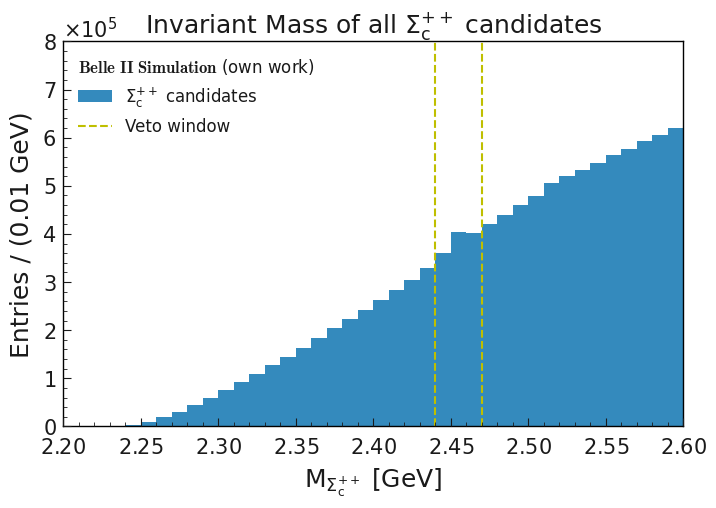

'\nplt.figure(figsize=(8,5))\nplt.hist(df_veto_pi[\'M\'], bins=50, range=(2.1, 2.6), label=r\'$\\Sigma_c^{++}$ candidates\')\n#plt.hist(df_veto_bkg[\'M\'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r\'fake $\\Sigma_c^{++}$\')\n#plt.hist(df_veto_sig[\'M\'], bins=50, range=(2.1, 2.6), color=\'green\', alpha=0.7, label=r\'true $\\Sigma_c^{++}$\')\n#plt.vlines(x=[2.43, 2.48], ymin=0, ymax=1000000, colors=[\'y\', \'y\'], linestyles=[\'--\', \'--\'], label=\'rejected area\')\nplt.vlines(x=veto_lim, ymin=0, ymax=1000000, colors=[\'y\', \'y\'], linestyles=[\'--\', \'--\'], label=\'Veto window\')\nplt.xlim(2.2, 2.6)\nplt.ylim(0, 800000)\nplt.xlabel(r\'$M_{\\Sigma_c^{++}}$ [GeV]\')\nplt.ylabel(\'Entries / (0.01 GeV)\')\nplt.title(r\'Invariant Mass of $\\Sigma_c^{++}$ candidates\')\n#plt.legend(loc="upper left")\nleg = ax.legend(title=r"$\x08f{Belle\\ II\\ Simulation}$ (own work)", title_fontproperties={\'size\': 12})\nleg._legend_box.align = "left"\n\nplt.savefig(f"graphs/Sigma_c++_BB_veto.png

In [41]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_veto_pi['M'], bins=50, range=(2.1, 2.6), label=r'$\Sigma_c^{++}$ candidates')
#ax.hist(df_veto_pi_fake['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
#ax.hist(df_veto_pi_real['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=veto_lim, ymin=0, ymax=1000000, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 800000)

plt.xlabel(r'$M_{\Sigma_c^{++}}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Sigma_c^{++}$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12}, loc= "upper left")
leg._legend_box.align = "left"
fig.savefig(f"graphs/Sigma_c++_BB_veto.png", bbox_inches="tight", dpi=300)
plt.show()
'''
plt.figure(figsize=(8,5))
plt.hist(df_veto_pi['M'], bins=50, range=(2.1, 2.6), label=r'$\Sigma_c^{++}$ candidates')
#plt.hist(df_veto_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r'fake $\Sigma_c^{++}$')
#plt.hist(df_veto_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label=r'true $\Sigma_c^{++}$')
#plt.vlines(x=[2.43, 2.48], ymin=0, ymax=1000000, colors=['y', 'y'], linestyles=['--', '--'], label='rejected area')
plt.vlines(x=veto_lim, ymin=0, ymax=1000000, colors=['y', 'y'], linestyles=['--', '--'], label='Veto window')
plt.xlim(2.2, 2.6)
plt.ylim(0, 800000)
plt.xlabel(r'$M_{\Sigma_c^{++}}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
plt.title(r'Invariant Mass of $\Sigma_c^{++}$ candidates')
#plt.legend(loc="upper left")
leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12})
leg._legend_box.align = "left"

plt.savefig(f"graphs/Sigma_c++_BB_veto.png", bbox_inches="tight")
plt.show()
'''

In [42]:
df_veto_pi_peak = df_veto_pi[(df_veto_pi['M']<2.46) & (df_veto_pi['M']>2.45)]
#df_pp_peak.describe()
df_veto_pi_peak['mcPDG'].value_counts()

Series([], Name: count, dtype: int64)

In [43]:
df_veto_mu = df_BB_veto[df_BB_veto["S_decayMode"]==102.0]

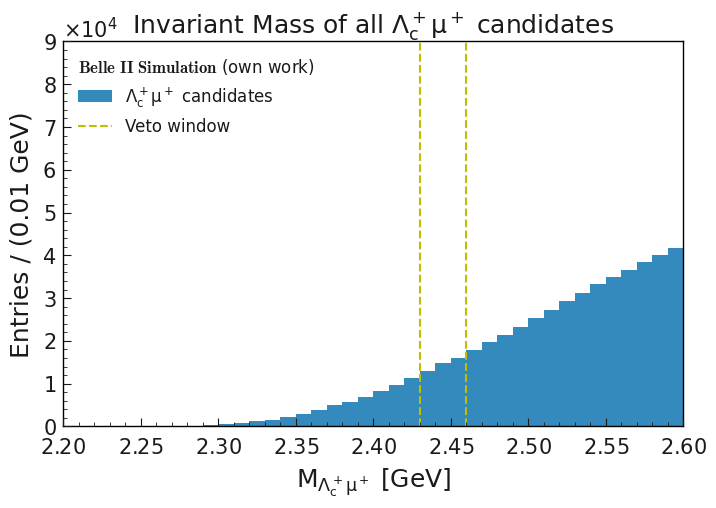

'\nplt.figure(figsize=(8,5))\nplt.hist(df_veto_mu[\'M\'], bins=50, range=(2.1, 2.6), label=\'$\\Lambda_c^+ \\mu^+$ candidates\')\n#plt.hist(df_veto_bkg[\'M\'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r\'fake $\\Sigma_c^{++}$\')\n#plt.hist(df_veto_sig[\'M\'], bins=50, range=(2.1, 2.6), color=\'green\', alpha=0.7, label=r\'true $\\Sigma_c^{++}$\')\nplt.vlines(x=veto_lim, ymin=0, ymax=100000, colors=[\'y\', \'y\'], linestyles=[\'--\', \'--\'], label=\'Veto window\')\nplt.xlim(2.2, 2.6)\nplt.ylim(0, 90000)\nplt.xlabel(r\'$M_{\\Lambda_c^+ \\mu^+}$ [GeV]\')\nplt.ylabel(\'Entries / (0.01 GeV)\')\nplt.title(r\'Invariant Mass of $\\Lambda_c^{+} \\mu^+$ candidates\')\nplt.legend(loc="upper left")\nplt.savefig(f"graphs/Lambda_c+mu+_BB_veto.png", bbox_inches="tight")\n\nplt.show()\n'

In [44]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_veto_mu['M'], bins=50, range=(2.1, 2.6), label=r'$\Lambda_c^+ \mu^+$ candidates')
#ax.hist(df_ppE_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
#ax.hist(df_ppE_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=[2.43, 2.46], ymin=0, ymax=100000, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 90000)

plt.xlabel(r'$M_{\Lambda_c^+ \mu^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Lambda_c^+ \mu^+$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12}, loc= "upper left")
leg._legend_box.align = "left"
fig.savefig(f"graphs/Lambda_c+mu+_BB_veto.png", bbox_inches="tight", dpi=300)
plt.show()
'''
plt.figure(figsize=(8,5))
plt.hist(df_veto_mu['M'], bins=50, range=(2.1, 2.6), label='$\Lambda_c^+ \mu^+$ candidates')
#plt.hist(df_veto_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r'fake $\Sigma_c^{++}$')
#plt.hist(df_veto_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label=r'true $\Sigma_c^{++}$')
plt.vlines(x=veto_lim, ymin=0, ymax=100000, colors=['y', 'y'], linestyles=['--', '--'], label='Veto window')
plt.xlim(2.2, 2.6)
plt.ylim(0, 90000)
plt.xlabel(r'$M_{\Lambda_c^+ \mu^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
plt.title(r'Invariant Mass of $\Lambda_c^{+} \mu^+$ candidates')
plt.legend(loc="upper left")
plt.savefig(f"graphs/Lambda_c+mu+_BB_veto.png", bbox_inches="tight")

plt.show()
'''

In [45]:
df_veto_e = df_BB_veto[df_BB_veto["S_decayMode"]==101.0]

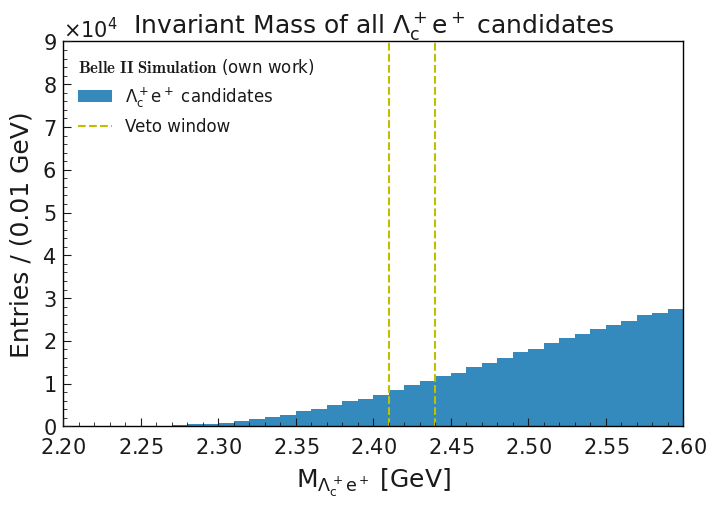

'\nplt.figure(figsize=(8,5))\nplt.hist(df_veto_e[\'M\'], bins=50, range=(2.1, 2.6), label=r\'$\\Lambda_c^+ e^+ candidates$\')\n#plt.hist(df_veto_bkg[\'M\'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r\'fake $\\Sigma_c^{++}$\')\n#plt.hist(df_veto_sig[\'M\'], bins=50, range=(2.1, 2.6), color=\'green\', alpha=0.7, label=r\'true $\\Sigma_c^{++}$\')\nplt.vlines(x=veto_lim, ymin=0, ymax=100000, colors=[\'y\', \'y\'], linestyles=[\'--\', \'--\'], label=\'Veto window\')\nplt.xlim(2.2, 2.6)\nplt.ylim(0, 90000)\nplt.xlabel(r\'$M_{\\Lambda_c^+ e^+}$ [GeV]\')\nplt.ylabel(\'Entries / (0.01 GeV)\')\nplt.title(r\'Invariant Mass of all $\\Lambda_c^{+} e^+$ candidates\')\nplt.legend(loc="upper left")\nplt.savefig(f"graphs/Lambda_c+e+_BB_veto.png", bbox_inches="tight")\n\nplt.show()\n'

In [46]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_veto_e['M'], bins=50, range=(2.1, 2.6), label=r'$\Lambda_c^+ e^+$ candidates')
#ax.hist(df_ppE_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
#ax.hist(df_ppE_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=[2.41, 2.44], ymin=0, ymax=100000, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 90000)

plt.xlabel(r'$M_{\Lambda_c^+ e^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Lambda_c^+ e^+$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12}, loc= "upper left")
leg._legend_box.align = "left"
fig.savefig(f"graphs/Lambda_c+e+_BB_veto.png", bbox_inches="tight", dpi=300)
plt.show()
'''
plt.figure(figsize=(8,5))
plt.hist(df_veto_e['M'], bins=50, range=(2.1, 2.6), label=r'$\Lambda_c^+ e^+ candidates$')
#plt.hist(df_veto_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r'fake $\Sigma_c^{++}$')
#plt.hist(df_veto_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label=r'true $\Sigma_c^{++}$')
plt.vlines(x=veto_lim, ymin=0, ymax=100000, colors=['y', 'y'], linestyles=['--', '--'], label='Veto window')
plt.xlim(2.2, 2.6)
plt.ylim(0, 90000)
plt.xlabel(r'$M_{\Lambda_c^+ e^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
plt.title(r'Invariant Mass of all $\Lambda_c^{+} e^+$ candidates')
plt.legend(loc="upper left")
plt.savefig(f"graphs/Lambda_c+e+_BB_veto.png", bbox_inches="tight")

plt.show()
'''

In [47]:
len(df_bkg)

512

In [48]:
veto_candidates = df_BB_veto[(df_BB_veto["M"] > veto_lim[0]) & (df_BB_veto["M"] < veto_lim[1])]
veto_events = veto_candidates["__event__"].unique()
df_bkg_veto = df_bkg[~df_bkg['__event__'].isin(veto_events)]

In [49]:
len(df_bkg_veto)

103

In [50]:
df_bkg_veto[["B_mcPDG", "B_Lambda_c_mcPDG", "B_Lambda_c_p_mcPDG", "iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrCcP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_1"]].head(10)

,B_mcPDG,B_Lambda_c_mcPDG,B_Lambda_c_p_mcPDG,iDcyBrP_Bp_0,iDcyBrCcP_Bp_0,iDcyBrP_B0_0,iDcyBrCcP_B0_0,iDcyBrP_B0_1,iDcyBrCcP_B0_1
4,-511.0,-511.0,2212.0,-1,-1,8,9,-1,-1
11,300553.0,300553.0,-2212.0,-1,-1,9,18,-1,-1
12,511.0,511.0,-2212.0,-1,-1,9,13,-1,-1
13,300553.0,511.0,-2212.0,-1,-1,10,19,-1,-1
16,300553.0,300553.0,2212.0,-1,-1,24,9,-1,-1
23,300553.0,300553.0,-2212.0,6,7,-1,-1,-1,-1
24,-521.0,-521.0,2212.0,8,9,-1,-1,-1,-1
27,-521.0,4122.0,2212.0,13,14,-1,-1,-1,-1
29,300553.0,521.0,-2212.0,17,2,-1,-1,-1,-1
30,-521.0,-521.0,2212.0,18,19,-1,-1,-1,-1


## udsctau

In [51]:
#with uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_had2_topoana.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/continuum/udsctau_all_had_veto.root:hadronic") as file:


#with uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_skim_had_topoana.root:hadronic") as file:
#with uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_proc5_veto_topoana.root:hadronic") as file:
#with uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_proc5_veto_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_proc7_veto_topoana.root:hadronic") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_continuum = file.arrays(vars_to_read, library="pd")

    for var in vars_wanted:
        if var not in df_continuum.columns:
            df_continuum[var] = np.nan
df_continuum["__weight__"] = mc_weight

In [52]:
df_continuum.head(10)

,__experiment__,__run__,__event__,__production__,__candidate__,__ncandidates__,__weight__,dM,B_mu_electronID,B_mu_muonID,...,Btag_R2,Btag_thrustBm,Btag_thrustOm,cosTBTO,R2,Btag_extraInfo_SignalProbability,mcPDG,M,B_foxWolframR2,S_decayMode
0,14,1751,84145,47202,0,1,0.255383,-1.019641,9.189363e-25,0.998498,...,0.346167,0.898392,0.692439,0.835698,0.345575,0.116282,NaN,NaN,NaN,NaN
1,14,2021,150139,47202,0,1,0.255383,-1.402664,1.391055e-02,0.983289,...,0.210890,0.930113,0.661262,0.212255,0.211478,0.001540,NaN,NaN,NaN,NaN
2,14,922,158277,47202,0,1,0.255383,-1.195591,8.125158e-13,0.999097,...,0.350329,0.911623,0.795219,0.985625,0.350644,0.001216,23.0,NaN,NaN,NaN
3,14,1971,630943,47202,0,1,0.255383,-0.653489,1.137097e-19,0.999998,...,0.200012,0.913426,0.734095,0.466127,0.198160,0.004295,NaN,NaN,NaN,NaN
4,14,1960,175173,47202,0,1,0.255383,-1.224121,1.407368e-19,0.999961,...,0.270225,0.859257,0.720322,0.948185,0.263514,0.067829,23.0,NaN,NaN,NaN
5,14,1762,335898,47202,0,1,0.255383,-1.038092,9.999958e-01,0.000004,...,0.106380,0.735304,0.771994,0.834900,0.105236,0.003422,NaN,NaN,NaN,NaN
6,14,2047,190789,47202,0,1,0.255383,-0.679478,3.846617e-11,0.999929,...,0.144822,0.717377,0.723890,0.464307,0.144957,0.004586,23.0,NaN,NaN,NaN
7,14,980,1039990,47202,0,1,0.255383,-1.123092,2.627698e-07,0.998587,...,0.174703,0.946975,0.811482,0.267397,0.174262,0.122528,23.0,NaN,NaN,NaN
8,14,2132,337495,47202,0,1,0.255383,-0.500893,5.493896e-33,0.999976,...,0.314837,0.856734,0.797319,0.832133,0.315441,0.002716,23.0,NaN,NaN,NaN
9,22,535,207678,47535,0,1,0.255383,-1.184526,9.999971e-01,0.000003,...,0.335249,0.915738,0.759837,0.815521,0.334635,0.013436,NaN,NaN,NaN,NaN


In [53]:
[col for col in uproot.open("topoana/results/hadronic/udsctau/Lcplnu_udsctau_had2_topoana.root:hadronic").keys() if "decay" in col]
#[col for col in uproot.open("/data/dust/user/timmue/project/continuum/udsctau_had_skim_veto.root:hadronic").keys() if "cos" in col]

['extraInfo__bodecayModeID__bc',
 'B_extraInfo_decayModeID',
 'B_Lambda_c_extraInfo_decayModeID',
 'Btag_extraInfo_decayModeID']

In [54]:
len(df_continuum)

642

In [55]:
len(df_continuum[df_continuum["isContinuumEvent"]==0])

0

In [56]:
df_continuum["template"] = "continuum"

### Apply veto

In [57]:
with uproot.open("/data/dust/user/timmue/project/continuum/B_Lcplnu_udsctau_proc_had_v7_2/udsctau_had_veto.root:veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_udsctau_veto = file.arrays(vars_to_read, library="pd")

df_udsctau_veto["template"] = "continuum"
df_udsctau_veto["__weight__"] = mc_weight

In [58]:
len(df_udsctau_veto)

8711158

In [59]:
df_udsctau_veto.head(10)

,__experiment__,__run__,__event__,__production__,__candidate__,__ncandidates__,__weight__,M,dM,S_decayMode,mcPDG,template
0,14,1832,1362790,47202,0,1,0.255383,2.348296,-0.105674,103.0,NaN,continuum
1,14,1832,1363138,47202,0,1,0.255383,2.350964,-0.103006,103.0,NaN,continuum
2,14,1832,1365550,47202,0,1,0.255383,2.512246,0.058276,103.0,NaN,continuum
3,14,1832,1366622,47202,0,1,0.255383,2.567520,0.113550,103.0,NaN,continuum
4,14,1832,1367039,47202,0,1,0.255383,2.564077,0.110107,103.0,NaN,continuum
5,14,1832,1375469,47202,0,1,0.255383,2.559054,0.105084,103.0,NaN,continuum
6,14,1987,1240245,47202,0,2,0.255383,2.418871,-0.035099,103.0,NaN,continuum
7,14,1987,1240245,47202,1,2,0.255383,2.392633,-0.061337,103.0,NaN,continuum
8,14,1987,1240651,47202,0,2,0.255383,2.516915,0.062945,103.0,NaN,continuum
9,14,1987,1240651,47202,1,2,0.255383,2.516915,0.062945,103.0,NaN,continuum


In [60]:
df_veto_pi = df_udsctau_veto[df_udsctau_veto["S_decayMode"]==103.0]

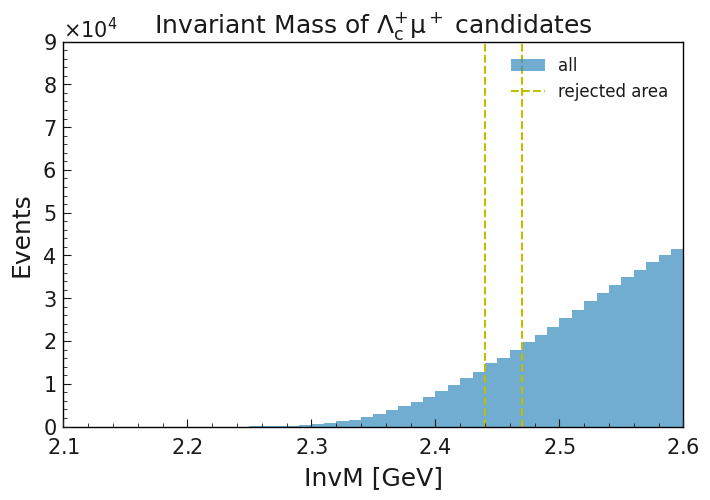

In [61]:
plt.figure(figsize=(8,5))
plt.hist(df_veto_mu['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label='all')
#plt.hist(df_veto_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label=r'fake $\Sigma_c^{++}$')
#plt.hist(df_veto_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label=r'true $\Sigma_c^{++}$')
plt.vlines(x=veto_lim, ymin=0, ymax=100000, colors=['y', 'y'], linestyles=['--', '--'], label='rejected area')
plt.xlim(2.1, 2.6)
plt.ylim(0, 90000)
plt.xlabel('InvM [GeV]')
plt.ylabel('Events')
plt.title(r'Invariant Mass of $\Lambda_c^{+} \mu^+$ candidates')
plt.legend()


plt.show()

In [62]:
len(df_continuum)

642

In [63]:
veto_candidates = df_udsctau_veto[(df_udsctau_veto["M"] > veto_lim[0]) & (df_udsctau_veto["M"] < veto_lim[1])]
veto_events = veto_candidates["__event__"].unique()
df_continuum_veto = df_continuum[~df_continuum['__event__'].isin(veto_events)]

In [64]:
len(df_continuum_veto)

300

## signMC

In [65]:
vars_wanted = vars_wanted + ['iDcyBrP_Bp_0', 'iDcyBrCcP_Bp_0', 'B_mcPDG','B_Lambda_c_mcPDG', 'B_Lambda_c_p_mcPDG']

In [66]:
#with uproot.open("topoana/results/hadronic/signMC/Lcplnu_signMC_had_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/signMC/Lcplnu_signMC_veto5_topoana.root:hadronic") as file:
    #df_signMC = file.arrays(variables, library="pd")
    
    available_branches = file.keys()
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_signMC = file.arrays(vars_to_read, library="pd")

    for var in vars_wanted:
        if var not in df_signMC.columns:
            df_signMC[var] = np.nan

df_signMC["__weight__"] = signal_mc_weight

In [67]:
len(df_signMC)

8815

In [68]:
df_signMC[(df_signMC["B_isSignalAcceptMissingNeutrino"]==0)][["B_mcPDG", "m2RecoilSignalSide","B_isSignalAcceptMissingNeutrino", "B_isSignalAcceptMissing", 'isSignalAcceptMissingNeutrino', "B_Lambda_c_isSignal", 
             'B_Lambda_c_isSignalAcceptMissingMassive',
             'B_Lambda_c_isSignalAcceptMissingNeutrino']].head(10)

,B_mcPDG,m2RecoilSignalSide,B_isSignalAcceptMissingNeutrino,B_isSignalAcceptMissing,isSignalAcceptMissingNeutrino,B_Lambda_c_isSignal,B_Lambda_c_isSignalAcceptMissingMassive,B_Lambda_c_isSignalAcceptMissingNeutrino
20,-521.0,0.118099,0.0,1.0,0.0,0.0,0.0,0.0
23,-521.0,0.002529,0.0,0.0,NaN,0.0,0.0,0.0
39,300553.0,0.167007,0.0,0.0,NaN,0.0,0.0,0.0
45,521.0,0.474004,0.0,1.0,0.0,0.0,0.0,0.0
47,-521.0,0.078599,0.0,0.0,0.0,0.0,0.0,0.0
54,-521.0,0.177455,0.0,1.0,0.0,0.0,0.0,0.0
63,300553.0,0.589397,0.0,0.0,0.0,0.0,0.0,0.0
65,300553.0,-0.012263,0.0,0.0,0.0,0.0,0.0,0.0
74,300553.0,-0.863976,0.0,0.0,0.0,0.0,0.0,0.0
75,521.0,0.075630,0.0,1.0,0.0,0.0,0.0,0.0


In [69]:
len(df_signMC[df_signMC["B_isSignalAcceptMissingNeutrino"]==0])

1030

In [70]:
df_signMC["template"] = "signMC"

### Apply veto

In [71]:
with uproot.open("/data/dust/user/timmue/project/signMC/signMC_had_veto_v5.root:veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_signal_veto = file.arrays(vars_to_read, library="pd")

df_signal_veto["template"] = "signMC"
df_signal_veto["__weight__"] = signal_mc_weight

In [72]:
len(df_signal_veto)

1012545

In [73]:
veto_candidates = df_signal_veto[(df_signal_veto["M"] > veto_lim[0]) & (df_signal_veto["M"] < veto_lim[1])]
veto_events = veto_candidates["__event__"].unique()
df_signMC_veto = df_signMC[~df_signMC['__event__'].isin(veto_events)]

In [74]:
len(df_signMC_veto)

1658

## Test

In [75]:
#with uproot.open("output_had_test6.root:hadronic") as file:
#with uproot.open("data/B_Lcplnu_BB_skim_had_v2/sub00/output_had_00230_job502658464_00.root:hadronic") as file:

#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_all5_veto_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_proc7_veto_topoana.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/background/BB_all_had_veto_v5.root:veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    #print(available_branches)
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_test = file.arrays(vars_to_read, library="pd")
    #print(file.num_entries)

    for var in vars_wanted:
        if var not in df_test.columns:
            df_test[var] = np.nan

In [76]:
#with uproot.open("output_had_test6.root:hadronic") as file:
#with uproot.open("data/B_Lcplnu_BB_skim_had_v2/sub00/output_had_00230_job502658464_00.root:hadronic") as file:

#with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_had5_topoana.root:hadronic") as file:
with uproot.open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_prompt_had_v2/BB_had_veto.root:hadronic") as file:
    available_branches = file.keys()
    #print(available_branches)
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_test_veto = file.arrays(vars_to_read, library="pd")
    #print(file.num_entries)

    for var in vars_wanted:
        if var not in df_test_veto.columns:
            df_test_veto[var] = np.nan

In [77]:
df_test.head(20) #[df_test['__event__']==102206]#.head(20)

,__experiment__,__run__,__event__,__production__,__candidate__,__ncandidates__,__weight__,dM,B_mu_electronID,B_mu_muonID,...,Btag_extraInfo_SignalProbability,mcPDG,iDcyBrP_Bp_0,iDcyBrCcP_Bp_0,B_mcPDG,B_Lambda_c_mcPDG,B_Lambda_c_p_mcPDG,M,B_foxWolframR2,S_decayMode
0,24,1238,45265,47737,0,1,1.0,-0.794209,1.000000e+00,7.704256e-26,...,0.001068,NaN,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN
1,24,2162,272315,47737,0,1,1.0,-1.244704,6.319180e-16,9.931573e-01,...,0.001591,NaN,-1,-1,300553.0,300553.0,2212.0,NaN,NaN,NaN
2,24,1566,8333,47737,0,1,1.0,-1.422988,1.427300e-07,9.875836e-01,...,0.001704,NaN,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN
3,24,1191,275078,47737,0,1,1.0,-1.403145,3.351437e-02,9.664583e-01,...,0.005842,300553.0,-1,-1,300553.0,-4122.0,-2212.0,NaN,NaN,NaN
4,24,2217,431550,47737,0,1,1.0,-0.915081,4.590047e-13,9.999214e-01,...,0.012483,300553.0,-1,-1,-511.0,-511.0,2212.0,NaN,NaN,NaN
5,24,2259,88908,47737,0,1,1.0,-0.645016,4.291404e-11,9.679107e-01,...,0.003359,300553.0,-1,-1,-511.0,4122.0,2212.0,NaN,NaN,NaN
6,24,890,213537,47737,0,1,1.0,-0.562228,4.908687e-24,1.000000e+00,...,0.007924,NaN,-1,-1,300553.0,511.0,-2212.0,NaN,NaN,NaN
7,24,1857,199288,47737,0,1,1.0,-1.444808,1.000000e+00,2.115444e-13,...,0.002055,300553.0,-1,-1,300553.0,-511.0,2212.0,NaN,NaN,NaN
8,24,1603,25507,47737,0,1,1.0,-1.187613,7.822392e-11,9.466876e-01,...,0.003165,300553.0,-1,-1,300553.0,511.0,-2212.0,NaN,NaN,NaN
9,24,2131,34729,47737,0,1,1.0,-1.169095,4.051404e-18,9.999713e-01,...,0.013392,300553.0,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN


In [78]:
df_test_veto.head(20) #[df_test['__event__']==102206]#.head(20)

,__experiment__,__run__,__event__,__production__,__candidate__,__ncandidates__,__weight__,dM,B_mu_electronID,B_mu_muonID,...,B_Lambda_c_mcPDG,B_Lambda_c_p_mcPDG,M,B_foxWolframR2,Btag_R2,Btag_thrustBm,Btag_thrustOm,cosTBTO,R2,S_decayMode
0,24,1238,45265,47737,0,1,1.0,-0.794209,1.000000e+00,7.704256e-26,...,511.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,24,1738,206870,47737,0,1,1.0,-1.393511,1.206947e-06,9.999940e-01,...,-4122.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,24,2162,272315,47737,0,1,1.0,-1.244704,6.319180e-16,9.931573e-01,...,300553.0,2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,24,1566,8333,47737,0,1,1.0,-1.422988,1.427300e-07,9.875836e-01,...,511.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,24,1191,275078,47737,0,1,1.0,-1.403145,3.351437e-02,9.664583e-01,...,-4122.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,24,2217,431550,47737,0,1,1.0,-0.915081,4.590047e-13,9.999214e-01,...,-511.0,2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,24,890,213537,47737,0,1,1.0,-0.562228,4.908687e-24,1.000000e+00,...,511.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,24,1857,199288,47737,0,1,1.0,-1.444808,1.000000e+00,2.115444e-13,...,-511.0,2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,24,1603,25507,47737,0,1,1.0,-1.187613,7.822392e-11,9.466876e-01,...,511.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,24,2131,34729,47737,0,1,1.0,-1.169095,4.051404e-18,9.999713e-01,...,511.0,-2212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [79]:
len(df_test)

512

In [80]:
len(df_test_veto)

582

In [81]:
BB_events = df_test['__event__']

In [82]:
veto_events = df_test_veto['__event__']

In [83]:
common = df_test_veto.merge(df_test, on=["__event__"])

In [84]:
common.head(20)

,__experiment___x,__run___x,__event__,__production___x,__candidate___x,__ncandidates___x,__weight___x,dM_x,B_mu_electronID_x,B_mu_muonID_x,...,Btag_extraInfo_SignalProbability_y,mcPDG_y,iDcyBrP_Bp_0_y,iDcyBrCcP_Bp_0_y,B_mcPDG_y,B_Lambda_c_mcPDG_y,B_Lambda_c_p_mcPDG_y,M_y,B_foxWolframR2_y,S_decayMode_y
0,24,1238,45265,47737,0,1,1.0,-0.794209,1.000000e+00,7.704256e-26,...,0.001068,NaN,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN
1,24,2162,272315,47737,0,1,1.0,-1.244704,6.319180e-16,9.931573e-01,...,0.001591,NaN,-1,-1,300553.0,300553.0,2212.0,NaN,NaN,NaN
2,24,1566,8333,47737,0,1,1.0,-1.422988,1.427300e-07,9.875836e-01,...,0.001704,NaN,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN
3,24,1191,275078,47737,0,1,1.0,-1.403145,3.351437e-02,9.664583e-01,...,0.005842,300553.0,-1,-1,300553.0,-4122.0,-2212.0,NaN,NaN,NaN
4,24,2217,431550,47737,0,1,1.0,-0.915081,4.590047e-13,9.999214e-01,...,0.012483,300553.0,-1,-1,-511.0,-511.0,2212.0,NaN,NaN,NaN
5,24,890,213537,47737,0,1,1.0,-0.562228,4.908687e-24,1.000000e+00,...,0.007924,NaN,-1,-1,300553.0,511.0,-2212.0,NaN,NaN,NaN
6,24,1857,199288,47737,0,1,1.0,-1.444808,1.000000e+00,2.115444e-13,...,0.002055,300553.0,-1,-1,300553.0,-511.0,2212.0,NaN,NaN,NaN
7,24,1603,25507,47737,0,1,1.0,-1.187613,7.822392e-11,9.466876e-01,...,0.003165,300553.0,-1,-1,300553.0,511.0,-2212.0,NaN,NaN,NaN
8,24,2131,34729,47737,0,1,1.0,-1.169095,4.051404e-18,9.999713e-01,...,0.013392,300553.0,-1,-1,511.0,511.0,-2212.0,NaN,NaN,NaN
9,24,1581,112603,47737,0,1,1.0,-1.023313,2.698813e-11,9.956843e-01,...,0.001760,300553.0,-1,-1,-511.0,-511.0,2212.0,NaN,NaN,NaN


In [85]:
len(common)

388

## Define Dataframes

In [86]:
#with uproot.open("data/had_udsctau_skim.root:hadronic") as file:
#    df_cont = file.arrays(variables, library="pd")

In [87]:
#len(df_cont)

In [88]:
#df = pd.concat([
#    charged,
#    mixed,
#    signal,
#])

df = pd.concat([
    df_bkg, 
    #df_bkg_veto, 
    df_continuum,
    #df_continuum_veto,
    df_signMC
    #df_signMC_veto
])

df_background_veto = df_bkg_veto
df_background = df_bkg

df_signalMC = df_signMC
df_signalMC_veto = df_signMC_veto

df_withtag = skim

'''
df = df_withtag[
    ((df_withtag['B_mcPDG'] == 521.0) & (df_withtag["iDcyBrP_Bp_0"] > -1)
    ) | ((df_withtag['B_mcPDG'] == -521.0) & (df_withtag["iDcyBrCcP_Bp_0"] > -1))]

df = df_withtag[
    ((df_withtag['B_mcPDG'] == 521.0) & (df_withtag["iDcyBrP_Bp_0"] > -1)
    ) | ((df_withtag['B_mcPDG'] == -521.0) & (df_withtag["iDcyBrCcP_Bp_0"] > -1)
    ) | (
        (df_withtag['B_mcPDG'] == 511.0) & (df_withtag["iDcyBrP_B0_0"] > -1)
    ) | ((df_withtag['B_mcPDG'] == 511.0) & (df_withtag["iDcyBrP_B0_1"] > -1)
    ) | ((df_withtag['B_mcPDG'] == -511.0) & (df_withtag["iDcyBrCcP_B0_0"] > -1)
    ) | ((df_withtag['B_mcPDG'] == -511.0) & (df_withtag["iDcyBrCcP_B0_1"] > -1))
    ]
'''
ID=27

#[(df_withtag["iDcyBrCcP_Bp_0"]==ID)]
                
#print(df)
#display(df)
#df_signMC[(df_signMC["m2RecoilSignalSide"]<0)][["iDcyBrP_Bp_0","iDcyBrCcP_Bp_0","B_mcPDG", "B_Lambda_c_mcPDG", "B_Lambda_c_p_mcPDG", "m2RecoilSignalSide","B_isSignalAcceptMissingNeutrino","isContinuumEvent",]]
#df_withtag[((df_withtag["B_mcPDG"]<0) & (df_withtag["B_Lambda_c_p_mcPDG"]<0)) | ((df_withtag["B_mcPDG"]>0) & (df_withtag["B_Lambda_c_p_mcPDG"]>0))][["B_Lambda_c_p_mcPDG","B_mcPDG", "B_Lambda_c_mcPDG","iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrCcP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_1", "B_Lambda_c_InvM"]]
#df[((df["iDcyBrP_Bp_0"]==ID) & (df["B_mcPDG"]==521.0)) | ((df["iDcyBrCcP_Bp_0"]==ID) & (df["B_mcPDG"]==-521.0))][["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_0", "iDcyBrCcP_B0_1", "B_mcPDG", "B_Lambda_c_mcMother_PDG"]]
#df[(df["iDcyBrP_B0_0"]==ID) | (df["iDcyBrP_B0_1"]==ID) | (df["iDcyBrCcP_B0_0"]==ID) | (df["iDcyBrCcP_B0_1"]==ID)][["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_0", "iDcyBrCcP_B0_1", "B_mcPDG", "B_Lambda_c_mcMother_PDG"]]
#df_withtag[["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "B_mcPDG"]]
#df_withtag[(df_withtag["iDcyBrP_Bp_0"]==ID) | (df_withtag["iDcyBrCcP_Bp_0"]==ID)][["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrCcP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_1",  "B_mcPDG", "B_Lambda_c_mcPDG"]]
#df[(df["B_mcPDG"]==521) & (df["iDcyBrP_Bp_0"]==ID)][["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "B_mcPDG", "B_isSignalAcceptMissing","B_Lambda_c_mcMother_PDG"]]
#df[["iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "B_mcPDG", "B_Lambda_c_InvM"]]

### Fine tune cuts

In [89]:
df["channel"]= np.where(df["B_extraInfo_decayModeID"]==1, "B_to_Lambda_c_plnu_e", "B_to_Lambda_c_plnu_mu")
#df["template"]= "background"
#df.loc[df["B_isSignalAcceptMissingNeutrino"]==1, "template"] = "signMC"
#df.loc[df["isContinuumEvent"]==1, "template"] = "continuum"
df["total_weight"] = df["__weight__"]
df = df.copy()

/tmp/ipykernel_1463035/582182208.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["channel"]= np.where(df["B_extraInfo_decayModeID"]==1, "B_to_Lambda_c_plnu_e", "B_to_Lambda_c_plnu_mu")
/tmp/ipykernel_1463035/582182208.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["total_weight"] = df["__weight__"]


In [90]:
#df[["channel", "template", "B_extraInfo_decayModeID", "B_isSignalAcceptMissingNeutrino", "isContinuumEvent", "total_weight", "__weight__"]].tail(10)

In [91]:
len(df)

9969

In [92]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [93]:
df.groupby("B_isSignalAcceptMissing").B_nMCDaughters.value_counts()

B_isSignalAcceptMissing  B_nMCDaughters
0.0                      3.0               202
                         2.0               177
                         4.0                74
                         5.0                28
                         6.0                 5
1.0                      3.0                12
                         4.0                 2
Name: count, dtype: int64

In [94]:
df.query("B_extraInfo_decayModeID == 1").groupby("B_mu_isSignal")[["B_mu_mcPDG"]].value_counts()

B_mu_isSignal  B_mu_mcPDG
0.0            -211.0        41
                211.0        26
               -321.0         5
                321.0         3
1.0             11.0         25
               -11.0         22
Name: count, dtype: int64

In [95]:
#df_withtag.groupby("iDcyBrP_Bp_0")[["B_mcPDG"]].value_counts()

* 2224: Delta++
* 4214: Sigma_c*+
* 4212: Sigma_c+  --> Lambda_c+ pi0
* 4222: Sigma_c++ --> Lambda_c+ pi+
* 4224: Sigma_c*++
* 4114: Sigma_c*0
* 4312: Xi'_c0
* 4114: Sigma_c*0

In [96]:
#df.query("B_isSignalAcceptMissing != 1").B_nMCDaughters.apply(abs).value_counts()

In [97]:
data = pd.concat([
    data.arrays(variables, library="pd"),
])

In [98]:
data = df

In [99]:
#len(signal) / 100000 * 100

In [100]:
def get_nCandidates(df):
    return df.groupby(['__experiment__', '__run__', '__event__', '__production__']).size().value_counts().sort_index()

In [101]:
N_SIGNAL = len(df.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND = len(df.query("B_isSignalAcceptMissingNeutrino != 1"))

In [102]:
def apply_cut(df, query, n_signal_before=None, n_background_before=None, isData=False):
    if isData:
        df = df.query(query)    
        return df

    print()
    print("Selection: ", query)
    if n_signal_before is None:
        n_signal_before = len(df.query("B_isSignalAcceptMissingNeutrino == 1"))
    if n_background_before is None:
        n_background_before = len(df.query("B_isSignalAcceptMissingNeutrino != 1"))
    
    df = df.query(query)
    n_signal_after = len(df.query("B_isSignalAcceptMissingNeutrino == 1"))
    n_background_after = len(df.query("B_isSignalAcceptMissingNeutrino != 1"))

    if n_signal_before !=0:
        print(f"Signal efficiency: {n_signal_after / n_signal_before:.4f}")#100.*
    else:
        print("-- No Signal events! --")
    print(f"Background efficiency: {n_background_after / n_background_before:.4f}")#100.*
    print()
    return df

In [103]:
# & (df_background["B_Lambda_c_p_mcPDG"]<0)) | ((df_background["B_mcPDG"]>0) & (df_background["B_Lambda_c_p_mcPDG"]>0)
#df_background[(df_background["B_mcPDG"]!=df_background["B_Lambda_c_mcPDG"])][["B_Lambda_c_p_mcPDG","B_mcPDG", "B_Lambda_c_mcPDG","iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrCcP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_1", "B_Lambda_c_InvM"]]
#df_signMC[(df_signMC["B_mcPDG"]<0) & (df_signMC["B_Lambda_c_p_mcPDG"]<0)][["B_Lambda_c_p_mcPDG","B_mcPDG", "B_Lambda_c_mcPDG","iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "B_Lambda_c_InvM"]]

In [104]:
'''
N=10
print("Top Zerfälle (B_extraInfo_decayModeID):")
print(df["B_extraInfo_decayModeID"].value_counts().head(N))

print(df.columns)
'''
print(df.B_isSignalAcceptMissingNeutrino.value_counts())
#df = apply_cut(df, "nROE_Charged__bo__bc <= 1", N_SIGNAL, N_BACKGROUND)
#df = apply_cut(df, "-1.2 < B_cosThetaBetweenParticleAndNominalB < 1.2", N_SIGNAL, N_BACKGROUND)


df = apply_cut(df, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL, N_BACKGROUND)
df_background = apply_cut(df_background, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL, N_BACKGROUND)
df_signalMC = apply_cut(df_signalMC, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL, N_BACKGROUND)

#df = apply_cut(df, "B_mu_p > 0.6", N_SIGNAL, N_BACKGROUND)

#df = apply_cut(df, "iDcyBrP_Bp_0 != 47 and iDcyBrP_Bp_0 != 10 and iDcyBrP_Bp_0 != 13 and iDcyBrP_Bp_0 != 24 and iDcyBrP_Bp_0 != 19 and iDcyBrP_Bp_0 != 27 and iDcyBrP_Bp_0 != 20 and iDcyBrP_Bp_0 != 63 and iDcyBrP_Bp_0 != 56 and iDcyBrP_Bp_0 != 36", N_SIGNAL, N_BACKGROUND)

print(df.B_isSignalAcceptMissingNeutrino.value_counts())

#df = apply_cut(df, "B_mcPDG == 521", N_SIGNAL, N_BACKGROUND)

#print(df.B_isSignalAcceptMissing.value_counts())

#data = apply_cut(data, "nROE_Charged__bo__bc <= 1", isData=True)
#data = apply_cut(data, "-1.2 < B_cosThetaBetweenParticleAndNominalB < 1.2", isData=True)


data = apply_cut(data, "2.28 < B_Lambda_c_InvM < 2.295", isData=True)     


#data = apply_cut(data, "B_mu_p > 0.6", isData=True)

#data = apply_cut(data, "iDcyBrP != 47", isData=True)

B_isSignalAcceptMissingNeutrino
1.0    7738
0.0    2157
Name: count, dtype: int64

Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.9161
Background efficiency: 0.1228


Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.0000
Background efficiency: 0.0565


Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.9161
Background efficiency: 0.0560

B_isSignalAcceptMissingNeutrino
1.0    7089
0.0     256
Name: count, dtype: int64


In [105]:
len(df_signMC[df_signMC["B_extraInfo_decayModeID"]==2.0])

4095

In [106]:
df[["B_mu_muonID","B_mu_electronID","B_extraInfo_decayModeID", "Btag_extraInfo_decayModeID","B_mcPDG", "B_Lambda_c_mcPDG","B_Lambda_c_p_mcPDG","iDcyBrP_Bp_0", "iDcyBrCcP_Bp_0", "iDcyBrP_B0_0", "iDcyBrCcP_B0_0", "iDcyBrP_B0_1", "iDcyBrCcP_B0_1", "isContinuumEvent"]].head(50)

,B_mu_muonID,B_mu_electronID,B_extraInfo_decayModeID,Btag_extraInfo_decayModeID,B_mcPDG,B_Lambda_c_mcPDG,B_Lambda_c_p_mcPDG,iDcyBrP_Bp_0,iDcyBrCcP_Bp_0,iDcyBrP_B0_0,iDcyBrCcP_B0_0,iDcyBrP_B0_1,iDcyBrCcP_B0_1,isContinuumEvent
3,9.664583e-01,3.351437e-02,2.0,2.0,300553.0,-4122.0,-2212.0,-1.0,-1.0,6.0,7.0,-1.0,-1.0,False
5,9.679107e-01,4.291404e-11,2.0,31.0,-511.0,4122.0,2212.0,-1.0,-1.0,10.0,11.0,-1.0,-1.0,False
14,9.999954e-01,9.641328e-08,2.0,30.0,511.0,-4122.0,-2212.0,-1.0,-1.0,20.0,21.0,-1.0,-1.0,False
21,9.026143e-01,1.126874e-09,2.0,14.0,-521.0,4122.0,2212.0,2.0,3.0,-1.0,-1.0,-1.0,-1.0,False
26,9.997255e-01,6.200954e-08,2.0,17.0,-521.0,4122.0,2212.0,11.0,12.0,-1.0,-1.0,-1.0,-1.0,False
27,9.864569e-01,4.893807e-04,2.0,12.0,-521.0,4122.0,2212.0,13.0,14.0,-1.0,-1.0,-1.0,-1.0,False
32,9.850274e-01,1.913624e-16,2.0,3.0,300553.0,300553.0,2212.0,19.0,22.0,-1.0,-1.0,-1.0,-1.0,False
33,1.000000e+00,1.389967e-31,2.0,31.0,521.0,-4122.0,-2212.0,12.0,0.0,-1.0,-1.0,-1.0,-1.0,False
51,1.000000e+00,6.630199e-47,2.0,18.0,NaN,-4122.0,-2212.0,46.0,11.0,-1.0,-1.0,-1.0,-1.0,False
58,9.619549e-01,8.431658e-13,2.0,4.0,521.0,-4122.0,-2212.0,52.0,53.0,-1.0,-1.0,-1.0,-1.0,False


### e/mu splitting

In [107]:
df_mu = df[df["B_extraInfo_decayModeID"] == 2].copy()
df_e = df[df["B_extraInfo_decayModeID"] == 1].copy()


df_background_mu = df_background[df_background["B_extraInfo_decayModeID"] == 2].copy()
df_background_e = df_background[df_background["B_extraInfo_decayModeID"] == 1].copy()

df_background_veto_mu = df_background_veto[df_background_veto["B_extraInfo_decayModeID"] == 2].copy()
df_background_veto_e = df_background_veto[df_background_veto["B_extraInfo_decayModeID"] == 1].copy()

In [108]:
len(df_mu)

3492

In [109]:
len(df_e)

3871

In [110]:
len(df_e) + len(df_mu)

7363

In [111]:
len(df)

7363

In [112]:
df_diff = pd.concat([df, df_mu, df_e], ignore_index=True).drop_duplicates(keep=False)
len(df_diff)

0

In [113]:
#df[df['B_extraInfo_decayModeID']==1][["template",'B_mu_electronID', "B_mu_muonID", "B_mu_p","isContinuumEvent","B_isSignalAcceptMissingNeutrino","B_mcPDG"]]

In [114]:
data_e = data[data["B_extraInfo_decayModeID"] == 1]
data_mu = data[data["B_extraInfo_decayModeID"] == 2]

In [115]:
dfs = {"total": df,
      "e": df_e,
      "mu": df_mu,
}

datas = dfs

In [116]:
#df[["channel", "template","total_weight", "__weight__", "B_extraInfo_decayModeID", "B_isSignalAcceptMissingNeutrino", "isContinuumEvent", "total_weight", "__weight__"]].tail(10)

## Cutflow Tables

In [117]:
with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_hadcut_1/BB_hadcut_veto.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/background/BB_all_had_veto_v5.root:veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    #print(available_branches)
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_BB_cut = file.arrays(vars_to_read, library="pd")
    #print(file.num_entries)

    for var in vars_wanted:
        if var not in df_test.columns:
            df_test[var] = np.nan
            
df_BB_cut["__weight__"] = mc_weight

In [118]:
with uproot.open("/data/dust/user/timmue/project/continuum/B_Lcplnu_udsctau_proc_hadcut_4/udsctau_hadcut_veto.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/background/BB_all_had_veto_v5.root:veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    #print(available_branches)
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_udsctau_cut = file.arrays(vars_to_read, library="pd")
    #print(file.num_entries)

    for var in vars_wanted:
        if var not in df_test.columns:
            df_test[var] = np.nan

df_udsctau_cut["__weight__"] = mc_weight

In [119]:
with uproot.open("/data/dust/user/timmue/project/signMC/signMC_hadcut_veto_4/signMC_all_hadcut_veto_4.root:hadronic") as file:
#with uproot.open("/data/dust/user/timmue/project/background/BB_all_had_veto_v5.root:veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_proc_had_v7/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    #print(available_branches)
    vars_to_read = [v for v in vars_wanted if v in available_branches]
    df_signMC_cut = file.arrays(vars_to_read, library="pd")
    #print(file.num_entries)

    for var in vars_wanted:
        if var not in df_test.columns:
            df_test[var] = np.nan

df_signMC_cut["__weight__"] = signal_mc_weight

In [120]:
df_cut = pd.concat([df_BB_cut, df_udsctau_cut, df_signMC_cut])

In [121]:
df_cut_e = df_cut[df_cut["B_extraInfo_decayModeID"] == 1]
df_cut_mu = df_cut[df_cut["B_extraInfo_decayModeID"] == 2]

In [122]:
def get_stats(dataframe):
    nevents = dataframe['__event__'].nunique() 
    ncandidates = len(dataframe)               
    multiplicity = ncandidates / nevents if nevents > 0 else 0
    return nevents, multiplicity

In [123]:
df_cut_plot = df_cut
df_cut_e_plot = df_cut_e
df_cut_mu_plot = df_cut_mu

In [124]:
N_SIGNAL = len(df_cut_plot.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND = len(df_cut_plot.query("B_isSignalAcceptMissingNeutrino != 1"))

N_SIGNAL_E = len(df_cut_e_plot.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND_E = len(df_cut_e_plot.query("B_isSignalAcceptMissingNeutrino != 1"))

N_SIGNAL_MU = len(df_cut_mu_plot.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND_MU = len(df_cut_mu_plot.query("B_isSignalAcceptMissingNeutrino != 1"))

In [125]:
dfs_cut = {"total": df_cut_plot,
      "e": df_cut_e_plot,
      "mu": df_cut_mu_plot,
}

datas_cut = dfs_cut

weight_column = "__weight__"

In [126]:
CUT_MAP = {
    "B_cosThetaBetweenParticleAndNominalB": "-3 < B_cosThetaBetweenParticleAndNominalB < 2",
    "B_foxWolframR2": "B_foxWolframR2 < 0.5",
    "Btag_Mbc": "Btag_Mbc >= 5.272",
    "Btag_deltaE": "-0.15 <= Btag_deltaE <= 0.10",
    "Btag_cosTBTO": "Btag_cosTBTO <= 0.9",
    #"SignalProbability": "SignalProbability > 0.001",
    "nROE_Charged__bo__bc": "nROE_Charged__bo__bc < 2",
    "B_Lambda_c_InvM": "2.28 < B_Lambda_c_InvM < 2.295",
    # "Highest SignalProbability" benötigt meist eine Gruppen-Operation (siehe Hinweis unten)
}

In [127]:
n_config = {
    "e": {"sig": N_SIGNAL_E, "bkg": N_BACKGROUND_E},
    "mu": {"sig": N_SIGNAL_MU, "bkg": N_BACKGROUND_MU},
    "total": {"sig": N_SIGNAL, "bkg": N_BACKGROUND} # Falls 'total' auch vorkommt
}

In [128]:
further_variables = [
    'B_cosThetaBetweenParticleAndNominalB',
    'B_foxWolframR2',

    'Btag_Mbc',
    'Btag_deltaE',
    'Btag_cosTBTO',
    
    "nROE_Charged__bo__bc", 
    
    #'InvM',
    
    #"m2RecoilSignalSide", 
    "B_Lambda_c_InvM", 
    
    #"B_InvM",
    
    #"Btag_extraInfo_decayModeID",
    #'B_Mbc', 
    
    
    #'B_InvM',
    #'B_daughterInvariantMass_0_1',
    #'B_daughterInvariantMass_0_2',
    #'B_daughterInvariantMass_1_2',
]

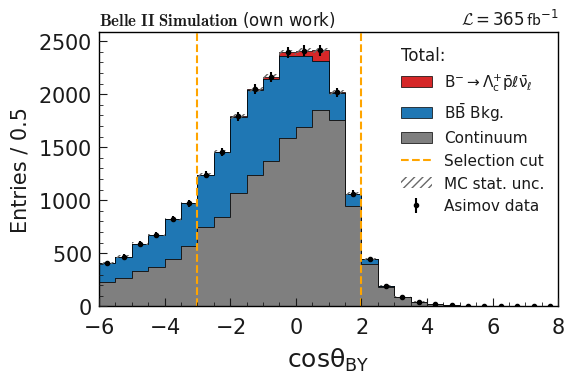

Applying cut for B_cosThetaBetweenParticleAndNominalB (total): -3 < B_cosThetaBetweenParticleAndNominalB < 2

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9965
Background efficiency: 0.7538



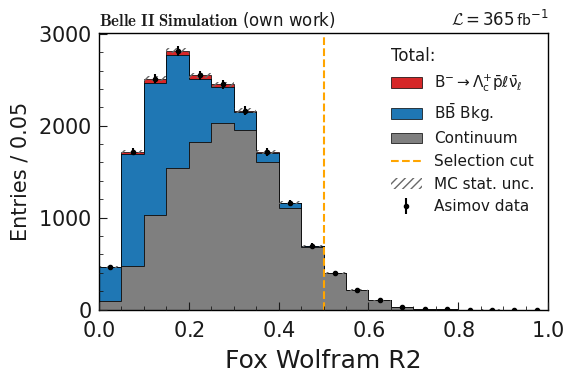

Applying cut for B_foxWolframR2 (total): B_foxWolframR2 < 0.5

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9930
Background efficiency: 0.7286



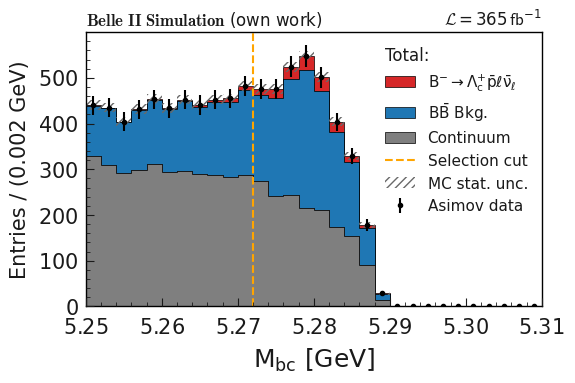

Applying cut for Btag_Mbc (total): Btag_Mbc >= 5.272

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7467
Background efficiency: 0.1572



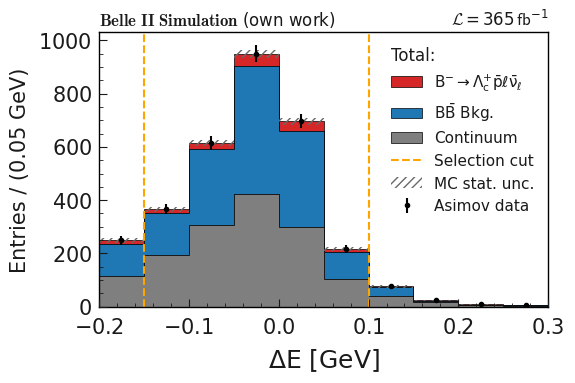

Applying cut for Btag_deltaE (total): -0.15 <= Btag_deltaE <= 0.10

Selection:  -0.15 <= Btag_deltaE <= 0.10
Signal efficiency: 0.6100
Background efficiency: 0.1290



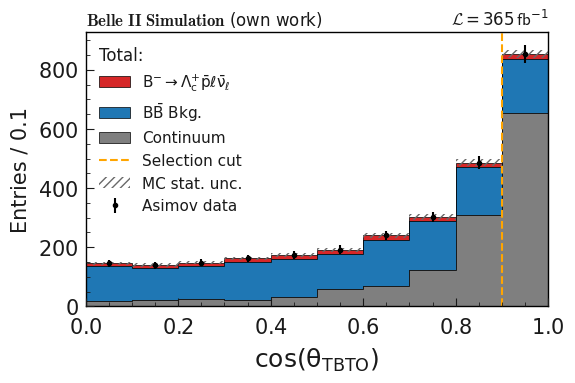

Applying cut for Btag_cosTBTO (total): Btag_cosTBTO <= 0.9

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5325
Background efficiency: 0.0957



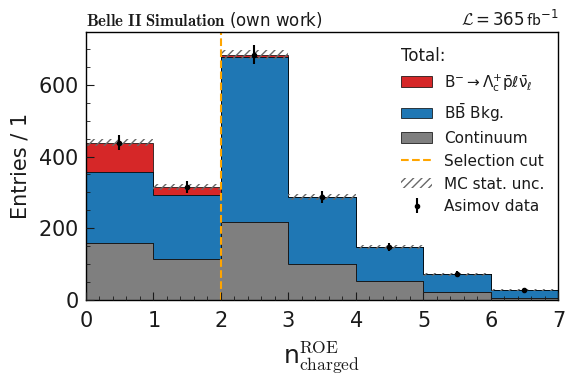

Applying cut for nROE_Charged__bo__bc (total): nROE_Charged__bo__bc < 2

Selection:  nROE_Charged__bo__bc < 2
Signal efficiency: 0.4892
Background efficiency: 0.0489



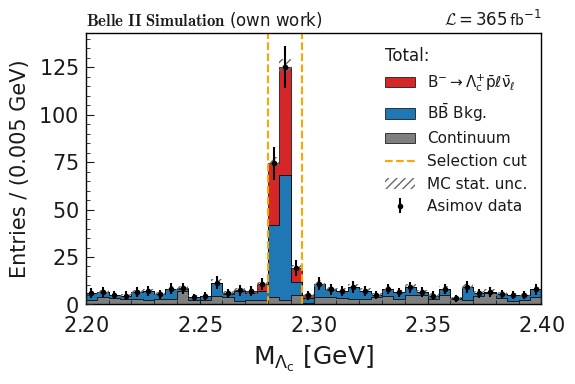

Applying cut for B_Lambda_c_InvM (total): 2.28 < B_Lambda_c_InvM < 2.295

Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.4483
Background efficiency: 0.0070



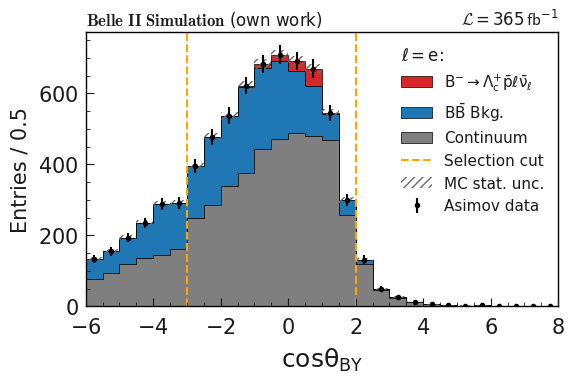

Applying cut for B_cosThetaBetweenParticleAndNominalB (e): -3 < B_cosThetaBetweenParticleAndNominalB < 2

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9937
Background efficiency: 0.7493



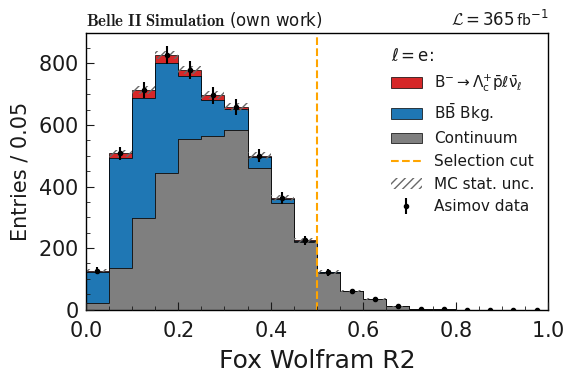

Applying cut for B_foxWolframR2 (e): B_foxWolframR2 < 0.5

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9908
Background efficiency: 0.7257



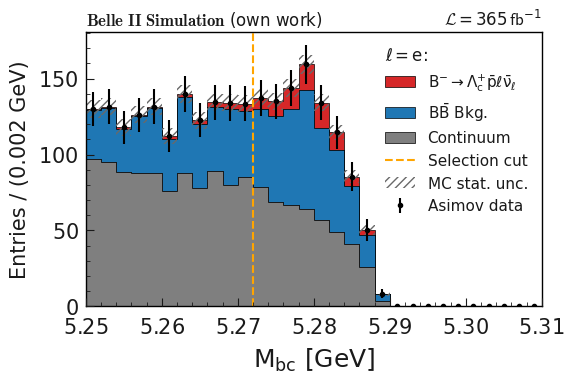

Applying cut for Btag_Mbc (e): Btag_Mbc >= 5.272

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7430
Background efficiency: 0.1633



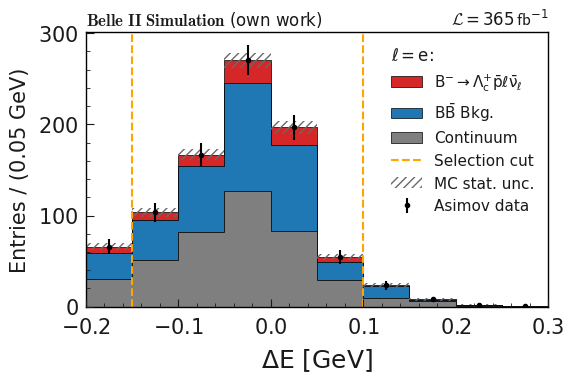

Applying cut for Btag_deltaE (e): -0.15 <= Btag_deltaE <= 0.10

Selection:  -0.15 <= Btag_deltaE <= 0.10
Signal efficiency: 0.6087
Background efficiency: 0.1333



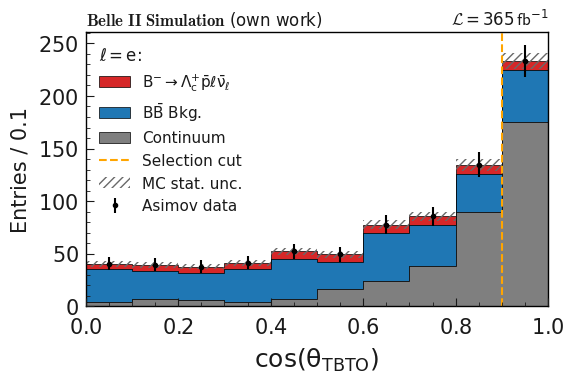

Applying cut for Btag_cosTBTO (e): Btag_cosTBTO <= 0.9

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5347
Background efficiency: 0.1030



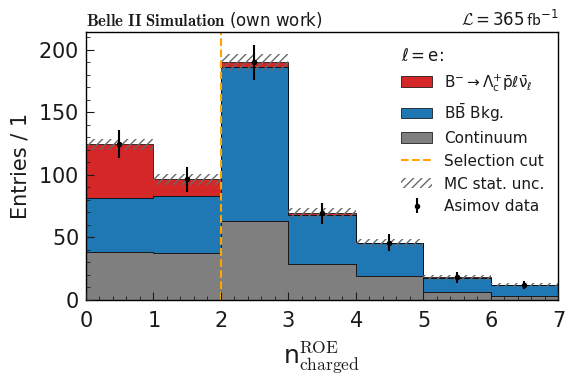

Applying cut for nROE_Charged__bo__bc (e): nROE_Charged__bo__bc < 2

Selection:  nROE_Charged__bo__bc < 2
Signal efficiency: 0.4884
Background efficiency: 0.0608



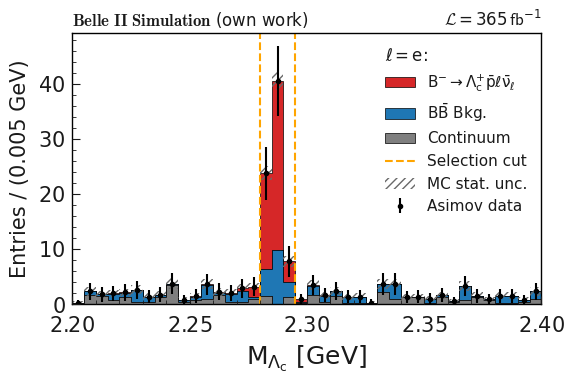

Applying cut for B_Lambda_c_InvM (e): 2.28 < B_Lambda_c_InvM < 2.295

Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.4484
Background efficiency: 0.0070



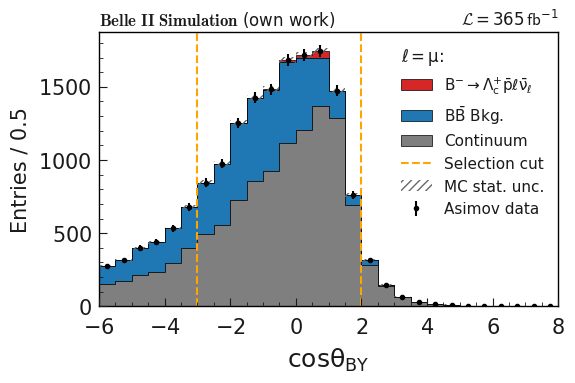

Applying cut for B_cosThetaBetweenParticleAndNominalB (mu): -3 < B_cosThetaBetweenParticleAndNominalB < 2

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9996
Background efficiency: 0.7562



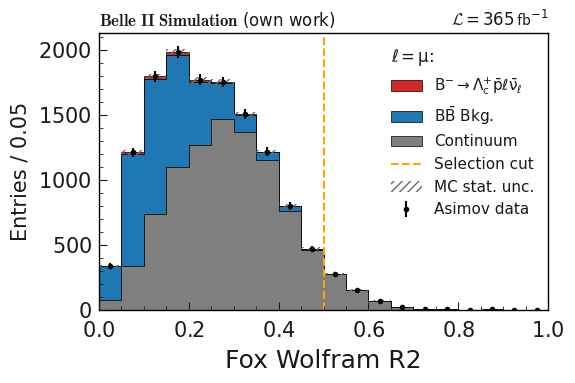

Applying cut for B_foxWolframR2 (mu): B_foxWolframR2 < 0.5

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9954
Background efficiency: 0.7300



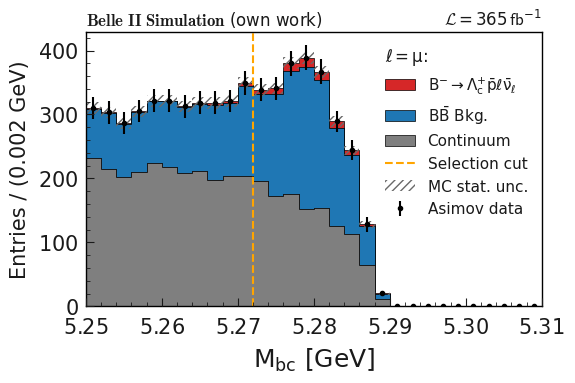

Applying cut for Btag_Mbc (mu): Btag_Mbc >= 5.272

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7509
Background efficiency: 0.1541



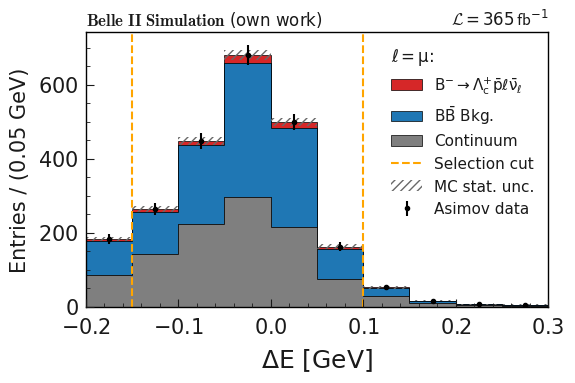

Applying cut for Btag_deltaE (mu): -0.15 <= Btag_deltaE <= 0.10

Selection:  -0.15 <= Btag_deltaE <= 0.10
Signal efficiency: 0.6115
Background efficiency: 0.1268



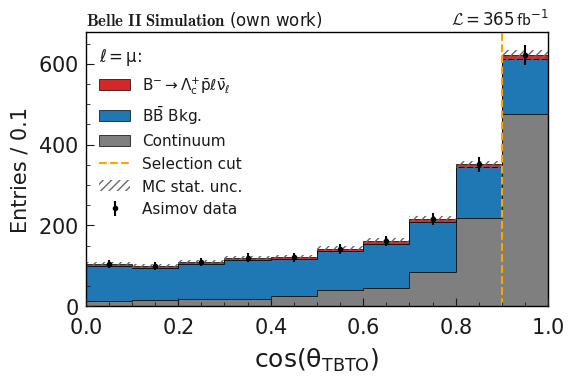

Applying cut for Btag_cosTBTO (mu): Btag_cosTBTO <= 0.9

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5301
Background efficiency: 0.0920



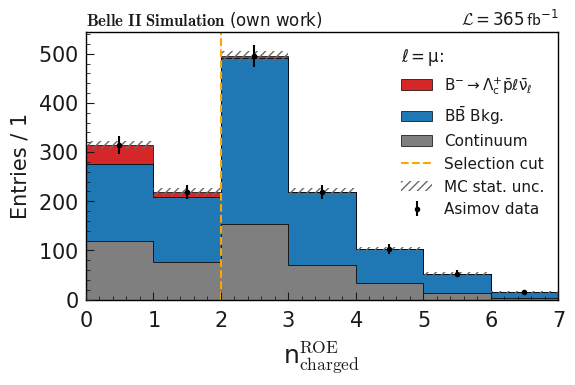

Applying cut for nROE_Charged__bo__bc (mu): nROE_Charged__bo__bc < 2

Selection:  nROE_Charged__bo__bc < 2
Signal efficiency: 0.4902
Background efficiency: 0.0429



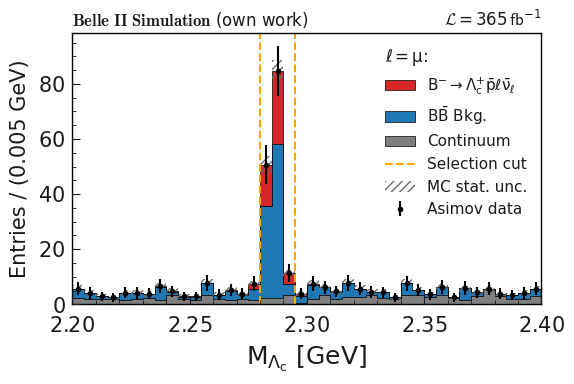

Applying cut for B_Lambda_c_InvM (mu): 2.28 < B_Lambda_c_InvM < 2.295

Selection:  2.28 < B_Lambda_c_InvM < 2.295
Signal efficiency: 0.4482
Background efficiency: 0.0069



In [129]:
#top10_ids = df_Bp_counts.head(10)["iDcyBrP"].tolist()
#print(top10_ids)
import re


#weight_column ="total_weight"
for key, df_current in dfs_cut.items():
    
    for name in further_variables:
    
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #has_data = data is not None and len(data) > 0
        
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
        #print(name, x_range, x_min, x_max, bins)


        
        if isinstance(bins, int):
            raw_width = (x_max - x_min) / bins
            # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
            bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
        else:
            # Falls 'bins' eine Liste/ein Array für variable Bin-Breiten ist
            bin_width_str = "Variable"

        # 2. Einheit aus dem x_label extrahieren (sucht nach Text in [...] Klammern)
        # Findet z.B. "GeV/c²" aus "M(pKπ) [GeV/c²]"
        unit_match = re.search(re.compile(r"\[(.*?)\]"), x_label)
        unit_str = unit_match.group(1) if unit_match else ""

        # 3. Label textuell zusammenbauen
        if bin_width_str == "Variable":
            dynamic_ylabel = "Entries / Variable Bin"
        elif unit_str:
            # Wenn eine Einheit existiert, z.B.: Entries / (0.02 GeV/c²)
            dynamic_ylabel = f"Entries / ({bin_width_str} {unit_str})"
        else:
            # Wenn die Variable ein reiner Counter ohne Einheit ist
            dynamic_ylabel = f"Entries / {bin_width_str}"


        current_n = n_config[key]
    
        
        
        d = datas_cut[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df.query(range_query).query(f"iDcyBrP_Bp_0 in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        #x2_rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_rest = df.query(range_query).query(f"iDcyBrP_Bp_0 not in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
        #x3 = continuum
        
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
        #h2_top10 = make_hist(x2_top10[name], bins=bins, range=(x_min, x_max), weights=x2_top10[weight_column])
        #h2_rest = make_hist(x2_rest[name], bins=bins, range=(x_min, x_max), weights=x2_rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value

        
        #comparison_mode = "pull" if has_data else None
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2, h1], #h2_rest, h2_top10
            stacked_labels=["Continuum", r"$B\bar{B}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"], #r"Rest $B\bar{B}$ Bkg.", r"10 biggest $B\bar{B}$ Bkg."
            stacked_colors=["tab:grey", "tab:blue", "tab:red"], #"tab:green",
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel=dynamic_ylabel,
            #comparison="pull",
            data_uncertainty_type="symmetrical", #if has_data else None
            data_label="Asimov data",
        )# r"$B\bar{B}$





        
        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)

        '''
        if name == "Btag_extraInfo_decayModeID":
            ax_comparison.set_xticks(range(34), [fei_labels[i] for i in range(34)], rotation=90, fontsize=8)
            ax_comparison.minorticks_off()
        '''
        
        '''
        if name == "B_Lambda_c_InvM":
            ax_main.axvline(
                x=2.28,
                linestyle="--",
                linewidth=1.5,
                color="orange",
            )
            ax_main.axvline(
                x=2.295,
                linestyle="--",
                linewidth=1.5,
                color="orange",
                label="Mass cut",
            )
            '''
        
        if name in CUT_MAP:
            cut_string = CUT_MAP[name]
            
            # Sucht nach Zahlen (auch mit Dezimalpunkt und Vorzeichen) im Cut-String
            # Findet z.B. [-0.15, 0.10] oder [2.28, 2.295] oder [5.272] oder [0.5]
            #values = [float(val) for val in re.findall(r"[-+]?\d*\.\d+|\d+", cut_string)]
            raw_values = re.findall(r"(?:^|[^a-zA-Z0-9.])(-?\d+\.?\d*)", cut_string)
            values = sorted([float(val) for val in raw_values])
            
            # 1. Fall: Zweiseitiger Emschnitt (z.B. "min <= x <= max" oder "min < x < max")
            if "<" in cut_string and len(values) == 2:
                val_min, val_max = values
                # Gegebenenfalls prüfen, ob der Wert im aktuellen Plot-Bereich liegt
                if x_min <= val_min <= x_max:
                    ax_main.axvline(x=val_min, linestyle="--", linewidth=1.5, color="orange")
                if x_min <= val_max <= x_max:
                    ax_main.axvline(x=val_max, linestyle="--", linewidth=1.5, color="orange", label="Selection cut")
        
            # 2. Fall: Einseitiger Schnitt nach unten (z.B. "x >= 5.272")
            elif ">" in cut_string and len(values) == 1:
                val_cut = values[0]
                if x_min <= val_cut <= x_max:
                    ax_main.axvline(x=val_cut, linestyle="--", linewidth=1.5, color="orange", label="Selection cut")
        
            # 3. Fall: Einseitiger Schnitt nach oben (z.B. "x < 0.5")
            elif "<" in cut_string and len(values) == 1:
                val_cut = values[0]
                if x_min <= val_cut <= x_max:
                    ax_main.axvline(x=val_cut, linestyle="--", linewidth=1.5, color="orange", label="Selection cut")
        
                
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
    
        #if name == 'Btag_Mbc' or name == 'Btag_deltaE' or name == 'B_cosThetaBetweenParticleAndNominalB' or name == "nROE_Charged__bo__bc":
        #leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=11)
        #else:
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, fontsize=11) #handles, labels)
        #ax_main.legend()
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        #add_text(f"    {label_map[key]}", x="left", y="top_in", ax=ax_main)
        leg._legend_box.align = "left"
        ax_main.yaxis.label.set_size(15)
        '''
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 11}, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=10) #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        leg._legend_box.align = "left"
        '''

        ax_main.set_ylim(bottom=0)
        
        #if name == 'Btag_Mbc' or name == 'Btag_deltaE' or name == 'B_cosThetaBetweenParticleAndNominalB' or name == "nROE_Charged__bo__bc":
        #orig_width, orig_height = fig.get_size_inches()
        #fig.set_size_inches(orig_width + 1.5, orig_height)
    
        fig.savefig(f"graphs/{key}/{name}_{key}_cut.png", bbox_inches="tight", dpi=300)  
        #fig.savefig(f"graphs/{key}/{name}_{key}_cut.svg", bbox_inches="tight")  
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        #plt.grid()
        plt.show()
        plt.close()

        
        
        
        if name in CUT_MAP:
            cut_string = CUT_MAP[name]
            
            print(f"Applying cut for {name} ({key}): {cut_string}")
            
            df_current = apply_cut(
                df_current, 
                cut_string, 
                current_n["sig"], 
                current_n["bkg"]
            )

        #df_current = apply_cut(df_current, "B_foxWolframR2 < 0.5", N_SIGNAL, N_BACKGROUND)
        dfs_cut[key] = df_current

In [130]:
N_SIGNAL = len(df_cut.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND = len(df_cut.query("B_isSignalAcceptMissingNeutrino != 1"))

In [131]:
n_start, mult_start = get_stats(df_cut)
#print(df_cut.B_isSignalAcceptMissing.value_counts())
print(f"Baseline: Nevents={n_start}, Multiplicity={mult_start:.3f}")

#print("B_sig cuts")

df_cut = apply_cut(df_cut, "-3 < B_cosThetaBetweenParticleAndNominalB < 2", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"cosThetaB Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")


df_cut = apply_cut(df_cut, "B_foxWolframR2 < 0.5", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"foxWolframR2 Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")


#print("B_tag cuts")


df_cut = apply_cut(df_cut, "Btag_Mbc >= 5.272", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"Mbc Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut = apply_cut(df_cut, "-0.15 <= Btag_deltaE <= 0.1", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"deltaE Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut = apply_cut(df_cut, "Btag_cosTBTO <= 0.9", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"cosTBTO Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut = apply_cut(df_cut, "Btag_extraInfo_SignalProbability > 0.001", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"SignProb Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut_sorted = df_cut.sort_values(by=["__event__", "Btag_extraInfo_SignalProbability"], ascending=[True, False])
df_cut = df_cut_sorted.drop_duplicates(subset=["__event__"], keep="first")
n_signal_after = len(df_cut.query("B_isSignalAcceptMissingNeutrino == 1"))
n_background_after = len(df_cut.query("B_isSignalAcceptMissingNeutrino != 1"))
print(f"Signal efficiency: {100.*n_signal_after / N_SIGNAL:.2f}")
print(f"Background efficiency: {100.*n_background_after / N_BACKGROUND:.2f}")
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"SignProb Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut = apply_cut(df_cut, "nROE_Charged__bo__bc < 2", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"nROE charged Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")



df_cut = apply_cut(df_cut, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL, N_BACKGROUND)
n_cut, mult_cut = get_stats(df_cut)
rel_frac = (n_cut / n_start) * 100
print(f"InvM Cut: Nevents={n_cut}, Mult={mult_cut:.3f}, Rel. Frac={rel_frac:.2f}%")

#print(df_cut.B_isSignalAcceptMissing.value_counts())

Baseline: Nevents=56823, Multiplicity=2.750

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9965
Background efficiency: 0.7538

cosThetaB Cut: Nevents=47034, Mult=2.702, Rel. Frac=82.77%

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9930
Background efficiency: 0.7286

foxWolframR2 Cut: Nevents=45546, Mult=2.721, Rel. Frac=80.15%

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7467
Background efficiency: 0.1572

Mbc Cut: Nevents=17360, Mult=2.711, Rel. Frac=30.55%

Selection:  -0.15 <= Btag_deltaE <= 0.1
Signal efficiency: 0.6100
Background efficiency: 0.1290

deltaE Cut: Nevents=15803, Mult=2.438, Rel. Frac=27.81%

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5325
Background efficiency: 0.0957

cosTBTO Cut: Nevents=12939, Mult=2.444, Rel. Frac=22.77%

Selection:  Btag_extraInfo_SignalProbability > 0.001
Signal efficiency: 0.5325
Background efficiency: 0.0957

SignProb Cut: Nevents=12939, Mult=2.444, Rel. Frac=22.77%
Signal efficiency

In [132]:
N_SIGNAL_E = len(df_cut_e.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND_E = len(df_cut_e.query("B_isSignalAcceptMissingNeutrino != 1"))

In [133]:
n_start_e, mult_start_e = get_stats(df_cut_e)
#print(df_cut_e.B_isSignalAcceptMissing.value_counts())
print(f"Baseline: Nevents={n_start_e}, Multiplicity={mult_start_e:.3f}")

#print("B_sig cuts")

df_cut_e = apply_cut(df_cut_e, "-3 < B_cosThetaBetweenParticleAndNominalB < 2", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"cosThetaB Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")


df_cut_e = apply_cut(df_cut_e, "B_foxWolframR2 < 0.5", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"foxWolframR2 Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")


#print("B_tag cuts")


df_cut_e = apply_cut(df_cut_e, "Btag_Mbc >= 5.272", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"Mbc Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e = apply_cut(df_cut_e, "-0.15 <= Btag_deltaE <= 0.1", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"deltaE Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e = apply_cut(df_cut_e, "Btag_cosTBTO <= 0.9", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"cosTBTO Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e = apply_cut(df_cut_e, "Btag_extraInfo_SignalProbability > 0.001", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"SignProb Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e_sorted = df_cut_e.sort_values(by=["__event__", "Btag_extraInfo_SignalProbability"], ascending=[True, False])
df_cut_e = df_cut_e_sorted.drop_duplicates(subset=["__event__"], keep="first")
n_signal_after_e = len(df_cut_e.query("B_isSignalAcceptMissingNeutrino == 1"))
n_background_after_e = len(df_cut_e.query("B_isSignalAcceptMissingNeutrino != 1"))
print(f"Signal efficiency: {100.*n_signal_after_e / N_SIGNAL_E:.2f}")
print(f"Background efficiency: {100.*n_background_after_e / N_BACKGROUND_E:.2f}")
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"SignProb Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e = apply_cut(df_cut_e, "nROE_Charged__bo__bc < 2", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"nROE charged Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")



df_cut_e = apply_cut(df_cut_e, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL_E, N_BACKGROUND_E)
n_cut_e, mult_cut_e = get_stats(df_cut_e)
rel_frac_e = (n_cut_e / n_start_e) * 100
print(f"InvM Cut: Nevents={n_cut_e}, Mult={mult_cut_e:.3f}, Rel. Frac={rel_frac_e:.2f}%")

#print(df_cut_e.B_isSignalAcceptMissing.value_counts())

Baseline: Nevents=22754, Multiplicity=2.638

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9937
Background efficiency: 0.7493

cosThetaB Cut: Nevents=18850, Mult=2.649, Rel. Frac=82.84%

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9908
Background efficiency: 0.7257

foxWolframR2 Cut: Nevents=18324, Mult=2.671, Rel. Frac=80.53%

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7430
Background efficiency: 0.1633

Mbc Cut: Nevents=8204, Mult=2.630, Rel. Frac=36.06%

Selection:  -0.15 <= Btag_deltaE <= 0.1
Signal efficiency: 0.6087
Background efficiency: 0.1333

deltaE Cut: Nevents=7502, Mult=2.354, Rel. Frac=32.97%

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5347
Background efficiency: 0.1030

cosTBTO Cut: Nevents=6307, Mult=2.371, Rel. Frac=27.72%

Selection:  Btag_extraInfo_SignalProbability > 0.001
Signal efficiency: 0.5347
Background efficiency: 0.1030

SignProb Cut: Nevents=6307, Mult=2.371, Rel. Frac=27.72%
Signal efficiency: 21

In [134]:
N_SIGNAL_MU = len(df_cut_mu.query("B_isSignalAcceptMissingNeutrino == 1"))
N_BACKGROUND_MU = len(df_cut_mu.query("B_isSignalAcceptMissingNeutrino != 1"))

In [135]:
n_start_mu, mult_start_mu = get_stats(df_cut_mu)
#print(df_cut_e.B_isSignalAcceptMissing.value_counts())
print(f"Baseline: Nevents={n_start_mu}, Multiplicity={mult_start_mu:.3f}")

#print("B_sig cuts")

df_cut_mu = apply_cut(df_cut_mu, "-3 < B_cosThetaBetweenParticleAndNominalB < 2", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"cosThetaB Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "B_foxWolframR2 < 0.5", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"foxWolframR2 Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")


#print("B_tag cuts")


df_cut_mu = apply_cut(df_cut_mu, "Btag_Mbc >= 5.272", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"Mbc Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "-0.15 <= Btag_deltaE <= 0.1", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"deltaE Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "Btag_cosTBTO <= 0.9", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"cosTBTO Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "Btag_extraInfo_SignalProbability > 0.001", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"SignProb Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu_sorted = df_cut_mu.sort_values(by=["__event__", "Btag_extraInfo_SignalProbability"], ascending=[True, False])
df_cut_mu = df_cut_mu_sorted.drop_duplicates(subset=["__event__"], keep="first")
n_signal_after_mu = len(df_cut_mu.query("B_isSignalAcceptMissingNeutrino == 1"))
n_background_after_mu = len(df_cut_mu.query("B_isSignalAcceptMissingNeutrino != 1"))
print(f"Signal efficiency: {100.*n_signal_after_mu / N_SIGNAL_MU:.2f}")
print(f"Background efficiency: {100.*n_background_after_mu / N_BACKGROUND_MU:.2f}")
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"SignProb Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "nROE_Charged__bo__bc < 2", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"nROE charged Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")



df_cut_mu = apply_cut(df_cut_mu, "2.28 < B_Lambda_c_InvM < 2.295", N_SIGNAL_MU, N_BACKGROUND_MU)
n_cut_mu, mult_cut_mu = get_stats(df_cut_mu)
rel_frac_mu = (n_cut_mu / n_start_mu) * 100
print(f"InvM Cut: Nevents={n_cut_mu}, Mult={mult_cut_mu:.3f}, Rel. Frac={rel_frac_mu:.2f}%")

#print(df_cut_e.B_isSignalAcceptMissing.value_counts())

Baseline: Nevents=38241, Multiplicity=2.517

Selection:  -3 < B_cosThetaBetweenParticleAndNominalB < 2
Signal efficiency: 0.9996
Background efficiency: 0.7562

cosThetaB Cut: Nevents=31571, Mult=2.443, Rel. Frac=82.56%

Selection:  B_foxWolframR2 < 0.5
Signal efficiency: 0.9954
Background efficiency: 0.7300

foxWolframR2 Cut: Nevents=30538, Mult=2.456, Rel. Frac=79.86%

Selection:  Btag_Mbc >= 5.272
Signal efficiency: 0.7509
Background efficiency: 0.1541

Mbc Cut: Nevents=10519, Mult=2.423, Rel. Frac=27.51%

Selection:  -0.15 <= Btag_deltaE <= 0.1
Signal efficiency: 0.6115
Background efficiency: 0.1268

deltaE Cut: Nevents=9471, Mult=2.203, Rel. Frac=24.77%

Selection:  Btag_cosTBTO <= 0.9
Signal efficiency: 0.5301
Background efficiency: 0.0920

cosTBTO Cut: Nevents=7529, Mult=2.215, Rel. Frac=19.69%

Selection:  Btag_extraInfo_SignalProbability > 0.001
Signal efficiency: 0.5301
Background efficiency: 0.0920

SignProb Cut: Nevents=7529, Mult=2.215, Rel. Frac=19.69%
Signal efficiency: 2

# TopoAna

In [136]:
rows_B0 = []
rows_Bp = []

current = None  # remembers if we are in charged or mixed

#with open("topoana/results/hadronic/BB/Lcplnu_BB_skim_had_topoana.txt", "r", encoding="utf-8") as f:
with open("topoana/results/hadronic/BB/Lcplnu_BB_proc7_veto_topoana.txt", "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    line=line.strip()
    
    if line.startswith("Decay branches of B0"):
        current = "B0"
    
    elif line.startswith("Decay branches of B+"):
        current = "Bp"
        
    # gets only the lines which start with "rowNo."
    if line.startswith("rowNo:") and current is not None:
        parts=line.split()

        # get the values at right positions
        row = {
            "rowNo": int(parts[1]),
            "iDcyBrP": int(parts[3]),
            "nCase": int(parts[5]),
            "nCcCase": int(parts[7]),
            "nAllCase": int(parts[9]),
            "nCCase": int(parts[11]),
            "Decay": lines[i+1].strip()
        }

        # append row to right list
        if current == "B0":
            rows_B0.append(row)
        elif current == "Bp":
            rows_Bp.append(row)

# transform to dataframe
df_B0 = pd.DataFrame(rows_B0)
df_Bp = pd.DataFrame(rows_Bp)

#print(df_Bp)

#df_ID_Bp = df_Bp[["iDcyBrP"]]
#print(df_ID_Bp)

In [137]:
def safe_int(val):
    try:
        return int(val)
    except (ValueError, TypeError):
        return -1

dataframes = {"total": df_background, 
              "e": df_background_e, 
              "mu": df_background_mu,
              #"total": df_background_veto, 
              #"e": df_background_veto_e, 
              #"mu": df_background_veto_mu
}

top10_results = {}


# ----------------------------
#   B+ / B- 
# ----------------------------

for name,df_b in dataframes.items():
    
    ids_Bp, ids_Bm = [], []

    for _, row in df_b.iterrows():
        B_mcPDG = row.get("B_mcPDG", 0)
        B_Lambda_c_mcPDG = row.get("B_Lambda_c_mcPDG", 0)
        B_Lambda_c_p_mcPDG = row.get("B_Lambda_c_p_mcPDG", 0)
        
    
        # Standard
        if B_mcPDG == 521:  # B+
            ids_Bp.append(safe_int(row.get("iDcyBrP_Bp_0", -1)))
        elif B_mcPDG == -521:  # B-
            ids_Bm.append(safe_int(row.get("iDcyBrCcP_Bp_0", -1)))
    
        # Fallback, if B_mcPDG is not 521
        elif B_mcPDG not in [521, -521, 511, -511]:
            if B_Lambda_c_mcPDG < 0:
                ids_Bp.append(safe_int(row.get("iDcyBrP_Bp_0", -1)))
            elif B_Lambda_c_mcPDG > 0 and B_Lambda_c_mcPDG != 300553:
                ids_Bm.append(safe_int(row.get("iDcyBrCcP_Bp_0", -1)))
        elif B_Lambda_c_mcPDG == 300553:
            if B_Lambda_c_p_mcPDG < 0:
                ids_Bp.append(safe_int(row.get("iDcyBrP_Bp_0", -1)))
            elif B_Lambda_c_p_mcPDG > 0:
                ids_Bm.append(safe_int(row.get("iDcyBrCcP_Bp_0", -1)))
    
    # Filter out -1 
    ids_Bp = [i for i in ids_Bp if i != -1]
    ids_Bm = [i for i in ids_Bm if i != -1]
    
    count_Bp = Counter(ids_Bp)
    count_Bm = Counter(ids_Bm)

    rows_Bp_counts = []
    all_ids_Bp = set(count_Bp.keys()) | set(count_Bm.keys())
    
    for iDcy in all_ids_Bp:
        nCase = count_Bp.get(iDcy, 0)
        nCcCase = count_Bm.get(iDcy, 0)
        nAllCase = nCase + nCcCase
        rows_Bp_counts.append({
            "iDcyBrP": iDcy,
            "nCase": nCase,
            "nCcCase": nCcCase,
            "nAllCase": nAllCase,
            "nCCase": len(df_background)
        })
    
    #df_Bp_counts_tmp = pd.DataFrame(rows_Bp_counts)
    df_Bp_counts_tmp = pd.DataFrame(rows_Bp_counts, columns=["iDcyBrP", "nCase", "nCcCase", "nAllCase", "nCCase"])
    df_Bp_counts = df_Bp.merge(df_Bp_counts_tmp, on="iDcyBrP", how="inner", suffixes=("", "_new"))
    df_Bp_counts = df_Bp_counts[["rowNo", "iDcyBrP", "Decay",
                                 "nCase_new", "nCcCase_new", "nAllCase_new", "nCCase_new"]]
    df_Bp_counts.columns = ["rowNo", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase", "nCCase"]
    df_Bp_counts = df_Bp_counts.sort_values("nAllCase", ascending=False)


# ----------------------------
#   B0 / B0bar  
# ----------------------------



    ids_B0, ids_B0bar = [], []
    
    for _, row in df_b.iterrows():
        B_mcPDG = row.get("B_mcPDG", 0)
        B_Lambda_c_mcPDG = row.get("B_Lambda_c_mcPDG", 0)
        B_Lambda_c_p_mcPDG = row.get("B_Lambda_c_p_mcPDG", 0)
    
        # Standard
        if B_mcPDG == 511:
            id0 = safe_int(row.get("iDcyBrP_B0_0", -1))
            id1 = safe_int(row.get("iDcyBrP_B0_1", -1))
            if id1 != -1:  # take only mixing ID
                ids_B0.append(id1)
            elif id0 != -1:
                ids_B0.append(id0)
        elif B_mcPDG == -511:
            id0 = safe_int(row.get("iDcyBrCcP_B0_0", -1))
            id1 = safe_int(row.get("iDcyBrCcP_B0_1", -1))
            if id1 != -1:
                ids_B0bar.append(id1)
            elif id0 != -1:
                ids_B0bar.append(id0)
    
        # Fallback if B_mcPDG not 511
        elif B_mcPDG not in [521, -521, 511, -511]:
            if B_Lambda_c_mcPDG < 0:  
                id0 = safe_int(row.get("iDcyBrP_B0_0", -1))
                id1 = safe_int(row.get("iDcyBrP_B0_1", -1))
                if id1 != -1:
                    ids_B0.append(id1)
                elif id0 != -1:
                    ids_B0.append(id0)
            elif B_Lambda_c_mcPDG > 0 and B_Lambda_c_mcPDG != 300553: 
                id0 = safe_int(row.get("iDcyBrCcP_B0_0", -1))
                id1 = safe_int(row.get("iDcyBrCcP_B0_1", -1))
                if id1 != -1:
                    ids_B0bar.append(id1)
                elif id0 != -1:
                    ids_B0bar.append(id0)
            elif B_Lambda_c_mcPDG == 300553:
                if B_Lambda_c_p_mcPDG < 0:
                    id0 = safe_int(row.get("iDcyBrP_B0_0", -1))
                    id1 = safe_int(row.get("iDcyBrP_B0_1", -1))
                    if id1 != -1:
                        ids_B0bar.append(id1)
                    elif id0 != -1:
                        ids_B0bar.append(id0)
                elif B_Lambda_c_p_mcPDG > 0:
                    id0 = safe_int(row.get("iDcyBrCcP_B0_0", -1))
                    id1 = safe_int(row.get("iDcyBrCcP_B0_1", -1))
                    if id1 != -1:
                        ids_B0bar.append(id1)
                    elif id0 != -1:
                        ids_B0bar.append(id0)

# Filter out -1 
    ids_B0 = [i for i in ids_B0 if i != -1]
    ids_B0bar = [i for i in ids_B0bar if i != -1]
    
    count_B0 = Counter(ids_B0)
    count_B0bar = Counter(ids_B0bar)
    
    rows_B0_counts = []
    all_ids_B0 = set(count_B0.keys()) | set(count_B0bar.keys())
    
    for iDcy in all_ids_B0:
        nCase = count_B0.get(iDcy, 0)
        nCcCase = count_B0bar.get(iDcy, 0)
        nAllCase = nCase + nCcCase
        rows_B0_counts.append({
            "iDcyBrP": iDcy,
            "nCase": nCase,
            "nCcCase": nCcCase,
            "nAllCase": nAllCase,
            "nCCase": len(df_background)
        })
    
    #df_B0_counts_tmp = pd.DataFrame(rows_B0_counts)
    df_B0_counts_tmp = pd.DataFrame(rows_B0_counts, columns=["iDcyBrP", "nCase", "nCcCase", "nAllCase", "nCCase"])
    df_B0_counts = df_B0.merge(df_B0_counts_tmp, on="iDcyBrP", how="inner", suffixes=("", "_new"))
    df_B0_counts = df_B0_counts[["rowNo", "iDcyBrP", "Decay",
                                 "nCase_new", "nCcCase_new", "nAllCase_new", "nCCase_new"]]
    df_B0_counts.columns = ["rowNo", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase", "nCCase"]
    df_B0_counts = df_B0_counts.sort_values("nAllCase", ascending=False)


# ----------------------------
#   Combined Table
# ----------------------------

    df_Bp_counts["B_type"] = "B+"
    df_B0_counts["B_type"] = "B0"
    
    df_all = pd.concat([df_Bp_counts, df_B0_counts], ignore_index=True)
    df_all_sorted = df_all.sort_values("nAllCase", ascending=False)
    
    print(name)
    display(df_all_sorted.head(10)[["B_type", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase"]])

    #if k>3:
    top10_ids = df_all_sorted.head(10)["iDcyBrP"].tolist()
    ids_str = ",".join(map(str, top10_ids))

    top10_results[name] = {
        'top10_ids': top10_ids,
        'ids_str': ids_str
    }

    latex_code = df_all_sorted.head(10)[["B_type", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase"]].to_latex(index=False)
    #print(latex_code)

    
print(len(df_background))
print(len(df_background_e))
print(len(df_background_mu))

total


,B_type,iDcyBrP,Decay,nCase,nCcCase,nAllCase
0,B+,24,B+ --> pi0 pi+ p+ anti-Lambda_c-,3,11,14
1,B+,12,B+ --> pi0 Delta++ anti-Sigma_c-,4,6,10
2,B+,52,B+ --> pi+ Delta++ anti-Sigma_c--,5,3,8
3,B+,14,B+ --> pi0 Delta++ anti-Sigma_c*-,2,3,5
4,B+,46,B+ --> pi+ Delta+ anti-Sigma_c*-,2,3,5
5,B+,69,B+ --> pi+ pi+ pi- p+ anti-Lambda_c-,4,1,5
6,B+,87,B+ --> rho+ Delta++ anti-Sigma_c--,3,1,4
7,B+,3,B+ --> pi+ Delta+ anti-Sigma_c-,2,2,4
8,B+,104,B+ --> pi+ Delta++ anti-Sigma_c-- gammaF,1,2,3
9,B+,112,B+ --> pi+ p+ anti-Sigma_c*-,1,2,3


e


,B_type,iDcyBrP,Decay,nCase,nCcCase,nAllCase
0,B+,120,B+ --> pi- Delta++ anti-Sigma_c0,1,1,2
1,B+,12,B+ --> pi0 Delta++ anti-Sigma_c-,1,1,2
2,B+,101,B+ --> pi+ Delta+ anti-Sigma_c*- gammaF,0,2,2
3,B+,9,B+ --> anti-D0 anti-p- Delta++,0,1,1
4,B+,24,B+ --> pi0 pi+ p+ anti-Lambda_c-,0,1,1
5,B+,69,B+ --> pi+ pi+ pi- p+ anti-Lambda_c-,1,0,1
6,B+,62,B+ --> pi0 pi+ anti-D*0 p+ anti-p-,1,0,1
7,B+,125,B+ --> pi0 Delta+ anti-Sigma_c*0,1,0,1
8,B+,74,B+ --> pi- Delta++ anti-Sigma_c*0,1,0,1
9,B+,87,B+ --> rho+ Delta++ anti-Sigma_c--,0,1,1


mu


,B_type,iDcyBrP,Decay,nCase,nCcCase,nAllCase
0,B+,24,B+ --> pi0 pi+ p+ anti-Lambda_c-,3,10,13
1,B+,52,B+ --> pi+ Delta++ anti-Sigma_c--,5,3,8
2,B+,12,B+ --> pi0 Delta++ anti-Sigma_c-,3,5,8
3,B+,46,B+ --> pi+ Delta+ anti-Sigma_c*-,2,3,5
4,B+,14,B+ --> pi0 Delta++ anti-Sigma_c*-,2,3,5
5,B+,69,B+ --> pi+ pi+ pi- p+ anti-Lambda_c-,3,1,4
6,B+,3,B+ --> pi+ Delta+ anti-Sigma_c-,2,2,4
7,B+,112,B+ --> pi+ p+ anti-Sigma_c*-,1,2,3
8,B+,104,B+ --> pi+ Delta++ anti-Sigma_c-- gammaF,1,2,3
9,B+,87,B+ --> rho+ Delta++ anti-Sigma_c--,3,0,3


126
23
103


In [138]:
latex_table = df_all_sorted.head(10)[["B_type", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase"]].to_latex(
    index=False,
    caption="10 biggest background channels",
    label="tab:erste10",
    float_format="%.2f"
)

In [139]:
rows_Bp_sig = []


with open("topoana/results/hadronic/signMC/Lcplnu_signMC_veto5_topoana.txt", "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    line=line.strip()
        
    # gets only the lines which start with "rowNo."
    if line.startswith("rowNo:"):
        parts=line.split()

        # get the values at right positions
        row = {
            "rowNo": int(parts[1]),
            "iDcyBrP": int(parts[3]),
            "nCase": int(parts[5]),
            "nCcCase": int(parts[7]),
            "nAllCase": int(parts[9]),
            "nCCase": int(parts[11]),
            "Decay": lines[i+1].strip()
        }

        # append row to right list
        rows_Bp_sig.append(row)

# transform to dataframe
df_Bp_sig = pd.DataFrame(rows_Bp_sig)

In [140]:


ids_Bp_sig, ids_Bm_sig = [], []

for _, row in df_signMC.iterrows():
    B_mcPDG_sig = row.get("B_mcPDG", 0)
    B_Lambda_c_p_mcPDG_sig = row.get("B_Lambda_c_p_mcPDG", 0)
    

    # Standard
    if B_mcPDG_sig == 521:  # B+
        ids_Bp_sig.append(safe_int(row.get("iDcyBrP_Bp_0", -1)))
    elif B_mcPDG_sig == -521:  # B-
        ids_Bm_sig.append(safe_int(row.get("iDcyBrCcP_Bp_0", -1)))

    # Fallback, if B_mcPDG is not 521
    elif B_mcPDG_sig not in [521, -521]:
        if B_Lambda_c_p_mcPDG_sig < 0:
            ids_Bp_sig.append(safe_int(row.get("iDcyBrP_Bp_0", -1)))
        elif B_Lambda_c_p_mcPDG_sig > 0:
            ids_Bm_sig.append(safe_int(row.get("iDcyBrCcP_Bp_0", -1)))

# Filter out -1 
ids_Bp_sig = [i for i in ids_Bp if i != -1]
ids_Bm_sig = [i for i in ids_Bm if i != -1]

count_Bp_sig = Counter(ids_Bp_sig)
count_Bm_sig = Counter(ids_Bm_sig)

rows_Bp_counts_sig = []
all_ids_Bp_sig = set(count_Bp_sig.keys()) | set(count_Bm_sig.keys())

for iDcyBr in all_ids_Bp_sig:
    nCase_sig = count_Bp_sig.get(iDcyBr, 0)
    nCcCase_sig = count_Bm_sig.get(iDcyBr, 0)
    nAllCase_sig = nCase_sig + nCcCase_sig
    rows_Bp_counts_sig.append({
        "iDcyBrP": iDcyBr,
        "nCase": nCase_sig,
        "nCcCase": nCcCase_sig,
        "nAllCase": nAllCase_sig,
        "nCCase": len(df_signMC)
    })

df_Bp_counts_tmp_sig = pd.DataFrame(rows_Bp_counts_sig)
df_Bp_counts_sig = df_Bp_sig.merge(df_Bp_counts_tmp_sig, on="iDcyBrP", how="inner", suffixes=("", "_new"))
df_Bp_counts_sig = df_Bp_counts_sig[["rowNo", "iDcyBrP", "Decay",
                             "nCase_new", "nCcCase_new", "nAllCase_new", "nCCase_new"]]
df_Bp_counts_sig.columns = ["rowNo", "iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase", "nCCase"]
df_Bp_counts_sig = df_Bp_counts_sig.sort_values("nAllCase", ascending=False)

#df_Bp_counts["B_type"] = "B+"
df_Bp_sorted_sig = df_Bp_sig.sort_values("nAllCase", ascending=False)

display(df_Bp_sorted_sig.head(10)[["iDcyBrP", "Decay", "nCase", "nCcCase", "nAllCase"]])

,iDcyBrP,Decay,nCase,nCcCase,nAllCase
0,1,B+ --> mu+ nu_mu p+ anti-Lambda_c-,1809,1776,3585
1,5,B+ --> e+ nu_e p+ anti-Lambda_c-,1488,1489,2977
2,8,B+ --> e+ nu_e p+ anti-Lambda_c- gammaF,657,728,1385
3,2,B+ --> rho+ anti-D0,653,629,1282
4,0,B+ --> anti-D*0 a_1+,449,453,902
5,7,B+ --> rho+ anti-D*0,368,337,705
6,17,B+ --> anti-D0 a_1+,353,312,665
7,11,B+ --> pi+ anti-D0,298,309,607
8,9,B+ --> pi+ anti-D*0,293,304,597
9,3,B+ --> mu+ nu_mu p+ anti-Lambda_c- gammaF,261,232,493


In [141]:
#df[(df["B_mu_electronID"]>0.9) | (df["B_mu_muonID"]>0.9)][["__weight__","Btag_cosThetaBetweenParticleAndNominalB","template", 'B_mu_electronID', "B_mu_muonID", "B_mu_p","isContinuumEvent","B_isSignalAcceptMissingNeutrino","B_mcPDG"]]

## Condition

In [142]:
condition_template = (
        "(B_mcPDG == 521.0 and iDcyBrP_Bp_0 in [{ids}]) "
        "or (B_mcPDG == -521.0 and iDcyBrCcP_Bp_0 in [{ids}]) "
        "or (B_Lambda_c_mcPDG < 0 and iDcyBrP_Bp_0 in [{ids}]) "
        "or (B_Lambda_c_mcPDG > 0 and B_Lambda_c_mcPDG != 300553 and iDcyBrCcP_Bp_0 in [{ids}]) "
        "or (B_Lambda_c_mcPDG == B_mcPDG and B_Lambda_c_p_mcPDG < 0 and iDcyBrP_Bp_0 in [{ids}]) "
        "or (B_Lambda_c_mcPDG == B_mcPDG and B_Lambda_c_p_mcPDG > 0 and iDcyBrCcP_Bp_0 in [{ids}]) "
)

conditions = {}

for name, result in top10_results.items():
    conditions[name] = condition_template.format(
        ids=result["ids_str"]
    )



In [143]:
def apply_templates(df, condition):
    mask = df.eval(condition)

    #df["channel"] = "B_to_Lambda_c_plnu"
    df.loc[
        (df["B_extraInfo_decayModeID"] == 1.0),
        "channel"
    ] = "B_to_Lambda_c_plnu_e"

    df.loc[
        (df["B_extraInfo_decayModeID"] == 2.0),
        "channel"
    ] = "B_to_Lambda_c_plnu_mu"

    
    df.loc[
        (df["isContinuumEvent"] == 1) &
        (df["B_isSignalAcceptMissingNeutrino"] != 1),
        "template"
    ] = "continuum"

    df.loc[
        (df["isContinuumEvent"] != 1) &
        (df["B_isSignalAcceptMissingNeutrino"] == 1),
        "template"
    ] = "signMC"

    df.loc[
        (df["isContinuumEvent"] != 1) &
        (df["B_isSignalAcceptMissingNeutrino"] != 1),
        "template"
    ] = "background"
    

    #df["total_weight"] = 1


In [144]:
for name, df_current in dfs.items():
    condition = condition_template.format(
        ids=top10_results[name]["ids_str"]
    )

    apply_templates(df_current, condition)

In [145]:
df.head(10)[["channel","total_weight","__weight__","Btag_cosThetaBetweenParticleAndNominalB","template", 'B_mu_electronID', "B_mu_muonID", "B_mu_p","isContinuumEvent","B_isSignalAcceptMissingNeutrino","B_mcPDG"]]

,channel,total_weight,__weight__,Btag_cosThetaBetweenParticleAndNominalB,template,B_mu_electronID,B_mu_muonID,B_mu_p,isContinuumEvent,B_isSignalAcceptMissingNeutrino,B_mcPDG
3,B_to_Lambda_c_plnu_mu,0.255383,0.255383,0.911392,background,3.351437e-02,0.966458,0.330500,False,0.0,300553.0
5,B_to_Lambda_c_plnu_mu,0.255383,0.255383,0.997877,background,4.291404e-11,0.967911,0.352050,False,0.0,-511.0
14,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.012338,background,9.641328e-08,0.999995,0.363882,False,0.0,511.0
21,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.065998,background,1.126874e-09,0.902614,0.796994,False,0.0,-521.0
26,B_to_Lambda_c_plnu_mu,0.255383,0.255383,0.992403,background,6.200954e-08,0.999726,0.516727,False,0.0,-521.0
27,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.010003,background,4.893807e-04,0.986457,0.341816,False,0.0,-521.0
32,B_to_Lambda_c_plnu_mu,0.255383,0.255383,0.968770,background,1.913624e-16,0.985027,0.885332,False,0.0,300553.0
33,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.011629,background,1.389967e-31,1.000000,0.833408,False,0.0,521.0
51,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.027699,background,6.630199e-47,1.000000,1.196600,False,NaN,NaN
58,B_to_Lambda_c_plnu_mu,0.255383,0.255383,1.008282,background,8.431658e-13,0.961955,0.462900,False,0.0,521.0


## Veto validation

In [146]:
vars_want = ['__event__', 'event', 'run', 'experiment', 'M', 'dM', 'InvM', 'isSignal', 'p', 'useCMSFrame(p)', 'cosTheta', 'phi', 'chiProb', 'mcPDG', 'mcMother(PDG)', 'mcErrors', 'mcDaughter(0,PDG)',
    'mcDaughter(1,PDG)',
    'nMCDaughters',
    'nSigma_cp',
    'nSigma_cSp',
    'nSigma_cpp',
    'nSigma_cppmu',
    'nSigma_cppe',
    'dM_mu',
    #'hasMuB',
    #'hasEB',
    'extraInfo(decayModeID)',
    'muPID',
    'piPID',
    'ePID',
    'lepPDG',
    'S_decayMode',
    'B_mu_muonID',
    'B_mu_electronID']

### Sigma_c++

In [147]:
#with uproot.open("veto/Sigma_c++/Sigma_c++_Veto2.root:Sigma_cpp_veto") as file:
#with uproot.open("/data/dust/user/timmue/project/veto/Sigma_c++/processed2/veto_Sigma_c++_999_output.root:Sigma_cpp_veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/BB_had_skim_veto.root:veto") as file:

with uproot.open("/data/dust/user/timmue/project/veto/Sigma_c++/processed3/Sigma_c++_Veto.root:Sigma_cpp_veto") as file:
#with uproot.open("/data/dust/user/timmue/project/background/B_Lcplnu_BB_skim_had_v3/BB_had_veto.root:veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_want if v in available_branches]
    df_pp = file.arrays(vars_to_read, library="pd")
'''
    for var in vars_want:
        if var not in df_pp.columns:
            df_pp[var] = np.nan

file_pp = "Veto/Sigma_c++/sigmac_test.root"
tree_pp = uproot.open(file_pp)["hadronic"]  # BASF2 schreibt meistens 'ntuple' als Tree
df_pp = tree_pp.arrays(library="pd")    # pandas DataFrame
'''

print(df_pp.head(20))

    __event__         M        dM  isSignal         p  cosTheta       phi  \
0          12  2.482006  0.028036       0.0  1.759223  0.239169 -2.554051   
1          12  2.482006  0.028036       0.0  1.759223  0.239169 -2.554051   
2          17  2.359770 -0.094200       0.0  1.113989  0.824562 -0.433282   
3          22  2.595455  0.141485       0.0  2.212205  0.844659 -1.699358   
4          22  2.595455  0.141485       0.0  2.212205  0.844659 -1.699358   
5          22  2.460231  0.006261       1.0  1.466696  0.103871  1.001461   
6          22  2.468792  0.014822       0.0  1.465518  0.102777  1.123678   
7          24  2.595431  0.141461       0.0  1.210737  0.245621  1.991772   
8          25  2.592083  0.138113       0.0  0.798158  0.888865 -2.575494   
9          25  2.509154  0.055184       0.0  0.952453  0.807456 -2.794235   
10         36  2.568827  0.114857       0.0  1.540642  0.201520  0.964802   
11         39  2.404213 -0.049757       0.0  1.111001  0.826037 -2.937003   

In [148]:
df_pp.sort_values("nSigma_cpp", ascending=False).head(10)

,__event__,M,dM,isSignal,p,cosTheta,phi,chiProb,mcPDG,mcErrors,nMCDaughters,nSigma_cpp,nSigma_cppmu,nSigma_cppe,dM_mu,muPID,piPID,ePID,lepPDG,S_decayMode
145216,94,2.364512,-0.089458,0.0,0.818249,0.054069,-0.182276,-1.0,300553.0,352.0,2.0,36,0,0,0.195449,5.761942e-03,0.991248,2.990240e-03,-211.0,3.0
145185,94,2.570991,0.117021,0.0,0.965654,-0.022833,0.024300,-1.0,300553.0,352.0,2.0,36,0,0,0.361794,2.127271e-02,0.961827,1.690073e-02,-211.0,3.0
145218,94,2.342046,-0.111924,0.0,0.910386,0.338275,0.394392,-1.0,300553.0,352.0,2.0,36,0,0,0.176038,5.761942e-03,0.991248,2.990240e-03,-211.0,3.0
198880,536,2.526512,0.072542,0.0,1.700370,0.846376,-0.229833,-1.0,300553.0,304.0,2.0,36,0,0,0.416980,5.014044e-02,0.949860,1.733617e-10,-211.0,3.0
145186,94,2.506418,0.052448,0.0,0.772293,0.231796,-0.048518,-1.0,300553.0,352.0,2.0,36,0,0,0.337354,2.127271e-02,0.961827,1.690073e-02,-211.0,3.0
418763,187,2.554597,0.100627,0.0,0.424737,-0.681586,2.839852,-1.0,300553.0,304.0,2.0,36,0,0,0.445917,4.772947e-18,1.000000,8.151633e-20,-211.0,3.0
418734,187,2.469694,0.015724,0.0,0.616274,0.257377,2.481874,-1.0,300553.0,304.0,2.0,36,0,0,0.306823,2.391133e-01,0.760726,1.604777e-04,-211.0,3.0
418735,187,2.416195,-0.037775,0.0,0.678683,-0.082253,2.210098,-1.0,300553.0,304.0,2.0,36,0,0,0.307514,2.391133e-01,0.760726,1.604777e-04,-211.0,3.0
418739,187,2.433506,-0.020464,0.0,0.518574,0.216229,3.056131,-1.0,300553.0,304.0,2.0,36,0,0,0.270635,6.229751e-02,0.780010,1.576925e-01,-211.0,3.0
418740,187,2.400768,-0.053202,0.0,0.500694,-0.204332,2.673734,-1.0,300553.0,304.0,2.0,36,0,0,0.292088,6.229751e-02,0.780010,1.576925e-01,-211.0,3.0


In [149]:
df_pp['nSigma_cpp'].sum()

1732903

In [150]:
df_pp['nSigma_cppmu'].sum()

54030

In [151]:
len(df_pp)

481771

In [152]:
df_pp['isSignal'].value_counts()

isSignal
0.0    399869
1.0     78644
Name: count, dtype: int64

In [153]:
np.unique(df_pp['mcPDG'])

array([ -4224.,  -4222.,  -4122.,   -521.,    411.,    413.,    421.,
          443.,    521.,   4122.,   4222.,   4224.,   4232.,  30443.,
       300553.,     nan])

In [154]:
df_pp_sig=df_pp[df_pp['isSignal']==1]
df_pp_bkg=df_pp[df_pp['isSignal']==0]

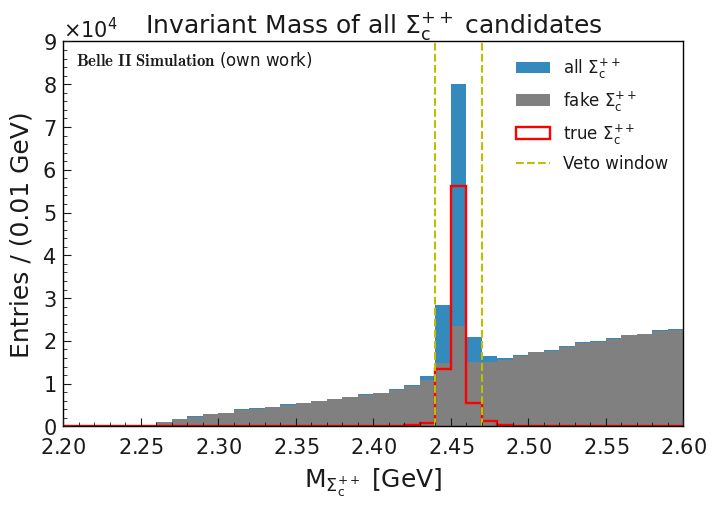

In [155]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_pp['M'], bins=50, range=(2.1, 2.6), label=r'all $\Sigma_c^{++}$')
ax.hist(df_pp_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
ax.hist(df_pp_sig['M'], bins=50, range=(2.1, 2.6), histtype='step', linewidth=1.7, color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=[2.44, 2.47], ymin=0, ymax=100000, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 90000)

plt.xlabel(r'$M_{\Sigma_c^{++}}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Sigma_c^{++}$ candidates')

# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.legend()
fig.savefig(f"graphs/Sigma_c++_veto.png", bbox_inches="tight", dpi=300)
plt.show()


In [156]:
df_pp_peak = df_pp_bkg[(df_pp_bkg['M']<2.46) & (df_pp_bkg['M']>2.45)]
#df_pp_peak.describe()
df_pp_peak['mcPDG'].value_counts()

mcPDG
 300553.0    12935
-4222.0       5470
 4222.0       4965
-521.0          83
 521.0          57
-4122.0          2
Name: count, dtype: int64

In [157]:
df_pp_nopeak = df_pp_bkg[(df_pp_bkg['M']<2.41) & (df_pp_bkg['M']>2.40)]
#df_pp_peak.describe()
df_pp_nopeak['mcPDG'].value_counts()

mcPDG
 300553.0    7569
 4222.0        43
-521.0         40
 521.0         28
-4222.0        28
 4224.0         1
Name: count, dtype: int64

In [158]:
df_pp[((df_pp['M']<2.44) | (df_pp['M']>2.47)) & (df_pp['S_decayMode']==2)].head(20)


,__event__,M,dM,isSignal,p,cosTheta,phi,chiProb,mcPDG,mcErrors,nMCDaughters,nSigma_cpp,nSigma_cppmu,nSigma_cppe,dM_mu,muPID,piPID,ePID,lepPDG,S_decayMode
66,167,2.533699,0.079729,0.0,0.837775,-0.590313,1.394138,-1.0,300553.0,424.0,2.0,2,1,0,0.313135,0.999946,5.371707e-05,6.303879e-19,-211.0,2.0
153,274,2.483956,0.029986,0.0,1.419079,0.983325,2.170096,-1.0,300553.0,432.0,2.0,2,1,0,0.314390,1.000000,1.490111e-88,1.129534e-12,211.0,2.0
156,288,2.478001,0.024031,0.0,1.047605,0.796412,1.581257,-1.0,300553.0,496.0,2.0,0,1,0,0.300929,0.999985,1.482560e-05,1.848381e-11,211.0,2.0
183,348,2.567879,0.113909,0.0,2.428754,0.681901,-1.439908,-1.0,300553.0,432.0,2.0,0,1,0,0.315464,0.994399,5.601477e-03,3.454309e-14,211.0,2.0
241,427,2.577076,0.123106,0.0,1.034620,0.895350,-2.238779,-1.0,300553.0,440.0,2.0,0,2,0,0.290109,0.967240,3.275948e-02,8.571792e-07,-211.0,2.0
242,427,2.588113,0.134143,0.0,0.835610,0.746400,-2.947805,-1.0,300553.0,440.0,2.0,0,2,0,0.288628,0.967240,3.275948e-02,8.571792e-07,-211.0,2.0
285,522,2.577639,0.123669,0.0,0.257331,-0.254474,-1.589945,-1.0,300553.0,432.0,2.0,7,1,0,0.408245,1.000000,2.932510e-16,9.893269e-23,-211.0,2.0
304,589,2.358812,-0.095158,0.0,2.356988,0.568501,1.843937,-1.0,300553.0,440.0,2.0,0,1,0,0.201952,1.000000,9.592429e-24,3.379479e-12,-211.0,2.0
305,601,2.535332,0.081362,0.0,1.405063,-0.069978,2.318194,-1.0,300553.0,496.0,2.0,0,1,0,0.423535,0.913779,8.622124e-02,8.206147e-13,-211.0,2.0
342,648,2.493973,0.040003,0.0,1.580462,0.344868,0.544641,-1.0,300553.0,432.0,2.0,0,1,0,0.264103,0.936616,6.338412e-02,3.942885e-12,-211.0,2.0


In [159]:
df_pp[(df_pp['M']>2.44) & (df_pp['M']<2.47)].sum()

__event__       6.468148e+07
M               3.170268e+05
dM              3.277736e+01
isSignal        7.507000e+04
p               1.782657e+05
cosTheta        6.058173e+04
phi            -5.349059e+03
chiProb        -1.291760e+05
mcPDG           1.151993e+10
mcErrors        1.724179e+07
nMCDaughters    2.580660e+05
nSigma_cpp      3.894110e+05
nSigma_cppmu    8.358000e+03
nSigma_cppe     5.728000e+03
dM_mu           2.582660e+04
muPID           1.435345e+04
piPID           1.081373e+05
ePID            6.669657e+03
lepPDG          4.492400e+04
S_decayMode     3.838350e+05
dtype: float64

In [160]:
len(df_pp)

481771

In [161]:
df_pp[df_pp['S_decayMode']==1].sum()

__event__       5.952643e+06
M               2.999434e+04
dM              6.841256e+02
isSignal        0.000000e+00
p               1.888240e+04
cosTheta        6.510431e+03
phi             2.174969e+02
chiProb        -1.194400e+04
mcPDG           3.455075e+09
mcErrors        4.866240e+06
nMCDaughters    2.368300e+04
nSigma_cpp      1.779700e+04
nSigma_cppmu    6.350000e+02
nSigma_cppe     1.840800e+04
dM_mu           3.600101e+03
muPID           2.704249e+01
piPID           3.868202e+01
ePID            1.187402e+04
lepPDG         -8.003000e+04
S_decayMode     1.194400e+04
dtype: float64

In [162]:
df_pp['nSigma_cppmu'].sum()

54030

In [163]:
df_ppE = df_pp[(df_pp['S_decayMode']==1)]
df_ppE_sig=df_ppE[df_ppE['isSignal']==1]
df_ppE_bkg=df_ppE[df_ppE['isSignal']==0]

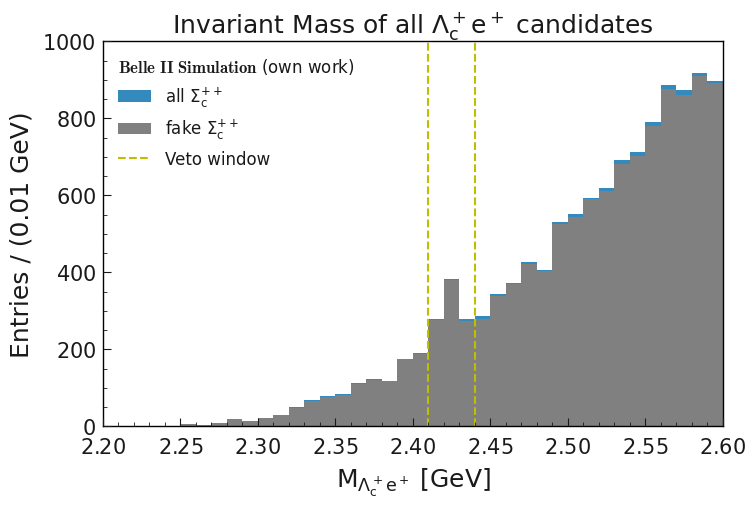

In [164]:
'''
plt.figure(figsize=(8,5))
plt.hist(df_ppE['M'], bins=50, range=(2.1, 2.6), label=r'all $\Lambda_c^{+} e^+$')
plt.hist(df_ppE_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Lambda_c^{+} e^+$')
#plt.hist(df_ppE_sig['M'], bins=50, range=(2.1, 2.6), color='red', alpha=0.7, label=r'true $\Lambda_c^{+} e^+$')
plt.vlines(x=[2.44, 2.47], ymin=0, ymax=1200, colors=['y', 'y'], linestyles=['--', '--'], label='Veto window')
plt.xlim(2.2,2.6)
plt.ylim(0,1000)
plt.xlabel(r'$M_{\Lambda_c^+ e^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
plt.title(r'Invariant Mass of $\Lambda_c^+ e^+$ candidates')
plt.legend()
fig.savefig(f"graphs/Lambda_c+e+_veto.png", bbox_inches="tight")
plt.show()
'''

fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_ppE['M'], bins=50, range=(2.1, 2.6), label=r'all $\Sigma_c^{++}$')
ax.hist(df_ppE_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
#ax.hist(df_ppE_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=[2.41, 2.44], ymin=0, ymax=1200, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 1000)

plt.xlabel(r'$M_{\Lambda_c^+ e^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Lambda_c^+ e^+$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12})
leg._legend_box.align = "left"
fig.savefig(f"graphs/Lambda_c+e+_veto.png", bbox_inches="tight", dpi=300)
plt.show()

In [165]:
df_ppMu=df_pp[(df_pp['S_decayMode']==2)]
#df_ppMu=df_ppmu[(df_ppmu['hasEB']>0) & (df_ppmu['hasMuB']==0)]
df_ppMu_sig=df_ppMu[df_ppMu['isSignal']==1]
df_ppMu_bkg=df_ppMu[df_ppMu['isSignal']==0]

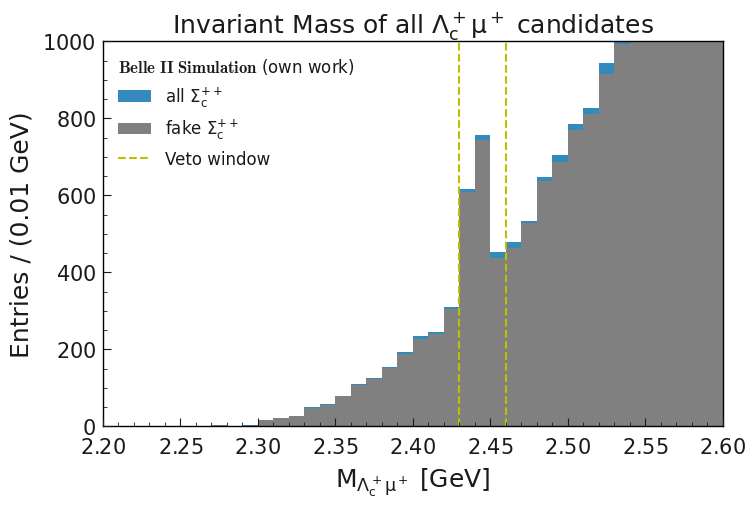

In [166]:
'''
plt.figure(figsize=(8,5))
plt.hist(df_ppMu['M'], bins=50, range=(2.1, 2.6), label='all $\Lambda_c^+ \mu^+$')
plt.hist(df_ppMu_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label='fake $\Lambda_c^+ \mu^+$')
#plt.hist(df_ppMu_sig['M'], bins=50, range=(2.1, 2.6), color='red', label='true $\Lambda_c^+ \mu^+$')
plt.vlines(x=[2.44, 2.47], ymin=0, ymax=1600, colors=['y', 'y'], linestyles=['--', '--'], label='Veto window')
plt.xlim(2.2,2.6)
plt.ylim(0,1500)
plt.xlabel(r'$M_{\Lambda_c^+ \mu^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
plt.title(r'Invariant Mass of $\Lambda_c^+ \mu^+$ candidates')
plt.legend()
fig.savefig(f"graphs/Lambda_c+mu+_veto.png", bbox_inches="tight")
plt.show()
'''


fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_ppMu['M'], bins=50, range=(2.1, 2.6), label=r'all $\Sigma_c^{++}$')
ax.hist(df_ppMu_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{++}$')
#ax.hist(df_ppMu_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{++}$')

ax.vlines(x=[2.43, 2.46], ymin=0, ymax=1600, colors='y', linestyles='--', label='Veto window')

ax.set_xlim(2.2, 2.6)
ax.set_ylim(0, 1000)

plt.xlabel(r'$M_{\Lambda_c^+ \mu^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Lambda_c^+ \mu^+$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12})
leg._legend_box.align = "left"
fig.savefig(f"graphs/Lambda_c+mu+_veto.png", bbox_inches="tight", dpi=300)
plt.show()

In [167]:
df_pp[df_pp['__event__']==12].head(20)

,__event__,M,dM,isSignal,p,cosTheta,phi,chiProb,mcPDG,mcErrors,nMCDaughters,nSigma_cpp,nSigma_cppmu,nSigma_cppe,dM_mu,muPID,piPID,ePID,lepPDG,S_decayMode
0,12,2.482006,0.028036,0.0,1.759223,0.239169,-2.554051,-1.0,300553.0,304.0,2.0,2,0,0,0.224536,4.191954e-06,0.999996,2.647815e-09,-211.0,3.0
1,12,2.482006,0.028036,0.0,1.759223,0.239169,-2.554051,-1.0,300553.0,304.0,2.0,2,0,0,0.167426,1.103176e-02,0.988968,2.124095e-11,-211.0,3.0
6910,12,2.486114,0.032144,0.0,1.103529,0.718672,-2.072317,-1.0,300553.0,432.0,2.0,2,0,0,0.251142,3.136133e-01,0.576323,1.100636e-01,-211.0,3.0
6911,12,2.399129,-0.054841,0.0,0.773929,0.265014,-2.904958,-1.0,300553.0,432.0,2.0,2,0,0,0.240739,3.136133e-01,0.576323,1.100636e-01,-211.0,3.0
9408,12,2.472294,0.018324,0.0,0.946734,0.959559,-1.633586,-1.0,300553.0,304.0,2.0,1,0,0,0.203318,2.276092e-01,0.742791,2.960004e-02,211.0,3.0
11948,12,2.567504,0.113534,0.0,1.031276,-0.074553,0.105310,-1.0,300553.0,304.0,2.0,1,0,0,0.278687,7.953386e-02,0.911464,9.002338e-03,-211.0,3.0
14278,12,2.547232,0.093262,0.0,0.971011,0.985021,2.238556,-1.0,300553.0,304.0,2.0,8,1,0,0.276148,1.185470e-01,0.666188,2.152649e-01,-211.0,3.0
14279,12,2.453912,-0.000058,0.0,0.759105,0.936437,-2.850164,-1.0,-4222.0,256.0,2.0,8,1,0,0.262823,1.185470e-01,0.666188,2.152649e-01,-211.0,3.0
14280,12,2.503881,0.049911,0.0,0.840735,0.728881,-3.062086,-1.0,300553.0,304.0,2.0,8,1,0,0.312791,4.933029e-11,1.000000,2.642768e-26,-211.0,3.0
14281,12,2.547232,0.093262,0.0,0.971011,0.985021,2.238556,-1.0,300553.0,304.0,2.0,8,1,0,0.263239,3.794548e-02,0.962055,3.849828e-10,-211.0,3.0


In [168]:
print(df_pp['isSignal'].mean())

0.1643508117856777


In [169]:
in_window = (df_pp.M > 2.44) & (df_pp.M < 2.47)
events_to_veto = df_pp.loc[in_window, '__event__']
df_clean = df_pp[~df_pp['__event__'].isin(events_to_veto)]

In [170]:
print("Events vorher:", df_pp['__event__'].nunique())
print("Events nach veto:", df_clean['__event__'].nunique())

Events vorher: 1000
Events nach veto: 0


In [171]:
df_clean.head(20)

,__event__,M,dM,isSignal,p,cosTheta,phi,chiProb,mcPDG,mcErrors,nMCDaughters,nSigma_cpp,nSigma_cppmu,nSigma_cppe,dM_mu,muPID,piPID,ePID,lepPDG,S_decayMode


### Sigma_c+

In [172]:
#with uproot.open("veto/Sigma_c+/Sigma_c+_Veto.root:Sigma_cp_veto") as file:
with uproot.open("/data/dust/user/timmue/project/veto/Sigma_c+/processed2/veto_Sigma_c+_5_output.root:Sigma_cp_veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_want if v in available_branches]
    df_p = file.arrays(vars_to_read, library="pd")

    for var in vars_want:
        if var not in df_p.columns:
            df_p[var] = np.nan
'''
file_pp = "Veto/Sigma_c++/sigmac_test.root"
tree_pp = uproot.open(file_pp)["hadronic"]  # BASF2 schreibt meistens 'ntuple' als Tree
df_pp = tree_pp.arrays(library="pd")    # pandas DataFrame
'''
#print(df_p[df_p['nSigma_cppmu']!=0].head(20))
print(df_p.head(20))

    __event__         M        dM  isSignal         p  cosTheta       phi  \
0           1  2.463133  0.010233       0.0  2.298159  0.848840  1.093916   
1           1  2.453787  0.000887       0.0  2.279949  0.848623  1.077938   
2           1  2.517223  0.064323       0.0  2.310666  0.860213  1.104635   
3           1  2.446277 -0.006623       NaN  2.275248  0.844518  1.025628   
4           1  2.481859  0.028959       0.0  2.253077  0.852529  1.058565   
5           1  2.485361  0.032461       NaN  2.415461  0.823719  1.008220   
6           1  2.470483  0.017583       NaN  2.248451  0.825997  1.017213   
7           1  2.465678  0.012778       0.0  2.305150  0.836464  1.097495   
8           1  2.450152 -0.002748       NaN  2.175951  0.852078  1.054843   
9           1  2.444168 -0.008732       0.0  2.239614  0.834879  1.107398   
10          1  2.492979  0.040079       NaN  2.314635  0.830478  1.032941   
11          1  2.565917  0.113017       0.0  2.116105  0.851979  1.175913   

In [173]:
df_p.sort_values("nSigma_cp", ascending=False).head(10)

,__event__,M,dM,isSignal,p,cosTheta,phi,chiProb,mcPDG,mcErrors,nMCDaughters,nSigma_cp,nSigma_cSp,nSigma_cpp,nSigma_cppmu,dM_mu,muPID,piPID,event,run,experiment,InvM,useCMSFrame(p),mcMother(PDG),"mcDaughter(0,PDG)","mcDaughter(1,PDG)",nSigma_cppe,extraInfo(decayModeID),ePID,lepPDG,S_decayMode,B_mu_muonID,B_mu_electronID
25787,789,2.538125,0.085225,0.0,1.646220,0.616262,-1.191992,0.047911,300553.0,304.0,2.0,933,933,3,0,0.272868,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25788,789,2.518064,0.065164,0.0,1.719847,0.637640,-1.127109,0.190678,300553.0,304.0,2.0,933,933,3,0,0.262691,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25789,789,2.564402,0.111502,0.0,1.876194,0.631027,-0.906691,0.157026,300553.0,304.0,2.0,933,933,3,0,0.245299,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25790,789,2.526274,0.073374,0.0,1.966663,0.643197,-0.857697,0.367208,300553.0,304.0,2.0,933,933,3,0,0.237376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25743,789,2.483951,0.031051,NaN,1.483640,0.647672,-1.189073,0.047911,NaN,512.0,NaN,933,933,3,0,0.218694,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25728,789,2.456484,0.003584,NaN,1.422620,0.577543,-1.117726,0.190678,NaN,512.0,NaN,933,933,3,0,0.201112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25729,789,2.507669,0.054769,NaN,1.585411,0.573258,-0.871007,0.157026,NaN,512.0,NaN,933,933,3,0,0.188566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25730,789,2.477342,0.024442,NaN,1.675746,0.590699,-0.817758,0.367208,NaN,512.0,NaN,933,933,3,0,0.188444,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25779,789,2.516426,0.063526,0.0,1.534394,0.655004,-1.234929,0.047911,300553.0,304.0,2.0,933,933,3,0,0.251168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25780,789,2.498872,0.045972,0.0,1.607808,0.676182,-1.161496,0.190678,300553.0,304.0,2.0,933,933,3,0,0.243500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [174]:
len(df_p)

31821

In [175]:
df_p['isSignal'].value_counts()

isSignal
0.0    15405
1.0      167
Name: count, dtype: int64

In [176]:
df_p_sig=df_p[df_p['isSignal']==1]
df_p_bkg=df_p[df_p['isSignal']==0]

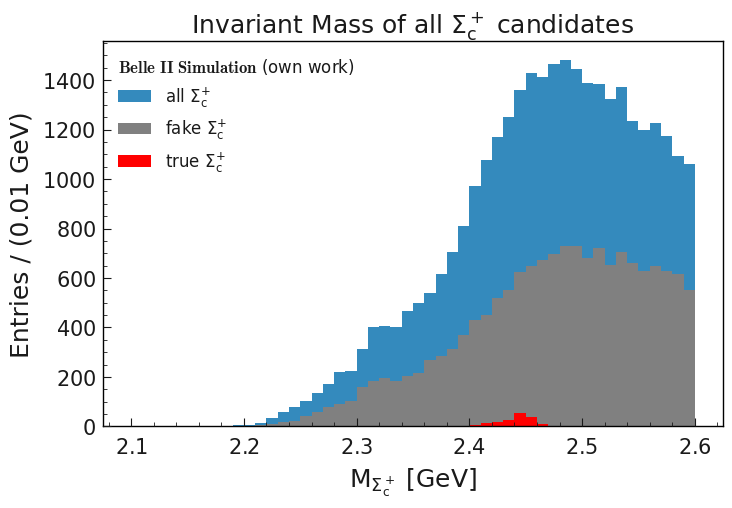

In [177]:
'''
plt.figure(figsize=(8,5))
plt.hist(df_p['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label='all')
plt.hist(df_p_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label='fake Sigma_c+')
plt.hist(df_p_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label='true Sigma_c+')
plt.xlabel('M [GeV]')
plt.ylabel('Events')
plt.title('Invariant Mass of Sigma_c+ candidates')
plt.legend()
plt.show()
'''

fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_p['M'], bins=50, range=(2.1, 2.6), label=r'all $\Sigma_c^{+}$')
ax.hist(df_p_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{+}$')
ax.hist(df_p_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{+}$')

#ax.vlines(x=[2.44, 2.47], ymin=0, ymax=1600, colors='y', linestyles='--', label='Veto window')

#ax.set_xlim(2.2, 2.6)
#ax.set_ylim(0, 1000)

plt.xlabel(r'$M_{\Sigma_c^+}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Sigma_c^+$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12})
leg._legend_box.align = "left"
fig.savefig(f"graphs/Sigma_c+_veto.png", bbox_inches="tight", dpi=300)
plt.show()

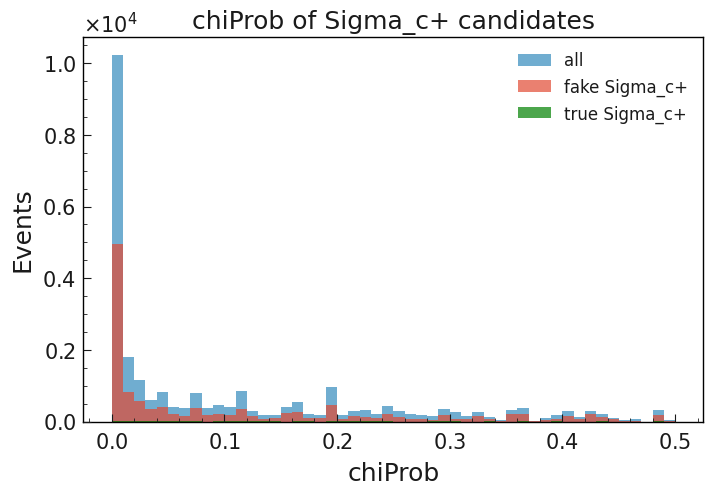

In [178]:
plt.figure(figsize=(8,5))
plt.hist(df_p['chiProb'], bins=50, range=(0, 0.5), alpha=0.7, label='all')
plt.hist(df_p_bkg['chiProb'], bins=50, range=(0, 0.5), alpha=0.7, label='fake Sigma_c+')
plt.hist(df_p_sig['chiProb'], bins=50, range=(0, 0.5), color='green', alpha=0.7, label='true Sigma_c+')
plt.xlabel('chiProb')
plt.ylabel('Events')
plt.title('chiProb of Sigma_c+ candidates')
plt.legend()
plt.show()


### Sigma_c*+

In [179]:
#with uproot.open("veto/Sigma_cS+/Sigma_cS+_Veto.root:Sigma_cstarp_veto") as file:
with uproot.open("/data/dust/user/timmue/project/veto/Sigma_cS+/processed2/veto_Sigma_cS+_5_output.root:Sigma_cstarp_veto") as file:
    available_branches = file.keys()
    vars_to_read = [v for v in vars_want if v in available_branches]
    df_Sp = file.arrays(vars_to_read, library="pd")

    for var in vars_want:
        if var not in df_Sp.columns:
            df_Sp[var] = np.nan
'''
file_pp = "Veto/Sigma_c++/sigmac_test.root"
tree_pp = uproot.open(file_pp)["hadronic"]  # BASF2 schreibt meistens 'ntuple' als Tree
df_pp = tree_pp.arrays(library="pd")    # pandas DataFrame
'''
print(df_Sp.head(20))

    __event__         M        dM  isSignal         p  cosTheta       phi  \
0           2  2.566824  0.049324       0.0  2.264458  0.962992  2.495727   
1           2  2.582564  0.065064       0.0  2.710150  0.970695 -1.662812   
2           2  2.447542 -0.069958       0.0  2.177456  0.886599  2.732376   
3           2  2.577515  0.060015       0.0  2.508410  0.949046 -2.249828   
4           2  2.339641 -0.177859       NaN  2.020579  0.896888  2.635930   
5           2  2.461460 -0.056040       NaN  2.362929  0.957419 -2.116802   
6           2  2.275140 -0.242360       0.0  1.940166  0.905792  2.515511   
7           2  2.397066 -0.120434       0.0  2.283673  0.966635 -1.990963   
8           2  2.339006 -0.178494       0.0  1.926636  0.907527  2.626794   
9           2  2.436760 -0.080740       0.0  2.300321  0.955763 -1.992174   
10          2  2.334504 -0.182996       NaN  1.932448  0.902978  2.466344   
11          2  2.473289 -0.044211       NaN  2.261339  0.970682 -1.988664   

In [180]:
len(df_Sp)

39268

In [181]:
df_Sp['isSignal'].value_counts()

isSignal
0.0    19966
1.0      149
Name: count, dtype: int64

In [182]:
np.unique(df_Sp['mcPDG'])

array([ -4214.,  -4122.,   -521.,    521.,   4122.,   4214., 300553.,
           nan])

In [183]:
df_Sp_sig=df_Sp[df_Sp['isSignal']==1]
df_Sp_bkg=df_Sp[df_Sp['isSignal']==0]

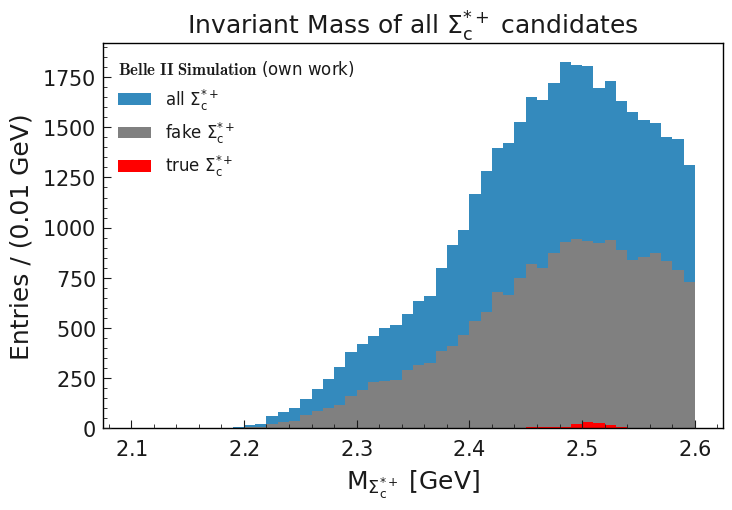

In [184]:
'''
plt.figure(figsize=(8,5))
plt.hist(df_Sp['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label='all')
plt.hist(df_Sp_bkg['M'], bins=50, range=(2.1, 2.6), alpha=0.7, label='fake Sigma_c*+')
plt.hist(df_Sp_sig['M'], bins=50, range=(2.1, 2.6), color='green', alpha=0.7, label='true Sigma_c*+')
plt.xlabel('M [GeV]')
plt.ylabel('Events')
plt.title('Invariant Mass of Sigma_c*+ candidates')
plt.legend()
plt.show()
'''

fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df_Sp['M'], bins=50, range=(2.1, 2.6), label=r'all $\Sigma_c^{*+}$')
ax.hist(df_Sp_bkg['M'], bins=50, range=(2.1, 2.6), color='grey', label=r'fake $\Sigma_c^{*+}$')
ax.hist(df_Sp_sig['M'], bins=50, range=(2.1, 2.6), color='red', label=r'true $\Sigma_c^{*+}$')

#ax.vlines(x=[2.44, 2.47], ymin=0, ymax=1600, colors='y', linestyles='--', label='Veto window')

#ax.set_xlim(2.2, 2.6)
#ax.set_ylim(0, 1000)

plt.xlabel(r'$M_{\Sigma_c^{*+}}$ [GeV]')
plt.ylabel('Entries / (0.01 GeV)')
ax.set_title(r'Invariant Mass of all $\Sigma_c^{*+}$ candidates')

'''
# Belle II label
ax.text(
    0.02, 0.98,
    r"$\bf{Belle\ II\ Simulation}$ (own work)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)
'''

leg = ax.legend(title=r"$\bf{Belle\ II\ Simulation}$ (own work)", title_fontproperties={'size': 12})
leg._legend_box.align = "left"
fig.savefig(f"graphs/Sigma_c*+_veto.png", bbox_inches="tight", dpi=300)
plt.show()

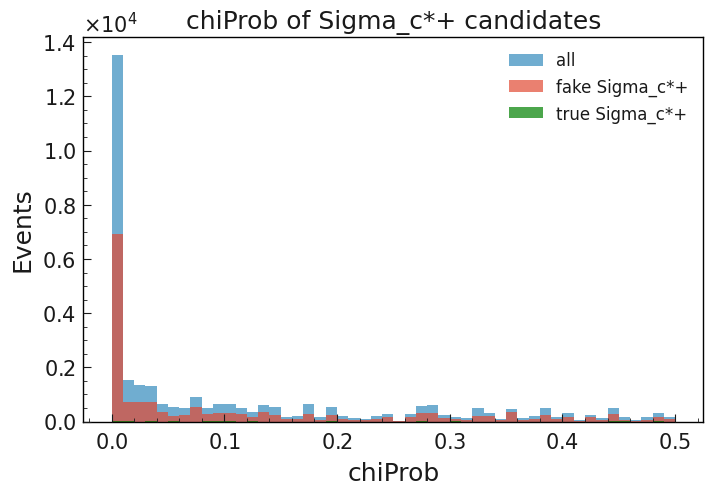

In [185]:
plt.figure(figsize=(8,5))
plt.hist(df_Sp['chiProb'], bins=50, range=(0, 0.5), alpha=0.7, label='all')
plt.hist(df_Sp_bkg['chiProb'], bins=50, range=(0, 0.5), alpha=0.7, label='fake Sigma_c*+')
plt.hist(df_Sp_sig['chiProb'], bins=50, range=(0, 0.5), color='green', alpha=0.7, label='true Sigma_c*+')
plt.xlabel('chiProb')
plt.ylabel('Events')
plt.title('chiProb of Sigma_c*+ candidates')
plt.legend()
plt.show()


# Continuum Suppression

In [186]:
weight_column ="total_weight"

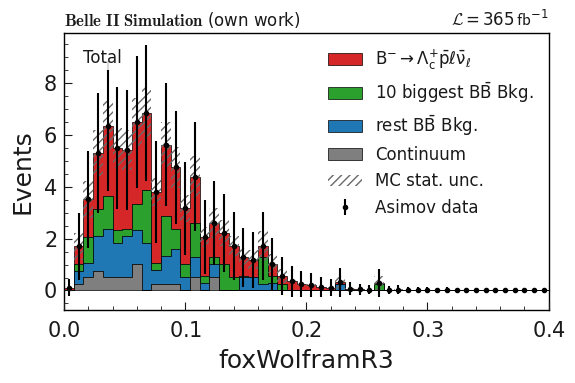

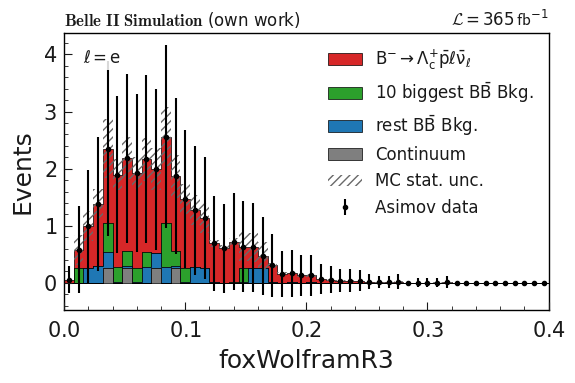

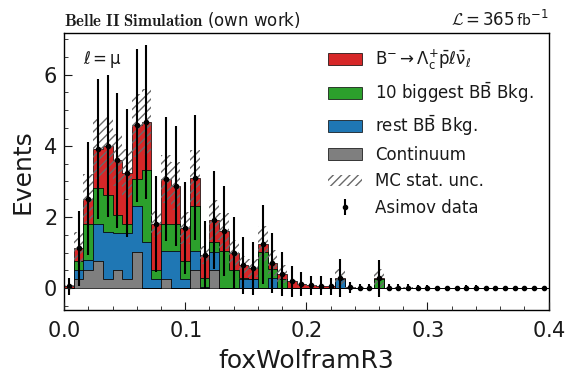

In [187]:
for key, df_current in dfs.items():
    for name in ["foxWolframR3"]:
        #print(name)
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    
        
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
    
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"


        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2top = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ({conditions[key]})")[[name, weight_column]]
        x2rest = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ~({conditions[key]})")[[name, weight_column]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        #d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d["__weight__"])
        # ...
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
        h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2rest, h2top, h1],
            stacked_labels=["Continuum", r"rest $B\bar{B}$ Bkg.", r"10 biggest $B\bar{B}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
            stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel="Events",
            #comparison="pull",
            data_uncertainty_type="symmetrical",
            data_label="Asimov data"
        )


        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)
    
                
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
        
        ax_main.legend() #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    
        '''
        ax_main.axvline(
            x=0.28,
            linestyle="--",
            linewidth=1.5,
            color="yellow",
        )
        '''
        
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        plt.show()
        plt.close()

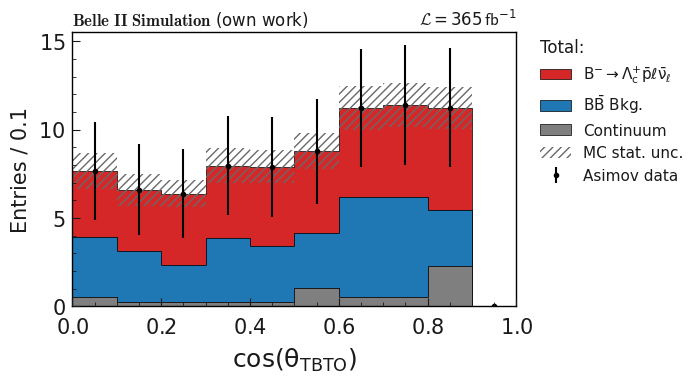

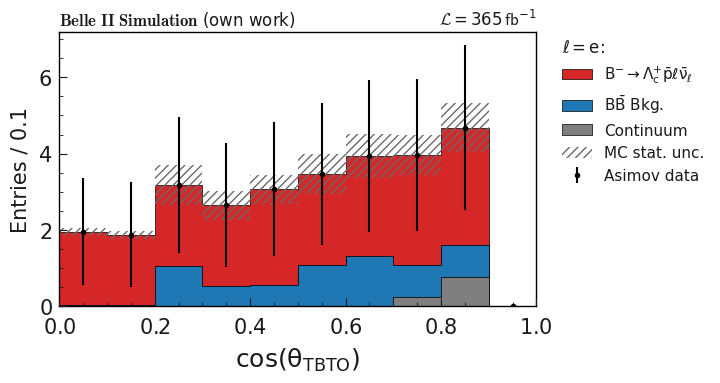

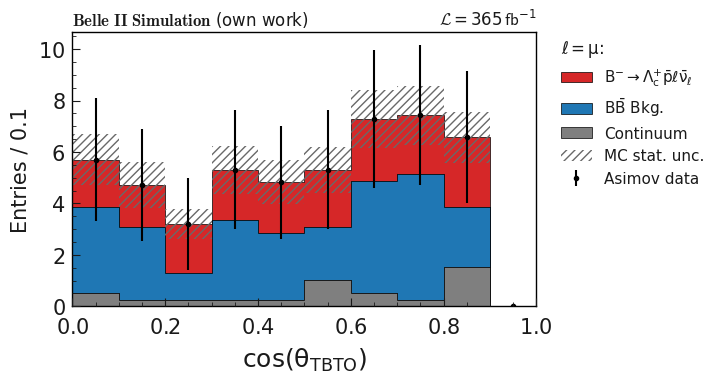

In [188]:
cosTBTO_cut = 0.76
import re

for key, df_current in dfs.items():
    for name in ["Btag_cosTBTO"]:
        #print(name)
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    
        
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
    
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"


        if isinstance(bins, int):
            raw_width = (x_max - x_min) / bins
            # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
            bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
        else:
            # Falls 'bins' eine Liste/ein Array für variable Bin-Breiten ist
            bin_width_str = "Variable"

        # 2. Einheit aus dem x_label extrahieren (sucht nach Text in [...] Klammern)
        # Findet z.B. "GeV/c²" aus "M(pKπ) [GeV/c²]"
        unit_match = re.search(re.compile(r"\[(.*?)\]"), x_label)
        unit_str = unit_match.group(1) if unit_match else ""

        # 3. Label textuell zusammenbauen
        if bin_width_str == "Variable":
            dynamic_ylabel = "Entries / Variable Bin"
        elif unit_str:
            # Wenn eine Einheit existiert, z.B.: Entries / (0.02 GeV/c²)
            dynamic_ylabel = f"Entries / ({bin_width_str} {unit_str})"
        else:
            # Wenn die Variable ein reiner Counter ohne Einheit ist
            dynamic_ylabel = f"Entries / {bin_width_str}"
        
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2top = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ({conditions[key]})")[[name, weight_column]]
        #x2rest = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ~({conditions[key]})")[[name, weight_column]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        #d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d["__weight__"])
        # ...
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
        #h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
        #h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2, h1], #h2rest, h2top
            stacked_labels=["Continuum", r"$B\bar{B}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"], #, r"10 biggest $B\bar{B}$ Bkg."
            stacked_colors=["tab:grey", "tab:blue", "tab:red"], #, "tab:green"
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel=dynamic_ylabel,
            #comparison="pull",
            data_uncertainty_type="symmetrical",
            data_label="Asimov data"
        )

        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)
    
                
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
        '''
        ax_main.axvline(
            x=cosTBTO_cut,
            linestyle="--",
            linewidth=1.5,
            color="orange",
            label="CS cut",
        )
        '''
        
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=11) #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        leg._legend_box.align = "left"
        ax_main.yaxis.label.set_size(15)

        orig_width, orig_height = fig.get_size_inches()
        fig.set_size_inches(orig_width + 1.5, orig_height)
        
        
        fig.savefig(f"graphs/{key}/CS_cosTBTO_{key}.png", bbox_inches="tight", dpi=300)#.svg
        plt.tight_layout()
        plt.show()
        plt.close()

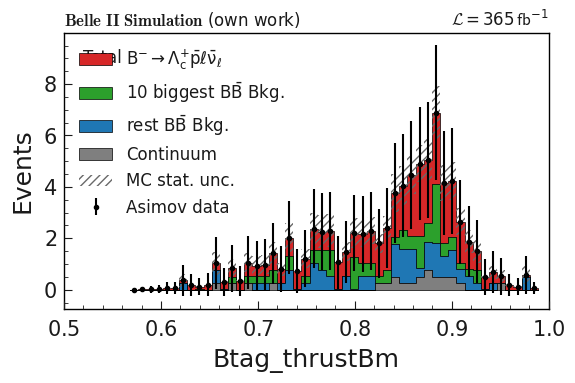

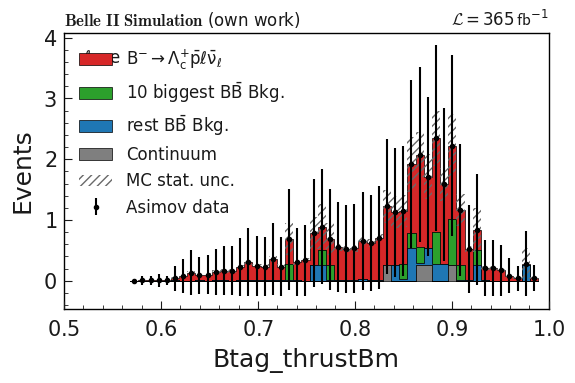

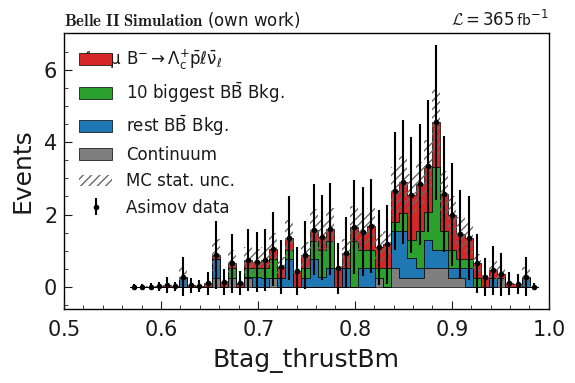

In [189]:
for key, df_current in dfs.items():
    for name in ["Btag_thrustBm"]:
        #print(name)
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = 50 #variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    
        
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
    
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2top = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ({conditions[key]})")[[name, weight_column]]
        x2rest = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ~({conditions[key]})")[[name, weight_column]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        #d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d["__weight__"])
        # ...
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
        h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2rest, h2top, h1],
            stacked_labels=["Continuum", r"rest $B\bar{B}$ Bkg.", r"10 biggest $B\bar{B}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
            stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel="Events",
            #comparison="pull",
            data_uncertainty_type="symmetrical",
            data_label="Asimov data"
        )


        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)
    
                
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
        
        ax_main.legend() #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    
        '''
        ax_main.axvline(
            x=0.28,
            linestyle="--",
            linewidth=1.5,
            color="yellow",
        )
        '''
        
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        plt.show()
        plt.close()

In [190]:
dfs["total"]['B_isSignalAcceptMissing'] = dfs["total"]['B_isSignalAcceptMissing'].fillna(False)
dfs["total"]['isSignalAcceptMissingNeutrino'] = dfs["total"]['isSignalAcceptMissingNeutrino'].fillna(False)

In [191]:
CS_variables = [
    'foxWolframR1',
    'foxWolframR2',
    'foxWolframR3',
    'foxWolframR4',
    'harmonicMomentThrust0',
    'harmonicMomentThrust1',
    'harmonicMomentThrust2',
    'harmonicMomentThrust3',
    'harmonicMomentThrust4',
    'cleoConeThrust0',
    'cleoConeThrust1',
    'cleoConeThrust2',
    'cleoConeThrust3',
    'cleoConeThrust4',
    'cleoConeThrust5',
    'cleoConeThrust6',
    'cleoConeThrust7',
    'cleoConeThrust8',
    'sphericity',
    'aplanarity',
    'thrust',
    'thrustAxisCosTheta',
]

target = 'isContinuumEvent'


In [192]:
dfs["total"][target].value_counts()

isContinuumEvent
False    7340
True       23
Name: count, dtype: int64

### BDT

In [193]:
create_variable_registry(["CS_Score"])

In [194]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

In [195]:
RETRAIN_MODEL = True

In [196]:
X = dfs["total"]

X_train, X_test, y_train, y_test = train_test_split(X[CS_variables], X[target], test_size=.2)

if RETRAIN_MODEL:
    # create model instance
    bst = XGBClassifier()
    # fit model
    bst.fit(X_train, y_train)

    bst.save_model('CS_BDT.json')
else:
    bst.load_model('CS_BDT.json')


In [197]:
bst

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [198]:
# make predictions
dfs["total"]["CS_Score"] = -999
datas["total"]["CS_Score"] = -999
dfs["total"]["CS_Score"] = bst.predict_proba(dfs["total"][CS_variables])
datas["total"]["CS_Score"] = bst.predict_proba(datas["total"][CS_variables])

In [199]:
CS_cut = 0.65

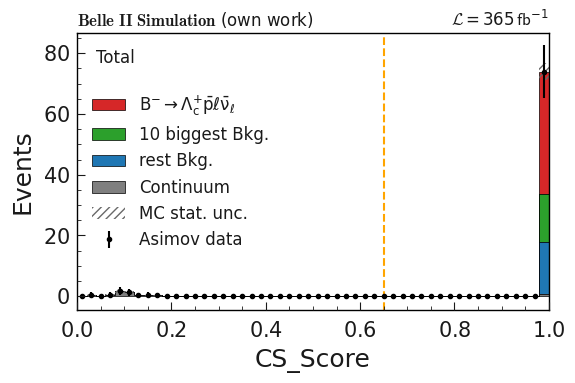

In [200]:
for name in ["CS_Score"] + CS_variables:

    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    range_query = f"{x_min} <= {name} < {x_max}"
    #range_query = f"{x_range[0]} <= {name} <= {x_range[1]}"
    
    d = datas["total"].query(range_query)[[name, weight_column]]
    x1 = dfs["total"].query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2_top10 = dfs["total"].query(range_query).query(f"({conditions['total']}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x2_rest = dfs["total"].query(range_query).query(f"~({conditions['total']}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x3 = dfs["total"].query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]

    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2_top10 = make_hist(x2_top10[name], bins=bins, range=(x_min, x_max), weights=x2_top10[weight_column])
    h2_rest = make_hist(x2_rest[name], bins=bins, range=(x_min, x_max), weights=x2_rest[weight_column])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2_rest, h2_top10, h1],
        stacked_labels=["Continuum", "rest Bkg.", "10 biggest Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )

    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)

    if name == "CS_Score":
        ax_main.axvline(
        x=CS_cut,
        linestyle="--",
        linewidth=1.5,
        color="orange",
        )

    if name == "foxWolframR2":
        ax_main.axvline(
        x=0.24,
        linestyle="--",
        linewidth=1.5,
        color="yellow",
        )

    # remove Data label
    #handles, labels = ax_main.get_legend_handles_labels()
    #handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
    ax_main.legend()
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, "Total", transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))

    if name == "CS_Score":
        fig.savefig("graphs/CS_Score.svg", bbox_inches="tight", dpi=300)
        plt.tight_layout()
        plt.show()
    plt.close()

In [201]:
def FoM(df, variable_name, x):
    S = np.array([df.query(f"{variable_name} > {x_}").query("B_isSignalAcceptMissing == 1")[weight_column].sum() for x_ in x])
    B = np.array([df.query(f"{variable_name} > {x_}").query("B_isSignalAcceptMissing != 1")[weight_column].sum() for x_ in x])
    #print(S, B)
    return S / (S + B) ** 0.5

In [202]:
FoM(dfs["total"], "CS_Score", [0.5, 0.6])

array([5.03603272, 5.03603272])

/tmp/ipykernel_1463035/448183551.py:5: RuntimeWarning: invalid value encountered in divide
  return S / (S + B) ** 0.5


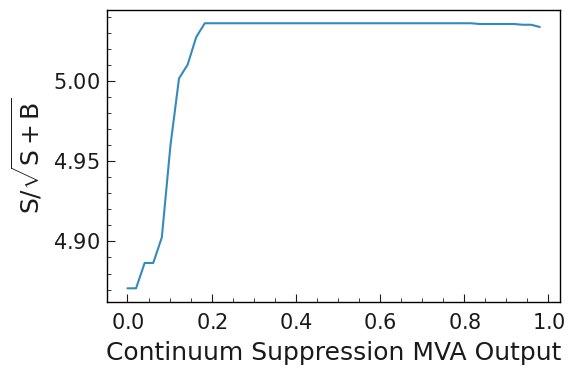

In [203]:
fig, ax = plt.subplots()
plot_function(lambda x: FoM(dfs["total"], "CS_Score", x), range=[0, 1], ax=ax, npoints=50)

ax.set_xlabel("Continuum Suppression MVA Output")
ax.set_ylabel(r"$S / \sqrt{S + B}$")

plt.tight_layout()
plt.show()
plt.close()

### Cut

# Systematics

## Combined

### FEI systematics

In [204]:
import sys
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

In [205]:
from os import path
from yaml import safe_load

In [206]:
with open(path.join("project_setup.yaml"), "r") as file:
    # Read the yaml file into a dict
    cfg = safe_load(file)

In [207]:
save_nominal_templates(df=df, settings=cfg)

INFO : save_nominal_templates: 293 :  Recreate file with uproot: ./pyhf/test_output.root
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : save_nominal_templates: 301 :  ##################################################
INFO : save_nominal_templates: 302 :  ########## Reco channel: channel1 ##########
INFO : save_nominal_templates: 305 :  ##################################################
INFO : sav

In [208]:
df["Btag_dmID"]=df["Btag_extraInfo_decayModeID"]

In [209]:
df["Btag_PDG"]=df["B_mcPDG"]
df.loc[~df["Btag_PDG"].isin([521, -521]), "Btag_PDG"] = 521

In [210]:
add_weights_to_dataframe(df, correction_source="../FEI_cal_factors_Bp_sigProb_0_001.csv", prefix="Btag", weightname="weight", overwrite=True)
df=df.copy()

INFO : add_weights_to_dataframe: 142 :  Btag_weight does not exist. Adding it to dataframe


In [211]:
df[["Btag_weight"]].describe()

,Btag_weight
count,7363.000000
mean,1.111639
std,0.231286
min,0.281916
25%,1.000000
50%,1.087855
75%,1.253812
max,1.523771


In [212]:
df["total_weight"] = df["Btag_weight"]*df["__weight__"]
df=df.copy()

In [213]:
from sysvar import eigendecompose

egd = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "../FEI_cal_factors_Bp_sigProb_0_001.csv",
    cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "FEI",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 179 :  Loading covariance matrix from file: ../FEI_cal_covariance_Bp_sigProb_0_001.tsv
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 : 

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

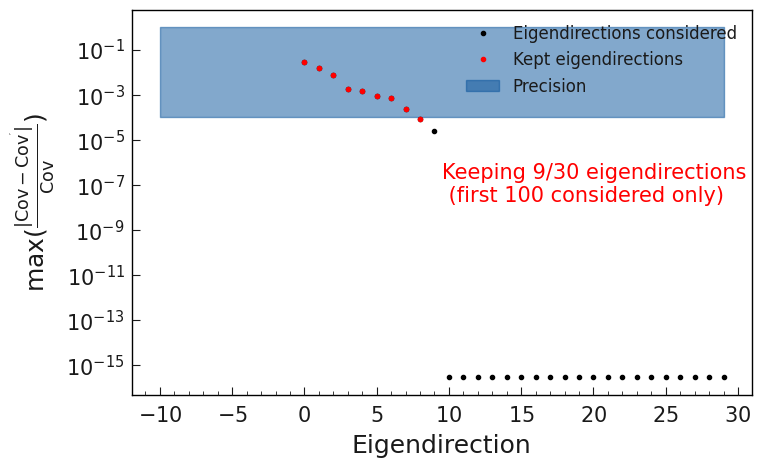

In [214]:
egd.plot_cov_diff()

/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


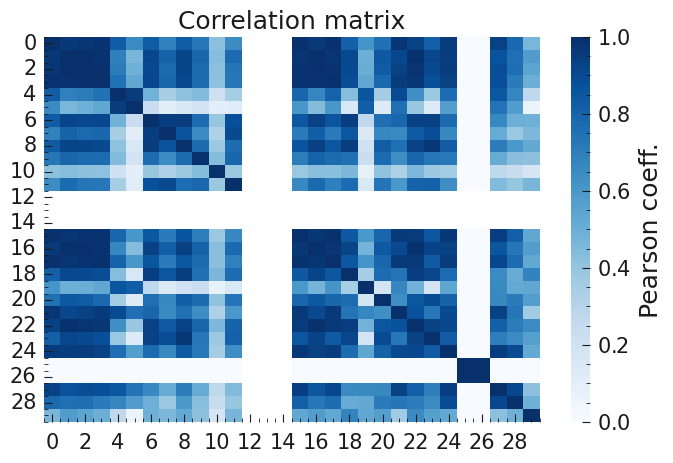

In [215]:
from sysvar import plot_analysis_corr_matrix
fig, ax= plot_analysis_corr_matrix(egd)

In [216]:
## 8.20/0.005156

df_e_sig = df[(df["template"]=="signMC") & (df["channel"]=="B_to_Lambda_c_plnu_e")]

np.histogram(df_e_sig["m2RecoilSignalSide"], bins=[-0.5, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  1.1], weights = df_e_sig["total_weight"])

(array([ 2.06566564,  7.45990505, 10.46329072,  1.84630778,  0.75934325,
         0.39121954,  0.20782735,  0.15149513,  0.08445115,  0.23309941]),
 array([-0.5, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  1.1]))

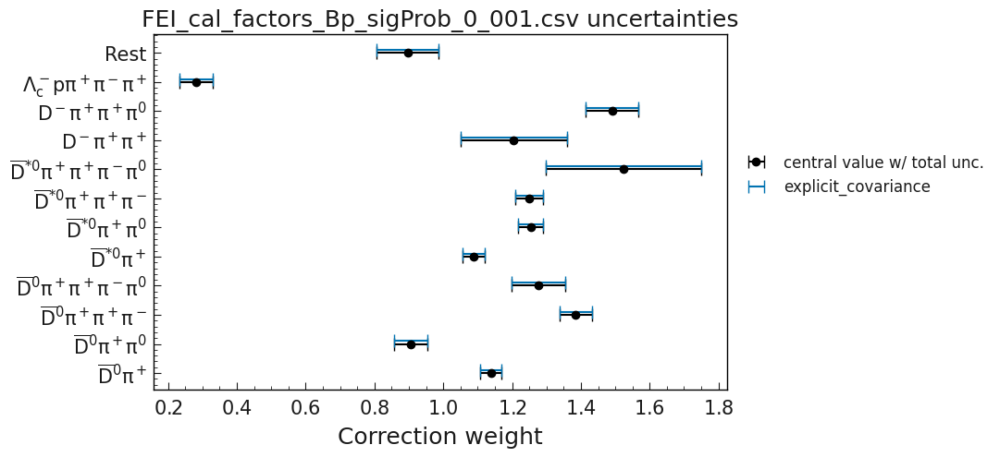

In [217]:
from sysvar import plot_correction_errors
fig, ax= plot_correction_errors(egd)

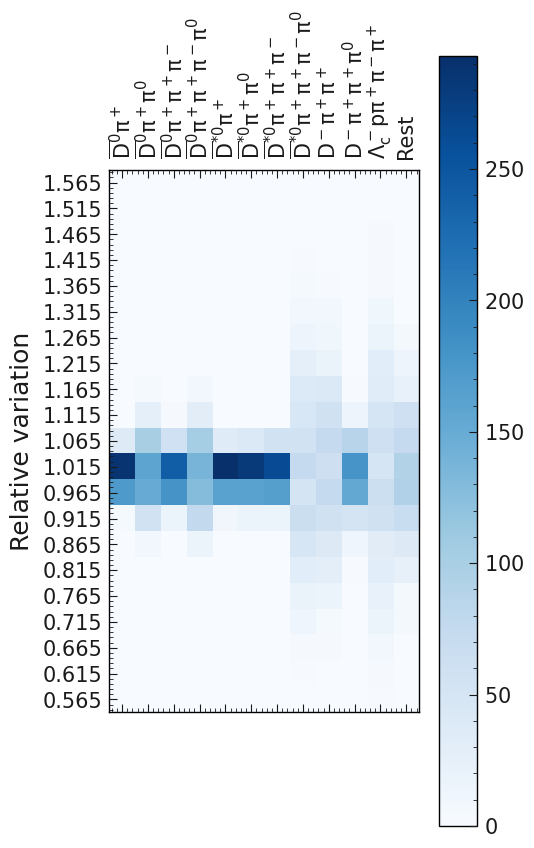

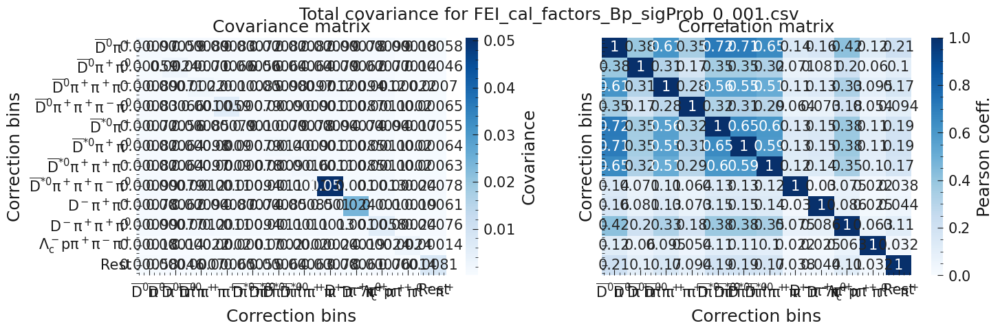

In [218]:
from sysvar import plot_correction_variations_in_grid, plot_correction_cov_and_corr
fig1, ax1= plot_correction_variations_in_grid(egd)
fig2, ax2= plot_correction_cov_and_corr(egd)

In [219]:
uproot.open("./pyhf/test_output.root").keys()

['channel1;1',
 'channel1/signMC;1',
 'channel1/signMC/Nominal;1',
 'channel1/background;1',
 'channel1/background/Nominal;1',
 'channel1/continuum;1',
 'channel1/continuum/Nominal;1',
 'channel1/Data;1',
 'channel1/Data/Nominal;1',
 'channel2;1',
 'channel2/signMC;1',
 'channel2/signMC/Nominal;1',
 'channel2/background;1',
 'channel2/background/Nominal;1',
 'channel2/continuum;1',
 'channel2/continuum/Nominal;1',
 'channel2/Data;1',
 'channel2/Data/Nominal;1']

/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:725: RuntimeWarning: invalid value encountered in divide
  h_up[0].flatten() / self.instance.nom_hist[0].flatten(),
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:733: RuntimeWarning: invalid value encountered in divide
  h_down[0].flatten() / self.instance.nom_hist[0].flatten(),
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:757: RuntimeWarning: invalid value encountered in divide
  (h_up[0].flatten() - self.instance.nom_hist[0].flatten())
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:545: RuntimeWarning: invalid value encountered in divide
  relative_variations = np.nan_to_num(variations.T / nominals[0], nan=1)


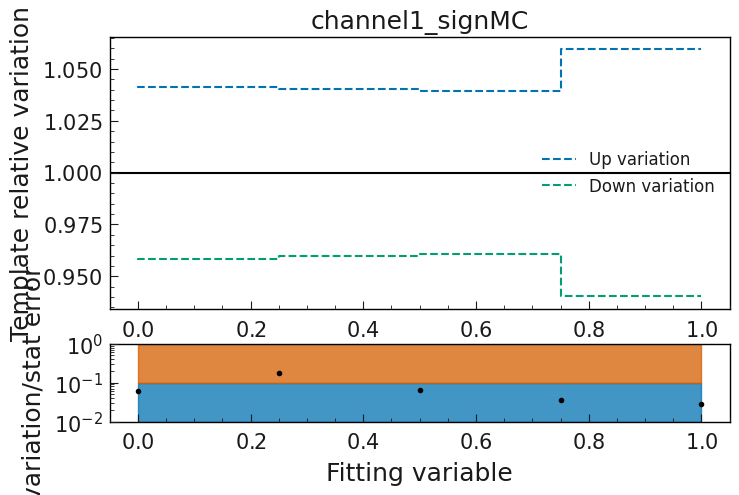

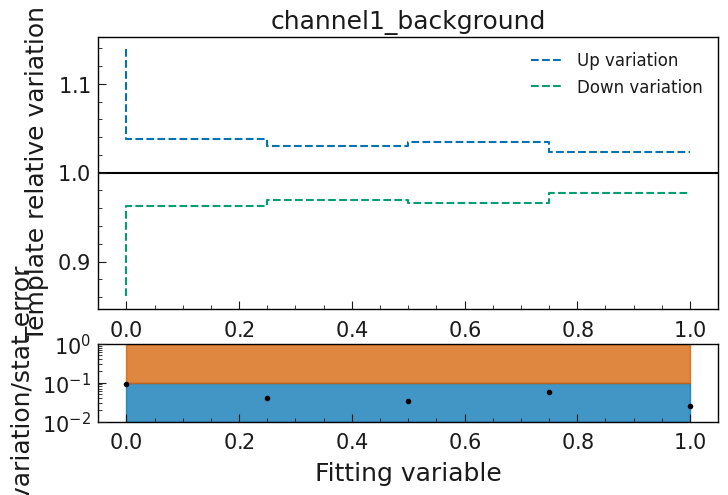

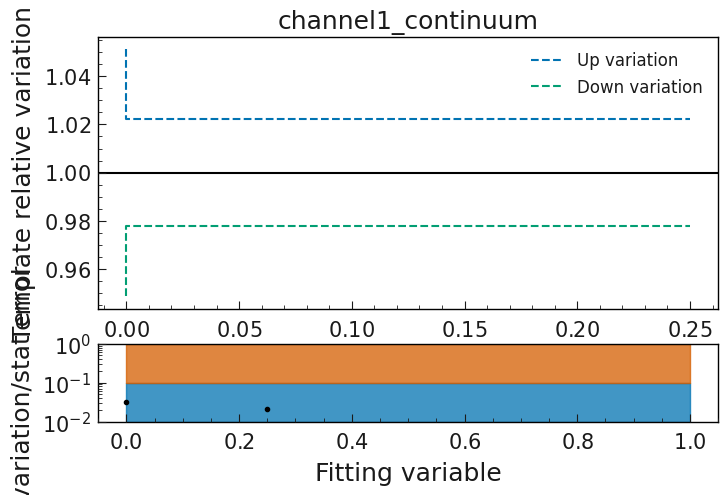

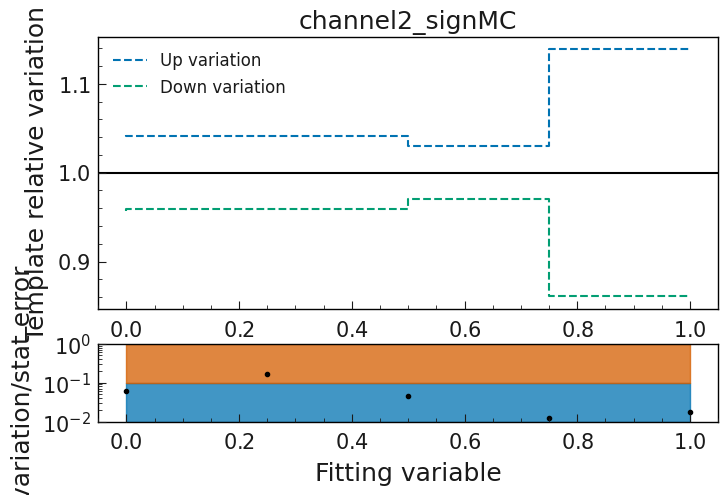

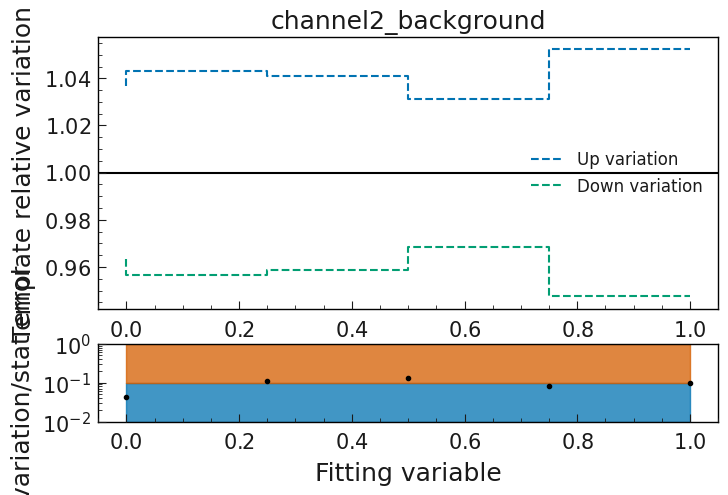

...

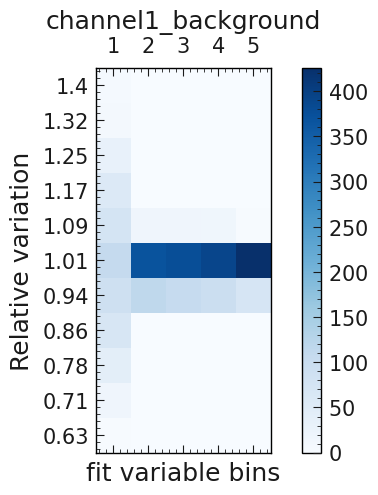

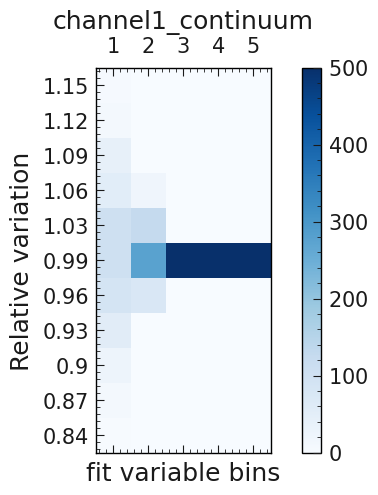

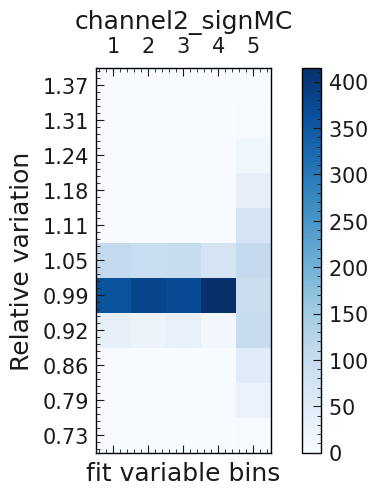

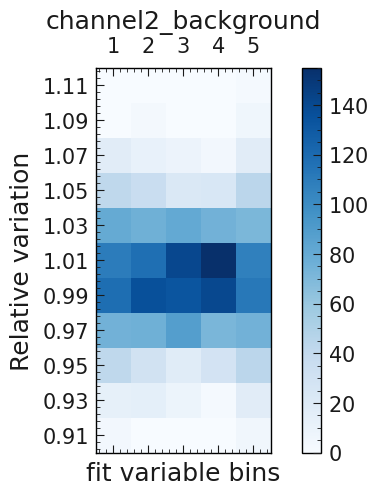

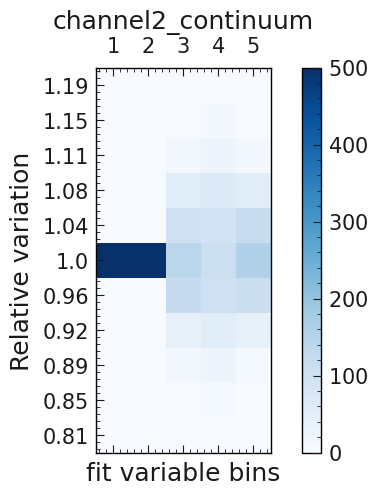

In [220]:
from sysvar import plot_templates_relative_variations_in_grid, plot_up_and_down_variations
figures1= plot_up_and_down_variations(egd)
figures2= plot_templates_relative_variations_in_grid(egd)

In [221]:
egd.templates["channel1_signMC"].df.head(20)

,Btag_weight,template,Btag_PDG,m2RecoilSignalSide,total_weight,channel,Btag_dmID,Btag_weight_up,Btag_weight_down,Btag_weight_var_0,Btag_weight_var_1,Btag_weight_var_2,Btag_weight_var_3,Btag_weight_var_4,Btag_weight_var_5,Btag_weight_var_6,Btag_weight_var_7,Btag_weight_var_8,Btag_weight_var_9,Btag_weight_var_10,Btag_weight_var_11,Btag_weight_var_12,Btag_weight_var_13,Btag_weight_var_14,Btag_weight_var_15,Btag_weight_var_16,Btag_weight_var_17,Btag_weight_var_18,Btag_weight_var_19,Btag_weight_var_20,Btag_weight_var_21,Btag_weight_var_22,Btag_weight_var_23,Btag_weight_var_24,Btag_weight_var_25,Btag_weight_var_26,Btag_weight_var_27,Btag_weight_var_28,Btag_weight_var_29,Btag_weight_var_30,Btag_weight_var_31,Btag_weight_var_32,Btag_weight_var_33,Btag_weight_var_34,Btag_weight_var_35,Btag_weight_var_36,Btag_weight_var_37,Btag_weight_var_38,Btag_weight_var_39,Btag_weight_var_40,Btag_weight_var_41,Btag_weight_var_42,Btag_weight_var_43,Btag_weight_var_44,Btag_weight_var_45,Btag_weight_var_46,Btag_weight_var_47,Btag_weight_var_48,Btag_weight_var_49,Btag_weight_var_50,Btag_weight_var_51,Btag_weight_var_52,Btag_weight_var_53,Btag_weight_var_54,Btag_weight_var_55,Btag_weight_var_56,Btag_weight_var_57,Btag_weight_var_58,Btag_weight_var_59,Btag_weight_var_60,Btag_weight_var_61,Btag_weight_var_62,Btag_weight_var_63,Btag_weight_var_64,Btag_weight_var_65,Btag_weight_var_66,Btag_weight_var_67,Btag_weight_var_68,Btag_weight_var_69,Btag_weight_var_70,Btag_weight_var_71,Btag_weight_var_72,Btag_weight_var_73,Btag_weight_var_74,Btag_weight_var_75,Btag_weight_var_76,Btag_weight_var_77,Btag_weight_var_78,Btag_weight_var_79,Btag_weight_var_80,Btag_weight_var_81,Btag_weight_var_82,Btag_weight_var_83,Btag_weight_var_84,Btag_weight_var_85,Btag_weight_var_86,Btag_weight_var_87,Btag_weight_var_88,Btag_weight_var_89,Btag_weight_var_90,Btag_weight_var_91,Btag_weight_var_92,Btag_weight_var_93,Btag_weight_var_94,Btag_weight_var_95,Btag_weight_var_96,Btag_weight_var_97,Btag_weight_var_98,Btag_weight_var_99,Btag_weight_var_100,Btag_weight_var_101,Btag_weight_var_102,Btag_weight_var_103,Btag_weight_var_104,Btag_weight_var_105,Btag_weight_var_106,Btag_weight_var_107,Btag_weight_var_108,Btag_weight_var_109,Btag_weight_var_110,Btag_weight_var_111,Btag_weight_var_112,Btag_weight_var_113,Btag_weight_var_114,Btag_weight_var_115,Btag_weight_var_116,Btag_weight_var_117,Btag_weight_var_118,Btag_weight_var_119,Btag_weight_var_120,Btag_weight_var_121,Btag_weight_var_122,Btag_weight_var_123,Btag_weight_var_124,Btag_weight_var_125,Btag_weight_var_126,Btag_weight_var_127,Btag_weight_var_128,Btag_weight_var_129,Btag_weight_var_130,Btag_weight_var_131,Btag_weight_var_132,Btag_weight_var_133,Btag_weight_var_134,Btag_weight_var_135,Btag_weight_var_136,Btag_weight_var_137,Btag_weight_var_138,Btag_weight_var_139,Btag_weight_var_140,Btag_weight_var_141,Btag_weight_var_142,Btag_weight_var_143,Btag_weight_var_144,Btag_weight_var_145,Btag_weight_var_146,Btag_weight_var_147,Btag_weight_var_148,Btag_weight_var_149,Btag_weight_var_150,Btag_weight_var_151,Btag_weight_var_152,Btag_weight_var_153,Btag_weight_var_154,Btag_weight_var_155,Btag_weight_var_156,Btag_weight_var_157,Btag_weight_var_158,Btag_weight_var_159,Btag_weight_var_160,Btag_weight_var_161,Btag_weight_var_162,Btag_weight_var_163,Btag_weight_var_164,Btag_weight_var_165,Btag_weight_var_166,Btag_weight_var_167,Btag_weight_var_168,Btag_weight_var_169,Btag_weight_var_170,Btag_weight_var_171,Btag_weight_var_172,Btag_weight_var_173,Btag_weight_var_174,Btag_weight_var_175,Btag_weight_var_176,Btag_weight_var_177,Btag_weight_var_178,Btag_weight_var_179,Btag_weight_var_180,Btag_weight_var_181,Btag_weight_var_182,Btag_weight_var_183,Btag_weight_var_184,Btag_weight_var_185,Btag_weight_var_186,Btag_weight_var_187,Btag_weight_var_188,Btag_weight_var_189,Btag_weight_var_190,Btag_weight_var_191,Btag_weight_var_192,Btag_weight_var_193,Btag_weight_var_194,Btag_weight_var_195,Btag_weight_var_196,Btag_weight_var_197,Btag_weight_var_198,Btag_weight_var_1

In [222]:
egd.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/FEI_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/FEI_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var3_up
INFO : save_template_variations: 383 :  Saving D

In [223]:
uproot.open("./pyhf/test_output.root")['channel1/background/FEI_var1_up;1'].to_numpy()

(array([0.39634478, 1.12739362, 1.23765474, 2.77732255, 1.13154953]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [224]:
uproot.open("./pyhf/test_output.root")['channel1/signMC/FEI_var1_down;1'].to_numpy()

(array([ 2.1154663 , 18.35456012,  2.66782171,  0.8544701 ,  0.24000405]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [225]:
uproot.open("./pyhf/test_output.root")['channel1/signMC/Nominal'].to_numpy()

(array([ 1.85055 , 16.131102,  2.36301 ,  0.751608,  0.193596]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [226]:
egd.templates["channel1_signMC"].make_hist()

(array([ 2.06566564, 17.92319577,  2.60565103,  0.83499318,  0.23309941]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [227]:
egd.templates["channel1_signMC"].make_hist(499)

(array([ 2.03235048, 17.55687612,  2.55632893,  0.82144417,  0.228961  ]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

### Track systematics

In [228]:
df["B_tracks"]=5

In [229]:
add_weights_to_dataframe(df, correction_source="MC16rd_track_eff.csv", prefix="B", weightname="tracks", overwrite=True)

INFO : add_weights_to_dataframe: 140 :  B_tracks exists and will be overwritten


In [230]:
from sysvar import eigendecompose

egd_track = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "../project/MC16rd_track_eff.csv",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "track_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 :  Adding variations to continuum template
INFO : vary_templates: 212 :  ########## Reco channel: channel2 ##########
IN

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

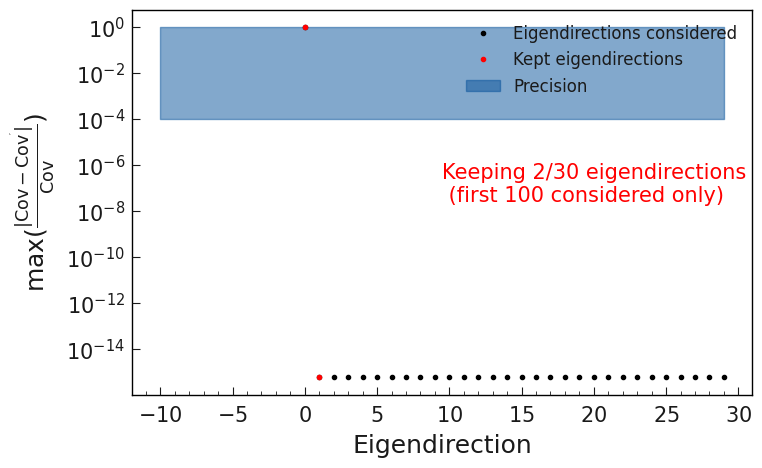

In [231]:
egd_track.plot_cov_diff()

In [232]:
egd_track.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/track_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/track_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/track_eff_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/track_eff_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/track_eff_var1_up
INFO : sav

In [233]:
df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]

In [234]:
df[["total_weight"]].describe()

,total_weight
count,7363.000000
mean,0.012064
std,0.040674
min,0.001605
25%,0.005694
50%,0.006485
75%,0.007269
max,0.389145


### PID systematics

In [235]:
import sys
print(sys.executable)
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

/afs/desy.de/user/t/timmue/b2-plothist-env/bin/python


In [236]:
from IPython.display import HTML 

sys_path = 'systematic_corrections_framework/scripts'

sys.path.insert(1, sys_path)

import efficiency_table as et
import process_tables as pt
import show_db_content as sdb
import show_variables as sv
import id_vs_misid_curve as roc
import weight_table as wm

In [237]:
%pip install sly

Note: you may need to restart the kernel to use updated packages.


In [238]:
import show_db_content as sdb
ntuple_table = sdb.show_db_content(type='html')
HTML(ntuple_table)

INFO : info: 47 :  Successfully opened a DB connection to /data/dust/group/belle2/dataprod/Systematics/production/prod_log_db.csv!


In [239]:
var_table = sv.show_ntuple_variables(particle_type='pi', 
                                     data_query=["MC16rd_p16_chunk4"], 
                                     type='html')
HTML(var_table)

,Global PIDs,PID BDTs,CMS Frame,Detector hits,PID log(Likelihood),Track Isolation,Uncategorized
0,pionID,pidChargedBDTScore_K,cosThetaCMS,nCDCHits,pidLogLikelihoodOf2212FromKLM,minET2ETIsoScore,dz
1,deuteronIDNN,pidChargedBDTScore_e,pxCMS,nSVDHits,pidLogLikelihoodOf211FromCDC,,pt
2,protonID,pidChargedBDTScore_p,pCMS,nPXDHits,pidLogLikelihoodOf321FromSVD,,theta
3,electronID,pidChargedBDTScore_mu,ECMS,,pidLogLikelihoodOf13FromECL,,E
4,electronID_noTOP,pidChargedBDTScore_pi,pzCMS,,pidLogLikelihoodOf13FromTOP,,clusterE1E9
5,kaonID,pidPairChargedBDTScore_mu_pi,thetaCMS,,pidLogLikelihoodOf2212FromCDC,,clusterE
6,pionIDNN,pidPairChargedBDTScore_e_pi,ptCMS,,pidLogLikelihoodOf321FromARICH,,clusterEoP
7,protonIDNN,,pyCMS,,pidLogLikelihoodOf11FromARICH,,isSignal
8,muonID_noSVD,,phiCMS,,pidLogLikelihoodOf11FromTOP,,dr
9,electronID_noSVD_noTOP,,,,pidLogLikelihoodOf13FromARICH,,lastCDCLayer


In [240]:

from common_methods import DF_SCHEMES
for schema in DF_SCHEMES:
    print(schema, DF_SCHEMES[schema])

Dst  type: Weighted
Particles: ['K', 'pi']
Prefixes:  ['DST_D0_K', 'DST_D0_pi']
Constraints:
For K particle: nCDCHits > 20 and p > 0.3
For pi particle: nCDCHits > 20 and p > 0.1
Lambda0  type: Weighted
Particles: ['p', 'pi']
Prefixes:  ['Lambda0_p', 'Lambda0_pi']
Constraints:
For p particle: nCDCHits > 20 and p > 0.5
For pi particle: nCDCHits > 20 and p > 0.1 and p < 0.75
KShort  type: Weighted
Particles: ['pi', 'pi']
Prefixes:  ['KS_pi1', 'KS_pi2']
Constraints:
For pi particle: nCDCHits > 20 and p > 0.1
For pi particle: nCDCHits > 20 and p > 0.1
Jpsiee  type: Weighted
Particles: ['e', 'e']
Prefixes:  ['e0', 'e1']
Constraints:
For e particle: p > 1.5
For e particle: p > 1.5
Tag cuts:
For prefix e1_: e0_{variable} > 0.9
For prefix e0_: e1_{variable} > 0.9
Jpsimumu  type: Weighted
Particles: ['mu', 'mu']
Prefixes:  ['mu0', 'mu1']
Constraints:
For mu particle: p > 1.5
For mu particle: p > 1.5
Tag cuts:
For prefix mu1_: mu0_{variable} > 0.9
For prefix mu0_: mu1_{variable} > 0.9
Radmumu  ty

In [241]:
from sysvar import corrections

In [242]:
eID_corr = corrections.CorrectionPID(systematic="eID_K_fake", MC_production="MC15rd")

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)


In [243]:
eID_corr.build_queries()

['(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <= theta < 1.3438532906163765 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <=

In [244]:
eID_corr.central_values

[1.2061084081330873,
 1.2587823373135034,
 1.2948594668822906,
 1.3398574201318558,
 0.8598448907493135,
 0.9396903673474464,
 0.8950503434220551,
 1.071877279636151,
 0.897169953876985,
 1.1328429845402306,
 0.9259375193071128,
 1.072227789402525,
 1.2324537370502624,
 1.309933578374879,
 2.1408689323689427,
 3.334676543509604,
 1.0804559494013122,
 1.4171563239654803,
 1.1017520873701163,
 1.173474677831335,
 0.8943867842081028,
 1.0450356355056565,
 0.9528071297614014,
 1.0897691814608237,
 0.8074288103940814,
 1.0411741410578512,
 0.9198685628643406,
 0.99374374376018,
 1.1030475320119888,
 0.8920019143563843,
 3.8505202574507713,
 4.001446628365155,
 2.148085142660209,
 2.166653673523171,
 1.088278109787026,
 1.2425249675873913,
 1.071581927436418,
 1.0611379830997856,
 0.906445919153308,
 1.5524687745425343,
 1.0205448856979435,
 1.0505382520942934,
 1.011790559859607,
 1.700660454877294,
 1.3561079243056506,
 1.251657003595103,
 1.5060617659816304,
 3.8112755441679953,
 1.114709

In [245]:
eID_corr.table

,p_min,p_max,cosTheta_min,cosTheta_max,charge_min,charge_max,data_MC_ratio,data_MC_uncertainty_stat_up,data_MC_uncertainty_stat_dn,data_MC_uncertainty_sys_up,data_MC_uncertainty_sys_dn,data_efficiency,data_uncertainty_stat_up,data_uncertainty_stat_dn,data_uncertainty_sys_up,data_uncertainty_sys_dn,MC_efficiency,MC_uncertainty_stat_up,MC_uncertainty_stat_dn,MC_uncertainty_sys_up,MC_uncertainty_sys_dn,threshold,variable,working_point,is_best_available,theta_min,theta_max,charge,mcPDG
0,0.5,0.9,-0.8660,-0.6820,-2,0,1.206108,0.262942,0.262942,0.026090,0.026090,0.004734,0.001140,0.001140,0.000097,0.000097,0.003925,0.000414,0.000414,8.895745e-05,8.895745e-05,0.9,electronID,FixedThresh09,True,2.321290,2.617943,-,11
1,0.5,0.9,-0.8660,-0.6820,0,2,1.258782,0.183764,0.183764,0.014002,0.014002,0.007933,0.001262,0.001262,0.000066,0.000066,0.006302,0.000580,0.000580,1.379659e-04,1.379659e-04,0.9,electronID,FixedThresh09,True,2.321290,2.617943,+,-11
2,0.5,0.9,-0.6820,-0.4226,-2,0,1.294859,0.096071,0.096071,0.023108,0.023108,0.008017,0.000679,0.000679,0.000047,0.000047,0.006192,0.000281,0.000281,8.580556e-06,8.580556e-06,0.9,electronID,FixedThresh09,True,2.007108,2.321290,-,11
3,0.5,0.9,-0.6820,-0.4226,0,2,1.339857,0.095492,0.095492,0.025672,0.025672,0.008431,0.000710,0.000710,0.000087,0.000087,0.006292,0.000283,0.000283,1.554210e-04,1.554210e-04,0.9,electronID,FixedThresh09,True,2.007108,2.321290,+,-11
4,0.5,0.9,-0.4226,-0.1045,-2,0,0.859845,0.059016,0.059016,0.011197,0.011197,0.013967,0.000755,0.000755,0.000232,0.000232,0.016244,0.000385,0.000385,1.718155e-04,1.718155e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,-,11
5,0.5,0.9,-0.4226,-0.1045,0,2,0.939690,0.066818,0.066818,0.002471,0.002471,0.011751,0.000715,0.000715,0.000118,0.000118,0.012505,0.000345,0.000345,5.963684e-04,5.963684e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,+,-11
6,0.5,0.9,-0.1045,0.2250,-2,0,0.895050,0.036522,0.036522,0.005671,0.005671,0.029871,0.000994,0.000994,0.000079,0.000079,0.033373,0.000501,0.000501,4.761595e-04,4.761595e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,-,11
7,0.5,0.9,-0.1045,0.2250,0,2,1.071877,0.041444,0.041444,0.008236,0.008236,0.024329,0.000904,0.000904,0.000116,0.000116,0.022697,0.000416,0.000416,3.625528e-04,3.625528e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,+,-11
8,0.5,0.9,0.2250,0.5000,-2,0,0.897170,0.036895,0.036895,0.006720,0.006720,0.031951,0.001078,0.001078,0.000032,0.000032,0.035613,0.000533,0.000533,4.405714e-04,4.405714e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,-,11
9,0.5,0.9,0.2250,0.5000,0,2,1.132843,0.037339,0.037339,0.004157,0.004157,0.031649,0.001053,0.001053,0.000052,0.000052,0.027937,0.000473,0.000473,6.761617e-04,6.761617e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,+,-11


In [246]:
df["electron_PDG"] = df["B_extraInfo_decayModeID"]
df.loc[df["electron_PDG"].isin([1]) & df["B_mu_charge"].isin([-1]), "electron_PDG"] = 11
df.loc[df["electron_PDG"].isin([1]) & df["B_mu_charge"].isin([1]), "electron_PDG"] = -11
#df[["electron_PDG"]==11] = df[["electron_PDG"]==1]
df["electron_mcPDG"] = df["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([-1]), "electron_mcPDG"] = -11
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([1]), "electron_mcPDG"] = 11
df["electron_p"] = df["B_mu_p"]
df["electron_theta"] = np.arccos(df["B_mu_cosTheta"])
df=df.copy()

In [247]:
df["muon_PDG"] = df["B_extraInfo_decayModeID"]
df.loc[df["muon_PDG"].isin([2]) & df["B_mu_charge"].isin([-1]), "muon_PDG"] = 13
df.loc[df["muon_PDG"].isin([2]) & df["B_mu_charge"].isin([1]), "muon_PDG"] = -13
#df[["muon_PDG"]==13] = df[["muon_PDG"]==2]
df["muon_mcPDG"] = df["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([-1]), "muon_mcPDG"] = -13
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([1]), "muon_mcPDG"] = 13
df["muon_p"] = df["B_mu_p"]
df["muon_theta"] = np.arccos(df["B_mu_cosTheta"])
df=df.copy()

In [248]:
add_weights_to_dataframe(df, correction_source="eID_eff", MC_production="MC15rd", prefix="electron", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_weight does not exist. Adding it to dataframe


In [249]:
add_weights_to_dataframe(df, correction_source="muID_eff", MC_production="MC15rd", prefix="muon", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_weight does not exist. Adding it to dataframe


In [250]:
df.query("1.3 < electron_p < 1.7000000000000002")[["electron_theta", "electron_PDG", "muon_PDG", "electron_mcPDG", "muon_mcPDG", "electron_weight"]].head(20)

,electron_theta,electron_PDG,muon_PDG,electron_mcPDG,muon_mcPDG,electron_weight
247,0.652566,2.0,-13.0,-13.0,-13.0,1.0
508,0.878024,2.0,-13.0,211.0,211.0,1.0
514,1.247024,11.0,1.0,NaN,NaN,1.0
10,0.883767,11.0,1.0,NaN,NaN,1.0
36,0.466393,2.0,-13.0,NaN,NaN,1.0
43,0.609425,2.0,13.0,NaN,NaN,1.0
46,0.807266,2.0,-13.0,NaN,NaN,1.0
60,0.826045,-11.0,1.0,NaN,NaN,1.0
66,0.524252,2.0,-13.0,NaN,NaN,1.0
89,1.405174,2.0,-13.0,NaN,NaN,1.0


In [251]:
df[["electron_PDG", "electron_theta", "electron_mcPDG", "electron_p", "muon_PDG", "muon_theta", "muon_mcPDG", "muon_p", "B_mu_mcPDG"]].describe()

,electron_PDG,electron_theta,electron_mcPDG,electron_p,muon_PDG,muon_theta,muon_mcPDG,muon_p,B_mu_mcPDG
count,7363.000000,7363.000000,123.000000,7363.000000,7363.000000,7363.000000,123.000000,7363.000000,123.000000
mean,1.027706,1.276357,-11.113821,0.783916,0.458645,1.276357,-11.113821,0.783916,-11.113821
std,8.028934,0.500925,198.551856,0.312875,8.970886,0.500925,198.551856,0.312875,198.551856
min,-11.000000,0.302538,-211.000000,0.300013,-13.000000,0.302538,-211.000000,0.300013,-211.000000
25%,-11.000000,0.877392,-211.000000,0.528823,1.000000,0.877392,-211.000000,0.528823,-211.000000
50%,2.000000,1.246187,-13.000000,0.749399,1.000000,1.246187,-13.000000,0.749399,-13.000000
75%,11.000000,1.661790,211.000000,0.991768,1.000000,1.661790,211.000000,0.991768,211.000000
max,11.000000,2.556460,321.000000,1.984812,13.000000,2.556460,321.000000,1.984812,321.000000


In [252]:
add_weights_to_dataframe(df, correction_source="eID_K_fake", MC_production="MC15rd", prefix="electron", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_Kfake_weight does not exist. Adding it to dataframe


In [253]:
add_weights_to_dataframe(df, correction_source="eID_pi_fake", MC_production="MC15rd", prefix="electron", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_pifake_weight does not exist. Adding it to dataframe


In [254]:
add_weights_to_dataframe(df, correction_source="muID_K_fake", MC_production="MC15rd", prefix="muon", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_Kfake_weight does not exist. Adding it to dataframe


In [255]:
add_weights_to_dataframe(df, correction_source="muID_pi_fake", MC_production="MC15rd", prefix="muon", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_pifake_weight does not exist. Adding it to dataframe


In [256]:
df["muon_pifake_weight"].value_counts()

muon_pifake_weight
1.000000    7310
0.934481       6
0.703369       4
1.106469       4
0.933959       4
0.975543       4
0.999124       4
1.071700       3
0.926943       3
0.982351       3
0.821821       2
0.879487       2
0.844186       2
1.168278       2
0.873338       2
0.947165       2
0.872236       1
0.801843       1
0.665142       1
1.149203       1
0.755749       1
0.881617       1
Name: count, dtype: int64

In [257]:
df.groupby([ "B_mu_mcPDG"])["electron_PDG"].value_counts(dropna=False)

B_mu_mcPDG  electron_PDG
-211.0       2.0            46
             11.0           11
-13.0        2.0             6
-11.0       -11.0            2
 11.0        11.0            2
 13.0        2.0             6
 211.0       2.0            42
            -11.0            7
 321.0      -11.0            1
Name: count, dtype: int64

In [258]:
df.groupby([ "B_mu_mcPDG"])["muon_PDG"].value_counts(dropna=False)

B_mu_mcPDG  muon_PDG
-211.0       13.0       46
             1.0        11
-13.0       -13.0        6
-11.0        1.0         2
 11.0        1.0         2
 13.0        13.0        6
 211.0      -13.0       42
             1.0         7
 321.0       1.0         1
Name: count, dtype: int64

In [259]:
df.query("B_mu_mcPDG in [321, -321] and electron_PDG in [11, -11]")[["electron_theta", "electron_p"]]

,electron_theta,electron_p
144,1.071078,0.578158


In [260]:
df["electron_weight"].describe()

count    7363.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: electron_weight, dtype: float64

In [261]:
df["muon_weight"].describe()

count    7363.000000
mean        1.000000
std         0.000030
min         0.997425
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: muon_weight, dtype: float64

In [262]:
[x for x in df.columns if "Theta" in x]

['B_cosThetaBetweenParticleAndNominalB',
 'B_mu_cosTheta',
 'Btag_cosThetaBetweenParticleAndNominalB',
 'thrustAxisCosTheta']

In [263]:
df["B_mu_mcPDG"].value_counts(dropna=False)

B_mu_mcPDG
 NaN      7240
-211.0      57
 211.0      49
-13.0        6
 13.0        6
-11.0        2
 11.0        2
 321.0       1
Name: count, dtype: int64

In [264]:
df["__weight__"].value_counts(dropna=False)

__weight__
0.005694    7214
0.255383     149
Name: count, dtype: int64

In [265]:
df.groupby([ "__weight__"])["template"].value_counts(dropna=False)

__weight__  template  
0.005694    signMC        7089
            background     125
0.255383    background     126
            continuum       23
Name: count, dtype: int64

In [266]:
'''
custom_systematic_source = {
    "path": "../project/PID_tables/e_efficiency_table.csv",
    "csv_type": "detect_error"  
}
'''
egd_e = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "eID_eff", #custom_systematic_source, #
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

In [267]:
egd_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/e_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of background in TBranch: channel1/background/e_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template continuum in TBranch: channel1/continuum/e_eff_var1_up
INFO : save_temp

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

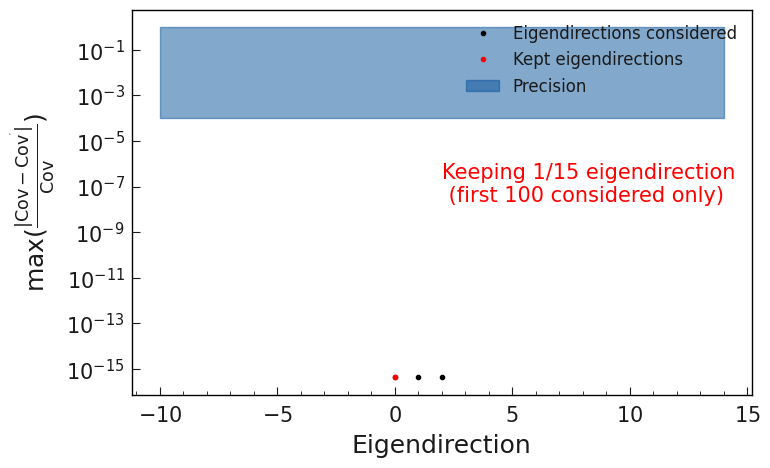

In [268]:
egd_e.plot_cov_diff()

In [269]:
egd_mu = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "muID_eff",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates:

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

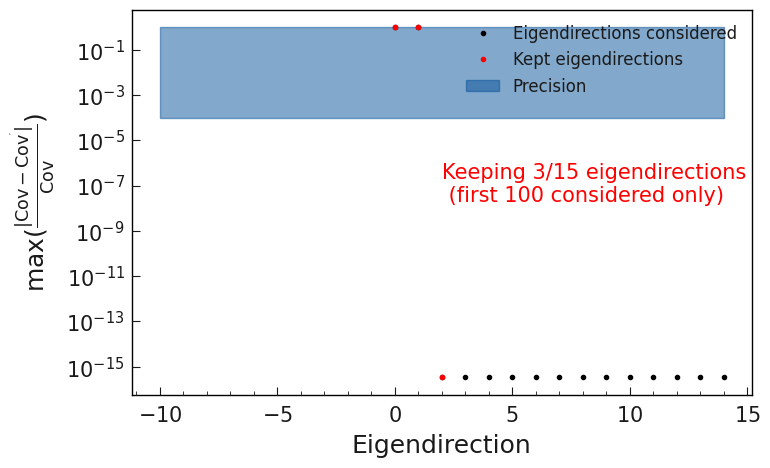

In [270]:
egd_mu.plot_cov_diff()

In [271]:
egd_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel2 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel2/signMC/mu_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_eff_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel2/signMC/mu_eff_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_eff_var3_up
INFO : save_template_variations: 

In [272]:
egd_pifake_e = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "eID_pi_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_pifake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

In [273]:
egd_Kfake_e = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "eID_K_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_Kfake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

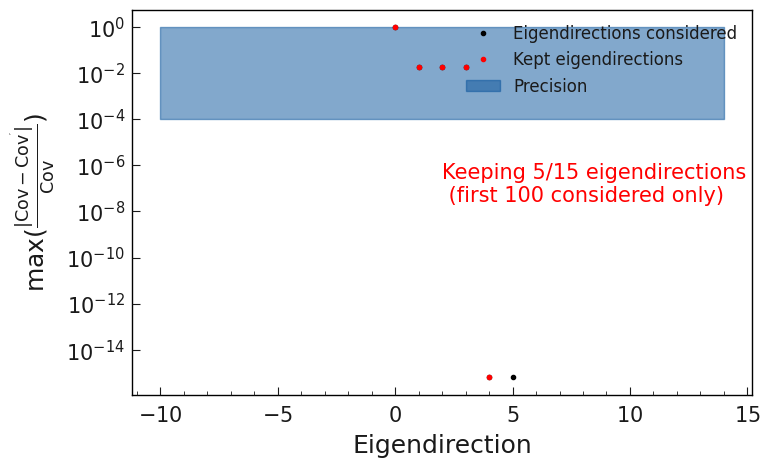

In [274]:
egd_pifake_e.plot_cov_diff()

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

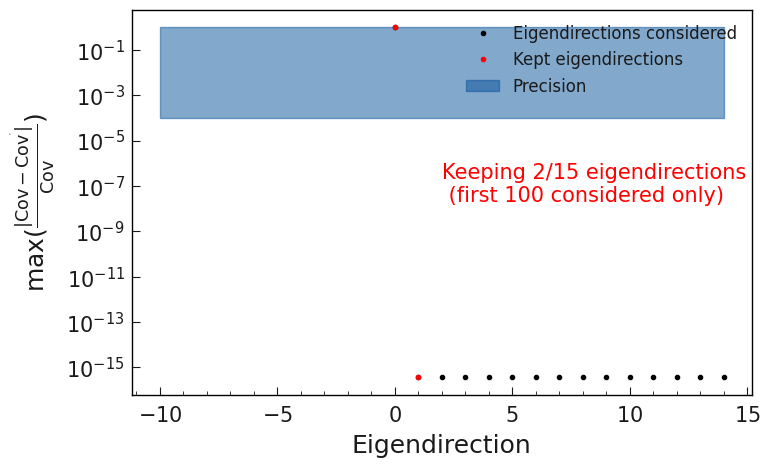

In [275]:
egd_Kfake_e.plot_cov_diff()

In [276]:
egd_pifake_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_pifake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_pifake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_pifake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC i

In [277]:
egd_Kfake_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_Kfake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_Kfake_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/e_Kfake_var1_up
INFO : save_template

In [278]:
egd_pifake_mu = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "muID_pi_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_pifake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates:

In [279]:
egd_Kfake_mu = eigendecompose(
    df = df,
    settings = cfg,
    systematic_source = "muID_K_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_Kfake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel2 ##########
INFO : create_templates:

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

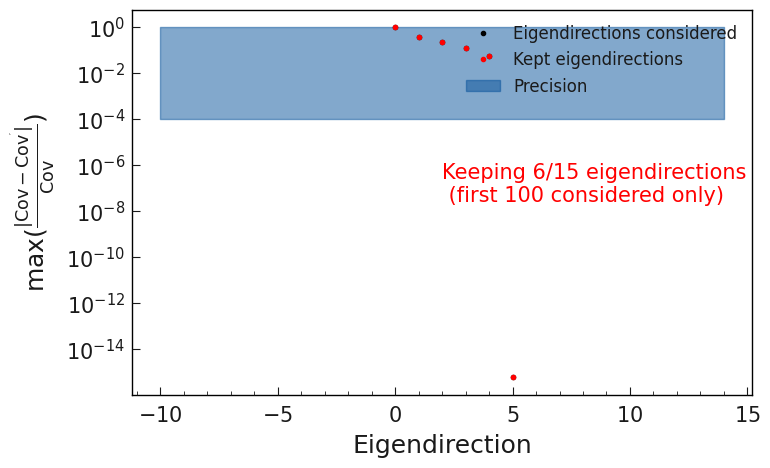

In [280]:
egd_pifake_mu.plot_cov_diff()

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

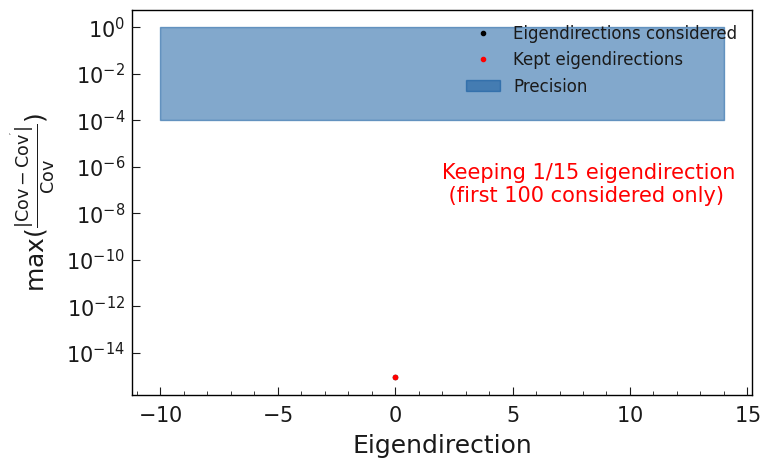

In [281]:
egd_Kfake_mu.plot_cov_diff()

In [282]:
egd_pifake_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel2 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_pifake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel2/signMC/mu_pifake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_pifake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel2/signMC/mu_pifake_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_pifake_var3_up
INFO : save_templa

In [283]:
egd_Kfake_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel2 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel2/signMC/mu_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel2/signMC/mu_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel2/background/mu_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of background in TBranch: channel2/background/mu_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template continuum in TBranch: channel2/continuum/mu_Kfake_var1_up
I

In [284]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["electron_weight"]*df["electron_Kfake_weight"]*df["electron_pifake_weight"]
mask_e = df["B_extraInfo_decayModeID"] == 1
df.loc[mask_e, "total_weight"] = (
    df.loc[mask_e, "Btag_weight"]
    * df.loc[mask_e, "__weight__"]
    * df.loc[mask_e, "B_tracks"]
    * df.loc[mask_e, "electron_weight"]
    * df.loc[mask_e, "electron_Kfake_weight"]
    * df.loc[mask_e, "electron_pifake_weight"]
)

In [285]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["muon_weight"]*df["muon_Kfake_weight"]*df["muon_pifake_weight"]
mask_mu = df["B_extraInfo_decayModeID"] == 2
df.loc[mask_mu, "total_weight"] = (
    df.loc[mask_mu, "Btag_weight"]
    * df.loc[mask_mu, "__weight__"]
    * df.loc[mask_mu, "B_tracks"]
    * df.loc[mask_mu, "muon_weight"]
    * df.loc[mask_mu, "muon_Kfake_weight"]
    * df.loc[mask_mu, "muon_pifake_weight"]
)

## Electron

### FEI systematics

In [286]:
import sys
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

In [287]:
from os import path
from yaml import safe_load

In [288]:
with open(path.join("project_setup_electron.yaml"), "r") as file:
    # Read the yaml file into a dict
    cfg_e = safe_load(file)

In [289]:
save_nominal_templates(df=df_e, settings=cfg_e)

INFO : save_nominal_templates: 293 :  Recreate file with uproot: ./pyhf/test_output_e.root
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : save_nominal_templates: 301 :  ##################################################
INFO : save_nominal_templates: 302 :  ########## Reco channel: channel1 ##########
INFO : save_nominal_templates: 305 :  ##################################################
INFO : save_nominal_templates: 309 :  Saving Nominal MC template signMC in TBranch: channel1/signMC/Nominal
INFO : save_nominal_templates: 309 :  Saving Nominal MC template background in TBranch: channel1/background/Nominal
INFO : save_nominal_templates: 309 :  Saving Nominal MC template continuum in TBranch: channel1/continuum

In [290]:
df_e["Btag_dmID"]=df_e["Btag_extraInfo_decayModeID"]

In [291]:
df_e["Btag_PDG"]=df_e["B_mcPDG"]
df_e.loc[~df_e["Btag_PDG"].isin([521, -521]), "Btag_PDG"] = 521

In [292]:
add_weights_to_dataframe(df_e, correction_source="../FEI_cal_factors_Bp_sigProb_0_001.csv", prefix="Btag", weightname="weight", overwrite=True)
df_e=df_e.copy()

INFO : add_weights_to_dataframe: 142 :  Btag_weight does not exist. Adding it to dataframe


In [293]:
df_e[["Btag_weight"]].describe()

,Btag_weight
count,3871.000000
mean,1.112082
std,0.234131
min,0.281916
25%,1.000000
50%,1.087855
75%,1.276519
max,1.523771


In [294]:
df_e["total_weight"] = df_e["Btag_weight"]*df_e["__weight__"]
df_e=df_e.copy()

In [295]:
from sysvar import eigendecompose

egd_e = eigendecompose(
    df = df_e,
    settings = cfg_e,
    systematic_source = "../FEI_cal_factors_Bp_sigProb_0_001.csv",
    cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "FEI",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 179 :  Loading covariance matrix from file: ../FEI_cal_covariance_Bp_sigProb_0_001.tsv
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 :  Adding variations to continuum template
Building partial covariances:   0%|          | 0/15 [00:00<?, ?it/s]/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
Building partial

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

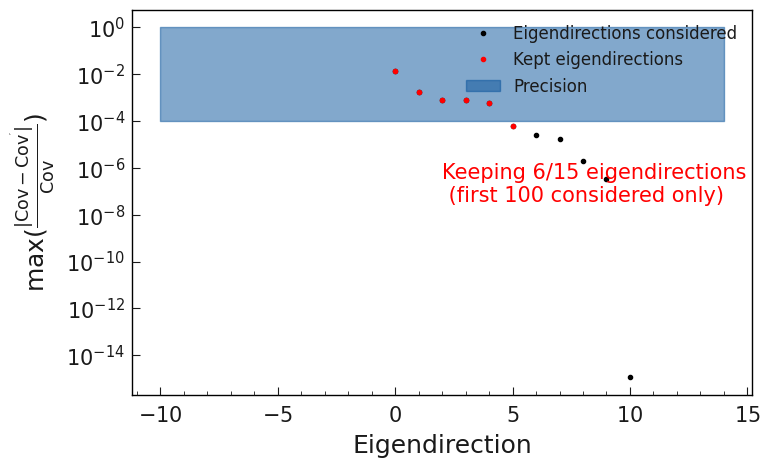

In [296]:
egd_e.plot_cov_diff()

In [297]:
egd_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_e.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/FEI_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/FEI_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var3_up
INFO : save_template_variations: 383 :  Saving

/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


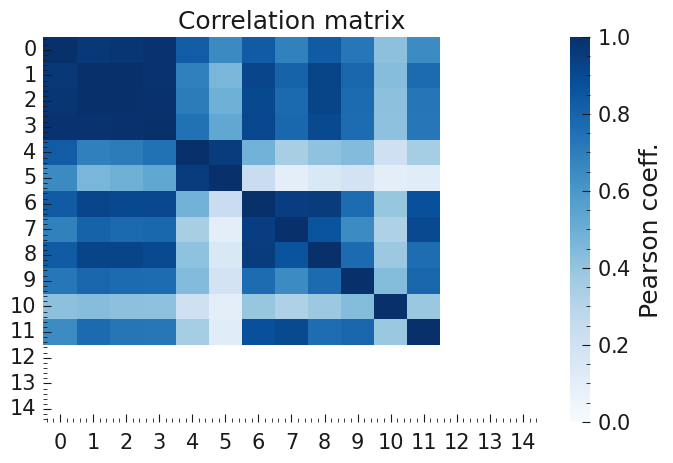

In [298]:
from sysvar import plot_analysis_corr_matrix
fig, ax= plot_analysis_corr_matrix(egd_e)

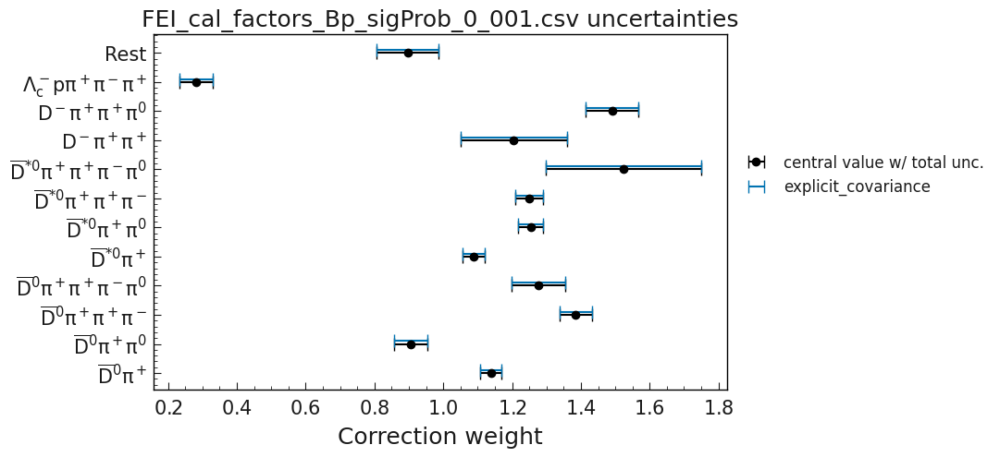

In [299]:
from sysvar import plot_correction_errors
fig, ax= plot_correction_errors(egd_e)

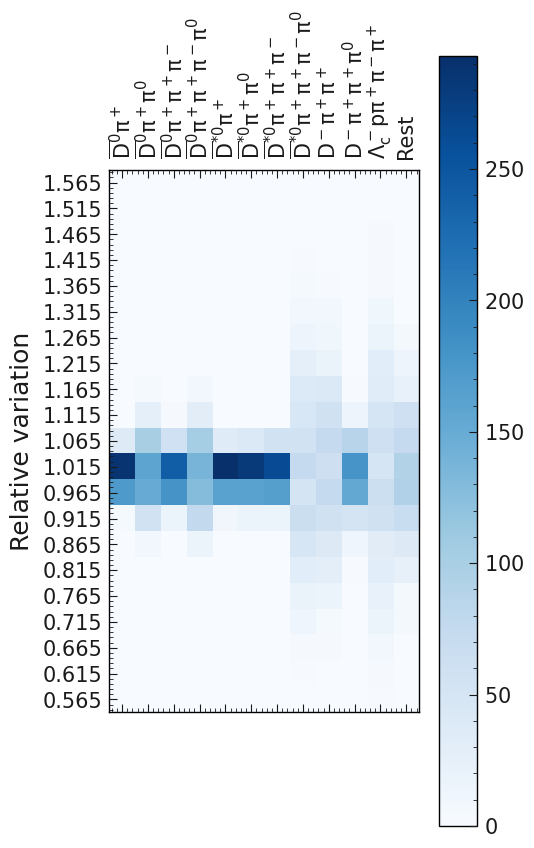

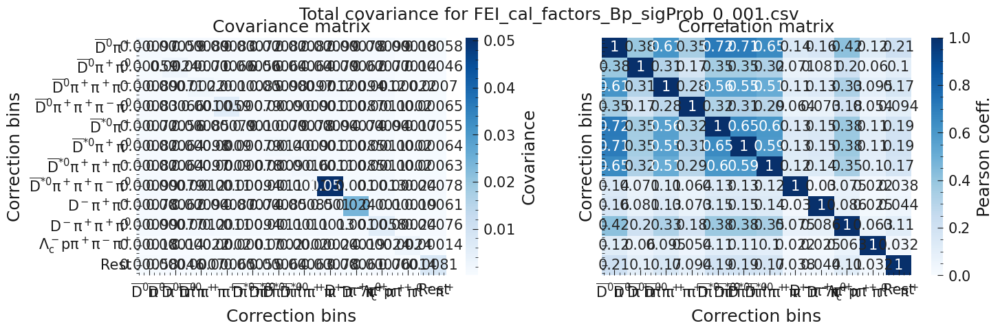

In [300]:
from sysvar import plot_correction_variations_in_grid, plot_correction_cov_and_corr
fig1, ax1= plot_correction_variations_in_grid(egd_e)
fig2, ax2= plot_correction_cov_and_corr(egd_e)

/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:725: RuntimeWarning: invalid value encountered in divide
  h_up[0].flatten() / self.instance.nom_hist[0].flatten(),
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:733: RuntimeWarning: invalid value encountered in divide
  h_down[0].flatten() / self.instance.nom_hist[0].flatten(),
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:757: RuntimeWarning: invalid value encountered in divide
  (h_up[0].flatten() - self.instance.nom_hist[0].flatten())
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/visualize.py:545: RuntimeWarning: invalid value encountered in divide
  relative_variations = np.nan_to_num(variations.T / nominals[0], nan=1)


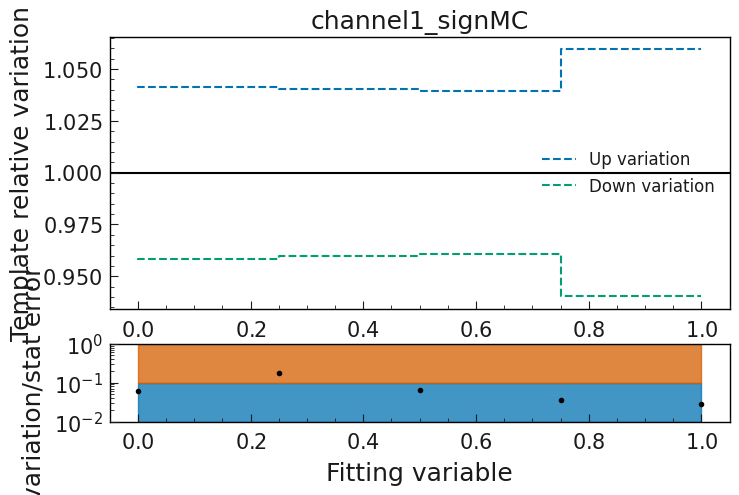

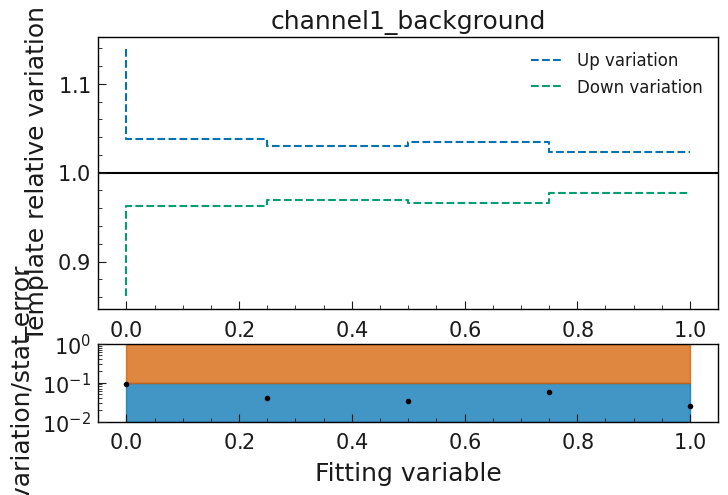

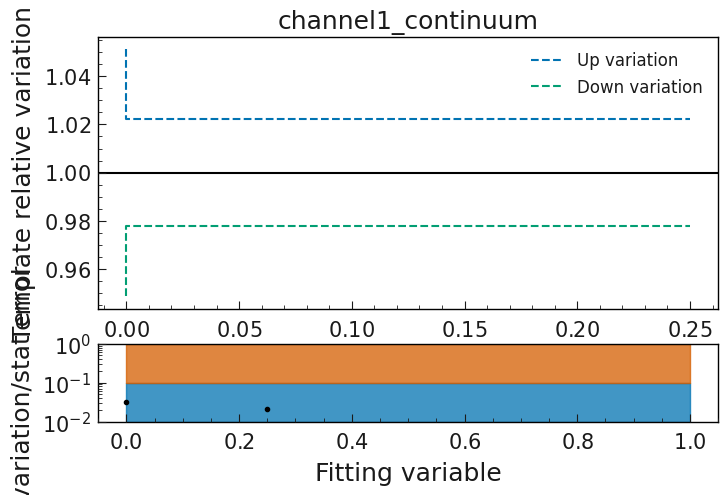

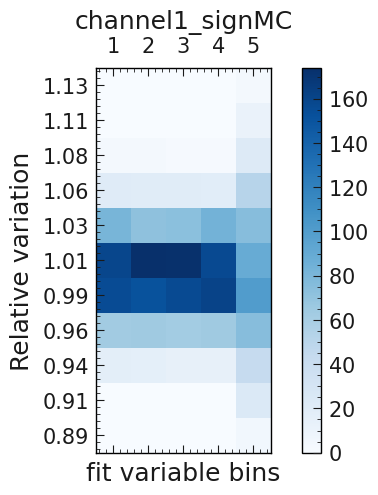

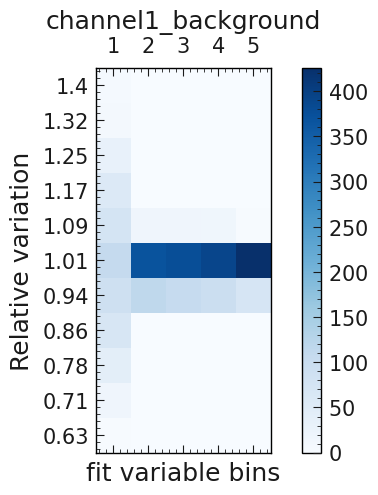

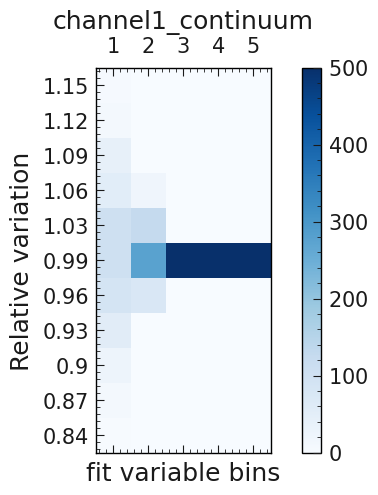

In [301]:
from sysvar import plot_templates_relative_variations_in_grid, plot_up_and_down_variations
figures1= plot_up_and_down_variations(egd_e)
figures2= plot_templates_relative_variations_in_grid(egd_e)

In [302]:
egd_e.templates["channel1_signMC"].df.head(20)

,Btag_weight,template,Btag_PDG,m2RecoilSignalSide,total_weight,channel,Btag_dmID,Btag_weight_up,Btag_weight_down,Btag_weight_var_0,Btag_weight_var_1,Btag_weight_var_2,Btag_weight_var_3,Btag_weight_var_4,Btag_weight_var_5,Btag_weight_var_6,Btag_weight_var_7,Btag_weight_var_8,Btag_weight_var_9,Btag_weight_var_10,Btag_weight_var_11,Btag_weight_var_12,Btag_weight_var_13,Btag_weight_var_14,Btag_weight_var_15,Btag_weight_var_16,Btag_weight_var_17,Btag_weight_var_18,Btag_weight_var_19,Btag_weight_var_20,Btag_weight_var_21,Btag_weight_var_22,Btag_weight_var_23,Btag_weight_var_24,Btag_weight_var_25,Btag_weight_var_26,Btag_weight_var_27,Btag_weight_var_28,Btag_weight_var_29,Btag_weight_var_30,Btag_weight_var_31,Btag_weight_var_32,Btag_weight_var_33,Btag_weight_var_34,Btag_weight_var_35,Btag_weight_var_36,Btag_weight_var_37,Btag_weight_var_38,Btag_weight_var_39,Btag_weight_var_40,Btag_weight_var_41,Btag_weight_var_42,Btag_weight_var_43,Btag_weight_var_44,Btag_weight_var_45,Btag_weight_var_46,Btag_weight_var_47,Btag_weight_var_48,Btag_weight_var_49,Btag_weight_var_50,Btag_weight_var_51,Btag_weight_var_52,Btag_weight_var_53,Btag_weight_var_54,Btag_weight_var_55,Btag_weight_var_56,Btag_weight_var_57,Btag_weight_var_58,Btag_weight_var_59,Btag_weight_var_60,Btag_weight_var_61,Btag_weight_var_62,Btag_weight_var_63,Btag_weight_var_64,Btag_weight_var_65,Btag_weight_var_66,Btag_weight_var_67,Btag_weight_var_68,Btag_weight_var_69,Btag_weight_var_70,Btag_weight_var_71,Btag_weight_var_72,Btag_weight_var_73,Btag_weight_var_74,Btag_weight_var_75,Btag_weight_var_76,Btag_weight_var_77,Btag_weight_var_78,Btag_weight_var_79,Btag_weight_var_80,Btag_weight_var_81,Btag_weight_var_82,Btag_weight_var_83,Btag_weight_var_84,Btag_weight_var_85,Btag_weight_var_86,Btag_weight_var_87,Btag_weight_var_88,Btag_weight_var_89,Btag_weight_var_90,Btag_weight_var_91,Btag_weight_var_92,Btag_weight_var_93,Btag_weight_var_94,Btag_weight_var_95,Btag_weight_var_96,Btag_weight_var_97,Btag_weight_var_98,Btag_weight_var_99,Btag_weight_var_100,Btag_weight_var_101,Btag_weight_var_102,Btag_weight_var_103,Btag_weight_var_104,Btag_weight_var_105,Btag_weight_var_106,Btag_weight_var_107,Btag_weight_var_108,Btag_weight_var_109,Btag_weight_var_110,Btag_weight_var_111,Btag_weight_var_112,Btag_weight_var_113,Btag_weight_var_114,Btag_weight_var_115,Btag_weight_var_116,Btag_weight_var_117,Btag_weight_var_118,Btag_weight_var_119,Btag_weight_var_120,Btag_weight_var_121,Btag_weight_var_122,Btag_weight_var_123,Btag_weight_var_124,Btag_weight_var_125,Btag_weight_var_126,Btag_weight_var_127,Btag_weight_var_128,Btag_weight_var_129,Btag_weight_var_130,Btag_weight_var_131,Btag_weight_var_132,Btag_weight_var_133,Btag_weight_var_134,Btag_weight_var_135,Btag_weight_var_136,Btag_weight_var_137,Btag_weight_var_138,Btag_weight_var_139,Btag_weight_var_140,Btag_weight_var_141,Btag_weight_var_142,Btag_weight_var_143,Btag_weight_var_144,Btag_weight_var_145,Btag_weight_var_146,Btag_weight_var_147,Btag_weight_var_148,Btag_weight_var_149,Btag_weight_var_150,Btag_weight_var_151,Btag_weight_var_152,Btag_weight_var_153,Btag_weight_var_154,Btag_weight_var_155,Btag_weight_var_156,Btag_weight_var_157,Btag_weight_var_158,Btag_weight_var_159,Btag_weight_var_160,Btag_weight_var_161,Btag_weight_var_162,Btag_weight_var_163,Btag_weight_var_164,Btag_weight_var_165,Btag_weight_var_166,Btag_weight_var_167,Btag_weight_var_168,Btag_weight_var_169,Btag_weight_var_170,Btag_weight_var_171,Btag_weight_var_172,Btag_weight_var_173,Btag_weight_var_174,Btag_weight_var_175,Btag_weight_var_176,Btag_weight_var_177,Btag_weight_var_178,Btag_weight_var_179,Btag_weight_var_180,Btag_weight_var_181,Btag_weight_var_182,Btag_weight_var_183,Btag_weight_var_184,Btag_weight_var_185,Btag_weight_var_186,Btag_weight_var_187,Btag_weight_var_188,Btag_weight_var_189,Btag_weight_var_190,Btag_weight_var_191,Btag_weight_var_192,Btag_weight_var_193,Btag_weight_var_194,Btag_weight_var_195,Btag_weight_var_196,Btag_weight_var_197,Btag_weight_var_198,Btag_weight_var_1

### Track systematics

In [303]:
df_e["B_tracks"]=5

In [304]:
add_weights_to_dataframe(df_e, correction_source="MC16rd_track_eff.csv", prefix="B", weightname="tracks", overwrite=True)

INFO : add_weights_to_dataframe: 140 :  B_tracks exists and will be overwritten


In [305]:
from sysvar import eigendecompose

egd_track_e = eigendecompose(
    df = df_e,
    settings = cfg_e,
    systematic_source = "../project/MC16rd_track_eff.csv",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "track_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3769 events
INFO : create_templates: 215 :  Building Template1D for background from 96 events
INFO : create_templates: 215 :  Building Template1D for continuum from 3 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 :  Adding variations to continuum template
Building partial covariances: 100%|██████████| 13/13 [00:00<00:00, 24276.92it/s]
INFO : find_important_eigendimension_indices: 252 :  Found that 2 eigendirections matter for 0.0001 per cent precision


(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

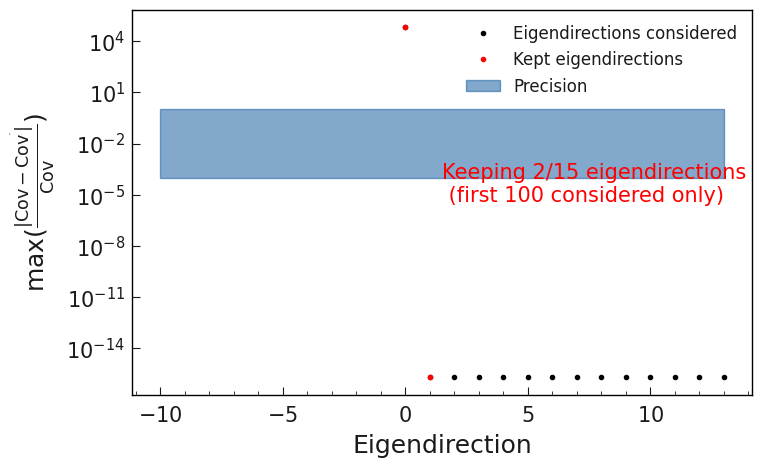

In [306]:
egd_track_e.plot_cov_diff()

In [307]:
egd_track_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_e.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/track_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/track_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/track_eff_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/track_eff_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/track_eff_var1_up
INFO : s

In [308]:
df_e["total_weight"] = df_e["Btag_weight"]*df_e["__weight__"]*df_e["B_tracks"]

In [309]:
df_e[["total_weight"]].describe()

,total_weight
count,3871.000000
mean,0.008324
std,0.024190
min,0.001605
25%,0.005694
50%,0.006194
75%,0.007269
max,0.389145


### PID systematics

In [310]:
import sys
print(sys.executable)
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

/afs/desy.de/user/t/timmue/b2-plothist-env/bin/python


In [311]:
from IPython.display import HTML 

sys_path = 'systematic_corrections_framework/scripts'

sys.path.insert(1, sys_path)

import efficiency_table as et
import process_tables as pt
import show_db_content as sdb
import show_variables as sv
import id_vs_misid_curve as roc
import weight_table as wm

In [312]:
%pip install sly

Note: you may need to restart the kernel to use updated packages.


In [313]:
import show_db_content as sdb
ntuple_table_e = sdb.show_db_content(type='html')
HTML(ntuple_table_e)

INFO : info: 47 :  Successfully opened a DB connection to /data/dust/group/belle2/dataprod/Systematics/production/prod_log_db.csv!


In [314]:
var_table_e = sv.show_ntuple_variables(particle_type='pi', 
                                     data_query=["MC16rd_p16_chunk4"], 
                                     type='html')
HTML(var_table_e)

,Global PIDs,PID BDTs,CMS Frame,Detector hits,PID log(Likelihood),Track Isolation,Uncategorized
0,pionID,pidChargedBDTScore_K,cosThetaCMS,nCDCHits,pidLogLikelihoodOf2212FromKLM,minET2ETIsoScore,dz
1,deuteronIDNN,pidChargedBDTScore_e,pxCMS,nSVDHits,pidLogLikelihoodOf211FromCDC,,pt
2,protonID,pidChargedBDTScore_p,pCMS,nPXDHits,pidLogLikelihoodOf321FromSVD,,theta
3,electronID,pidChargedBDTScore_mu,ECMS,,pidLogLikelihoodOf13FromECL,,E
4,electronID_noTOP,pidChargedBDTScore_pi,pzCMS,,pidLogLikelihoodOf13FromTOP,,clusterE1E9
5,kaonID,pidPairChargedBDTScore_mu_pi,thetaCMS,,pidLogLikelihoodOf2212FromCDC,,clusterE
6,pionIDNN,pidPairChargedBDTScore_e_pi,ptCMS,,pidLogLikelihoodOf321FromARICH,,clusterEoP
7,protonIDNN,,pyCMS,,pidLogLikelihoodOf11FromARICH,,isSignal
8,muonID_noSVD,,phiCMS,,pidLogLikelihoodOf11FromTOP,,dr
9,electronID_noSVD_noTOP,,,,pidLogLikelihoodOf13FromARICH,,lastCDCLayer


In [315]:

from common_methods import DF_SCHEMES
for schema in DF_SCHEMES:
    print(schema, DF_SCHEMES[schema])

Dst  type: Weighted
Particles: ['K', 'pi']
Prefixes:  ['DST_D0_K', 'DST_D0_pi']
Constraints:
For K particle: nCDCHits > 20 and p > 0.3
For pi particle: nCDCHits > 20 and p > 0.1
Lambda0  type: Weighted
Particles: ['p', 'pi']
Prefixes:  ['Lambda0_p', 'Lambda0_pi']
Constraints:
For p particle: nCDCHits > 20 and p > 0.5
For pi particle: nCDCHits > 20 and p > 0.1 and p < 0.75
KShort  type: Weighted
Particles: ['pi', 'pi']
Prefixes:  ['KS_pi1', 'KS_pi2']
Constraints:
For pi particle: nCDCHits > 20 and p > 0.1
For pi particle: nCDCHits > 20 and p > 0.1
Jpsiee  type: Weighted
Particles: ['e', 'e']
Prefixes:  ['e0', 'e1']
Constraints:
For e particle: p > 1.5
For e particle: p > 1.5
Tag cuts:
For prefix e1_: e0_{variable} > 0.9
For prefix e0_: e1_{variable} > 0.9
Jpsimumu  type: Weighted
Particles: ['mu', 'mu']
Prefixes:  ['mu0', 'mu1']
Constraints:
For mu particle: p > 1.5
For mu particle: p > 1.5
Tag cuts:
For prefix mu1_: mu0_{variable} > 0.9
For prefix mu0_: mu1_{variable} > 0.9
Radmumu  ty

In [316]:
from sysvar import corrections

In [317]:
eID_corr_e = corrections.CorrectionPID(systematic="eID_K_fake", MC_production="MC15rd")

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)


In [318]:
eID_corr_e.build_queries()

['(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <= theta < 1.3438532906163765 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <=

In [319]:
eID_corr_e.central_values

[1.2061084081330873,
 1.2587823373135034,
 1.2948594668822906,
 1.3398574201318558,
 0.8598448907493135,
 0.9396903673474464,
 0.8950503434220551,
 1.071877279636151,
 0.897169953876985,
 1.1328429845402306,
 0.9259375193071128,
 1.072227789402525,
 1.2324537370502624,
 1.309933578374879,
 2.1408689323689427,
 3.334676543509604,
 1.0804559494013122,
 1.4171563239654803,
 1.1017520873701163,
 1.173474677831335,
 0.8943867842081028,
 1.0450356355056565,
 0.9528071297614014,
 1.0897691814608237,
 0.8074288103940814,
 1.0411741410578512,
 0.9198685628643406,
 0.99374374376018,
 1.1030475320119888,
 0.8920019143563843,
 3.8505202574507713,
 4.001446628365155,
 2.148085142660209,
 2.166653673523171,
 1.088278109787026,
 1.2425249675873913,
 1.071581927436418,
 1.0611379830997856,
 0.906445919153308,
 1.5524687745425343,
 1.0205448856979435,
 1.0505382520942934,
 1.011790559859607,
 1.700660454877294,
 1.3561079243056506,
 1.251657003595103,
 1.5060617659816304,
 3.8112755441679953,
 1.114709

In [320]:
eID_corr_e.table

,p_min,p_max,cosTheta_min,cosTheta_max,charge_min,charge_max,data_MC_ratio,data_MC_uncertainty_stat_up,data_MC_uncertainty_stat_dn,data_MC_uncertainty_sys_up,data_MC_uncertainty_sys_dn,data_efficiency,data_uncertainty_stat_up,data_uncertainty_stat_dn,data_uncertainty_sys_up,data_uncertainty_sys_dn,MC_efficiency,MC_uncertainty_stat_up,MC_uncertainty_stat_dn,MC_uncertainty_sys_up,MC_uncertainty_sys_dn,threshold,variable,working_point,is_best_available,theta_min,theta_max,charge,mcPDG
0,0.5,0.9,-0.8660,-0.6820,-2,0,1.206108,0.262942,0.262942,0.026090,0.026090,0.004734,0.001140,0.001140,0.000097,0.000097,0.003925,0.000414,0.000414,8.895745e-05,8.895745e-05,0.9,electronID,FixedThresh09,True,2.321290,2.617943,-,11
1,0.5,0.9,-0.8660,-0.6820,0,2,1.258782,0.183764,0.183764,0.014002,0.014002,0.007933,0.001262,0.001262,0.000066,0.000066,0.006302,0.000580,0.000580,1.379659e-04,1.379659e-04,0.9,electronID,FixedThresh09,True,2.321290,2.617943,+,-11
2,0.5,0.9,-0.6820,-0.4226,-2,0,1.294859,0.096071,0.096071,0.023108,0.023108,0.008017,0.000679,0.000679,0.000047,0.000047,0.006192,0.000281,0.000281,8.580556e-06,8.580556e-06,0.9,electronID,FixedThresh09,True,2.007108,2.321290,-,11
3,0.5,0.9,-0.6820,-0.4226,0,2,1.339857,0.095492,0.095492,0.025672,0.025672,0.008431,0.000710,0.000710,0.000087,0.000087,0.006292,0.000283,0.000283,1.554210e-04,1.554210e-04,0.9,electronID,FixedThresh09,True,2.007108,2.321290,+,-11
4,0.5,0.9,-0.4226,-0.1045,-2,0,0.859845,0.059016,0.059016,0.011197,0.011197,0.013967,0.000755,0.000755,0.000232,0.000232,0.016244,0.000385,0.000385,1.718155e-04,1.718155e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,-,11
5,0.5,0.9,-0.4226,-0.1045,0,2,0.939690,0.066818,0.066818,0.002471,0.002471,0.011751,0.000715,0.000715,0.000118,0.000118,0.012505,0.000345,0.000345,5.963684e-04,5.963684e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,+,-11
6,0.5,0.9,-0.1045,0.2250,-2,0,0.895050,0.036522,0.036522,0.005671,0.005671,0.029871,0.000994,0.000994,0.000079,0.000079,0.033373,0.000501,0.000501,4.761595e-04,4.761595e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,-,11
7,0.5,0.9,-0.1045,0.2250,0,2,1.071877,0.041444,0.041444,0.008236,0.008236,0.024329,0.000904,0.000904,0.000116,0.000116,0.022697,0.000416,0.000416,3.625528e-04,3.625528e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,+,-11
8,0.5,0.9,0.2250,0.5000,-2,0,0.897170,0.036895,0.036895,0.006720,0.006720,0.031951,0.001078,0.001078,0.000032,0.000032,0.035613,0.000533,0.000533,4.405714e-04,4.405714e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,-,11
9,0.5,0.9,0.2250,0.5000,0,2,1.132843,0.037339,0.037339,0.004157,0.004157,0.031649,0.001053,0.001053,0.000052,0.000052,0.027937,0.000473,0.000473,6.761617e-04,6.761617e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,+,-11


In [321]:
df_e["electron_PDG"] = df_e["B_extraInfo_decayModeID"]
df_e.loc[df_e["electron_PDG"].isin([1]) & df_e["B_mu_charge"].isin([-1]), "electron_PDG"] = 11
df_e.loc[df_e["electron_PDG"].isin([1]) & df_e["B_mu_charge"].isin([1]), "electron_PDG"] = -11
#df[["electron_PDG"]==11] = df[["electron_PDG"]==1]
df_e["electron_mcPDG"] = df_e["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([-1]), "electron_mcPDG"] = -11
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([1]), "electron_mcPDG"] = 11
df_e["electron_p"] = df_e["B_mu_p"]
df_e["electron_theta"] = np.arccos(df_e["B_mu_cosTheta"])
df_e=df_e.copy()

In [322]:
df_e["muon_PDG"] = df_e["B_extraInfo_decayModeID"]
df_e.loc[df_e["muon_PDG"].isin([2]) & df_e["B_mu_charge"].isin([-1]), "muon_PDG"] = 13
df_e.loc[df_e["muon_PDG"].isin([2]) & df_e["B_mu_charge"].isin([1]), "muon_PDG"] = -13
#df[["muon_PDG"]==13] = df[["muon_PDG"]==2]
df_e["muon_mcPDG"] = df_e["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([-1]), "muon_mcPDG"] = -13
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([1]), "muon_mcPDG"] = 13
df_e["muon_p"] = df_e["B_mu_p"]
df_e["muon_theta"] = np.arccos(df_e["B_mu_cosTheta"])
df_e=df_e.copy()

In [323]:
add_weights_to_dataframe(df_e, correction_source="eID_eff", MC_production="MC15rd", prefix="electron", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_weight does not exist. Adding it to dataframe


In [324]:
add_weights_to_dataframe(df_e, correction_source="muID_eff", MC_production="MC15rd", prefix="muon", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_weight does not exist. Adding it to dataframe


In [325]:
df_e.query("1.3 < electron_p < 1.7000000000000002")[["electron_theta", "electron_PDG", "muon_PDG", "electron_mcPDG", "muon_mcPDG", "electron_weight"]].head(20)

,electron_theta,electron_PDG,muon_PDG,electron_mcPDG,muon_mcPDG,electron_weight
514,1.247024,11.0,1.0,NaN,NaN,1.0
10,0.883767,11.0,1.0,NaN,NaN,1.0
60,0.826045,-11.0,1.0,NaN,NaN,1.0
91,0.813963,-11.0,1.0,NaN,NaN,1.0
196,0.740055,-11.0,1.0,NaN,NaN,1.0
213,0.969908,11.0,1.0,NaN,NaN,1.0
232,1.135068,11.0,1.0,NaN,NaN,1.0
245,1.339424,11.0,1.0,NaN,NaN,1.0
358,0.477885,-11.0,1.0,NaN,NaN,1.0
416,0.360374,11.0,1.0,NaN,NaN,1.0


In [326]:
df_e[["electron_PDG", "electron_theta", "electron_mcPDG", "electron_p", "muon_PDG", "muon_theta", "muon_mcPDG", "muon_p", "B_mu_mcPDG"]].describe()

,electron_PDG,electron_theta,electron_mcPDG,electron_p,muon_PDG,muon_theta,muon_mcPDG,muon_p,B_mu_mcPDG
count,3871.000000,3871.000000,23.000000,3871.000000,3871.0,3871.000000,23.000000,3871.000000,23.000000
mean,0.150607,1.273136,-22.739130,0.755282,1.0,1.273136,-22.739130,0.755282,-22.739130
std,11.000390,0.513968,201.473034,0.306668,0.0,0.513968,201.473034,0.306668,201.473034
min,-11.000000,0.304716,-211.000000,0.300013,1.0,0.304716,-211.000000,0.300013,-211.000000
25%,-11.000000,0.864023,-211.000000,0.505818,1.0,0.864023,-211.000000,0.505818,-211.000000
50%,11.000000,1.232986,-11.000000,0.712864,1.0,1.232986,-11.000000,0.712864,-11.000000
75%,11.000000,1.660010,211.000000,0.955768,1.0,1.660010,211.000000,0.955768,211.000000
max,11.000000,2.556460,321.000000,1.984812,1.0,2.556460,321.000000,1.984812,321.000000


In [327]:
add_weights_to_dataframe(df_e, correction_source="eID_K_fake", MC_production="MC15rd", prefix="electron", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_Kfake_weight does not exist. Adding it to dataframe


In [328]:
add_weights_to_dataframe(df_e, correction_source="eID_pi_fake", MC_production="MC15rd", prefix="electron", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_pifake_weight does not exist. Adding it to dataframe


In [329]:
add_weights_to_dataframe(df_e, correction_source="muID_K_fake", MC_production="MC15rd", prefix="muon", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_Kfake_weight does not exist. Adding it to dataframe


In [330]:
add_weights_to_dataframe(df_e, correction_source="muID_pi_fake", MC_production="MC15rd", prefix="muon", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_pifake_weight does not exist. Adding it to dataframe


In [331]:
df_e["muon_pifake_weight"].value_counts()

muon_pifake_weight
1.0    3871
Name: count, dtype: int64

In [332]:
df_e.groupby([ "B_mu_mcPDG"])["electron_PDG"].value_counts(dropna=False)

B_mu_mcPDG  electron_PDG
-211.0       11.0           11
-11.0       -11.0            2
 11.0        11.0            2
 211.0      -11.0            7
 321.0      -11.0            1
Name: count, dtype: int64

In [333]:
df_e.groupby([ "B_mu_mcPDG"])["muon_PDG"].value_counts(dropna=False)

B_mu_mcPDG  muon_PDG
-211.0      1.0         11
-11.0       1.0          2
 11.0       1.0          2
 211.0      1.0          7
 321.0      1.0          1
Name: count, dtype: int64

In [334]:
df_e.query("B_mu_mcPDG in [321, -321] and electron_PDG in [11, -11]")[["electron_theta", "electron_p"]]

,electron_theta,electron_p
144,1.071078,0.578158


In [335]:
df_e["electron_weight"].describe()

count    3871.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: electron_weight, dtype: float64

In [336]:
df_e["muon_weight"].describe()

count    3871.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: muon_weight, dtype: float64

In [337]:
[x for x in df_e.columns if "Theta" in x]

['B_cosThetaBetweenParticleAndNominalB',
 'B_mu_cosTheta',
 'Btag_cosThetaBetweenParticleAndNominalB',
 'thrustAxisCosTheta']

In [338]:
df_e["B_mu_mcPDG"].value_counts(dropna=False)

B_mu_mcPDG
 NaN      3848
-211.0      11
 211.0       7
-11.0        2
 11.0        2
 321.0       1
Name: count, dtype: int64

In [339]:
df_e["__weight__"].value_counts(dropna=False)

__weight__
0.005694    3844
0.255383      27
Name: count, dtype: int64

In [340]:
df_e.groupby([ "__weight__"])["template"].value_counts(dropna=False)

__weight__  template  
0.005694    signMC        3770
            background      74
0.255383    background      23
            continuum        4
Name: count, dtype: int64

In [341]:
'''
custom_systematic_source = {
    "path": "../project/PID_tables/e_efficiency_table.csv",
    "csv_type": "detect_error"  
}
'''
egd_e_e = eigendecompose(
    df = df_e,
    settings = cfg_e,
    systematic_source = "eID_eff", #custom_systematic_source, #
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

In [342]:
egd_e_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_e.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/e_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of background in TBranch: channel1/background/e_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template continuum in TBranch: channel1/continuum/e_eff_var1_up
INFO : save_te

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

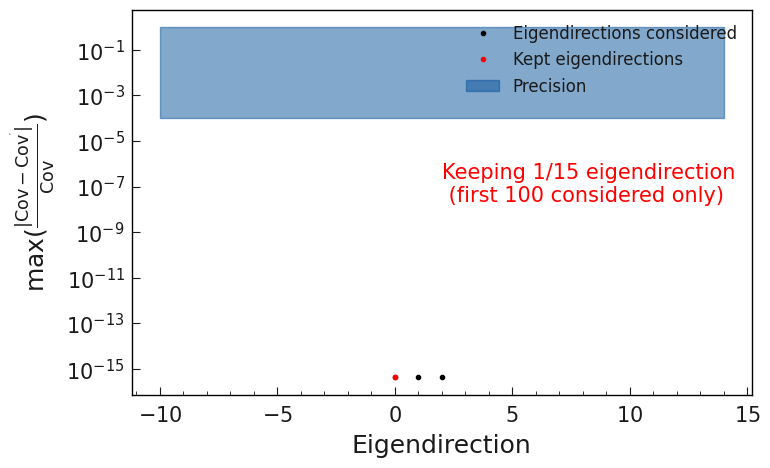

In [343]:
egd_e_e.plot_cov_diff()

In [344]:
egd_pifake_e_e = eigendecompose(
    df = df_e,
    settings = cfg_e,
    systematic_source = "eID_pi_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_pifake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

In [345]:
egd_Kfake_e_e = eigendecompose(
    df = df_e,
    settings = cfg_e,
    systematic_source = "eID_K_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "e_Kfake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Bu

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

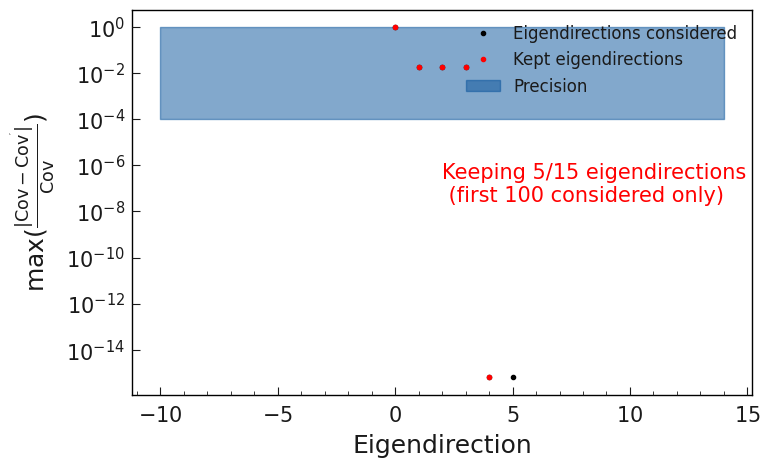

In [346]:
egd_pifake_e_e.plot_cov_diff()

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

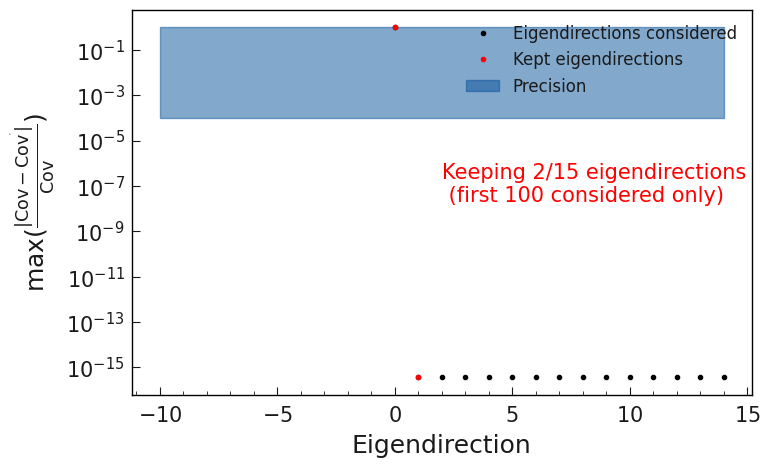

In [347]:
egd_Kfake_e_e.plot_cov_diff()

In [348]:
egd_pifake_e_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_e.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_pifake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_pifake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_pifake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC

In [349]:
egd_Kfake_e_e.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_e.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/e_Kfake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/e_Kfake_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/e_Kfake_var1_up
INFO : save_templa

In [350]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["electron_weight"]*df["electron_Kfake_weight"]*df["electron_pifake_weight"]
mask_e_e = df_e["B_extraInfo_decayModeID"] == 1
df_e.loc[mask_e_e, "total_weight"] = (
    df_e.loc[mask_e_e, "Btag_weight"]
    * df_e.loc[mask_e_e, "__weight__"]
    * df_e.loc[mask_e_e, "B_tracks"]
    * df_e.loc[mask_e_e, "electron_weight"]
    * df_e.loc[mask_e_e, "electron_Kfake_weight"]
    * df_e.loc[mask_e_e, "electron_pifake_weight"]
)

In [351]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["muon_weight"]*df["muon_Kfake_weight"]*df["muon_pifake_weight"]
mask_mu_e = df_e["B_extraInfo_decayModeID"] == 2
df_e.loc[mask_mu_e, "total_weight"] = (
    df_e.loc[mask_mu_e, "Btag_weight"]
    * df_e.loc[mask_mu_e, "__weight__"]
    * df_e.loc[mask_mu_e, "B_tracks"]
    * df_e.loc[mask_mu_e, "muon_weight"]
    * df_e.loc[mask_mu_e, "muon_Kfake_weight"]
    * df_e.loc[mask_mu_e, "muon_pifake_weight"]
)

## Muon

### FEI systematics

In [352]:
import sys
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

In [353]:
from os import path
from yaml import safe_load

In [354]:
with open(path.join("project_setup_muon.yaml"), "r") as file:
    # Read the yaml file into a dict
    cfg_mu = safe_load(file)

In [355]:
save_nominal_templates(df=df_mu, settings=cfg_mu)

INFO : save_nominal_templates: 293 :  Recreate file with uproot: ./pyhf/test_output_mu.root
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : save_nominal_templates: 301 :  ##################################################
INFO : save_nominal_templates: 302 :  ########## Reco channel: channel1 ##########
INFO : save_nominal_templates: 305 :  ##################################################
INFO : save_nominal_templates: 309 :  Saving Nominal MC template signMC in TBranch: channel1/signMC/Nominal
INFO : save_nominal_templates: 309 :  Saving Nominal MC template background in TBranch: channel1/background/Nominal
INFO : save_nominal_templates: 309 :  Saving Nominal MC template continuum in TBranch: channel1/contin

In [356]:
df_mu["Btag_dmID"]=df_mu["Btag_extraInfo_decayModeID"]

In [357]:
df_mu["Btag_PDG"]=df_mu["B_mcPDG"]
df_mu.loc[~df_mu["Btag_PDG"].isin([521, -521]), "Btag_PDG"] = 521

In [358]:
add_weights_to_dataframe(df_mu, correction_source="../FEI_cal_factors_Bp_sigProb_0_001.csv", prefix="Btag", weightname="weight", overwrite=True)
df_mu=df_mu.copy()

INFO : add_weights_to_dataframe: 142 :  Btag_weight does not exist. Adding it to dataframe


In [359]:
df_mu[["Btag_weight"]].describe()

,Btag_weight
count,3492.000000
mean,1.111148
std,0.228125
min,0.281916
25%,1.000000
50%,1.087855
75%,1.253812
max,1.523771


In [360]:
df_mu["total_weight"] = df_mu["Btag_weight"]*df_mu["__weight__"]
df_mu=df_mu.copy()

In [361]:
from sysvar import eigendecompose

egd_mu = eigendecompose(
    df = df_mu,
    settings = cfg_mu,
    systematic_source = "../FEI_cal_factors_Bp_sigProb_0_001.csv",
    cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "FEI",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 179 :  Loading covariance matrix from file: ../FEI_cal_covariance_Bp_sigProb_0_001.tsv
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 :  Adding variations to continuum template
Building partial covariances:   0%|          | 0/15 [00:00<?, ?it/s]/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
Building parti

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

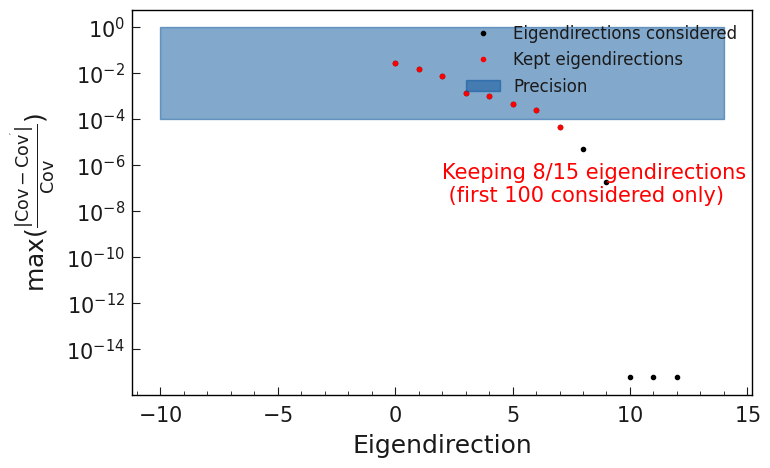

In [362]:
egd_mu.plot_cov_diff()

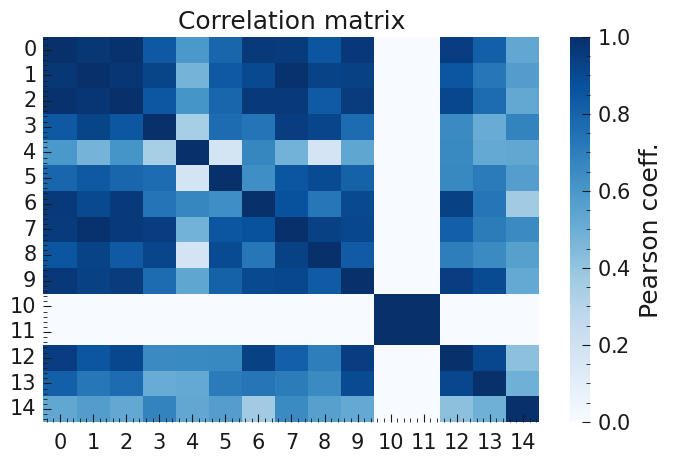

In [363]:
from sysvar import plot_analysis_corr_matrix
fig, ax= plot_analysis_corr_matrix(egd_mu)

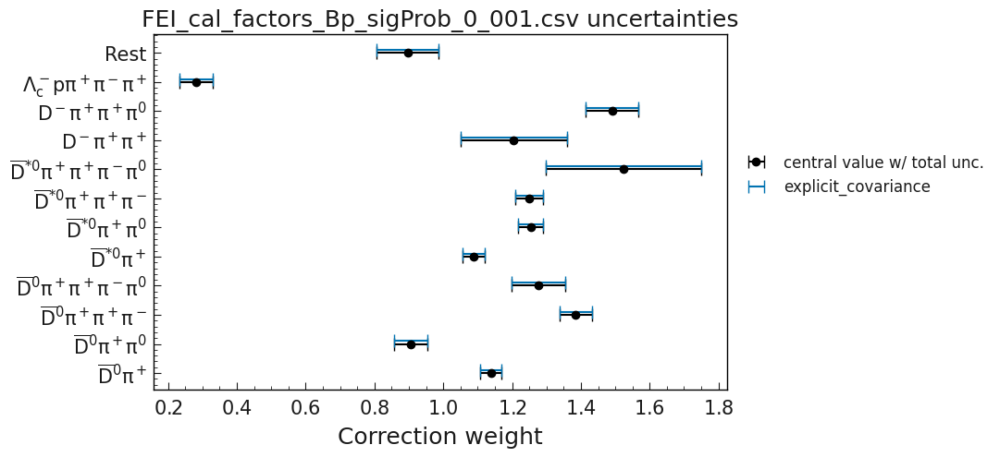

In [364]:
from sysvar import plot_correction_errors
fig, ax= plot_correction_errors(egd_mu)

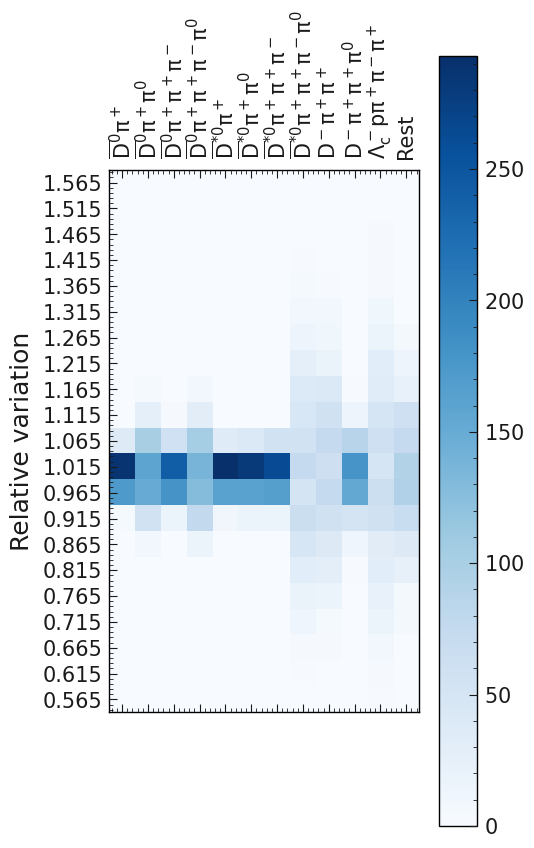

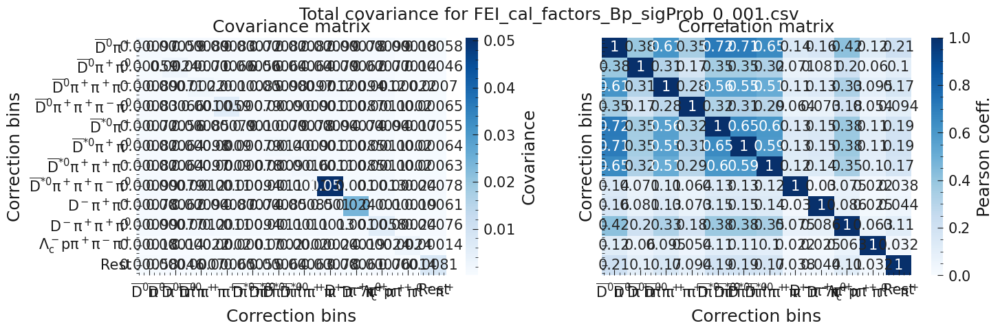

In [365]:
from sysvar import plot_correction_variations_in_grid, plot_correction_cov_and_corr
fig1, ax1= plot_correction_variations_in_grid(egd_mu)
fig2, ax2= plot_correction_cov_and_corr(egd_mu)

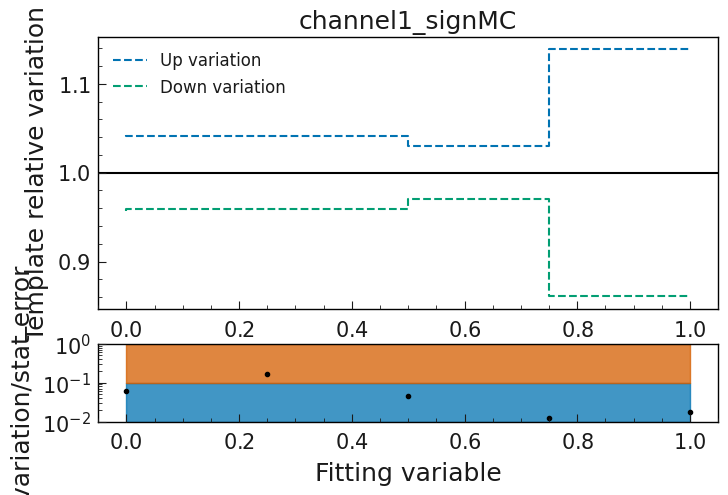

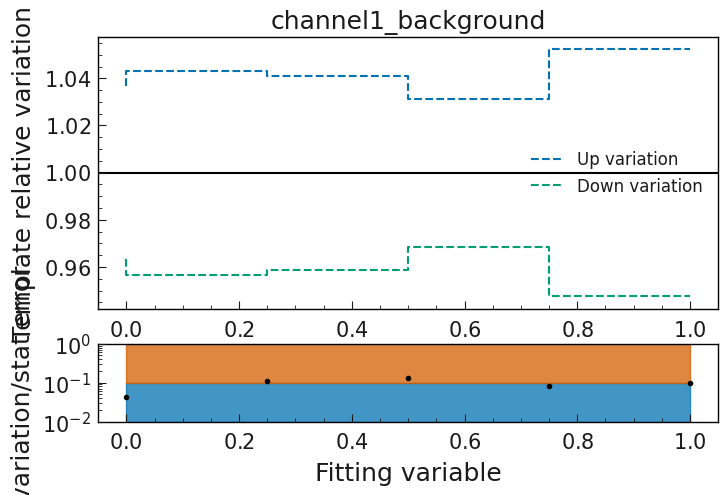

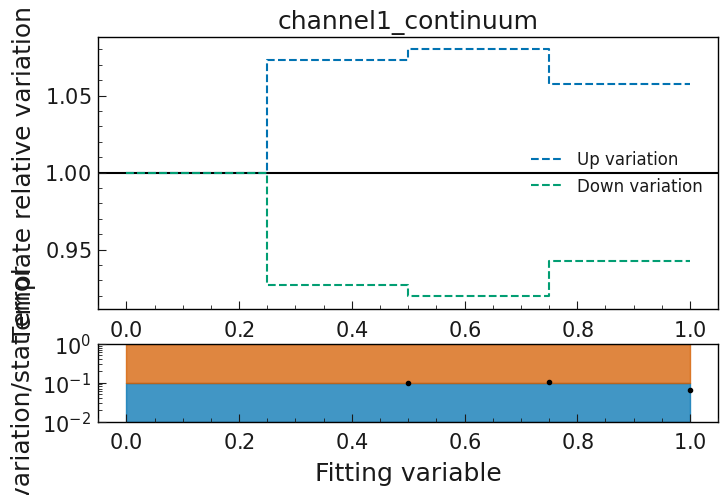

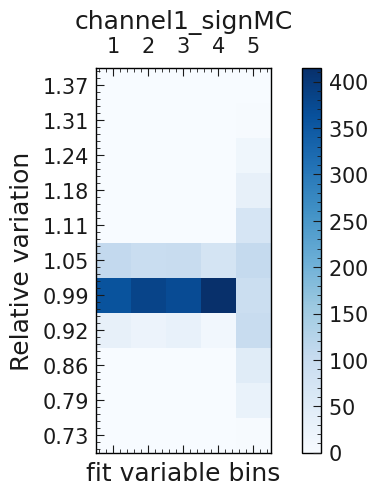

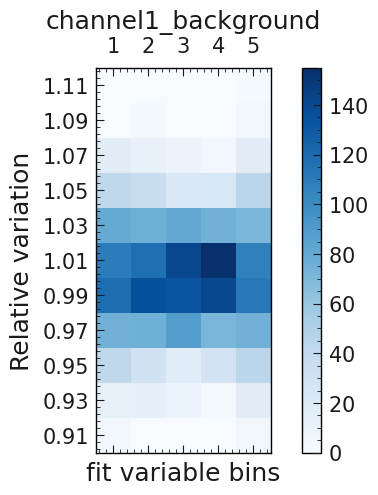

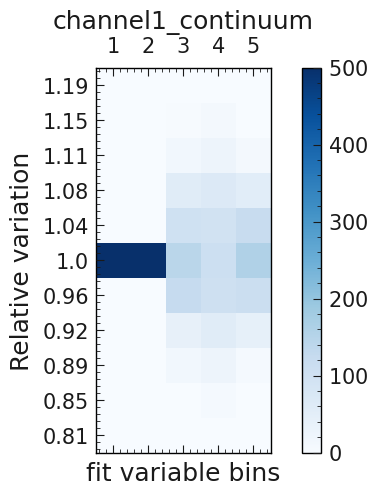

In [366]:
from sysvar import plot_templates_relative_variations_in_grid, plot_up_and_down_variations
figures1= plot_up_and_down_variations(egd_mu)
figures2= plot_templates_relative_variations_in_grid(egd_mu)

In [367]:
egd_mu.templates["channel1_signMC"].df.head(20)

,Btag_weight,template,Btag_PDG,m2RecoilSignalSide,total_weight,channel,Btag_dmID,Btag_weight_up,Btag_weight_down,Btag_weight_var_0,Btag_weight_var_1,Btag_weight_var_2,Btag_weight_var_3,Btag_weight_var_4,Btag_weight_var_5,Btag_weight_var_6,Btag_weight_var_7,Btag_weight_var_8,Btag_weight_var_9,Btag_weight_var_10,Btag_weight_var_11,Btag_weight_var_12,Btag_weight_var_13,Btag_weight_var_14,Btag_weight_var_15,Btag_weight_var_16,Btag_weight_var_17,Btag_weight_var_18,Btag_weight_var_19,Btag_weight_var_20,Btag_weight_var_21,Btag_weight_var_22,Btag_weight_var_23,Btag_weight_var_24,Btag_weight_var_25,Btag_weight_var_26,Btag_weight_var_27,Btag_weight_var_28,Btag_weight_var_29,Btag_weight_var_30,Btag_weight_var_31,Btag_weight_var_32,Btag_weight_var_33,Btag_weight_var_34,Btag_weight_var_35,Btag_weight_var_36,Btag_weight_var_37,Btag_weight_var_38,Btag_weight_var_39,Btag_weight_var_40,Btag_weight_var_41,Btag_weight_var_42,Btag_weight_var_43,Btag_weight_var_44,Btag_weight_var_45,Btag_weight_var_46,Btag_weight_var_47,Btag_weight_var_48,Btag_weight_var_49,Btag_weight_var_50,Btag_weight_var_51,Btag_weight_var_52,Btag_weight_var_53,Btag_weight_var_54,Btag_weight_var_55,Btag_weight_var_56,Btag_weight_var_57,Btag_weight_var_58,Btag_weight_var_59,Btag_weight_var_60,Btag_weight_var_61,Btag_weight_var_62,Btag_weight_var_63,Btag_weight_var_64,Btag_weight_var_65,Btag_weight_var_66,Btag_weight_var_67,Btag_weight_var_68,Btag_weight_var_69,Btag_weight_var_70,Btag_weight_var_71,Btag_weight_var_72,Btag_weight_var_73,Btag_weight_var_74,Btag_weight_var_75,Btag_weight_var_76,Btag_weight_var_77,Btag_weight_var_78,Btag_weight_var_79,Btag_weight_var_80,Btag_weight_var_81,Btag_weight_var_82,Btag_weight_var_83,Btag_weight_var_84,Btag_weight_var_85,Btag_weight_var_86,Btag_weight_var_87,Btag_weight_var_88,Btag_weight_var_89,Btag_weight_var_90,Btag_weight_var_91,Btag_weight_var_92,Btag_weight_var_93,Btag_weight_var_94,Btag_weight_var_95,Btag_weight_var_96,Btag_weight_var_97,Btag_weight_var_98,Btag_weight_var_99,Btag_weight_var_100,Btag_weight_var_101,Btag_weight_var_102,Btag_weight_var_103,Btag_weight_var_104,Btag_weight_var_105,Btag_weight_var_106,Btag_weight_var_107,Btag_weight_var_108,Btag_weight_var_109,Btag_weight_var_110,Btag_weight_var_111,Btag_weight_var_112,Btag_weight_var_113,Btag_weight_var_114,Btag_weight_var_115,Btag_weight_var_116,Btag_weight_var_117,Btag_weight_var_118,Btag_weight_var_119,Btag_weight_var_120,Btag_weight_var_121,Btag_weight_var_122,Btag_weight_var_123,Btag_weight_var_124,Btag_weight_var_125,Btag_weight_var_126,Btag_weight_var_127,Btag_weight_var_128,Btag_weight_var_129,Btag_weight_var_130,Btag_weight_var_131,Btag_weight_var_132,Btag_weight_var_133,Btag_weight_var_134,Btag_weight_var_135,Btag_weight_var_136,Btag_weight_var_137,Btag_weight_var_138,Btag_weight_var_139,Btag_weight_var_140,Btag_weight_var_141,Btag_weight_var_142,Btag_weight_var_143,Btag_weight_var_144,Btag_weight_var_145,Btag_weight_var_146,Btag_weight_var_147,Btag_weight_var_148,Btag_weight_var_149,Btag_weight_var_150,Btag_weight_var_151,Btag_weight_var_152,Btag_weight_var_153,Btag_weight_var_154,Btag_weight_var_155,Btag_weight_var_156,Btag_weight_var_157,Btag_weight_var_158,Btag_weight_var_159,Btag_weight_var_160,Btag_weight_var_161,Btag_weight_var_162,Btag_weight_var_163,Btag_weight_var_164,Btag_weight_var_165,Btag_weight_var_166,Btag_weight_var_167,Btag_weight_var_168,Btag_weight_var_169,Btag_weight_var_170,Btag_weight_var_171,Btag_weight_var_172,Btag_weight_var_173,Btag_weight_var_174,Btag_weight_var_175,Btag_weight_var_176,Btag_weight_var_177,Btag_weight_var_178,Btag_weight_var_179,Btag_weight_var_180,Btag_weight_var_181,Btag_weight_var_182,Btag_weight_var_183,Btag_weight_var_184,Btag_weight_var_185,Btag_weight_var_186,Btag_weight_var_187,Btag_weight_var_188,Btag_weight_var_189,Btag_weight_var_190,Btag_weight_var_191,Btag_weight_var_192,Btag_weight_var_193,Btag_weight_var_194,Btag_weight_var_195,Btag_weight_var_196,Btag_weight_var_197,Btag_weight_var_198,Btag_weight_var_1

In [368]:
egd_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_mu.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/FEI_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/FEI_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: c

In [369]:
uproot.open("./pyhf/test_output.root")['channel1/background/FEI_var1_up;1'].to_numpy()

(array([0.39634478, 1.12739362, 1.23765474, 2.77732255, 1.13154953]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [370]:
uproot.open("./pyhf/test_output.root")['channel1/signMC/FEI_var1_down;1'].to_numpy()

(array([ 2.1154663 , 18.35456012,  2.66782171,  0.8544701 ,  0.24000405]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [371]:
uproot.open("./pyhf/test_output.root")['channel1/signMC/Nominal'].to_numpy()

(array([ 1.85055 , 16.131102,  2.36301 ,  0.751608,  0.193596]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [372]:
egd.templates["channel1_signMC"].make_hist()

(array([ 2.06566564, 17.92319577,  2.60565103,  0.83499318,  0.23309941]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

In [373]:
egd.templates["channel1_signMC"].make_hist(499)

(array([ 2.03235048, 17.55687612,  2.55632893,  0.82144417,  0.228961  ]),
 array([-0.5, -0.1,  0.1,  0.3,  0.7,  1.1]))

### Track systematics

In [374]:
df_mu["B_tracks"]=5

In [375]:
add_weights_to_dataframe(df_mu, correction_source="MC16rd_track_eff.csv", prefix="B", weightname="tracks", overwrite=True)

INFO : add_weights_to_dataframe: 140 :  B_tracks exists and will be overwritten


In [376]:
from sysvar import eigendecompose

egd_track_mu = eigendecompose(
    df = df_mu,
    settings = cfg_mu,
    systematic_source = "../project/MC16rd_track_eff.csv",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "track_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates: 215 :  Building Template1D for signMC from 3318 events
INFO : create_templates: 215 :  Building Template1D for background from 153 events
INFO : create_templates: 215 :  Building Template1D for continuum from 18 events
INFO : vary_templates: 212 :  ########## Reco channel: channel1 ##########
INFO : vary_templates: 226 :  Adding variations to signMC template
INFO : vary_templates: 226 :  Adding variations to background template
INFO : vary_templates: 226 :  Adding variations to continuum template
Building partial covariances:   0%|          | 0/13 [00:00<?, ?it/s]/afs/desy.de/user/t/timmue/project/../sysvar/src/sysvar/eigendecomposer.py:165: RuntimeWarning: invalid value encountered in sqrt
  return np.real(self.eigen_vectors * np.sqrt(self.eigen_values))
Building partial covariances: 100%|██████████| 13/13 [00:00<00:00, 19698.68it/s]
INFO : find_important_eigendimension_indices: 252 :

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

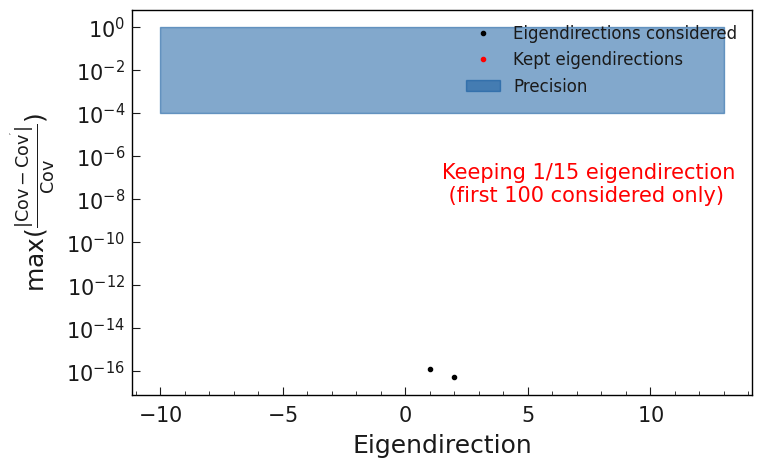

In [377]:
egd_track_mu.plot_cov_diff()

In [378]:
egd_track_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_mu.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/track_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/track_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/track_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of background in TBranch: channel1/background/track_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template continuum in TBranch: channel1/continuum/track_eff_v

In [379]:
df_mu["total_weight"] = df_mu["Btag_weight"]*df_mu["__weight__"]*df_mu["B_tracks"]

In [380]:
df_mu[["total_weight"]].describe()

,total_weight
count,3492.000000
mean,0.016209
std,0.052985
min,0.001605
25%,0.005694
50%,0.006485
75%,0.007269
max,0.389145


### PID systematics

In [381]:
import sys
print(sys.executable)
sys.path.insert(0,'../sysvar/src')
from sysvar.api import add_weights_to_dataframe, save_nominal_templates

/afs/desy.de/user/t/timmue/b2-plothist-env/bin/python


In [382]:
from IPython.display import HTML 

sys_path = 'systematic_corrections_framework/scripts'

sys.path.insert(1, sys_path)

import efficiency_table as et
import process_tables as pt
import show_db_content as sdb
import show_variables as sv
import id_vs_misid_curve as roc
import weight_table as wm

In [383]:
%pip install sly

Note: you may need to restart the kernel to use updated packages.


In [384]:
import show_db_content as sdb
ntuple_table_mu = sdb.show_db_content(type='html')
HTML(ntuple_table_mu)

INFO : info: 47 :  Successfully opened a DB connection to /data/dust/group/belle2/dataprod/Systematics/production/prod_log_db.csv!


In [385]:
var_table_mu = sv.show_ntuple_variables(particle_type='pi', 
                                     data_query=["MC16rd_p16_chunk4"], 
                                     type='html')
HTML(var_table_mu)

,Global PIDs,PID BDTs,CMS Frame,Detector hits,PID log(Likelihood),Track Isolation,Uncategorized
0,pionID,pidChargedBDTScore_K,cosThetaCMS,nCDCHits,pidLogLikelihoodOf2212FromKLM,minET2ETIsoScore,dz
1,deuteronIDNN,pidChargedBDTScore_e,pxCMS,nSVDHits,pidLogLikelihoodOf211FromCDC,,pt
2,protonID,pidChargedBDTScore_p,pCMS,nPXDHits,pidLogLikelihoodOf321FromSVD,,theta
3,electronID,pidChargedBDTScore_mu,ECMS,,pidLogLikelihoodOf13FromECL,,E
4,electronID_noTOP,pidChargedBDTScore_pi,pzCMS,,pidLogLikelihoodOf13FromTOP,,clusterE1E9
5,kaonID,pidPairChargedBDTScore_mu_pi,thetaCMS,,pidLogLikelihoodOf2212FromCDC,,clusterE
6,pionIDNN,pidPairChargedBDTScore_e_pi,ptCMS,,pidLogLikelihoodOf321FromARICH,,clusterEoP
7,protonIDNN,,pyCMS,,pidLogLikelihoodOf11FromARICH,,isSignal
8,muonID_noSVD,,phiCMS,,pidLogLikelihoodOf11FromTOP,,dr
9,electronID_noSVD_noTOP,,,,pidLogLikelihoodOf13FromARICH,,lastCDCLayer


In [386]:

from common_methods import DF_SCHEMES
for schema in DF_SCHEMES:
    print(schema, DF_SCHEMES[schema])

Dst  type: Weighted
Particles: ['K', 'pi']
Prefixes:  ['DST_D0_K', 'DST_D0_pi']
Constraints:
For K particle: nCDCHits > 20 and p > 0.3
For pi particle: nCDCHits > 20 and p > 0.1
Lambda0  type: Weighted
Particles: ['p', 'pi']
Prefixes:  ['Lambda0_p', 'Lambda0_pi']
Constraints:
For p particle: nCDCHits > 20 and p > 0.5
For pi particle: nCDCHits > 20 and p > 0.1 and p < 0.75
KShort  type: Weighted
Particles: ['pi', 'pi']
Prefixes:  ['KS_pi1', 'KS_pi2']
Constraints:
For pi particle: nCDCHits > 20 and p > 0.1
For pi particle: nCDCHits > 20 and p > 0.1
Jpsiee  type: Weighted
Particles: ['e', 'e']
Prefixes:  ['e0', 'e1']
Constraints:
For e particle: p > 1.5
For e particle: p > 1.5
Tag cuts:
For prefix e1_: e0_{variable} > 0.9
For prefix e0_: e1_{variable} > 0.9
Jpsimumu  type: Weighted
Particles: ['mu', 'mu']
Prefixes:  ['mu0', 'mu1']
Constraints:
For mu particle: p > 1.5
For mu particle: p > 1.5
Tag cuts:
For prefix mu1_: mu0_{variable} > 0.9
For prefix mu0_: mu1_{variable} > 0.9
Radmumu  ty

In [387]:
from sysvar import corrections

In [388]:
eID_corr_mu = corrections.CorrectionPID(systematic="eID_K_fake", MC_production="MC15rd")

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)


In [389]:
eID_corr_mu.build_queries()

['(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.321290147486383 <= theta < 2.6179430726579644 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 2.007108490286689 <= theta < 2.321290147486383 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.6754874619063092 <= theta < 2.007108490286689 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.3438532906163765 <= theta < 1.6754874619063092 & PDG == -11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <= theta < 1.3438532906163765 & PDG == 11 & mcPDG in [321, -321])',
 '(0.5 <= p < 0.9 & 1.0471975511965976 <=

In [390]:
eID_corr_mu.central_values

[1.2061084081330873,
 1.2587823373135034,
 1.2948594668822906,
 1.3398574201318558,
 0.8598448907493135,
 0.9396903673474464,
 0.8950503434220551,
 1.071877279636151,
 0.897169953876985,
 1.1328429845402306,
 0.9259375193071128,
 1.072227789402525,
 1.2324537370502624,
 1.309933578374879,
 2.1408689323689427,
 3.334676543509604,
 1.0804559494013122,
 1.4171563239654803,
 1.1017520873701163,
 1.173474677831335,
 0.8943867842081028,
 1.0450356355056565,
 0.9528071297614014,
 1.0897691814608237,
 0.8074288103940814,
 1.0411741410578512,
 0.9198685628643406,
 0.99374374376018,
 1.1030475320119888,
 0.8920019143563843,
 3.8505202574507713,
 4.001446628365155,
 2.148085142660209,
 2.166653673523171,
 1.088278109787026,
 1.2425249675873913,
 1.071581927436418,
 1.0611379830997856,
 0.906445919153308,
 1.5524687745425343,
 1.0205448856979435,
 1.0505382520942934,
 1.011790559859607,
 1.700660454877294,
 1.3561079243056506,
 1.251657003595103,
 1.5060617659816304,
 3.8112755441679953,
 1.114709

In [391]:
eID_corr_mu.table

,p_min,p_max,cosTheta_min,cosTheta_max,charge_min,charge_max,data_MC_ratio,data_MC_uncertainty_stat_up,data_MC_uncertainty_stat_dn,data_MC_uncertainty_sys_up,data_MC_uncertainty_sys_dn,data_efficiency,data_uncertainty_stat_up,data_uncertainty_stat_dn,data_uncertainty_sys_up,data_uncertainty_sys_dn,MC_efficiency,MC_uncertainty_stat_up,MC_uncertainty_stat_dn,MC_uncertainty_sys_up,MC_uncertainty_sys_dn,threshold,variable,working_point,is_best_available,theta_min,theta_max,charge,mcPDG
0,0.5,0.9,-0.8660,-0.6820,-2,0,1.206108,0.262942,0.262942,0.026090,0.026090,0.004734,0.001140,0.001140,0.000097,0.000097,0.003925,0.000414,0.000414,8.895745e-05,8.895745e-05,0.9,electronID,FixedThresh09,True,2.321290,2.617943,-,11
1,0.5,0.9,-0.8660,-0.6820,0,2,1.258782,0.183764,0.183764,0.014002,0.014002,0.007933,0.001262,0.001262,0.000066,0.000066,0.006302,0.000580,0.000580,1.379659e-04,1.379659e-04,0.9,electronID,FixedThresh09,True,2.321290,2.617943,+,-11
2,0.5,0.9,-0.6820,-0.4226,-2,0,1.294859,0.096071,0.096071,0.023108,0.023108,0.008017,0.000679,0.000679,0.000047,0.000047,0.006192,0.000281,0.000281,8.580556e-06,8.580556e-06,0.9,electronID,FixedThresh09,True,2.007108,2.321290,-,11
3,0.5,0.9,-0.6820,-0.4226,0,2,1.339857,0.095492,0.095492,0.025672,0.025672,0.008431,0.000710,0.000710,0.000087,0.000087,0.006292,0.000283,0.000283,1.554210e-04,1.554210e-04,0.9,electronID,FixedThresh09,True,2.007108,2.321290,+,-11
4,0.5,0.9,-0.4226,-0.1045,-2,0,0.859845,0.059016,0.059016,0.011197,0.011197,0.013967,0.000755,0.000755,0.000232,0.000232,0.016244,0.000385,0.000385,1.718155e-04,1.718155e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,-,11
5,0.5,0.9,-0.4226,-0.1045,0,2,0.939690,0.066818,0.066818,0.002471,0.002471,0.011751,0.000715,0.000715,0.000118,0.000118,0.012505,0.000345,0.000345,5.963684e-04,5.963684e-04,0.9,electronID,FixedThresh09,True,1.675487,2.007108,+,-11
6,0.5,0.9,-0.1045,0.2250,-2,0,0.895050,0.036522,0.036522,0.005671,0.005671,0.029871,0.000994,0.000994,0.000079,0.000079,0.033373,0.000501,0.000501,4.761595e-04,4.761595e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,-,11
7,0.5,0.9,-0.1045,0.2250,0,2,1.071877,0.041444,0.041444,0.008236,0.008236,0.024329,0.000904,0.000904,0.000116,0.000116,0.022697,0.000416,0.000416,3.625528e-04,3.625528e-04,0.9,electronID,FixedThresh09,True,1.343853,1.675487,+,-11
8,0.5,0.9,0.2250,0.5000,-2,0,0.897170,0.036895,0.036895,0.006720,0.006720,0.031951,0.001078,0.001078,0.000032,0.000032,0.035613,0.000533,0.000533,4.405714e-04,4.405714e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,-,11
9,0.5,0.9,0.2250,0.5000,0,2,1.132843,0.037339,0.037339,0.004157,0.004157,0.031649,0.001053,0.001053,0.000052,0.000052,0.027937,0.000473,0.000473,6.761617e-04,6.761617e-04,0.9,electronID,FixedThresh09,True,1.047198,1.343853,+,-11


In [392]:
df_mu["electron_PDG"] = df_mu["B_extraInfo_decayModeID"]
df_mu.loc[df_mu["electron_PDG"].isin([1]) & df_mu["B_mu_charge"].isin([-1]), "electron_PDG"] = 11
df_mu.loc[df_mu["electron_PDG"].isin([1]) & df_mu["B_mu_charge"].isin([1]), "electron_PDG"] = -11
#df[["electron_PDG"]==11] = df[["electron_PDG"]==1]
df_mu["electron_mcPDG"] = df_mu["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([-1]), "electron_mcPDG"] = -11
#df.loc[df["B_extraInfo_decayModeID"].isin([1]) & df["B_mu_charge"].isin([1]), "electron_mcPDG"] = 11
df_mu["electron_p"] = df_mu["B_mu_p"]
df_mu["electron_theta"] = np.arccos(df_mu["B_mu_cosTheta"])
df_mu=df_mu.copy()

In [393]:
df_mu["muon_PDG"] = df_mu["B_extraInfo_decayModeID"]
df_mu.loc[df_mu["muon_PDG"].isin([2]) & df_mu["B_mu_charge"].isin([-1]), "muon_PDG"] = 13
df_mu.loc[df_mu["muon_PDG"].isin([2]) & df_mu["B_mu_charge"].isin([1]), "muon_PDG"] = -13
#df[["muon_PDG"]==13] = df[["muon_PDG"]==2]
df_mu["muon_mcPDG"] = df_mu["B_mu_mcPDG"]
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([-1]), "muon_mcPDG"] = -13
#df.loc[df["B_extraInfo_decayModeID"].isin([2]) & df["B_mu_charge"].isin([1]), "muon_mcPDG"] = 13
df_mu["muon_p"] = df_mu["B_mu_p"]
df_mu["muon_theta"] = np.arccos(df_mu["B_mu_cosTheta"])
df_mu=df_mu.copy()

In [394]:
add_weights_to_dataframe(df_mu, correction_source="eID_eff", MC_production="MC15rd", prefix="electron", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_weight does not exist. Adding it to dataframe


In [395]:
add_weights_to_dataframe(df_mu, correction_source="muID_eff", MC_production="MC15rd", prefix="muon", weightname="weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_weight does not exist. Adding it to dataframe


In [396]:
df_mu.query("1.3 < electron_p < 1.7000000000000002")[["electron_theta", "electron_PDG", "muon_PDG", "electron_mcPDG", "muon_mcPDG", "electron_weight"]].head(20)

,electron_theta,electron_PDG,muon_PDG,electron_mcPDG,muon_mcPDG,electron_weight
247,0.652566,2.0,-13.0,-13.0,-13.0,1.0
508,0.878024,2.0,-13.0,211.0,211.0,1.0
36,0.466393,2.0,-13.0,NaN,NaN,1.0
43,0.609425,2.0,13.0,NaN,NaN,1.0
46,0.807266,2.0,-13.0,NaN,NaN,1.0
66,0.524252,2.0,-13.0,NaN,NaN,1.0
89,1.405174,2.0,-13.0,NaN,NaN,1.0
94,1.007112,2.0,-13.0,NaN,NaN,1.0
160,1.020739,2.0,-13.0,NaN,NaN,1.0
190,0.496933,2.0,13.0,NaN,NaN,1.0


In [397]:
df_mu[["electron_PDG", "electron_theta", "electron_mcPDG", "electron_p", "muon_PDG", "muon_theta", "muon_mcPDG", "muon_p", "B_mu_mcPDG"]].describe()

,electron_PDG,electron_theta,electron_mcPDG,electron_p,muon_PDG,muon_theta,muon_mcPDG,muon_p,B_mu_mcPDG
count,3492.0,3492.000000,100.000000,3492.000000,3492.000000,3492.000000,100.000000,3492.000000,100.000000
mean,2.0,1.279929,-8.440000,0.815658,-0.141466,1.279929,-8.440000,0.815658,-8.440000
std,0.0,0.486105,198.803305,0.316646,13.001092,0.486105,198.803305,0.316646,198.803305
min,2.0,0.302538,-211.000000,0.300212,-13.000000,0.302538,-211.000000,0.300212,-211.000000
25%,2.0,0.894420,-211.000000,0.560021,-13.000000,0.894420,-211.000000,0.560021,-211.000000
50%,2.0,1.263021,-13.000000,0.789011,-13.000000,1.263021,-13.000000,0.789011,-13.000000
75%,2.0,1.665446,211.000000,1.027472,13.000000,1.665446,211.000000,1.027472,211.000000
max,2.0,2.463836,211.000000,1.957407,13.000000,2.463836,211.000000,1.957407,211.000000


In [398]:
add_weights_to_dataframe(df_mu, correction_source="eID_K_fake", MC_production="MC15rd", prefix="electron", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_Kfake_weight does not exist. Adding it to dataframe


In [399]:
add_weights_to_dataframe(df_mu, correction_source="eID_pi_fake", MC_production="MC15rd", prefix="electron", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.56 and theta_max == 2.23) or (theta_min == 0.22 and theta_max == 2.71) or (p_min == 0.2 and p_max == 7) or (p_min == 0.2 and p_max == 5))) and (variable == 'electronID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  electron_pifake_weight does not exist. Adding it to dataframe


In [400]:
add_weights_to_dataframe(df_mu, correction_source="muID_K_fake", MC_production="MC15rd", prefix="muon", weightname="Kfake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_Kfake_weight does not exist. Adding it to dataframe


In [401]:
add_weights_to_dataframe(df_mu, correction_source="muID_pi_fake", MC_production="MC15rd", prefix="muon", weightname="pifake_weight", overwrite=True)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : add_weights_to_dataframe: 142 :  muon_pifake_weight does not exist. Adding it to dataframe


In [402]:
df_mu["muon_pifake_weight"].value_counts()

muon_pifake_weight
1.000000    3439
0.934481       6
0.703369       4
1.106469       4
0.933959       4
0.975543       4
0.999124       4
1.071700       3
0.926943       3
0.982351       3
0.821821       2
0.879487       2
0.844186       2
1.168278       2
0.873338       2
0.947165       2
0.872236       1
0.801843       1
0.665142       1
1.149203       1
0.755749       1
0.881617       1
Name: count, dtype: int64

In [403]:
df_mu.groupby([ "B_mu_mcPDG"])["electron_PDG"].value_counts(dropna=False)

B_mu_mcPDG  electron_PDG
-211.0      2.0             46
-13.0       2.0              6
 13.0       2.0              6
 211.0      2.0             42
Name: count, dtype: int64

In [404]:
df_mu.groupby([ "B_mu_mcPDG"])["muon_PDG"].value_counts(dropna=False)

B_mu_mcPDG  muon_PDG
-211.0       13.0       46
-13.0       -13.0        6
 13.0        13.0        6
 211.0      -13.0       42
Name: count, dtype: int64

In [405]:
df_mu.query("B_mu_mcPDG in [321, -321] and electron_PDG in [11, -11]")[["electron_theta", "electron_p"]]

,electron_theta,electron_p


In [406]:
df_mu["electron_weight"].describe()

count    3492.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: electron_weight, dtype: float64

In [407]:
df_mu["muon_weight"].describe()

count    3492.000000
mean        0.999999
std         0.000044
min         0.997425
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: muon_weight, dtype: float64

In [408]:
[x for x in df_mu.columns if "Theta" in x]

['B_cosThetaBetweenParticleAndNominalB',
 'B_mu_cosTheta',
 'Btag_cosThetaBetweenParticleAndNominalB',
 'thrustAxisCosTheta']

In [409]:
df_mu["B_mu_mcPDG"].value_counts(dropna=False)

B_mu_mcPDG
 NaN      3392
-211.0      46
 211.0      42
-13.0        6
 13.0        6
Name: count, dtype: int64

In [410]:
df_mu["__weight__"].value_counts(dropna=False)

__weight__
0.005694    3370
0.255383     122
Name: count, dtype: int64

In [411]:
df_mu.groupby([ "__weight__"])["template"].value_counts(dropna=False)

__weight__  template  
0.005694    signMC        3319
            background      51
0.255383    background     103
            continuum       19
Name: count, dtype: int64

In [412]:
egd_mu_mu = eigendecompose(
    df = df_mu,
    settings = cfg_mu,
    systematic_source = "muID_eff",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_eff",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates:

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

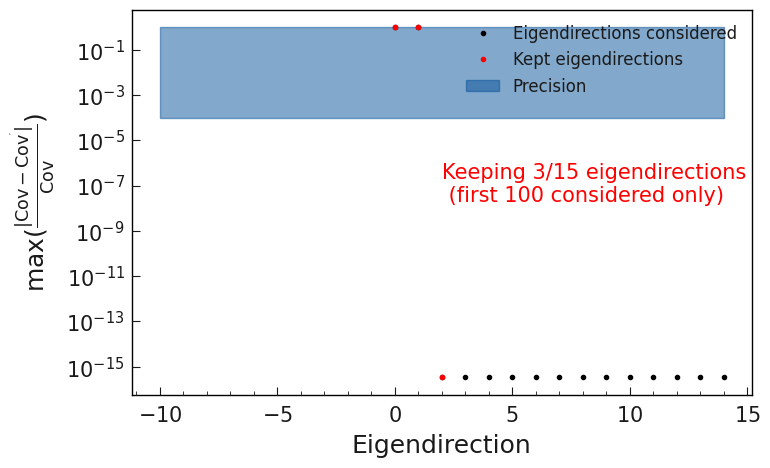

In [413]:
egd_mu_mu.plot_cov_diff()

In [414]:
egd_mu_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_mu.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_eff_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/mu_eff_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_eff_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/mu_eff_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_eff_var3_up
INFO : save_template_variation

In [415]:
egd_pifake_mu_mu = eigendecompose(
    df = df_mu,
    settings = cfg_mu,
    systematic_source = "muID_pi_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_pifake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates:

In [416]:
egd_Kfake_mu_mu = eigendecompose(
    df = df_mu,
    settings = cfg_mu,
    systematic_source = "muID_K_fake",
    #cov_matrix_path = "../FEI_cal_covariance_Bp_sigProb_0_001.tsv",
    #syst_effect = "fei_Bp"
    title = "mu_Kfake",
    #max_variations= int,
    #seed = int,
    #criterion: "max_differences",
    #prc: 0.005,
    #save_variations: False
)

INFO : load_covariance_matrix: 170 :  'cov_matrix' is None in config. No covariance matrix will be loaded.
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : get_lid_queries: 2110 :  The following cutstring has been applied to the provide LID table: (working_point == 'FixedThresh09') and (is_best_available == True) and (not ((theta_min == 0.82 and theta_max == 2.22) or (theta_min == 0.4 and theta_max == 0.82) or (theta_min == 0.4 and theta_max == 2.6) or (p_min == 0.2 and p_max == 5))) and (variable == 'muonID') and (0 < data_MC_ratio < 10)
INFO : create_templates: 184 :  ########## Reco channel: channel1 ##########
INFO : create_templates:

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

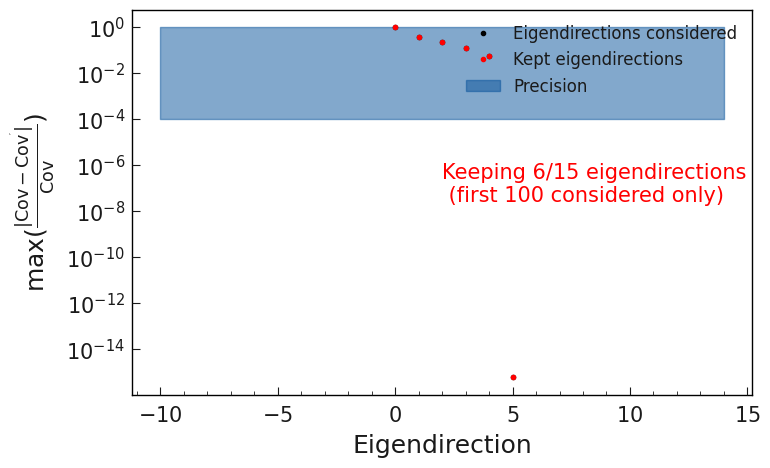

In [417]:
egd_pifake_mu_mu.plot_cov_diff()

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='Eigendirection', ylabel="max($\\frac{|Cov - Cov^{'}|}{Cov}$)">)

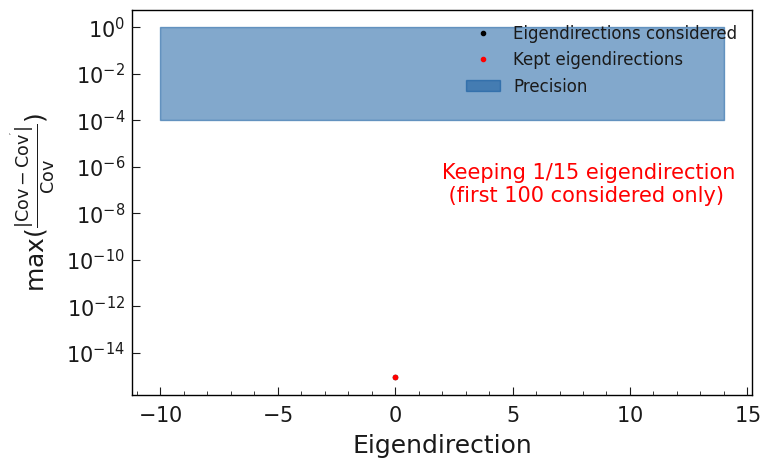

In [418]:
egd_Kfake_mu_mu.plot_cov_diff()

In [419]:
egd_pifake_mu_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_mu.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_pifake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/mu_pifake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_pifake_var2_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/mu_pifake_var2_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_pifake_var3_up
INFO : save_tem

In [420]:
egd_Kfake_mu_mu.save_template_variations()

INFO : save_template_variations: 347 :  Updating file with uproot: ./pyhf/test_output_mu.root
INFO : save_template_variations: 359 :  ##################################################
INFO : save_template_variations: 360 :  ########## Reco channel: channel1 ##########
INFO : save_template_variations: 361 :  ##################################################
INFO : save_template_variations: 372 :  Saving Up variation of MC template signMC in TBranch: channel1/signMC/mu_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of signMC in TBranch: channel1/signMC/mu_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template background in TBranch: channel1/background/mu_Kfake_var1_up
INFO : save_template_variations: 383 :  Saving Down variation of background in TBranch: channel1/background/mu_Kfake_var1_down
INFO : save_template_variations: 372 :  Saving Up variation of MC template continuum in TBranch: channel1/continuum/mu_Kfake_var1_u

In [421]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["electron_weight"]*df["electron_Kfake_weight"]*df["electron_pifake_weight"]
mask_e_mu = df_mu["B_extraInfo_decayModeID"] == 1
df_mu.loc[mask_e_mu, "total_weight"] = (
    df_mu.loc[mask_e_mu, "Btag_weight"]
    * df_mu.loc[mask_e_mu, "__weight__"]
    * df_mu.loc[mask_e_mu, "B_tracks"]
    * df_mu.loc[mask_e_mu, "electron_weight"]
    * df_mu.loc[mask_e_mu, "electron_Kfake_weight"]
    * df_mu.loc[mask_e_mu, "electron_pifake_weight"]
)

In [422]:
#df["total_weight"] = df["Btag_weight"]*df["__weight__"]*df["B_tracks"]*df["muon_weight"]*df["muon_Kfake_weight"]*df["muon_pifake_weight"]
mask_mu_mu = df_mu["B_extraInfo_decayModeID"] == 2
df_mu.loc[mask_mu_mu, "total_weight"] = (
    df_mu.loc[mask_mu_mu, "Btag_weight"]
    * df_mu.loc[mask_mu_mu, "__weight__"]
    * df_mu.loc[mask_mu_mu, "B_tracks"]
    * df_mu.loc[mask_mu_mu, "muon_weight"]
    * df_mu.loc[mask_mu_mu, "muon_Kfake_weight"]
    * df_mu.loc[mask_mu_mu, "muon_pifake_weight"]
)

# Apply Tighter Selection

In [423]:
dfs = {"total": df,
      "e": df_e,
      "mu": df_mu,
}

datas = dfs
data = df

## Lepton Selection

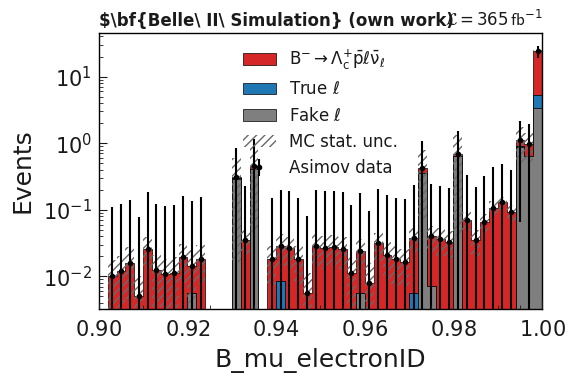

In [424]:
name = "B_mu_electronID"
variable = get_variable_from_registry(name)
name = variable["name"]
bins = variable["bins"]
x_range = variable["range"]
x_label = variable["label"]

#print(name, x_range)
if x_range[0] == "min":
    x_min = data[name].min()
else:
    x_min = x_range[0]

if x_range[1] == "max":
    x_max = data[name].max()
else:
    x_max = x_range[1]

range_query = f"{x_min} <= {name} < {x_max} and (B_extraInfo_decayModeID == {1})"
#range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {1})"

d = data.query(range_query)[[name, weight_column]]
x1 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
x2 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal == 1")[[name, weight_column]]
x3 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal != 1")[[name, weight_column]]

#d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
#h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
#h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
#h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
#d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

d0_asimov = d0.copy()
view = d0_asimov.view()
view.variance = view.value

fig, ax_main, ax_comparison = plot_data_model_comparison(
    data_hist=d0_asimov,
    stacked_components=[h3, h2, h1],
    stacked_labels=[r"Fake $\ell$", r"True $\ell$", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
    stacked_colors=["tab:grey", "tab:blue", "tab:red"],
    xlabel=x_label,
    model_uncertainty_label="MC stat. unc.",
    ylabel="Events",
    #comparison="pull",
    data_uncertainty_type="symmetrical",
    data_label="Asimov data"
)

xticks = ax_comparison.get_xticks()
xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]

ax_main.set_xticks(xticks)
ax_main.set_xticklabels(xticklabels)
        
ax_comparison.remove()
fig.subplots_adjust(hspace=0)

ax_main.tick_params(axis="x", which="both", labelbottom=True)
#ax_main.xaxis.set_visible(True)
ax_main.set_xlabel(x_label)
    
# remove Data label
handles, labels = ax_main.get_legend_handles_labels()
handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
if variable["log"]:
    ax_main.set_yscale("log")
ax_main.legend() #handles, labels)
add_text(r"$\bf{Belle\ II\ Simulation} (own work)", weight="bold", ax=ax_main)
add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main)

#fig.savefig("B_mu_electronID.svg", bbox_inches="tight")
plt.tight_layout()
plt.show()
plt.close()

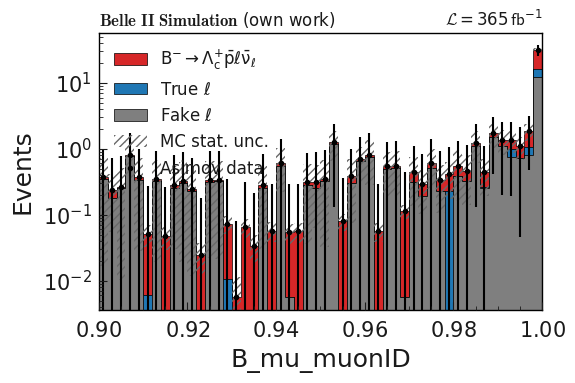

In [425]:
name = "B_mu_muonID"
variable = get_variable_from_registry(name)
name = variable["name"]
bins = variable["bins"]
x_range = variable["range"]
x_label = variable["label"]

#print(name, x_range)
if x_range[0] == "min":
    x_min = data[name].min()
else:
    x_min = x_range[0]

if x_range[1] == "max":
    x_max = data[name].max()
else:
    x_max = x_range[1]

range_query = f"{x_min} <= {name} < {x_max} and (B_extraInfo_decayModeID == {2})"
#range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {2})"

d = data.query(range_query)[[name, weight_column]]
x1 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
x2 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal == 1")[[name, weight_column]]
x3 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal != 1")[[name, weight_column]]

#d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
#h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
#h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
#h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
#d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

d0_asimov = d0.copy()
view = d0_asimov.view()
view.variance = view.value

fig, ax_main, ax_comparison = plot_data_model_comparison(
    data_hist=d0_asimov,
    stacked_components=[h3, h2, h1],
    stacked_labels=[r"Fake $\ell$", r"True $\ell$", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
    stacked_colors=["tab:grey", "tab:blue", "tab:red"],
    xlabel=x_label,
    model_uncertainty_label="MC stat. unc.",
    ylabel="Events",
    #comparison="pull",
    data_uncertainty_type="symmetrical",
    data_label="Asimov data"
)

xticks = ax_comparison.get_xticks()
xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]

ax_main.set_xticks(xticks)
ax_main.set_xticklabels(xticklabels)
        
ax_comparison.remove()
fig.subplots_adjust(hspace=0)

ax_main.tick_params(axis="x", which="both", labelbottom=True)
#ax_main.xaxis.set_visible(True)
ax_main.set_xlabel(x_label)
    
# remove Data label
handles, labels = ax_main.get_legend_handles_labels()
handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
if variable["log"]:
    ax_main.set_yscale("log")
ax_main.legend() #handles, labels)
add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main)

#fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
plt.tight_layout()
plt.show()
plt.close()

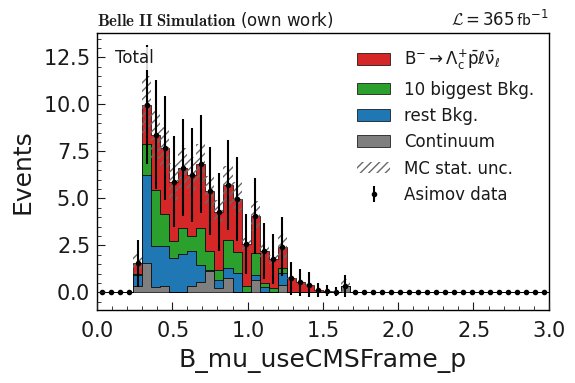

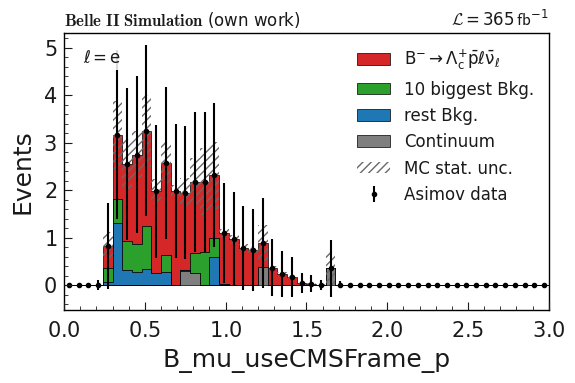

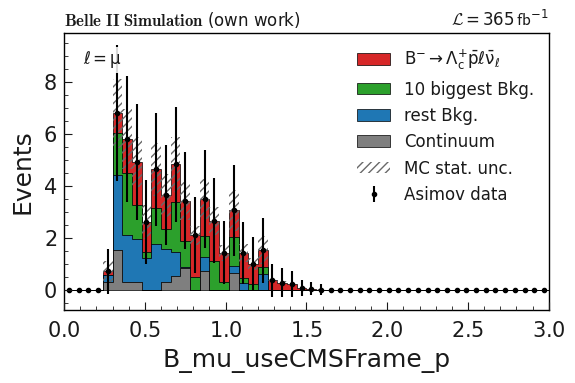

In [426]:
for key, df_current in dfs.items():
    #for channel in [1, 2]:
        
    name = "B_mu_useCMSFrame_p"
    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]

    label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    range_query = f"{x_min} <= {name} < {x_max}" #and (B_extraInfo_decayModeID == {channel})"
    #range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {channel})"
    
    d = datas[key].query(range_query)[[name, weight_column]]
    x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2top = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x2rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]

    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
    h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2rest, h2top, h1],
        stacked_labels=["Continuum", "rest Bkg.", "10 biggest Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )

    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)

    
    # remove Data label
    handles, labels = ax_main.get_legend_handles_labels()
    handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
    ax_main.legend()
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    
    #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    plt.close()

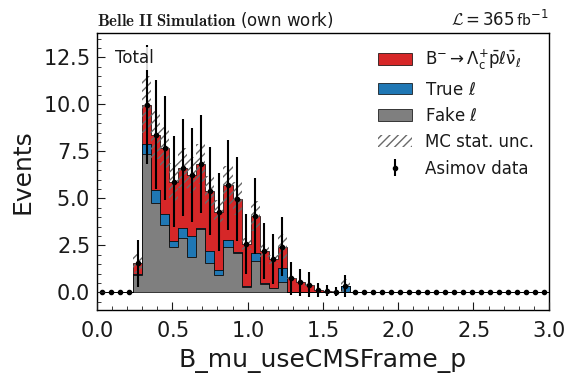

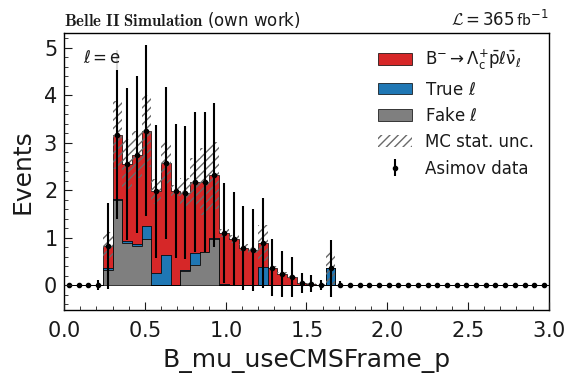

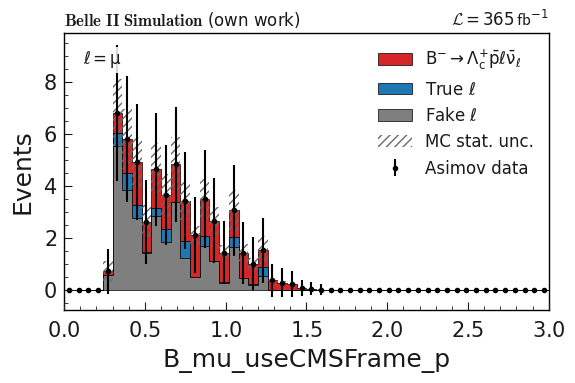

In [427]:
for key, df_current in dfs.items():
#for channel in [1, 2]:
        
    name = "B_mu_useCMSFrame_p"
    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]
    
    

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    #if channel == 1:
    #    index = "e"
    #else:
    #    index = "mu"
    
    
    label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
    
    range_query = f"{x_min} <= {name} < {x_max}"# and (B_extraInfo_decayModeID == {channel})"
    #range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {channel})"
    
    d = datas[key].query(range_query)[[name, weight_column]]
    x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2top = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal == 1")[[name, weight_column]]
    #x2rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal == 1")[[name, "__weight__"]]
    x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal != 1")[[name, weight_column]]
    #x3rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal != 1")[[name, "__weight__"]]
    
    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
    #h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest["__weight__"])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2top, h1],
        stacked_labels=[r"Fake $\ell$", r"True $\ell$", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )

    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)
    
    # remove Data label
    handles, labels = ax_main.get_legend_handles_labels()
    handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
    ax_main.legend() #handles, labels)
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    
    #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    plt.close()

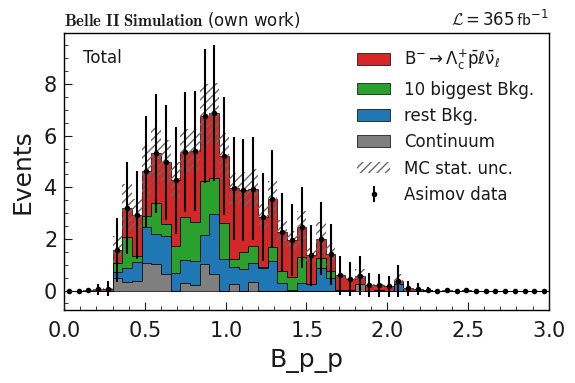

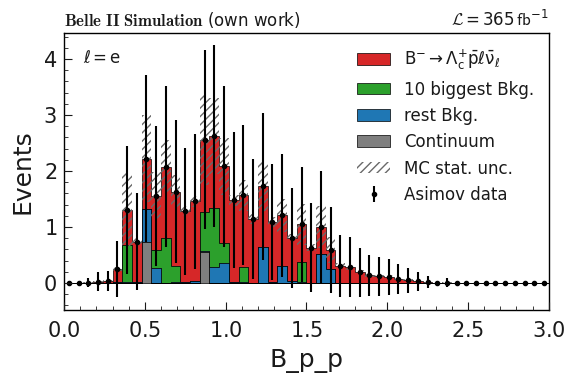

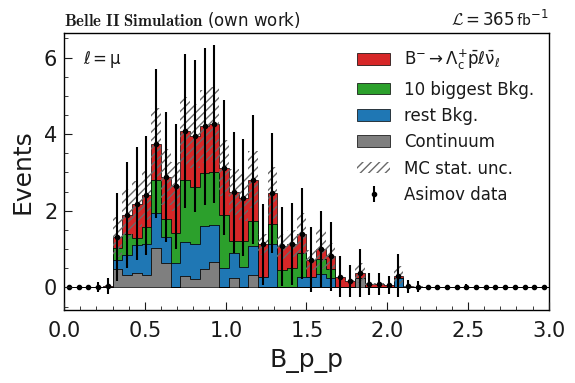

In [428]:
for key, df_current in dfs.items():
#for channel in [1, 2]:
    
    name = "B_p_p"
    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]

    #if channel == 1:
    #    index = "e"
    #else:
    #    index = "mu"

    label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    range_query = f"{x_min} <= {name} < {x_max}" #and (B_extraInfo_decayModeID == {channel})"
    #range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {channel})"
    
    d = datas[key].query(range_query)[[name, weight_column]]
    x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2top = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x2rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]

    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
    h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2rest, h2top, h1],
        stacked_labels=["Continuum", "rest Bkg.", "10 biggest Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )

    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)

    
    # remove Data label
    handles, labels = ax_main.get_legend_handles_labels()
    handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])


    
    ax_main.legend() #handles, labels)
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))

    #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    plt.close()

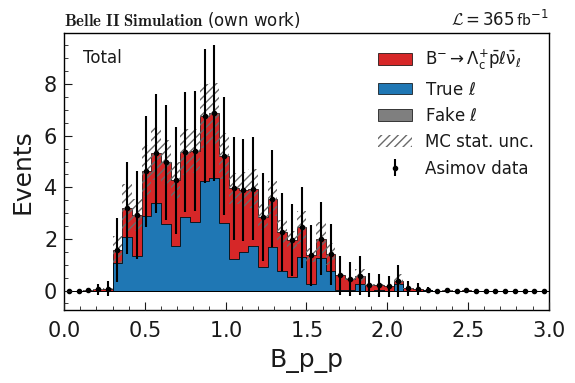

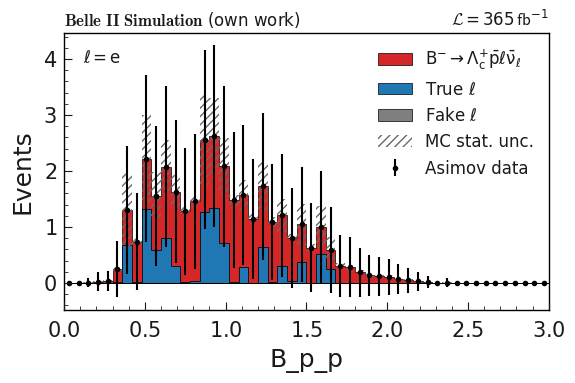

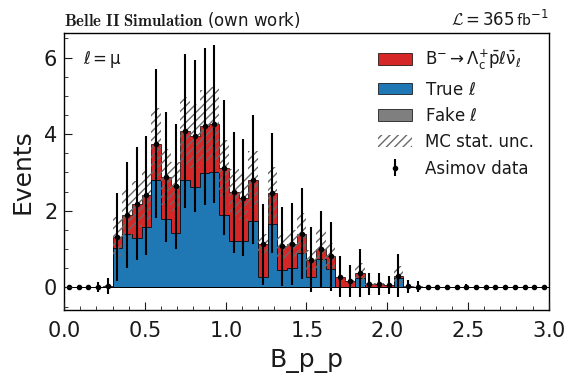

In [429]:
for key, df_current in dfs.items():
#for channel in [1, 2]:
    
    name = "B_p_p"
    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]

    #if channel == 1:
    #    index = "e"
    #else:
    #    index = "mu"

    label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    range_query = f"{x_min} <= {name} < {x_max}" #and (B_extraInfo_decayModeID == {channel})"
    #range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {channel})"
    
    d = datas[key].query(range_query)[[name, weight_column]]
    x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2top = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_p_isSignal == 1")[[name, weight_column]]
    #x2rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
    x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_p_isSignal != 1")[[name, weight_column]]
    #x4 = df.query(range_query).query("B_isSignalAcceptMissing != 1 and B_p_isSignal != 1")[[name, "__weight__"]]

    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
    #h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest["__weight__"])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2top, h1],
        stacked_labels=[r"Fake $\ell$", r"True $\ell$", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )

    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)
    
    # remove Data label
    handles, labels = ax_main.get_legend_handles_labels()
    handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
    ax_main.legend() #handles, labels)
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    
    #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    plt.close()

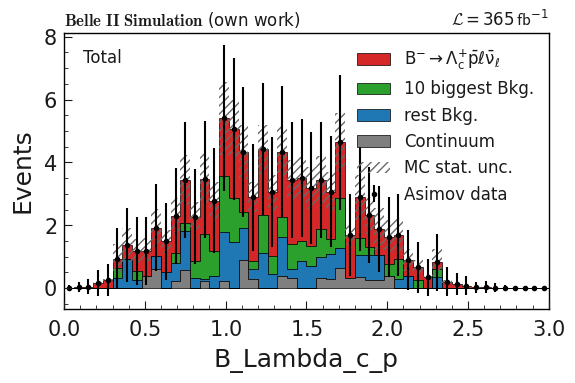

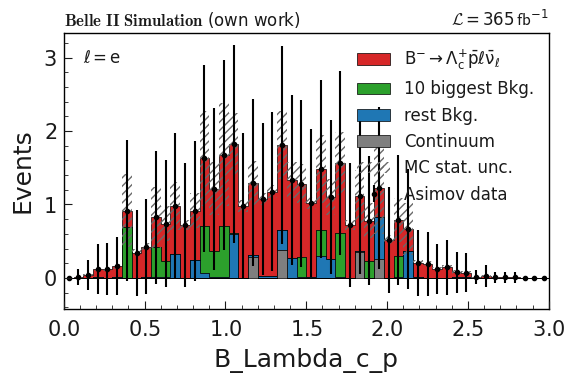

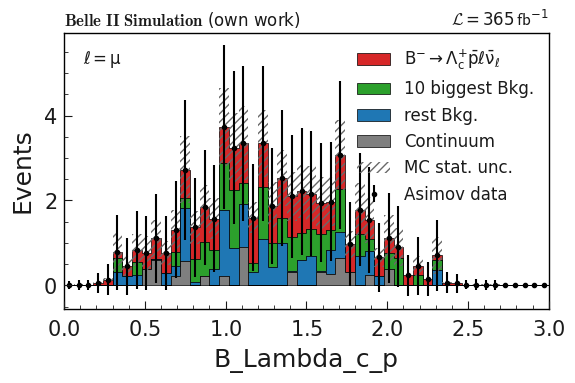

In [430]:
for key, df_current in dfs.items():
#for channel in [1, 2]:
    
    name = "B_Lambda_c_p"
    variable = get_variable_from_registry(name)
    name = variable["name"]
    bins = variable["bins"]
    x_range = variable["range"]
    x_label = variable["label"]

    #if channel == 1:
    #    index = "e"
    #else:
    #    index = "mu"

    label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}

    #print(name, x_range)
    if x_range[0] == "min":
        x_min = data[name].min()
    else:
        x_min = x_range[0]

    if x_range[1] == "max":
        x_max = data[name].max()
    else:
        x_max = x_range[1]

    range_query = f"{x_min} <= {name} < {x_max}" # and (B_extraInfo_decayModeID == {channel})"
    #range_query = f"{x_range[0]} <= {name} < {x_range[1]} and (B_extraInfo_decayModeID == {channel})"
    
    d = datas[key].query(range_query)[[name, weight_column]]
    x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
    x2top = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x2rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
    x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]

    #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
    #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
    #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
    #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)

    d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
    #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
    h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
    h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
    h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
    h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

    d0_asimov = d0.copy()
    view = d0_asimov.view()
    view.variance = view.value
    
    fig, ax_main, ax_comparison = plot_data_model_comparison(
        data_hist=d0_asimov,
        stacked_components=[h3, h2rest, h2top, h1],
        stacked_labels=["Continuum", "rest Bkg.", "10 biggest Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
        stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
        xlabel=x_label,
        model_uncertainty_label="MC stat. unc.",
        ylabel="Events",
        #comparison="pull",
        data_uncertainty_type="symmetrical",
        data_label="Asimov data"
    )


    xticks = ax_comparison.get_xticks()
    xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
    
    ax_main.set_xticks(xticks)
    ax_main.set_xticklabels(xticklabels)
            
    ax_comparison.remove()
    fig.subplots_adjust(hspace=0)

    ax_main.tick_params(axis="x", which="both", labelbottom=True)
    #ax_main.xaxis.set_visible(True)
    ax_main.set_xlabel(x_label)
    
    # remove Data label
    handles, labels = ax_main.get_legend_handles_labels()
    handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])

    
    ax_main.legend() #handles, labels)
    add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
    add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
    ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))

    #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    plt.close()

In [431]:
print("These selection are moved to online")
# print(df.B_isSignalAcceptMissing.value_counts())
# df = apply_cut(df, "(extraInfo__bodecayModeID__bc == 1 and mu_p > 0.3) or (extraInfo__bodecayModeID__bc == 2 and mu_p > 0.6)", N_SIGNAL, N_BACKGROUND)
# df = apply_cut(df, "2.2 < Lambda_c_InvM < 2.4", N_SIGNAL, N_BACKGROUND)
#df = apply_cut(df, "Lambda_c_useCMSFrame_p < 3.0", N_SIGNAL, N_BACKGROUND)
#df = apply_cut(df, "p_useCMSFrame_p < 3.0", N_SIGNAL, N_BACKGROUND)
#df = apply_cut(df, "roeMbc__bo__bc > 5.0", N_SIGNAL, N_BACKGROUND)
#df = apply_cut(df, "roeDeltae__bo__bc < 2.0", N_SIGNAL, N_BACKGROUND)

# print(df.B_isSignalAcceptMissing.value_counts())
# 
# data = apply_cut(data, "(extraInfo__bodecayModeID__bc == 1 and mu_p > 0.3) or (extraInfo__bodecayModeID__bc == 2 and mu_p > 0.6)", isData=True)
# data = apply_cut(data, "2.2 < Lambda_c_InvM < 2.4", isData=True)
#data = apply_cut(data, "Lambda_c_useCMSFrame_p < 3.0", isData=True)
#data = apply_cut(data, "p_useCMSFrame_p < 3.0", isData=True)

#data = apply_cut(data, "roeMbc__bo__bc > 5.0", isData=True)
#data = apply_cut(data, "roeDeltae__bo__bc < 2.0", isData=True)

These selection are moved to online


## Vertex Selection

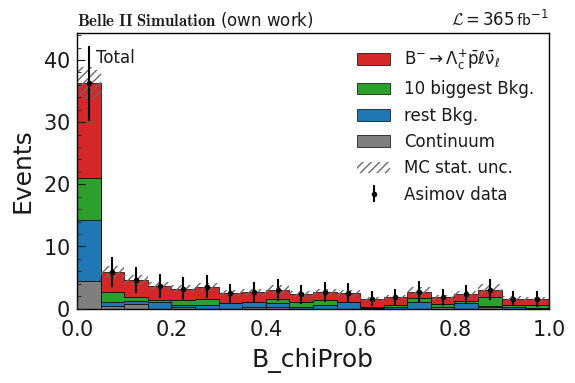

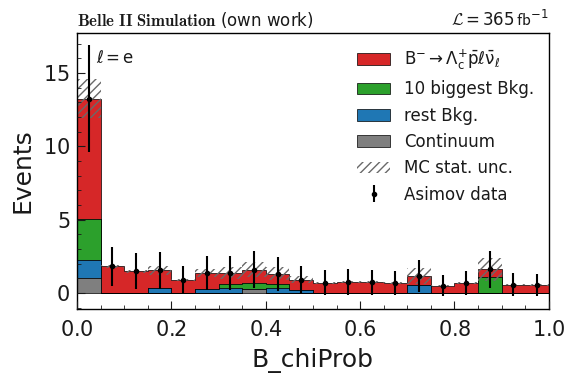

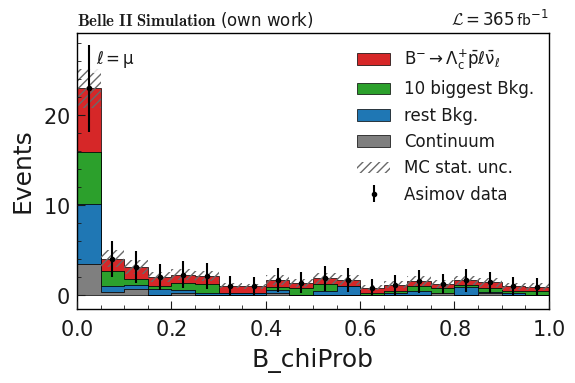

In [542]:
for key, df_current in dfs.items():
    for name in ["B_chiProb"]:
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2top = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ({conditions[key]})")[[name, weight_column]]
        x2rest = df_current.query(range_query).query(f"B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1 and ~({conditions[key]})")[[name, weight_column]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2top = make_hist(x2top[name], bins=bins, range=(x_min, x_max), weights=x2top[weight_column])
        h2rest = make_hist(x2rest[name], bins=bins, range=(x_min, x_max), weights=x2rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2rest, h2top, h1],
            stacked_labels=["Continuum", r"rest Bkg.", "10 biggest Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
            stacked_colors=["tab:grey", "tab:blue", "tab:green", "tab:red"],
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel="Events",
            #comparison="pull",
            data_uncertainty_type="symmetrical",
            data_label="Asimov data"
        )

        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)
        
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
        
        ax_main.legend() #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        plt.show()
        plt.close()

In [433]:
print("These selection are moved to online")
# print(df.B_isSignalAcceptMissing.value_counts())
# df = apply_cut(df, "chiProb > 0.001", N_SIGNAL, N_BACKGROUND)
# print(df.B_isSignalAcceptMissing.value_counts())
# 
# data = apply_cut(data, "chiProb > 0.001", isData=True)

These selection are moved to online


## Signal Region and Sideband Region Definition

In [434]:
fei_labels = {
    0: r"$\overline{D}^0 \pi^+$",
    1: r"$\overline{D}^0 \pi^+ \pi^0$",
    2: r"$\overline{D}^0 \pi^+ \pi^0 \pi^0$",
    3: r"$\overline{D}^0 \pi^+ \pi^+ \pi^-$",
    4: r"$\overline{D}^0 \pi^+ \pi^+ \pi^- \pi^0$",
    5: r"$\overline{D}^0 D^+$",
    6: r"$\overline{D}^0 D^+ K^0_S$",
    7: r"$\overline{D}^{0*} D^+ K^0_S$",
    8: r"$\overline{D}^0 D^{+*} K^0_S$",
    9: r"$\overline{D}^{0*} D^{+*} K^0_S$",
    10: r"$\overline{D}^0 D^0 K^+$",
    11: r"$\overline{D}^{0*} D^0 K^+$",
    12: r"$\overline{D}^0 D^{0*} K^+$",
    13: r"$\overline{D}^{0*} D^{0*} K^+$",
    14: r"$D^+_s \overline{D}^0$",
    15: r"$\overline{D}^{0*} \pi^+$",
    16: r"$\overline{D}^{0*} \pi^+ \pi^0$",
    17: r"$\overline{D}^{0*} \pi^+ \pi^0 \pi^0$",
    18: r"$\overline{D}^{0*} \pi^+ \pi^+ \pi^-$",
    19: r"$\overline{D}^{0*} \pi^+ \pi^+ \pi^- \pi^0$",
    20: r"$D^{+*}_s \overline{D}^0$",
    21: r"$D^+_s \overline{D}^{0*}$",
    22: r"$\overline{D}^0 K^+$",
    23: r"$D^- \pi^+ \pi^+$",
    24: r"$D^- \pi^+ \pi^+ \pi^0$",
    25: r"$J/\psi K^+$",
    26: r"$J/\psi K^+ \pi^+ \pi^-$",
    27: r"$J/\psi K^+ \pi^0$",
    28: r"$J/\psi K^0_S \pi^+$",
    29: r"$\Lambda^{-}_{c} p \pi^+ \pi^0$",
    30: r"$\Lambda^{-}_{c} p \pi^+ \pi^- \pi^+$",
    31: r"$\overline{D}^0 p \bar{p} \pi^+$",
    32: r"$\overline{D}^{0*} p \bar{p} \pi^+$",
    33: r"$D^+ p \bar{p} \pi^+ \pi^-$",
    34: r"$D^{+*} p \bar{p} \pi^+ \pi^-$",
    35: r"$\Lambda^{-}_{c} p \pi^+$",
    -1: "Rest",
}


## Main plots

In [435]:
df[["channel", "template", "B_extraInfo_decayModeID", "B_isSignalAcceptMissingNeutrino", "isContinuumEvent", "total_weight", "__weight__"]].head(50)

,channel,template,B_extraInfo_decayModeID,B_isSignalAcceptMissingNeutrino,isContinuumEvent,total_weight,__weight__
3,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.255383,0.255383
5,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.255383,0.255383
14,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.071997,0.255383
21,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.179629,0.255383
26,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.238651,0.255383
27,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.255383,0.255383
32,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.391477,0.255383
33,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.273694,0.255383
51,B_to_Lambda_c_plnu_mu,background,2.0,NaN,False,0.318942,0.255383
58,B_to_Lambda_c_plnu_mu,background,2.0,0.0,False,0.326001,0.255383


In [436]:
def calculate_significance(signal_hist, bkg_hists):
    """
    Berechnet S/sqrt(B) basierend auf Histogramm-Inhalten.
    signal_hist: Das h1 (Signal)
    bkg_hists: Liste aller Untergrund-Hists [h2_top10, h2_rest, h3]
    """
    # 1. Summe der Gewichte für Signal (S)
    # Falls h1 ein Objekt mit .values() ist, sonst np.sum(h1)
    S = signal_hist.values().sum() 
    
    # 2. Summe der Gewichte für alle Untergründe (B)
    B = sum([h.values().sum() for h in bkg_hists])
    
    # 3. Signifikanz berechnen
    if S+B > 0:
        return S / np.sqrt(S+B)
    else:
        return 0



In [437]:
further_variables = [
    #"nROE_Charged__bo__bc", 
    
    #'InvM',
    
    "m2RecoilSignalSide", 
    #"B_Lambda_c_InvM", 
    
    #"B_InvM",
    
    #"Btag_extraInfo_decayModeID",
    #'B_Mbc', 
    #'B_deltaE',

    #'Btag_Mbc',
    #'Btag_deltaE'
    
    #'B_InvM',
    #'B_daughterInvariantMass_0_1',
    #'B_daughterInvariantMass_0_2',
    #'B_daughterInvariantMass_1_2',
]

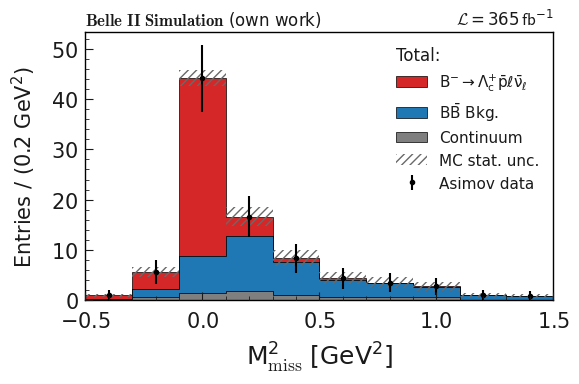

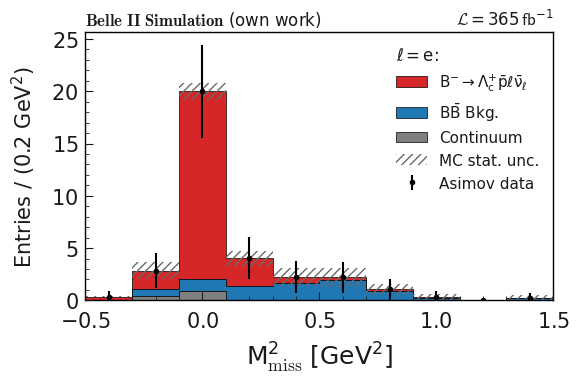

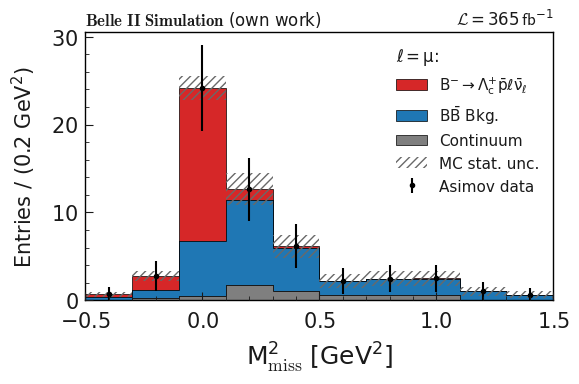

In [438]:
top10_ids = df_Bp_counts.head(10)["iDcyBrP"].tolist()
#print(top10_ids)
import re


#weight_column ="total_weight"
for key, df_current in dfs.items():
    
    for name in further_variables:
    
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #has_data = data is not None and len(data) > 0
        
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
        #print(name, x_range, x_min, x_max, bins)


        
        if isinstance(bins, int):
            raw_width = (x_max - x_min) / bins
            # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
            bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
        else:
            # Falls 'bins' eine Liste/ein Array für variable Bin-Breiten ist
            bin_width_str = "Variable"

        # 2. Einheit aus dem x_label extrahieren (sucht nach Text in [...] Klammern)
        # Findet z.B. "GeV/c²" aus "M(pKπ) [GeV/c²]"
        unit_match = re.search(re.compile(r"\[(.*?)\]"), x_label)
        unit_str = unit_match.group(1) if unit_match else ""

        # 3. Label textuell zusammenbauen
        if bin_width_str == "Variable":
            dynamic_ylabel = "Entries / Variable Bin"
        elif unit_str:
            # Wenn eine Einheit existiert, z.B.: Entries / (0.02 GeV/c²)
            dynamic_ylabel = f"Entries / ({bin_width_str} {unit_str})"
        else:
            # Wenn die Variable ein reiner Counter ohne Einheit ist
            dynamic_ylabel = f"Entries / {bin_width_str}"
    
        
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df.query(range_query).query(f"iDcyBrP_Bp_0 in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        #x2_rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_rest = df.query(range_query).query(f"iDcyBrP_Bp_0 not in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
        #x3 = continuum
        
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
        #h2_top10 = make_hist(x2_top10[name], bins=bins, range=(x_min, x_max), weights=x2_top10[weight_column])
        #h2_rest = make_hist(x2_rest[name], bins=bins, range=(x_min, x_max), weights=x2_rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value

        
        #comparison_mode = "pull" if has_data else None
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2, h1], #h2_rest, h2_top10
            stacked_labels=["Continuum", r"$B\bar{B}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"], #r"Rest $B\bar{B}$ Bkg.", r"10 biggest $B\bar{B}$ Bkg."
            stacked_colors=["tab:grey", "tab:blue", "tab:red"], #"tab:green",
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel=dynamic_ylabel,
            #comparison="pull",
            data_uncertainty_type="symmetrical", #if has_data else None
            data_label="Asimov data",
        )# r"$B\bar{B}$





        
        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)

        '''
        if name == "Btag_extraInfo_decayModeID":
            ax_comparison.set_xticks(range(34), [fei_labels[i] for i in range(34)], rotation=90, fontsize=8)
            ax_comparison.minorticks_off()
        '''
        
        
        if name == "B_Lambda_c_InvM":
            ax_main.axvline(
                x=2.28,
                linestyle="--",
                linewidth=1.5,
                color="orange",
            )
            ax_main.axvline(
                x=2.295,
                linestyle="--",
                linewidth=1.5,
                color="orange",
                label="Mass cut",
            )
        
        '''
        if name == "B_Lambda_c_InvM":
            # Beispielaufruf für den aktuellen Zustand deiner Histogramme:
            sig_value = calculate_significance(h1, [h2_top10, h2_rest, h3])
            print(f"Significance: {sig_value:.4f}")
        '''
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
    
        if name == 'Btag_Mbc' or name == 'Btag_deltaE':
            leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=11)
        else:
            leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, fontsize=11) #handles, labels)
        #ax_main.legend()
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        #add_text(f"    {label_map[key]}", x="left", y="top_in", ax=ax_main)
        leg._legend_box.align = "left"
        ax_main.yaxis.label.set_size(15)
        '''
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 11}, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=10) #handles, labels)
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        leg._legend_box.align = "left"
        '''

        ax_main.set_ylim(bottom=0)
        
        if name == 'Btag_Mbc' or name == 'Btag_deltaE':
            orig_width, orig_height = fig.get_size_inches()
            fig.set_size_inches(orig_width + 1.5, orig_height)
    
        fig.savefig(f"graphs/{key}/{name}_{key}.png", bbox_inches="tight", dpi=300)  
        fig.savefig(f"graphs/{key}/{name}_{key}.svg", bbox_inches="tight")  
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        #plt.grid()
        plt.show()
        plt.close()

In [439]:
bins = [-0.5, -0.1, 0, 0.1, 0.2, 0.3, 0.7, 1.1]

subset = df[(df["B_isSignalAcceptMissingNeutrino"] == 1) & (df["B_extraInfo_decayModeID"]==1)]

hist, edges = np.histogram(subset["m2RecoilSignalSide"], bins=bins, weights=subset["total_weight"])

print(hist)
print(edges)

[ 2.06566564  7.45990505 10.46329072  1.84630778  0.75934325  0.83499318
  0.23309941]
[-0.5 -0.1  0.   0.1  0.2  0.3  0.7  1.1]


/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/plothist/histogramming.py:148: UserWarning: Custom binning -> ignore supplied range ((-0.5, 1.5)).
  axis = create_axis(bins, range, data)
/tmp/ipykernel_1463035/74998536.py:80: RangeWarning: Only 97.84% of data contained in the binning range [-0.5, 1.1].
  d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
/tmp/ipykernel_1463035/74998536.py:83: RangeWarning: Only 94.93% of data contained in the binning range [-0.5, 1.1].
  h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])


Significance: 4.7849


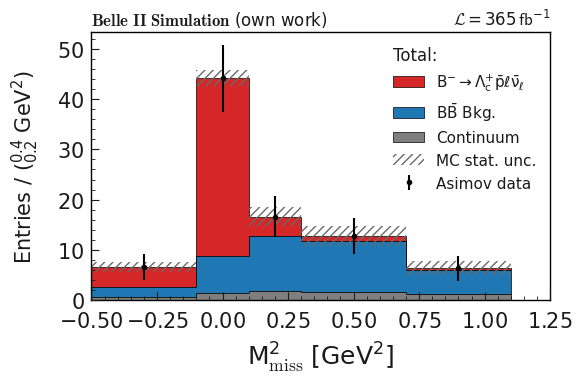

/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/plothist/histogramming.py:148: UserWarning: Custom binning -> ignore supplied range ((-0.5, 1.5)).
  axis = create_axis(bins, range, data)
/tmp/ipykernel_1463035/74998536.py:83: RangeWarning: Only 97.11% of data contained in the binning range [-0.5, 1.1].
  h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])


Significance: 4.1196


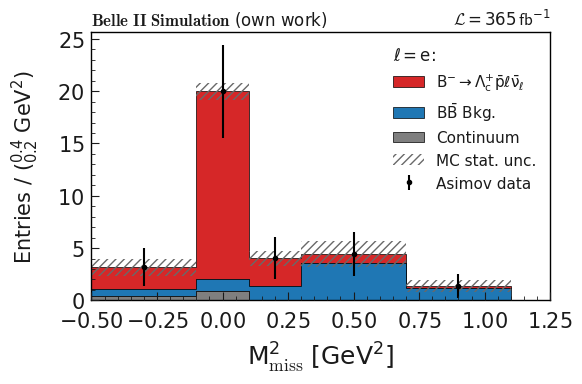

/afs/desy.de/user/t/timmue/b2-plothist-env/lib/python3.11/site-packages/plothist/histogramming.py:148: UserWarning: Custom binning -> ignore supplied range ((-0.5, 1.5)).
  axis = create_axis(bins, range, data)
/tmp/ipykernel_1463035/74998536.py:80: RangeWarning: Only 97.02% of data contained in the binning range [-0.5, 1.1].
  d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
/tmp/ipykernel_1463035/74998536.py:83: RangeWarning: Only 94.31% of data contained in the binning range [-0.5, 1.1].
  h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])


Significance: 2.8495


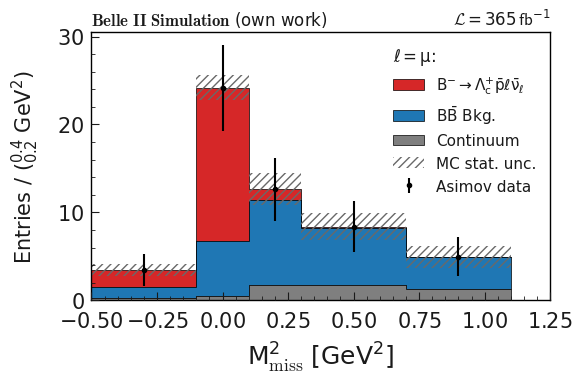

In [440]:
custom_edges = [-0.5, -0.1, 0.1, 0.3, 0.7, 1.1]


bin_low = -0.1
bin_high = 0

for key, df_current in dfs.items():
    for name in ["m2RecoilSignalSide"]:
    
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = custom_edges #variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #has_data = data is not None and len(data) > 0
        
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
        #print(name, x_range, x_min, x_max, bins)


        if isinstance(bins, int):
            raw_width = (x_max - x_min) / bins
            # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
            bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
        else:
            widths = np.diff(bins)
            unique_widths = np.unique(np.round(widths, 6))
            #bin_width_str = "Variable"

        if len(unique_widths) == 2:

            w_low, w_high = sorted(unique_widths)
            w_low_str = f"{int(w_low)}" if w_low.is_integer() else f"{w_low:.3g}"
            w_high_str = f"{int(w_high)}" if w_high.is_integer() else f"{w_high:.3g}"
            bin_width_str = f"$_{{{w_low_str}}}^{{{w_high_str}}}$"
        else:
            bin_width_str = "Variable"


        if bin_width_str == "Variable":
            dynamic_ylabel = "Entries"
        elif unit_str:
            dynamic_ylabel = f"Entries / ({bin_width_str} GeV$^2$)"
        else:
            dynamic_ylabel = f"Entries / {bin_width_str}"
    
        
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_top10 = df.query(range_query).query(f"iDcyBrP_Bp_0 in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        #x2_rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent != 1")[[name, weight_column]]
        #x2_rest = df.query(range_query).query(f"iDcyBrP_Bp_0 not in [{ids_str}] and B_isSignalAcceptMissing != 1 and isContinuumEvent != 1")[[name, "__weight__"]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
        #x3 = continuum
        
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
        #h2_top10 = make_hist(x2_top10[name], bins=bins, range=(x_min, x_max), weights=x2_top10[weight_column])
        #h2_rest = make_hist(x2_rest[name], bins=bins, range=(x_min, x_max), weights=x2_rest[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])
    
        #comparison_mode = "pull" if has_data else None
        '''
        type(d0)
        print(d0)
        print(dir(d0))
        print(d0.storage_type)

        values = d0.values()
        asimov_errors = np.sqrt(values)
        print(values)
        print(np.sqrt(d0.variances()))
        print(asimov_errors)
        '''
        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h3, h2, h1], #h2_rest, h2_top10
            stacked_labels=["Continuum", r"$B\bar{B}$ Bkg." , r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"], #"rest Bkg.", "10 biggest Bkg."
            stacked_colors=["tab:grey", "tab:blue", "tab:red"], #, "tab:green"
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel=dynamic_ylabel,
            #comparison="pull",
            data_uncertainty_type="symmetrical", #if has_data else None
            data_label="Asimov data",
        )# r"$B\bar{B}$


               
        w_sig = x1.query(
            f"{bin_low} <= {name} < {bin_high}"
        )[weight_column].to_numpy()
        '''
        w_top10 = x2_top10.query(
            f"{bin_low} <= {name} < {bin_high}"
        )[weight_column].to_numpy()
        
        w_rest = x2_rest.query(
            f"{bin_low} <= {name} < {bin_high}"
        )[weight_column].to_numpy()
        '''
        w_bkg = x2.query(
            f"{bin_low} <= {name} < {bin_high}"
        )[weight_column].to_numpy()
        
        w_cont = x3.query(
            f"{bin_low} <= {name} < {bin_high}"
        )[weight_column].to_numpy()
        
        w_all = np.concatenate([
            w_sig,
            #w_top10,
            #w_rest,
            w_bkg,
            w_cont
        ])
        content = np.sum(w_all)
        stat_unc = np.sqrt(np.sum(w_all**2))
        #print(content)
        #print(np.sqrt(content))
        #print(stat_unc)

        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)

        '''
        if name == "Btag_extraInfo_decayModeID":
            ax_comparison.set_xticks(range(34), [fei_labels[i] for i in range(34)], rotation=90, fontsize=8)
            ax_comparison.minorticks_off()
        '''
        
        '''
        if name == "B_Lambda_c_InvM":
            ax_main.axvline(
                x=2.27,
                linestyle="--",
                linewidth=1.5,
                color="olive",
            )
            ax_main.axvline(
                x=2.3,
                linestyle="--",
                linewidth=1.5,
                color="olive",
            )
        '''


        #sig_value = calculate_significance(h1, [h2_top10, h2_rest, h3])
        sig_value = calculate_significance(h1, [h2, h3])
        print(f"Significance: {sig_value:.4f}")
        
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
    
        
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, fontsize=11) #handles, labels)
        #ax_main.legend()
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        #add_text(f"    {label_map[key]}", x="left", y="top_in", ax=ax_main)
        leg._legend_box.align = "left"
        ax_main.yaxis.label.set_size(15)
    
    
        fig.savefig(f"graphs/{key}/{name}_fit_{key}.png", bbox_inches="tight", dpi=300)  
        fig.savefig(f"graphs/{key}/{name}_fit_{key}.svg", bbox_inches="tight")
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        plt.tight_layout()
        plt.show()
        plt.close()

In [441]:
print("No cut")
print("total: 4.2234; e: 3.7100; mu: 2.4890")

No cut
total: 4.2234; e: 3.7100; mu: 2.4890


In [442]:
print("2.452 < InvM < 2.458")
print("total: 3.5807; e: 3.1029; mu: 2.1190")

2.452 < InvM < 2.458
total: 3.5807; e: 3.1029; mu: 2.1190


In [443]:
print("2.45 < InvM < 2.46")
print("total: 3.0777; e: 2.6721; mu: 1.8213")

2.45 < InvM < 2.46
total: 3.0777; e: 2.6721; mu: 1.8213


In [444]:
print("2.445 < InvM < 2.465")
print("total: 2.4154; e: 2.1377; mu: 1.4109")

2.445 < InvM < 2.465
total: 2.4154; e: 2.1377; mu: 1.4109


In [445]:
print("2.44 < InvM < 2.47")
print("total: 1.9197; e: 1.6878; mu: 1.1320")

2.44 < InvM < 2.47
total: 1.9197; e: 1.6878; mu: 1.1320


In [446]:
df[(df["m2RecoilSignalSide"] < bin_high) & (df["m2RecoilSignalSide"] > bin_low)].head(10)

,B_mu_mcMother_PDG,iDcyBrP_B0_1,foxWolframR2,B_Lambda_c_p_mcMother_PDG,nROE_Charged__bo__bc,B_deltaE,B_mcDaughter_4_PDG,B_Lambda_c_mcPDG,__experiment__,B_mu_mcPDG,isContinuumEvent,B_mu_charge,B_mu_muonID,B_Lambda_c_p,B_mcDaughter_3_PDG,foxWolframR3,B_mcDaughter_2_PDG,B_Lambda_c_p_mcPDG,iDcyBrCcP_B0_1,B_mu_electronID,R2,B_chiProb,isSignalAcceptMissingNeutrino,nMCDaughters,B_p_isSignal,B_Lambda_c_InvM,foxWolframR1,__event__,mcPDG,__run__,B_mcMother_PDG,B_Lambda_c_isSignal,B_mu_isSignal,B_Lambda_c_pi_mcPDG,Btag_cosTBTO,B_cosThetaBetweenParticleAndNominalB,cosTBTO,Btag_extraInfo_SignalProbability,B_Lambda_c_isSignalAcceptMissingMassive,Btag_deltaE,B_Lambda_c_isSignalAcceptMissingNeutrino,B_isSignalAcceptMissing,iDcyBrCcP_B0_0,B_mcDaughter_0_PDG,B_Lambda_c_nMCDaughters,B_mu_p,B_mcPDG,B_extraInfo_decayModeID,__weight__,B_p_mcPDG,B_Mbc,Btag_thrustOm,B_Lambda_c_K_mcPDG,Btag_extraInfo_decayModeID,__production__,__ncandidates__,B_mu_useCMSFrame_p,mcMother__boPDG__bc,B_mu_cosTheta,B_isSignalAcceptMissingNeutrino,Btag_cosThetaBetweenParticleAndNominalB,InvM,B_p_p,foxWolframR4,iDcyBrP_Bp_0,iDcyBrP_B0_0,Btag_Mbc,m2RecoilSignalSide,B_Lambda_c_K_mcMother_PDG,Btag_R2,B_mcDaughter_1_PDG,B_InvM,B_nMCDaughters,B_Lambda_c_pi_mcMother_PDG,B_p_mcMother_PDG,iDcyBrCcP_Bp_0,Btag_thrustBm,B_Lambda_c_mcMother_PDG,__candidate__,template,dM,harmonicMomentThrust0,harmonicMomentThrust1,harmonicMomentThrust2,harmonicMomentThrust3,harmonicMomentThrust4,cleoConeThrust0,cleoConeThrust1,cleoConeThrust2,cleoConeThrust3,cleoConeThrust4,cleoConeThrust5,cleoConeThrust6,cleoConeThrust7,cleoConeThrust8,sphericity,aplanarity,thrust,thrustAxisCosTheta,M,B_foxWolframR2,S_decayMode,channel,total_weight,CS_Score,Btag_dmID,Btag_PDG,Btag_weight,B_tracks,electron_PDG,electron_mcPDG,electron_p,electron_theta,muon_PDG,muon_mcPDG,muon_p,muon_theta,electron_weight,muon_weight,electron_Kfake_weight,electron_pifake_weight,muon_Kfake_weight,muon_pifake_weight
215,-521.0,-1.0,0.170297,4122.0,0.0,-0.015469,NaN,4122.0,12,-211.0,False,-1.0,9.907306e-01,2.303471,NaN,0.092741,-211.0,2212.0,-1.0,2.393218e-13,0.139697,4.465323e-01,False,NaN,1.0,2.285304,0.004178,122437,NaN,2749,300553.0,1.0,0.0,211.0,0.560813,1.000675,0.960167,0.265716,1.0,-0.056181,1.0,0.0,-1.0,4122.0,3.0,0.802672,-521.0,2.0,0.255383,-2212.0,5.278135,0.727889,-321.0,18.0,45471,1,0.643651,NaN,0.822940,0.0,1.006286,10.504069,1.145827,0.151261,11.0,-1.0,5.282799,-0.038022,4122.0,0.139647,-2212.0,5.262634,3.0,4122.0,-521.0,132.0,0.841110,-521.0,0,background,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B_to_Lambda_c_plnu_mu,0.352899,0.999999,18.0,-521.0,1.248877,1,2.0,-211.0,0.802672,0.604229,13.0,-211.0,0.802672,0.604229,1.0,1.0,1.0,1.0,1.0,1.106469
333,421.0,-1.0,0.255034,-4122.0,1.0,-0.782534,NaN,-4122.0,26,-11.0,False,1.0,1.184925e-05,1.596793,NaN,0.069873,NaN,-2212.0,-1.0,9.996800e-01,0.274893,1.279863e-02,0.0,2.0,1.0,2.288109,0.011076,115642,300553.0,1968,NaN,1.0,1.0,-211.0,0.724464,-0.401538,0.940650,0.005413,1.0,-0.133532,1.0,0.0,-1.0,521.0,3.0,0.606510,300553.0,1.0,0.255383,2212.0,5.255012,0.769995,321.0,3.0,47664,1,0.610050,NaN,0.161408,0.0,0.909298,9.626926,0.982648,0.070979,74.0,-1.0,5.280113,-0.060809,-4122.0,0.274078,-521.0,4.466537,2.0,-4122.0,2224.0,11.0,0.900651,-4114.0,0,background,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B_to_Lambda_c_plnu_e,0.353807,0.999999,3.0,521.0,1.385399,1,-11.0,-11.0,0.606510,1.408679,1.0,-11.0,0.606510,1.408679,1.0,1.0,1.0,1.0,1.0,1.000000
384,-521.0,-1.0,0.123708,4122.0,1.0,-1.143812,NaN,4122.0,26,-211.0,False,-1.0,9.999883e-01,0.945916,111.0,0.135054,-211.0,2212.0,-1.0,8.001846e-10,0.133760,2.424312e-02,False,NaN,1.0,2.285514,0.007224,14419,NaN,200,300553.0,1.0,0.0,211.0,0.542730,-0.194987,0.626255,0.003974,1.0,0.058159,1.0,0.0,-1.0,4122.0,3.0,0.397950,-521.0,2.0,0.255383,-2212.0,5.185114,0.765498,-321.0,14.0,47664,1,0.359885,NaN,0.564366,0.0,1.220769,9.420821,1.413700,0.039359,11.0,-1.0,5.2863

### pyhf Fit combined

In [447]:
from typing import List
def scale_staterror(
    spec: dict,
    data_lumi: float = 365,
    mc_lumi: float = 1429.2256, #1443.999, 
    samples: List[str] = [],
):
    """
    Scale staterror modifiers in a RooStats JSON specification based on luminosity scaling.

    Args:
        spec (dict): The RooStats JSON specification.
        data_lumi (float): Luminosity of the data.
        mc_lumi (float): Luminosity of the Monte Carlo (MC) simulation.

    Returns:
        None: The function modifies the input specification in place.
    """
    # Calculate the scale factor based on luminosity
    scale_factor = data_lumi / mc_lumi

    # Loop over channels in the specification
    for channel in spec["channels"]:
        # Loop over samples in each channel
        for sample in channel["samples"]:
            # Loop over the modifiers of the sample
            for mod in sample["modifiers"]:
                # Check if the modifier type is staterror
                if mod["type"] == "staterror":
                    # Scale the data in the staterror modifier
                    # Only if we want to scale all or a specific sample
                    if samples == [] or sample["name"] in samples:
                        new_data = [x * np.sqrt(scale_factor) for x in mod["data"]]
                        mod["data"] = new_data

In [448]:
def print_staterror_values(spec, name="Workspace"):
    print(f"\n--- Stat-Error: {name} ---")
    found_any = False
    for channel in spec["channels"]:
        for sample in channel["samples"]:
            for mod in sample["modifiers"]:
                if mod["type"] == "staterror":
                    found_any = True
                    # Zeige den Kanal, das Sample und die ersten 5 Fehler-Werte (Bins)
                    print(
                        f"Channel: {channel['name']} | Sample: {sample['name']}"
                    )
                    print(f"  Errors (first 5 bins): {mod['data'][:5]}")
    if not found_any:
        print("  --> NO 'staterror' modification was found!")

In [449]:
cabinetry_config = cabinetry.configuration.load("config.yaml")
cabinetry.configuration.print_overview(cabinetry_config)

INFO : load: 26 :  opening config file config.yaml
INFO : print_overview: 92 :  the config contains:
INFO : print_overview: 93 :    4 Sample(s)
INFO : print_overview: 94 :    2 Regions(s)
INFO : print_overview: 95 :    3 NormFactor(s)
INFO : print_overview: 97 :    29 Systematic(s)


In [450]:
cabinetry.templates.collect(cabinetry_config, method="uproot")

In [451]:
cabinetry.templates.postprocess(cabinetry_config)

In [452]:
workspace_path = "pyhf/workspaces/workspace_version_3_3.json"
spec = cabinetry.workspace.build(cabinetry_config)
cabinetry.workspace.save(spec, workspace_path)

INFO : build: 430 :  building workspace
INFO : __init__: 312 :  Validating spec against schema: workspace.json


In [453]:
model = pyhf.Workspace(spec).model()

INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 768 :  Validating spec against schema: model.json
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var3 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var4 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var5 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var6 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var7 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var8 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var9

In [454]:
poi_hypotheses = np.linspace(0, 0.05, 50)

In [455]:
limit_bracket = [0.01, 1]

In [456]:
print_staterror_values(spec, "Total (VOR Skalierung)")


--- Stat-Error: Total (VOR Skalierung) ---
Channel: Electron | Sample: Signal
  Errors (first 5 bins): [1.3603492198696674, 4.01635431703922, 1.5372085089535834, 0.8669532859386238, 0.43999545452191047]
Channel: Electron | Sample: Background
  Errors (first 5 bins): [0.5327786172430894, 1.011127669967732, 1.0412330286568101, 1.6175489327728494, 1.0135216919069048]
Channel: Electron | Sample: Continuum
  Errors (first 5 bins): [0.5053543855468737, 0.8752994715949364, 0.0, 0.0, 0.0]
Channel: Muon | Sample: Signal
  Errors (first 5 bins): [1.326441103102588, 3.969294395733294, 1.0510166506767018, 0.39928936875398113, 0.10671457257561698]
Channel: Muon | Sample: Background
  Errors (first 5 bins): [1.04123302865681, 2.398975450022798, 2.9563429891860644, 2.479168271778865, 1.7522244890131806]
Channel: Muon | Sample: Continuum
  Errors (first 5 bins): [0.5053543855468737, 0.7146790258451109, 1.2378603838675626, 1.1300067588104468, 1.010708771093748]


In [457]:
scale_staterror(spec)

In [458]:
print_staterror_values(spec, "Total (NACH Skalierung)")


--- Stat-Error: Total (NACH Skalierung) ---
Channel: Electron | Sample: Signal
  Errors (first 5 bins): [0.6874584441364048, 2.029682268025889, 0.7768350614996641, 0.43811864511335635, 0.22235363256333748]
Channel: Electron | Sample: Background
  Errors (first 5 bins): [0.26924201074939447, 0.5109778023659853, 0.5261916774079727, 0.8174354470134246, 0.5121876318520417]
Channel: Electron | Sample: Continuum
  Errors (first 5 bins): [0.2553830549914583, 0.44233642663736233, 0.0, 0.0, 0.0]
Channel: Muon | Sample: Signal
  Errors (first 5 bins): [0.6703228286225258, 2.0059003304104484, 0.5311358737022579, 0.20178263360206722, 0.05392867725284818]
Channel: Muon | Sample: Background
  Errors (first 5 bins): [0.5261916774079726, 1.2123327644883062, 1.4940008947659316, 1.252858558652113, 0.8854943299854406]
Channel: Muon | Sample: Continuum
  Errors (first 5 bins): [0.2553830549914583, 0.3611661799691943, 0.6255581736822093, 0.5710538712624676, 0.5107661099829168]


In [459]:
cabinetry.workspace.save(
    spec, "pyhf/workspaces/workspace_version_3_3_MODIFIED.json"
)

# 2. Absolut sichergehen: Lade das JSON komplett neu ohne Cabinetry-Config
ws = pyhf.Workspace(
    cabinetry.workspace.load(
        "pyhf/workspaces/workspace_version_3_3_MODIFIED.json"
    )
)
model_fit = ws.model()

INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 768 :  Validating spec against schema: model.json
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var3 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var4 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var5 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var6 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var7 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var8 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var9

In [460]:
data = cabinetry.model_utils.asimov_data(
    model_fit,
    poi_name = "Signal",
    poi_value = 0
)

In [461]:
model_fit.config.param_set("Continuum").suggested_fixed = True

In [462]:
limit_results = cabinetry.fit.limit(
    model_fit, 
    data,
    bracket=limit_bracket,
    confidence_level=0.9
    #poi_hypotheses=poi_hypotheses
)

INFO : limit: 855 :  calculating 90% confidence level upper limit for Signal
INFO : limit: 958 :  determining observed upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 9 steps
INFO : limit: 987 :  observed upper limit: 0.1703
INFO : limit: 958 :  determining expected -2 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 7 steps
INFO : limit: 987 :  expected -2 sigma upper limit: 0.0752
INFO : limit: 958 :  determining expected -1 sigma upper limit


W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 3 steps
INFO : limit: 987 :  expected -1 sigma upper limit: 0.1088
INFO : limit: 958 :  determining expected upper limit
INFO : limit: 985 :  successfully converged after 2 steps
INFO : limit: 987 :  expected upper limit: 0.1703
INFO : limit: 958 :  determining expected +1 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 6 steps
INFO : limit: 987 :  expected +1 sigma upper limit: 0.2676
INFO : limit: 958 :  determining expected +2 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 5 steps
INFO : limit: 987 :  expected +2 sigma upper limit: 0.4127
INFO : limit: 1022 :  total of 32 steps to calculate all limits
INFO : limit: 1025 :  summary of 90% confidence level upper limits:
INFO : limit: 1027 :  observed         : 0.1703
INFO : limit: 1027 :  expected -2 sigma: 0.0752
INFO : limit: 1027 :  expected -1 sigma: 0.1088
INFO : limit: 1027 :  expected         : 0.1703
INFO : limit: 1027 :  expected +1 sigma: 0.2676
INFO : limit: 1027 :  expected +2 sigma: 0.4127


In [463]:
unc_up =limit_results.expected_limit[-1]-limit_results.observed_limit
unc_down = limit_results.observed_limit-limit_results.expected_limit[0]
print(f"lower Uncertainty: {unc_down}")
print(f"upper Uncertainty: {unc_up}")

lower Uncertainty: 0.09502283411376532
upper Uncertainty: 0.24242110011777415


In [464]:
syst_0_down = 0.08729654254417626
syst_0_up = 0.22510093210265597
print(f"without FEI syst.: -{syst_0_down}, +{syst_0_up}")

without FEI syst.: -0.08729654254417626, +0.22510093210265597


In [465]:
syst_all_down = 0.10776509941569508
syst_all_up = 0.31628954106842205
print(f"with all syst.: -{syst_all_down}, +{syst_all_up}")

with all syst.: -0.10776509941569508, +0.31628954106842205


In [466]:
syst_unc_down = np.sqrt(syst_all_down**2 - syst_0_down**2)
syst_unc_up = np.sqrt(syst_all_up**2 - syst_0_up**2)
print(f"syst. uncertainty: -{syst_unc_down}, +{syst_unc_up}")

syst. uncertainty: -0.06318726384254558, +0.2221905582057629


In [467]:
print(limit_results)

LimitResults(observed_limit=0.17027059579942613, expected_limit=array([0.07524776, 0.10884036, 0.1702706 , 0.26762252, 0.4126917 ]), observed_CLs=array([9.03375020e-01, 5.06664593e-01, 4.11627043e-01, 3.84692883e-01,
       3.57703874e-01, 2.56680454e-01, 2.38448942e-01, 2.17345261e-01,
       1.09913341e-01, 9.84117833e-02, 6.96320215e-02, 3.51251155e-02,
       1.76939872e-02, 1.61161493e-02, 1.44723295e-02, 7.02137201e-03,
       1.00786022e-03, 9.08715236e-04, 7.56748330e-04, 4.60594120e-04,
       2.60505296e-08, 2.15571567e-09]), expected_CLs=array([[7.44792177e-01, 8.26061732e-01, 9.03375020e-01, 9.62971696e-01,
        9.92428380e-01],
       [1.69687673e-01, 3.02871783e-01, 5.06664593e-01, 7.50642847e-01,
        9.30385182e-01],
       [1.05206348e-01, 2.16197461e-01, 4.11627043e-01, 6.78696694e-01,
        9.01298860e-01],
       [9.04181054e-02, 1.94079880e-01, 3.84692883e-01, 6.56093462e-01,
        8.91187728e-01],
       [7.69914806e-02, 1.72983857e-01, 3.57703874e-01, 6

In [468]:
print(f"\n--- RESULTS ---")
print(f"Observed 90% CL Upper Limit (absolute BF): {limit_results.observed_limit:.5f}")
print(f"Expected 90% CL Upper Limit (Median):      {limit_results.expected_limit[2]:.5f}")


--- RESULTS ---
Observed 90% CL Upper Limit (absolute BF): 0.17027
Expected 90% CL Upper Limit (Median):      0.17027


In [469]:
cabinetry.visualize.limit(limit_results)
plt.show()

INFO : _save_and_close: 27 :  saving figure as figures/limit.pdf


In [470]:
BR_upperlimit = limit_results.observed_limit * BR_B_to_Lambdacplnu
BR_upperlimit_up_stat = syst_0_up * BR_B_to_Lambdacplnu
BR_upperlimit_down_stat = syst_0_down * BR_B_to_Lambdacplnu
BR_upperlimit_up_syst = syst_unc_up * BR_B_to_Lambdacplnu
BR_upperlimit_down_syst = syst_unc_down * BR_B_to_Lambdacplnu
print(f"                                                                              +{BR_upperlimit_up_stat} ({100*BR_upperlimit_up_stat/BR_upperlimit}%) +{BR_upperlimit_up_syst} ({100*BR_upperlimit_up_syst/BR_upperlimit}%)")
print(f"Upper Limit of Branching Ratio for combined channels: {BR_upperlimit}")
print(f"                                                                              -{BR_upperlimit_down_stat} ({100*BR_upperlimit_down_stat/BR_upperlimit}%) -{BR_upperlimit_down_syst} ({100*BR_upperlimit_down_syst/BR_upperlimit}%)")

                                                                              +5.6275233025664e-06 (132.20188197838834%) +5.554763955144072e-06 (130.49261803693747%)
Upper Limit of Branching Ratio for combined channels: 4.256764894985654e-06
                                                                              -2.1824135636044065e-06 (51.26929998354447%) -1.5796815960636395e-06 (37.10990940383997%)


In [471]:
asimov_data = cabinetry.model_utils.asimov_data(
    model_fit,
    poi_name = "Signal",
    poi_value = 1
)

In [472]:
model_fit.config.param_set("Continuum").suggested_fixed = True

In [473]:
fit_results = cabinetry.fit.fit(
    model_fit,
    asimov_data
)

INFO : fit: 478 :  performing maximum likelihood fit


W VariableMetricBuilder No improvement in line search


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 76.85                      │             Nfcn = 2202              │
│ EDM = 6.76e-18 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : print_results: 35 :  fit results (w

In [474]:
cabinetry.model_utils.prediction(model_fit)

ModelPrediction(model=<pyhf.pdf.Model object at 0x7f74958826d0>, model_yields=[[[0.2838530549914583, 1.022379164974375, 1.0841662199658337, 2.616464549914584, 1.0272262199658346], [0.2553830549914583, 0.7661491649743749, 0.0, 0.0, 0.0], [1.8505500000000126, 16.13110199999958, 2.3630099999992993, 0.7516079999997771, 0.1935959999999426]], [[1.0841662199658333, 5.755083209812087, 8.739963869709594, 6.146275319795002, 3.070290659897502], [0.2553830549914583, 0.5107661099829166, 1.5322983299487491, 1.276915274957291, 1.021532219965834], [1.7594460000000105, 15.755297999999733, 1.1046359999996724, 0.15943199999995272, 0.011387999999996623]]], total_stdev_model_bins=[[[0.10932697317266221, 0.12597708942094218, 0.29679418105574074, 0.7240822658563384, 0.47038028502572005], [0.08586277574977791, 0.09315265684195162, 0.0, 0.0, 0.0], [0.6071772869810904, 1.974588886975174, 0.6462618314583695, 0.20792371957903166, 0.08911224034578856], [0.7885127903218035, 2.192384467884057, 0.9425803393429116, 0.

In [475]:
signal = fit_results.bestfit[-1]
background = fit_results.bestfit[-3]
continuum = fit_results.bestfit[-2]

In [476]:
if fit_results.uncertainty[-2]!=0:
    print(fit_results.uncertainty[-11], fit_results.uncertainty[-13], fit_results.uncertainty[-12])

0.21880985686921595 0.2740737564483714 0.0


In [477]:
print(fit_results.uncertainty[-1], fit_results.uncertainty[-3], fit_results.uncertainty[-2])

0.22628498848902173 0.13990538336319575 0.16968056364953144


In [478]:
syst_0_sig = 0.1940312327030136 
syst_0_bkg = 0.24302102046596968 
syst_0_cont = 0 
print(f"Signal: {syst_0_sig}")
print(f"Background: {syst_0_bkg}")

Signal: 0.1940312327030136
Background: 0.24302102046596968


In [479]:
syst_MC_sig = 0.217362511566692  #0.27421205834285073  
syst_MC_bkg = 0.2722158135231528  #0.34331842239875454  
syst_MC_cont = 0
print(f"Signal: {np.sqrt(syst_MC_sig**2 - syst_0_sig**2)}")
print(f"Background: {np.sqrt(syst_MC_bkg**2 - syst_0_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_MC_cont**2 - syst_0_cont**2)}")

Signal: 0.09797112926943993
Background: 0.12264678040515639


In [480]:
syst_FEI_sig = 0.19560766411753094  
syst_FEI_bkg = 0.24504114486557987  
syst_FEI_cont = 0
print(f"Signal: {np.sqrt(syst_FEI_sig**2 - syst_0_sig**2)}")
print(f"Background: {np.sqrt(syst_FEI_bkg**2 - syst_0_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_FEI_cont**2 - syst_0_cont**2)}")

Signal: 0.024783845489870893
Background: 0.03139978166664295


In [481]:
syst_track_sig = 0.19407124591692737 
syst_track_bkg = 0.24306597131293733 
syst_track_cont = 0
print(f"Signal: {np.sqrt(syst_track_sig**2 - syst_0_sig**2)}")
print(f"Background: {np.sqrt(syst_track_bkg**2 - syst_0_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_track_cont**2 - syst_0_cont**2)}")

Signal: 0.003940714084716927
Background: 0.0046744007081572815


In [482]:
syst_PID_sig = 0.19403619592726024  
syst_PID_bkg = 0.2430367661810437   
syst_PID_cont = 0
print(f"Signal: {np.sqrt(syst_PID_sig**2 - syst_0_sig**2)}")
print(f"Background: {np.sqrt(syst_PID_bkg**2 - syst_0_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_PID_cont**2 - syst_0_cont**2)}")

Signal: 0.0013878276806267042
Background: 0.002766464787060801


In [483]:
syst_all_sig = 0.21880985686921595  #0.2753616076579551    
syst_all_bkg = 0.2740737564483714  #0.3447860344885658    
syst_all_cont = 0
print(f"Signal: {syst_all_sig}")
print(f"Background: {syst_all_bkg}")

Signal: 0.21880985686921595
Background: 0.2740737564483714


In [484]:
syst_unc_sig = np.sqrt(syst_all_sig**2 - syst_0_sig**2)
syst_unc_bkg = np.sqrt(syst_all_bkg**2 - syst_0_bkg**2)
syst_unc_cont = np.sqrt(syst_all_cont**2 - syst_0_cont**2)
print(f"signal:     {signal} +/-{syst_0_sig} (stat)  +/-{syst_unc_sig} (syst)")
print(f"background: {background} +/-{syst_0_bkg} (stat)  +/-{syst_unc_bkg} (syst)")
print(f"continuum:  {continuum} +/-{syst_0_cont} (stat)  +/-{syst_unc_cont} (syst)")

signal:     1.0000000000000002 +/-0.1940312327030136 (stat)  +/-0.10114165412368811 (syst)
background: 1.0000000000000002 +/-0.24302102046596968 (stat)  +/-0.12671703747089397 (syst)
continuum:  1.0000000000000002 +/-0 (stat)  +/-0.0 (syst)


INFO : _save_and_close: 27 :  saving figure as figures/Electron_prefit.pdf
INFO : _save_and_close: 27 :  saving figure as figures/Muon_prefit.pdf


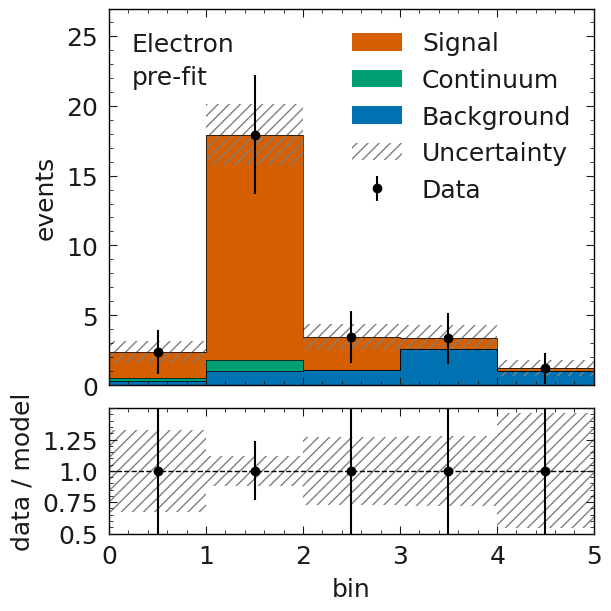

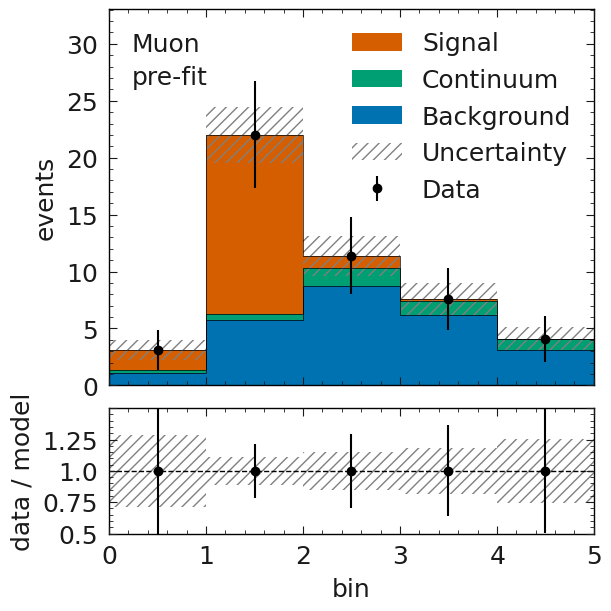

In [485]:
model_pred = cabinetry.model_utils.prediction(model_fit)
figures = cabinetry.visualize.data_mc(model_pred, asimov_data, config=cabinetry_config)

INFO : _save_and_close: 27 :  saving figure as figures/Electron_postfit.pdf
INFO : _save_and_close: 27 :  saving figure as figures/Muon_postfit.pdf


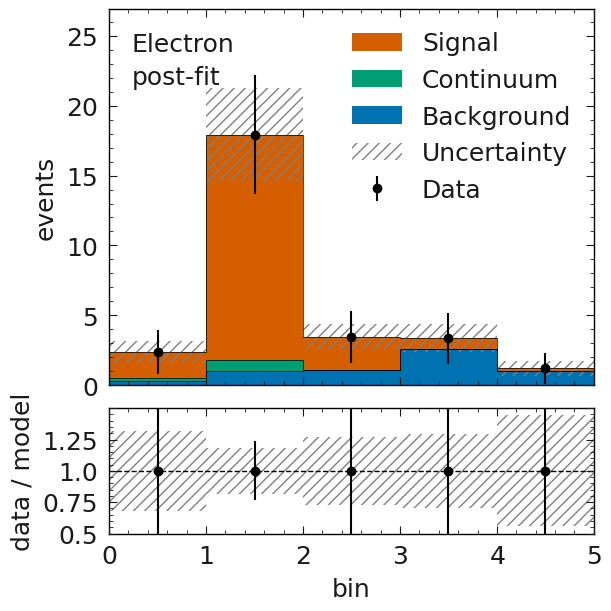

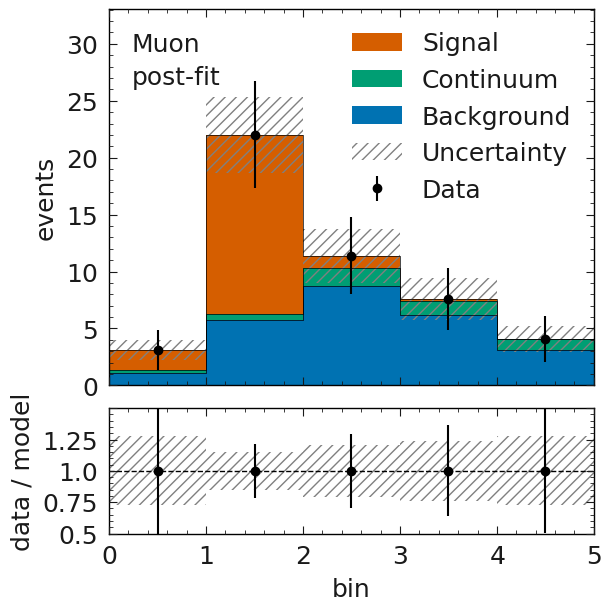

In [486]:
model_pred_postfit = cabinetry.model_utils.prediction(model, fit_results=fit_results)
_ = cabinetry.visualize.data_mc(model_pred_postfit, asimov_data, config=cabinetry_config)

In [487]:
postfit = cabinetry.model_utils.prediction(
    model_fit,
    fit_results=fit_results
)
#print(postfit)

In [488]:
samples = model_fit.config.samples[0]
channel = model_fit.config.channels[0]
print(samples)
print(channel)

Background
Electron


In [489]:
print(postfit.model_yields)
#channels = model.config.channels

#signal_idx = model.config.channel_sample_index["Channel-1"]["Signal"]

#signal_post = postfit.model_yields[1][2]+ postfit.model_yields[0][2]
signal_post = np.array(postfit.model_yields[1][2]) + np.array(postfit.model_yields[0][2])
bkg_post = np.array(postfit.model_yields[1][0])+ np.array(postfit.model_yields[0][0])
cont_post = np.array(postfit.model_yields[1][1])+ np.array(postfit.model_yields[0][1])



print()
#print(postfit.model_yields[0][0])
#print(postfit.model_yields[1])
print(signal_post)

[[[0.2838530549914584, 1.0223791649743754, 1.0841662199658342, 2.6164645499145855, 1.027226219965835], [0.25538305499145836, 0.7661491649743751, 0.0, 0.0, 0.0], [1.8505500000000135, 16.131101999999586, 2.3630099999993, 0.7516079999997775, 0.19359599999994268]], [[1.0841662199658337, 5.755083209812089, 8.739963869709598, 6.146275319795005, 3.0702906598975033], [0.25538305499145836, 0.5107661099829167, 1.5322983299487496, 1.2769152749572912, 1.0215322199658343], [1.7594460000000114, 15.75529799999974, 1.1046359999996729, 0.1594319999999528, 0.011387999999996628]]]

[ 3.609996 31.8864    3.467646  0.91104   0.204984]


In [490]:
bin_edges = [-0.5, -0.1, 0.1, 0.3, 0.7, 1.5]

#print(bin_edges)

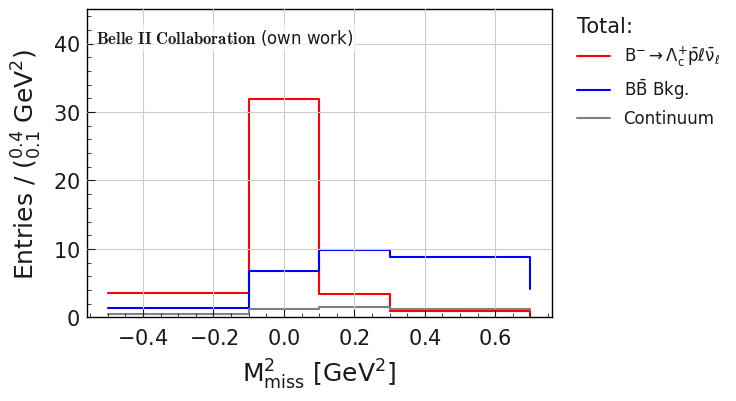

In [491]:

fig = plt.figure(figsize=(6, 4))

# Deine Plot-Befehle
plt.step(bin_edges[:-1], signal_post, where="post", color="red", label=r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $")
plt.step(bin_edges[:-1], bkg_post, where="post", color="blue", label=r"$B\bar{B}$ Bkg.")
plt.step(bin_edges[:-1], cont_post, where="post", color="grey", label="Continuum")

plt.xlabel(r"$M^2_{miss}$ [GeV$^2$]")
plt.ylabel(r"Entries / ($^{0.4}_{0.1}$ GeV$^2$)")
#plt.title(r"Post-fit Histogram total")
plt.grid(True)

# 2. Belle II Collaboration Label hinzufügen
# transAxes sorgt dafür, dass (0,0) unten links und (1,1) oben rechts im Koordinatensystem ist.
ax = plt.gca()
ax.text(
    0.02, 0.94,                                 # Position (X=2% von links, Y=94% von unten)
    r"$\bf{Belle\ II\ Collaboration}$ (own work)",         # Text (Belle II fett gedruckt)
    transform=ax.transAxes, 
    fontsize=12, 
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2) # Weißer Hintergrund, falls Bins dahinter liegen
)

plt.ylim(0, 45)

# 3. Legende rechts außerhalb des Graphen platzieren
leg = plt.legend(title='Total:', bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=12)
leg._legend_box.align = "left"
ax_main.yaxis.label.set_size(15)

orig_width, orig_height = fig.get_size_inches()
fig.set_size_inches(orig_width, orig_height)

# 4. Speichern und Anzeigen (bbox_inches="tight" ist hier zwingend notwendig!)
plt.savefig("graphs/M2miss_total_fit.png", bbox_inches="tight", dpi=300) 
plt.show()

In [492]:
scale_staterror(spec)

In [493]:
model.config.param_set("Continuum").suggested_fixed = True

W VariableMetricBuilder No improvement in line search


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 76.85                      │             Nfcn = 2202              │
│ EDM = 6.76e-18 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : scan: 744 :  performing likelihood 

W MnPosDef non-positive diagonal element in covariance matrix[ 5 ] = -0.0282082
W MnPosDef non-positive diagonal element in covariance matrix[ 17 ] = -6.53729
W MnPosDef Added to diagonal of Error matrix a value 7.03729
W DavidonErrorUpdator delgam < 0 : first derivatives increasing along search line (details in info log)


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 100.5                      │             Nfcn = 6170              │
│ EDM = 0.000569 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘


W DavidonErrorUpdator delgam < 0 : first derivatives increasing along search line (details in info log)
W VariableMetricBuilder Matrix not pos.def., try to make pos.def.
W MnPosDef Matrix forced pos-def by adding to diagonal 0.603418


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 92.81                      │             Nfcn = 6428              │
│ EDM = 0.000693 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘


... (7 outputs left out)

INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 78.41                      │             Nfcn = 6224              │
│ EDM = 0.000409 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘


W MnPosDef non-positive diagonal element in covariance matrix[ 14 ] = -0.378089
W MnPosDef non-positive diagonal element in covariance matrix[ 17 ] = -4.0778
W MnPosDef Added to diagonal of Error matrix a value 4.5778
W MnPosDef non-positive diagonal element in covariance matrix[ 14 ] = -0.446826
W MnPosDef non-positive diagonal element in covariance matrix[ 17 ] = -4.0778
W MnPosDef Added to diagonal of Error matrix a value 4.5778


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 77.6                       │             Nfcn = 3590              │
│ EDM = 0.000668 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : _fit_model_pyhf: 108 :  Migrad stat

combined cahnnels


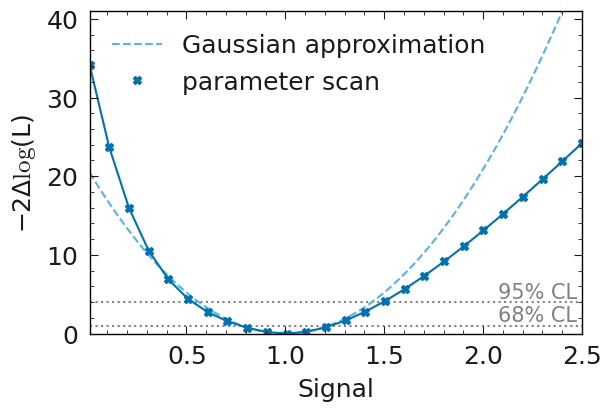

In [494]:
scan_results = cabinetry.fit.scan(
    model_fit, 
    asimov_data, 
    "Signal",             
    n_steps=26,           
    par_range=(0.01, 2.5),   
    tolerance=1.0
)
print("combined cahnnels")
cabinetry.visualize.scan(scan_results)

### pyhf Fit electron channel

In [495]:
cabinetry_config_e = cabinetry.configuration.load("config_electron.yaml")
cabinetry.configuration.print_overview(cabinetry_config_e)

INFO : load: 26 :  opening config file config_electron.yaml
INFO : print_overview: 92 :  the config contains:
INFO : print_overview: 93 :    4 Sample(s)
INFO : print_overview: 94 :    1 Regions(s)
INFO : print_overview: 95 :    3 NormFactor(s)
INFO : print_overview: 97 :    15 Systematic(s)


In [496]:
cabinetry.templates.collect(cabinetry_config_e, method="uproot")

In [497]:
cabinetry.templates.postprocess(cabinetry_config_e)

In [498]:
workspace_path_e = "pyhf/workspaces/workspace_version_3_3_e.json"
spec_e = cabinetry.workspace.build(cabinetry_config_e)
cabinetry.workspace.save(spec_e, workspace_path_e)

INFO : build: 430 :  building workspace
INFO : __init__: 312 :  Validating spec against schema: workspace.json


In [499]:
model_e_fit = pyhf.Workspace(spec_e).model()

data_e = cabinetry.model_utils.asimov_data(
    model_e_fit,
    poi_name = "Signal",
    poi_value = 0
)

INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 768 :  Validating spec against schema: model.json
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var3 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var4 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var5 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var6 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier e_Kfake_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier e_Kfake_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier 

In [500]:
poi_hypotheses_e = np.linspace(0, 0.05, 50)

In [501]:
limit_bracket = [0.01, 1]

In [502]:
print_staterror_values(spec_e, "Elektron (VOR Skalierung)")


--- Stat-Error: Elektron (VOR Skalierung) ---
Channel: Electron | Sample: Signal
  Errors (first 5 bins): [1.3603492198696674, 4.01635431703922, 1.5372085089535834, 0.8669532859386238, 0.43999545452191047]
Channel: Electron | Sample: Background
  Errors (first 5 bins): [0.5327786172430894, 1.011127669967732, 1.0412330286568101, 1.6175489327728494, 1.0135216919069048]
Channel: Electron | Sample: Continuum
  Errors (first 5 bins): [0.5053543855468737, 0.8752994715949364, 0.0, 0.0, 0.0]


In [503]:
scale_staterror(spec_e)

In [504]:
print_staterror_values(spec_e, "Elektron (NACH Skalierung)")


--- Stat-Error: Elektron (NACH Skalierung) ---
Channel: Electron | Sample: Signal
  Errors (first 5 bins): [0.6874584441364048, 2.029682268025889, 0.7768350614996641, 0.43811864511335635, 0.22235363256333748]
Channel: Electron | Sample: Background
  Errors (first 5 bins): [0.26924201074939447, 0.5109778023659853, 0.5261916774079727, 0.8174354470134246, 0.5121876318520417]
Channel: Electron | Sample: Continuum
  Errors (first 5 bins): [0.2553830549914583, 0.44233642663736233, 0.0, 0.0, 0.0]


In [505]:
cabinetry.workspace.save(
    spec_e, "pyhf/workspaces/workspace_version_3_3_e_MODIFIED.json"
)

# 2. Absolut sichergehen: Lade das JSON komplett neu ohne Cabinetry-Config
ws_e = pyhf.Workspace(
    cabinetry.workspace.load(
        "pyhf/workspaces/workspace_version_3_3_e_MODIFIED.json"
    )
)
model_e_fit = ws_e.model()
#data = ws.data(model)

# 3. Den Fit direkt über pyhf (oder cabinetry mit dem puren Model) ausführen
# Wenn cabinetry.fit.fit(spec_e) genutzt wird, stelle sicher, dass KEINE Config mehr übergeben wird.
#result = cabinetry.fit.fit(ws, data)

INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 768 :  Validating spec against schema: model.json
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var3 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var4 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var5 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var6 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier e_Kfake_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier e_Kfake_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier 

In [506]:
model_e_fit.config.param_set("Continuum").suggested_fixed = True

In [507]:
print("Calculate 90% CL Upper Limit for absolute BF...")
limit_results_e = cabinetry.fit.limit(
    model_e_fit, 
    data_e,
    bracket=limit_bracket,
    confidence_level=0.9
    #poi_hypotheses=poi_hypotheses_e
)

INFO : limit: 855 :  calculating 90% confidence level upper limit for Signal
INFO : limit: 958 :  determining observed upper limit


Calculate 90% CL Upper Limit for absolute BF...
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 8 steps
INFO : limit: 987 :  observed upper limit: 0.2047
INFO : limit: 958 :  determining expected -2 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 7 steps
INFO : limit: 987 :  expected -2 sigma upper limit: 0.0924
INFO : limit: 958 :  determining expected -1 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 3 steps
INFO : limit: 987 :  expected -1 sigma upper limit: 0.1303
INFO : limit: 958 :  determining expected upper limit
INFO : limit: 985 :  successfully converged after 2 steps
INFO : limit: 987 :  expected upper limit: 0.2047
INFO : limit: 958 :  determining expected +1 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 6 steps
INFO : limit: 987 :  expected +1 sigma upper limit: 0.3353
INFO : limit: 958 :  determining expected +2 sigma upper limit


W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search
W VariableMetricBuilder No improvement in line search


INFO : limit: 985 :  successfully converged after 6 steps
INFO : limit: 987 :  expected +2 sigma upper limit: 0.5450
INFO : limit: 1022 :  total of 32 steps to calculate all limits
INFO : limit: 1025 :  summary of 90% confidence level upper limits:
INFO : limit: 1027 :  observed         : 0.2047
INFO : limit: 1027 :  expected -2 sigma: 0.0924
INFO : limit: 1027 :  expected -1 sigma: 0.1303
INFO : limit: 1027 :  expected         : 0.2047
INFO : limit: 1027 :  expected +1 sigma: 0.3353
INFO : limit: 1027 :  expected +2 sigma: 0.5450


In [508]:
unc_e_up = limit_results_e.expected_limit[-1]-limit_results_e.observed_limit
unc_e_down = limit_results_e.observed_limit-limit_results_e.expected_limit[0]
print(f"lower Uncertainty: {unc_e_down}")
print(f"upper Uncertainty: {unc_e_up}")

lower Uncertainty: 0.11223589003538259
upper Uncertainty: 0.34028531620215985


In [509]:
syst_0_down_e = 0.10958665305198968
syst_0_up_e = 0.30846689089261625
print(f"without FEI syst.: -{syst_0_down_e}, +{syst_0_up_e}")

without FEI syst.: -0.10958665305198968, +0.30846689089261625


In [510]:
syst_all_down_e = 0.13243649095756518
syst_all_up_e = 0.5073802391330546
print(f"with all syst.: -{syst_all_down_e}, +{syst_all_up_e}")

with all syst.: -0.13243649095756518, +0.5073802391330546


In [511]:
syst_unc_down_e = np.sqrt(syst_all_down_e**2 - syst_0_down_e**2)
syst_unc_up_e = np.sqrt(syst_all_up_e**2 - syst_0_up_e**2)
print(f"syst. uncertainty: -{syst_unc_down_e}, +{syst_unc_up_e}")

syst. uncertainty: -0.07436524463764027, +0.40284349850253076


In [512]:
print(f"\n--- RESULTS ---")
print(f"Observed 90% CL Upper Limit (absolute BF): {limit_results_e.observed_limit:.5f}")
print(f"Expected 90% CL Upper Limit (Median):      {limit_results_e.expected_limit[2]:.5f}")


--- RESULTS ---
Observed 90% CL Upper Limit (absolute BF): 0.20468
Expected 90% CL Upper Limit (Median):      0.20468


In [513]:
cabinetry.visualize.limit(limit_results_e)
plt.show()

INFO : _save_and_close: 27 :  saving figure as figures/limit.pdf


In [514]:
BR_upperlimit_e = limit_results_e.observed_limit * BR_B_to_Lambdacplnu

BR_upperlimit_e_up_stat =syst_0_up_e * BR_B_to_Lambdacplnu
BR_upperlimit_e_down_stat = syst_0_down_e * BR_B_to_Lambdacplnu
BR_upperlimit_e_up_syst = syst_unc_up_e * BR_B_to_Lambdacplnu
BR_upperlimit_e_down_syst = syst_unc_down_e * BR_B_to_Lambdacplnu
print(f"                                                                              +{BR_upperlimit_e_up_stat} (stat) +{BR_upperlimit_e_up_syst} (syst)")
print(f"Upper Limit of Branching Ratio for electron channel: {BR_upperlimit_e}")
print(f"                                                                              -{BR_upperlimit_e_down_stat} (stat) -{BR_upperlimit_e_down_syst} (syst)")

                                                                              +7.711672272315407e-06 (stat) +1.007108746256327e-05 (syst)
Upper Limit of Branching Ratio for electron channel: 5.11696569179716e-06
                                                                              -2.7396663262997423e-06 (stat) -1.8591311159410068e-06 (syst)


In [515]:
print("Best BR: 5.149142979167983e-06")

Best BR: 5.149142979167983e-06


In [516]:
asimov_data_e = cabinetry.model_utils.asimov_data(
    model_e_fit,
    poi_name = "Signal",
    poi_value = 1
)

In [517]:
model_e_fit.config.param_set("Continuum").suggested_fixed = True

In [518]:
fit_results_e = cabinetry.fit.fit(
    model_e_fit,
    asimov_data_e
)

INFO : fit: 478 :  performing maximum likelihood fit


W VariableMetricBuilder No improvement in line search


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 39.43                      │              Nfcn = 766              │
│ EDM = 1.42e-18 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : print_results: 35 :  fit results (w

In [519]:
print(fit_results_e.bestfit[-1], fit_results_e.bestfit[-2], fit_results_e.bestfit[-3])

1.0000000000000002 1.0000000000000002 1.0000000000000002


In [520]:
signal_e = fit_results_e.bestfit[-1]
background_e = fit_results_e.bestfit[-3]
continuum_e = fit_results_e.bestfit[-2]

In [521]:
print("Uncertainty of Signal:")
print(fit_results_e.uncertainty[-1], fit_results_e.uncertainty[-3], fit_results_e.uncertainty[-2])

Uncertainty of Signal:
0.42113575059745123 0.24708588897050876 0.26483545739257086


In [522]:
if fit_results_e.uncertainty[-2]!=0:
    print(fit_results_e.uncertainty[-6], fit_results_e.uncertainty[-8], fit_results_e.uncertainty[-7])

0.2836790434119186 0.6486072972452873 0.0


In [523]:
syst_0_e_sig = 0.25211933682967685 
syst_0_e_bkg = 0.5794742897557833 
syst_0_e_cont = 0 
print(f"Signal: {syst_0_e_sig}")
print(f"Background: {syst_0_e_bkg}")

Signal: 0.25211933682967685
Background: 0.5794742897557833


In [524]:
syst_MC_e_sig = 0.28240109490214277  #0.3561339984202985    
syst_MC_e_bkg = 0.6482243068234056  #0.8143521847263362    
syst_MC_e_cont = 0 
print(f"Signal: {np.sqrt(syst_MC_e_sig**2 - syst_0_e_sig**2)}")
print(f"Background: {np.sqrt(syst_MC_e_bkg**2 - syst_0_e_bkg**2)}")
print(f"Continuum: {np.sqrt(syst_MC_e_cont**2 - syst_0_e_cont**2)}")

Signal: 0.12722506985061155
Background: 0.2905241805232658
Continuum: 0.0


In [525]:
syst_FEI_e_sig = 0.2535485796624544  
syst_FEI_e_bkg = 0.579891564951053 
syst_FEI_e_cont = 0
print(f"Signal: {np.sqrt(syst_FEI_e_sig**2 - syst_0_e_sig**2)}")
print(f"Background: {np.sqrt(syst_FEI_e_bkg**2 - syst_0_e_bkg**2)}")
print(f"Continuum: {np.sqrt(syst_FEI_e_cont**2 - syst_0_e_cont**2)}")

Signal: 0.026883493921213992
Background: 0.021994876981056604
Continuum: 0.0


In [526]:
syst_track_e_sig = 0.25215237022631903 #0.25212020312414557   
syst_track_e_bkg = 0.5794867470570909 #0.5794746269495425   
syst_track_e_cont = 0
print(f"Signal: {np.sqrt(syst_track_e_sig**2 - syst_0_e_sig**2)}")
print(f"Background: {np.sqrt(syst_track_e_bkg**2 - syst_0_e_bkg**2)}")
print(f"Continuum: {np.sqrt(syst_track_e_cont**2 - syst_0_e_cont**2)}")

Signal: 0.004081397715808557
Background: 0.0037996745701873204
Continuum: 0.0


In [527]:
syst_PID_e_sig = 0.25212228378882784   
syst_PID_e_bkg = 0.5794897953093954   
syst_PID_e_cont = 0
print(f"Signal: {np.sqrt(syst_PID_e_sig**2 - syst_0_e_sig**2)}")
print(f"Background: {np.sqrt(syst_PID_e_bkg**2 - syst_0_e_bkg**2)}")
print(f"Continuum: {np.sqrt(syst_PID_e_cont**2 - syst_0_e_cont**2)}")

Signal: 0.00121900757101448
Background: 0.004239148470557217
Continuum: 0.0


In [528]:
syst_e_all_sig = 0.2836790434119186  # 0.35714647042121256   
syst_e_all_bkg = 0.6486072972452873  #0.8146535293189416    
syst_e_all_cont = 0
print(f"with all syst.: {syst_e_all_sig}")

with all syst.: 0.2836790434119186


In [529]:
syst_unc_e_sig = np.sqrt(syst_e_all_sig**2 - syst_0_e_sig**2)
syst_unc_e_bkg = np.sqrt(syst_e_all_bkg**2 - syst_0_e_bkg**2)
syst_unc_e_cont = np.sqrt(syst_e_all_cont**2 - syst_0_e_cont**2)
print(f"signal:     {signal_e} +/-{syst_0_e_sig} (stat)  +/-{syst_unc_e_sig} (syst)")
print(f"background: {background_e} +/-{syst_0_e_bkg} (stat)  +/-{syst_unc_e_bkg} (syst)")
print(f"continuum:  {continuum_e} +/-{syst_0_e_cont} (stat)  +/-{syst_unc_e_cont} (syst)")

signal:     1.0000000000000002 +/-0.25211933682967685 (stat)  +/-0.13003707035943687 (syst)
background: 1.0000000000000002 +/-0.5794742897557833 (stat)  +/-0.291377716292559 (syst)
continuum:  1.0000000000000002 +/-0 (stat)  +/-0.0 (syst)


In [530]:
workspace_path_e_fit = "pyhf/workspaces/workspace_version_3_3_e_fit.json"
spec_e_fit = cabinetry.workspace.build(cabinetry_config_e)
cabinetry.workspace.save(spec_e_fit, workspace_path_e)

model_e_fit = pyhf.Workspace(spec_e_fit).model()

INFO : build: 430 :  building workspace
INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 312 :  Validating spec against schema: workspace.json
INFO : __init__: 768 :  Validating spec against schema: model.json
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var2 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var3 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var4 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var5 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier FEI_var6 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding modifier e_Kfake_var1 (1 new nuisance parameters)
INFO : _create_and_register_paramsets: 478 :  adding m

In [531]:
postfit_e = cabinetry.model_utils.prediction(
    model_e_fit,
    fit_results=fit_results_e
)
#print(postfit)

In [532]:
samples = model_e_fit.config.samples[0]
channel = model_e_fit.config.channels[0]
print(samples)
print(channel)

Background
Electron


In [533]:
#channels = model.config.channels

#signal_idx = model.config.channel_sample_index["Channel-1"]["Signal"]

e_signal_post = postfit_e.model_yields[0][2]
e_bkg_post = postfit_e.model_yields[0][0]
e_cont_post = postfit_e.model_yields[0][1]

#mu_signal_post = postfit.model_yields[1][2]
#mu_bkg_post = postfit.model_yields[1][0]
#mu_cont_post = postfit.model_yields[1][1]


print(postfit_e.model_yields[0])

[[0.2838530549914584, 1.0223791649743754, 1.0841662199658342, 2.6164645499145855, 1.027226219965835], [0.25538305499145836, 0.7661491649743751, 0.0, 0.0, 0.0], [1.8505500000000135, 16.131101999999586, 2.3630099999993, 0.7516079999997775, 0.19359599999994268]]


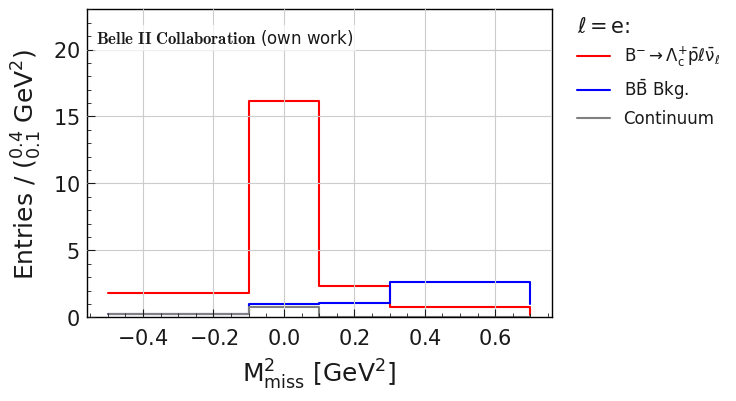

In [534]:

fig = plt.figure(figsize=(6, 4))

# Deine Plot-Befehle
plt.step(bin_edges[:-1], e_signal_post, where="post", color="red", label=r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $")
plt.step(bin_edges[:-1], e_bkg_post, where="post", color="blue", label=r"$B\bar{B}$ Bkg.")
plt.step(bin_edges[:-1], e_cont_post, where="post", color="grey", label="Continuum")

if isinstance(bins, int):
    raw_width = (x_max - x_min) / bins
    # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
    bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
else:
    widths = np.diff(bins)
    unique_widths = np.unique(np.round(widths, 6))
    #bin_width_str = "Variable"

if len(unique_widths) == 2:

    w_low, w_high = sorted(unique_widths)
    w_low_str = f"{int(w_low)}" if w_low.is_integer() else f"{w_low:.3g}"
    w_high_str = f"{int(w_high)}" if w_high.is_integer() else f"{w_high:.3g}"
    bin_width_str = f"$_{{{w_low_str}}}^{{{w_high_str}}}$"
else:
    bin_width_str = "Variable"


if bin_width_str == "Variable":
    dynamic_ylabel = "Entries"
elif unit_str:
    dynamic_ylabel = f"Entries / ({bin_width_str} {unit_str})"
else:
    dynamic_ylabel = f"Entries / {bin_width_str}"

plt.xlabel(r"$M^2_{miss}$ [GeV$^2$]")
plt.ylabel(r"Entries / ($^{0.4}_{0.1}$ GeV$^2$)")
#plt.title(r"Post-fit Histogram total")
plt.grid(True)

# 2. Belle II Collaboration Label hinzufügen
# transAxes sorgt dafür, dass (0,0) unten links und (1,1) oben rechts im Koordinatensystem ist.
ax = plt.gca()
ax.text(
    0.02, 0.94,                                 # Position (X=2% von links, Y=94% von unten)
    r"$\bf{Belle\ II\ Collaboration}$ (own work)",         # Text (Belle II fett gedruckt)
    transform=ax.transAxes, 
    fontsize=12, 
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2) # Weißer Hintergrund, falls Bins dahinter liegen
)

plt.ylim(0, 23)

# 3. Legende rechts außerhalb des Graphen platzieren
leg = plt.legend(title=r'$\ell = e$:', bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=12)
leg._legend_box.align = "left"
ax_main.yaxis.label.set_size(15)

orig_width, orig_height = fig.get_size_inches()
fig.set_size_inches(orig_width, orig_height)

# 4. Speichern und Anzeigen (bbox_inches="tight" ist hier zwingend notwendig!)
plt.savefig("graphs/M2miss_e_fit.png", bbox_inches="tight", dpi=300) 
plt.show()

In [535]:
scale_staterror(spec_e)

In [536]:
model_e_fit.config.param_set("Continuum").suggested_fixed = True

INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 46.26                      │              Nfcn = 766              │
│ EDM = 5.7e-19 (Goal: 0.002)      │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : scan: 744 :  performing likelihood 

W VariableMetricBuilder No improvement in line search


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 53.28                      │             Nfcn = 3197              │
│ EDM = 0.000822 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│     SOME parameters at limit     │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : _fit_model_pyhf: 108 :  Migrad stat

W MnPosDef non-positive diagonal element in covariance matrix[ 9 ] = -22.4535
W MnPosDef non-positive diagonal element in covariance matrix[ 14 ] = -22.4535
W MnPosDef Added to diagonal of Error matrix a value 22.9535


INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 53.17                      │             Nfcn = 1533              │
│ EDM = 0.000341 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘


W DavidonErrorUpdator delgam < 0 : first derivatives increasing along search line (details in info log)
W VariableMetricBuilder Matrix not pos.def., try to make pos.def.
W MnPosDef non-positive diagonal element in covariance matrix[ 13 ] = -0.0103757
W MnPosDef Added to diagonal of Error matrix a value 0.510376
W DavidonErrorUpdator delgam < 0 : first derivatives increasing along search line (details in info log)
W VariableMetricBuilder Matrix not pos.def, gdel = 0.00387828 > 0
W MnPosDef Matrix forced pos-def by adding to diagonal 0.209077
W VariableMetricBuilder gdel = -0.235503
W MnPosDef non-positive diagonal element in covariance matrix[ 8 ] = -19.1528
W MnPosDef non-positive diagonal element in covariance matrix[ 9 ] = -19.1528
W MnPosDef non-positive diagonal element in covariance matrix[ 11 ] = -11.9707
W MnPosDef non-positive diagonal element in covariance matrix[ 14 ] = -19.1528
W MnPosDef Added to diagonal of Error matrix a value 19.6528


... (4 outputs left out)

INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 46.92                      │             Nfcn = 1468              │
│ EDM = 0.0028 (Goal: 0.002)       │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : _fit_model_pyhf: 108 :  Migrad stat

W MnPosDef non-positive diagonal element in covariance matrix[ 4 ] = -1.00948
W MnPosDef non-positive diagonal element in covariance matrix[ 5 ] = -1.02304
W MnPosDef non-positive diagonal element in covariance matrix[ 6 ] = -1.06273
W MnPosDef non-positive diagonal element in covariance matrix[ 7 ] = -1.0196
W MnPosDef non-positive diagonal element in covariance matrix[ 8 ] = -1.06273
W MnPosDef non-positive diagonal element in covariance matrix[ 9 ] = -1.06273
W MnPosDef non-positive diagonal element in covariance matrix[ 10 ] = -0.894343
W MnPosDef non-positive diagonal element in covariance matrix[ 11 ] = -1.06273
W MnPosDef non-positive diagonal element in covariance matrix[ 13 ] = -0.526311
W MnPosDef non-positive diagonal element in covariance matrix[ 14 ] = -1.06273
W MnPosDef Added to diagonal of Error matrix a value 1.56273
W MnPosDef non-positive diagonal element in covariance matrix[ 6 ] = -1.06273
W MnPosDef non-positive diagonal element in covariance matrix[ 8 ] = -1.0627

INFO : _fit_model_pyhf: 108 :  Migrad status:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 46.28                      │              Nfcn = 765              │
│ EDM = 0.000402 (Goal: 0.002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
INFO : _fit_model_pyhf: 108 :  Migrad stat

electron channel


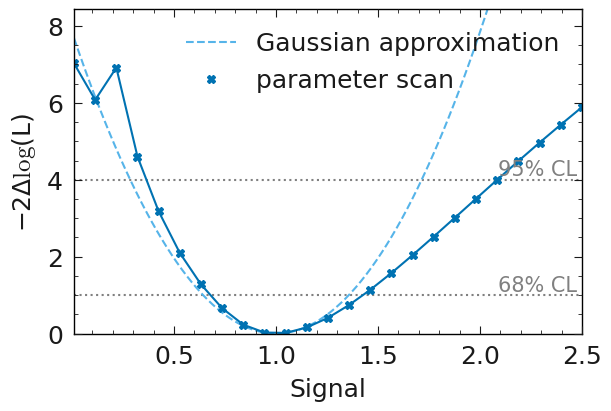

In [537]:
scan_results_e = cabinetry.fit.scan(
    model_e_fit, 
    asimov_data_e, 
    "Signal",             
    n_steps=25,           
    par_range=(0.01, 2.5),   
    tolerance=1.0
)
print("electron channel")
cabinetry.visualize.scan(scan_results_e)

In [538]:
scan_results_e

ScanResults(name='Signal', bestfit=1.0000000000000002, uncertainty=0.35714647042121256, parameter_values=array([0.01   , 0.11375, 0.2175 , 0.32125, 0.425  , 0.52875, 0.6325 ,
       0.73625, 0.84   , 0.94375, 1.0475 , 1.15125, 1.255  , 1.35875,
       1.4625 , 1.56625, 1.67   , 1.77375, 1.8775 , 1.98125, 2.085  ,
       2.18875, 2.2925 , 2.39625, 2.5    ]), delta_nlls=array([7.02756305, 6.07797759, 6.91661556, 4.60151643, 3.17831104,
       2.09651151, 1.27896747, 0.66035215, 0.23008804, 0.02631919,
       0.01710415, 0.15827121, 0.40882554, 0.74369877, 1.13850778,
       1.57543515, 2.04058258, 2.52317453, 3.01490017, 3.50939359,
       4.00181372, 4.48849683, 4.96668102, 5.43263847, 5.88787055]))

### pyhf Fit muon channel

In [539]:
cabinetry_config_mu = cabinetry.configuration.load("config_muon.yaml")
cabinetry.configuration.print_overview(cabinetry_config_mu)

INFO : load: 26 :  opening config file config_muon.yaml
INFO : print_overview: 92 :  the config contains:
INFO : print_overview: 93 :    4 Sample(s)
INFO : print_overview: 94 :    1 Regions(s)
INFO : print_overview: 95 :    3 NormFactor(s)
INFO : print_overview: 97 :    20 Systematic(s)


In [540]:
cabinetry.templates.collect(cabinetry_config_mu, method="uproot")

KeyInFileError: not found: 'track_eff_var2_up' (with any cycle number)

    Available keys: 'track_eff_var1_up;1', 'mu_eff_var2_up;1', 'track_eff_var1_down;1', 'mu_eff_var1_up;1', 'mu_eff_var3_up;1', 'FEI_var2_up;1', 'FEI_var1_up;1', 'FEI_var3_up;1', 'FEI_var4_up;1', 'FEI_var5_up;1', 'FEI_var6_up;1'...

in file pyhf/test_output_mu.root

In [ ]:
cabinetry.templates.postprocess(cabinetry_config_mu)

In [ ]:
workspace_path_mu = "pyhf/workspaces/workspace_version_3_3_mu.json"
spec_mu = cabinetry.workspace.build(cabinetry_config_mu)
cabinetry.workspace.save(spec_mu, workspace_path_mu)

In [ ]:
model_mu = pyhf.Workspace(spec_mu).model()

In [ ]:
limit_bracket = [0.01, 5]

In [ ]:
scale_staterror(spec_mu)

In [ ]:
cabinetry.workspace.save(
    spec_mu, "pyhf/workspaces/workspace_version_3_3_mu_MODIFIED.json"
)

# 2. Absolut sichergehen: Lade das JSON komplett neu ohne Cabinetry-Config
ws_mu = pyhf.Workspace(
    cabinetry.workspace.load(
        "pyhf/workspaces/workspace_version_3_3_mu_MODIFIED.json"
    )
)
model_mu_fit = ws_mu.model()

In [ ]:
asimov_data_mu = cabinetry.model_utils.asimov_data(
    model_mu_fit,
    poi_name = "Signal",
    poi_value = 0
)

In [ ]:
model_mu_fit.config.param_set("Continuum").suggested_fixed = True

In [ ]:
print("Calculate 90% CL Upper Limit for absolute BF...")
limit_results_mu = cabinetry.fit.limit(
    model_mu_fit, 
    asimov_data_mu,
    bracket=limit_bracket,
    confidence_level=0.9
    #poi_hypotheses=poi_hypotheses_e
)

In [ ]:
unc_mu_up = limit_results_mu.expected_limit[-1]-limit_results_mu.observed_limit
unc_mu_down = limit_results_mu.observed_limit-limit_results_mu.expected_limit[0]
print(f"lower Uncertainty: {unc_mu_down}")
print(f"upper Uncertainty: {unc_mu_up}")

In [ ]:
syst_0_down_mu = 0.18231954579642942
syst_0_up_mu = 0.45665022251553905
print(f"without FEI syst.: -{syst_0_down_mu}, +{syst_0_up_mu}")

In [ ]:
syst_all_down_mu = 0.2495123824895529
syst_all_up_mu = 0.9068753064778187
print(f"with all syst.: -{syst_all_down_mu}, +{syst_all_up_mu}")

In [ ]:
syst_unc_down_mu = np.sqrt(syst_all_down_mu**2 - syst_0_down_mu**2)
syst_unc_up_mu = np.sqrt(syst_all_up_mu**2 - syst_0_up_mu**2)
print(f"syst. uncertainty: -{syst_unc_down_mu}, +{syst_unc_up_mu}")

In [ ]:
print(f"\n--- RESULTS ---")
print(f"Observed 90% CL Upper Limit (absolute BF): {limit_results_mu.observed_limit:.5f}")
print(f"Expected 90% CL Upper Limit (Median):      {limit_results_mu.expected_limit[2]:.5f}")

In [ ]:
cabinetry.visualize.limit(limit_results_mu)
plt.show()

In [ ]:
BR_upperlimit_mu = limit_results_mu.observed_limit * BR_B_to_Lambdacplnu

BR_upperlimit_mu_up_stat = syst_0_up_mu * BR_B_to_Lambdacplnu
BR_upperlimit_mu_down_stat =syst_0_down_mu * BR_B_to_Lambdacplnu
BR_upperlimit_mu_up_syst = syst_unc_up_mu * BR_B_to_Lambdacplnu
BR_upperlimit_mu_down_syst = syst_unc_down_mu * BR_B_to_Lambdacplnu
print(f"                                                                         +{BR_upperlimit_mu_up_stat} (stat) +{BR_upperlimit_mu_up_syst} (syst)")
print(f"Upper Limit of Branching Ratio for muon channel: {BR_upperlimit_mu}")
print(f"                                                                         -{BR_upperlimit_mu_down_stat} (stat) -{BR_upperlimit_mu_down_syst} (syst)")

In [ ]:
print("Best BR: 7.311501024485749e-06")

In [ ]:
#model_mu = pyhf.Workspace(spec_mu).model()

asimov_data_mu = cabinetry.model_utils.asimov_data(
    model_mu_fit,
    poi_name = "Signal",
    poi_value = 1
)

In [ ]:
model_mu_fit.config.param_set("Continuum").suggested_fixed = True

In [ ]:
fit_results_mu = cabinetry.fit.fit(
    model_mu_fit,
    asimov_data_mu
)

In [ ]:
signal_mu = fit_results_mu.bestfit[-1]
background_mu = fit_results_mu.bestfit[-3]
continuum_mu = fit_results_mu.bestfit[-2]

In [ ]:
print("Uncertainty of Signal:")
print(fit_results_mu.uncertainty[-1], fit_results_mu.uncertainty[-3], fit_results_mu.uncertainty[-2])

In [ ]:
if fit_results_mu.uncertainty[-2]!=0:
    print(fit_results_mu.uncertainty[-6], fit_results_mu.uncertainty[-8], fit_results_mu.uncertainty[-7])

In [ ]:
syst_0_mu_sig = 0.31070399120279474  
syst_0_mu_bkg = 0.2744909407108037 
syst_0_mu_cont = 0 
print(f"Signal: {syst_0_mu_sig}")
print(f"Background: {syst_0_mu_bkg}")

In [ ]:
syst_MC_mu_sig = 0.34796559053715387      
syst_MC_mu_bkg = 0.30744101570446236       
syst_MC_mu_cont = 0
print(f"Signal: {np.sqrt(syst_MC_mu_sig**2 - syst_0_mu_sig**2)}")
print(f"Background: {np.sqrt(syst_MC_mu_bkg**2 - syst_0_mu_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_MC_mu_cont**2 - syst_0_mu_cont**2)}")

In [ ]:
syst_FEI_mu_sig = 0.3115421697114375  
syst_FEI_mu_bkg = 0.2766080238490986  
syst_FEI_mu_cont = 0
print(f"Signal: {np.sqrt(syst_FEI_mu_sig**2 - syst_0_mu_sig**2)}")
print(f"Background: {np.sqrt(syst_FEI_mu_bkg**2 - syst_0_mu_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_FEI_mu_cont**2 - syst_0_mu_cont**2)}")

In [ ]:
syst_track_mu_sig = 0.3107249606529094   
syst_track_mu_bkg = 0.27453173149515536   
syst_track_mu_cont = 0
print(f"Signal: {np.sqrt(syst_track_mu_sig**2 - syst_0_mu_sig**2)}")
print(f"Background: {np.sqrt(syst_track_mu_bkg**2 - syst_0_mu_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_track_mu_cont**2 - syst_0_mu_cont**2)}")

In [ ]:
syst_PID_mu_sig = 0.3107054865141045   
syst_PID_mu_bkg = 0.2745001126624504   
syst_PID_mu_cont = 0
print(f"Signal: {np.sqrt(syst_PID_mu_sig**2 - syst_0_mu_sig**2)}")
print(f"Background: {np.sqrt(syst_PID_mu_bkg**2 - syst_0_mu_bkg**2)}")
#print(f"Continuum: {np.sqrt(syst_PID_mu_cont**2 - syst_0_mu_cont**2)}")

In [ ]:
syst_all_mu_sig = 0.34873392342133586    
syst_all_mu_bkg = 0.30937706532399933    
syst_all_mu_cont = 0
print(f"with all syst.: {syst_all_mu_sig}")

In [ ]:
syst_unc_mu_sig = np.sqrt(syst_all_mu_sig**2 - syst_0_mu_sig**2)
syst_unc_mu_bkg = np.sqrt(syst_all_mu_bkg**2 - syst_0_mu_bkg**2)
syst_unc_mu_cont = np.sqrt(syst_all_mu_cont**2 - syst_0_mu_cont**2)
print(f"signal:     {signal_mu} +/-{syst_0_mu_sig} (stat)  +/-{syst_unc_mu_sig} (syst)")
print(f"background: {background_mu} +/-{syst_0_mu_bkg} (stat)  +/-{syst_unc_mu_bkg} (syst)")
print(f"continuum:  {continuum_mu} +/-{syst_0_mu_cont} (stat)  +/-{syst_unc_mu_cont} (syst)")

In [ ]:
postfit_mu = cabinetry.model_utils.prediction(
    model_mu_fit,
    fit_results=fit_results_mu
)
#print(postfit)

In [ ]:
samples = model_mu_fit.config.samples[1]
channel = model_mu_fit.config.channels[0]
print(samples)
print(channel)

In [ ]:
#channels = model.config.channels

#signal_idx = model.config.channel_sample_index["Channel-1"]["Signal"]

#e_signal_post = postfit.model_yields[0][2]
#e_bkg_post = postfit.model_yields[0][0]
#e_cont_post = postfit.model_yields[0][1]

mu_signal_post = np.array(postfit_mu.model_yields[0][2])
mu_bkg_post =  np.array(postfit_mu.model_yields[0][0])
mu_cont_post =  np.array(postfit_mu.model_yields[0][1])


print(mu_signal_post)



In [ ]:

fig = plt.figure(figsize=(6, 4))

# Deine Plot-Befehle
plt.step(bin_edges[:-1], mu_signal_post, where="post", color="red", label=r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $")
plt.step(bin_edges[:-1], mu_bkg_post, where="post", color="blue", label=r"$B\bar{B}$ Bkg.")
plt.step(bin_edges[:-1], mu_cont_post, where="post", color="grey", label="Continuum")


plt.xlabel(r"$M^2_{miss}$ [GeV$^2$]")
plt.ylabel(r"Entries / ($^{0.4}_{0.1}$ GeV$^2$)")
#plt.title(r"Post-fit Histogram total")
plt.grid(True)

# 2. Belle II Collaboration Label hinzufügen
# transAxes sorgt dafür, dass (0,0) unten links und (1,1) oben rechts im Koordinatensystem ist.
ax = plt.gca()
ax.text(
    0.02, 0.94,                                 # Position (X=2% von links, Y=94% von unten)
    r"$\bf{Belle\ II\ Collaboration}$ (own work)",         # Text (Belle II fett gedruckt)
    transform=ax.transAxes, 
    fontsize=12, 
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2) # Weißer Hintergrund, falls Bins dahinter liegen
)

plt.ylim(0, 20)

# 3. Legende rechts außerhalb des Graphen platzieren
leg = plt.legend(title=r'$\ell = \mu$:', bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, fontsize=12)
leg._legend_box.align = "left"
ax_main.yaxis.label.set_size(15)

orig_width, orig_height = fig.get_size_inches()
fig.set_size_inches(orig_width, orig_height)

# 4. Speichern und Anzeigen (bbox_inches="tight" ist hier zwingend notwendig!)
plt.savefig("graphs/M2miss_mu_fit.png", bbox_inches="tight", dpi=300) 
plt.show()

In [ ]:
scale_staterror(spec_mu)

In [ ]:
model_mu_fit.config.param_set("Continuum").suggested_fixed = True

In [ ]:
scan_results_mu = cabinetry.fit.scan(
    model_mu_fit, 
    asimov_data_mu, 
    "Signal",             
    n_steps=25,           
    par_range=(0.1, 2.5),   
    tolerance=1.0
)
print("muon channel")
cabinetry.visualize.scan(scan_results_mu)

## Further study

In [ ]:
for key, df_current in dfs.items():
    for name in further_variables:
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"

        

        if isinstance(bins, int):
            raw_width = (x_max - x_min) / bins
            # Säubern von Floating-Point-Fehlern (z.B. 0.0199999 -> 0.02)
            bin_width_str = f"{int(raw_width)}" if raw_width.is_integer() else f"{raw_width:.3g}"
        else:
            # Falls 'bins' eine Liste/ein Array für variable Bin-Breiten ist
            bin_width_str = "Variable"

        # 2. Einheit aus dem x_label extrahieren (sucht nach Text in [...] Klammern)
        # Findet z.B. "GeV/c²" aus "M(pKπ) [GeV/c²]"
        unit_match = re.search(re.compile(r"\[(.*?)\]"), x_label)
        unit_str = unit_match.group(1) if unit_match else ""

        # 3. Label textuell zusammenbauen
        if bin_width_str == "Variable":
            dynamic_ylabel = "Entries / Variable Bin"
        elif unit_str:
            # Wenn eine Einheit existiert, z.B.: Entries / (0.02 GeV/c²)
            dynamic_ylabel = f"Entries / ({bin_width_str} {unit_str})"
        else:
            # Wenn die Variable ein reiner Counter ohne Einheit ist
            dynamic_ylabel = f"Entries / {bin_width_str}"
            
        
        d = datas[key].query(range_query)[[name, weight_column]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, weight_column]]
        x2 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal == 1 and isContinuumEvent != 1")[[name, weight_column]]
        x3 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_mu_isSignal != 1 and isContinuumEvent != 1")[[name, weight_column]]
        x4 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and isContinuumEvent == 1")[[name, weight_column]]
    
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d[weight_column])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1[weight_column])
        h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2[weight_column])
        h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3[weight_column])
        h4 = make_hist(x4[name], bins=bins, range=(x_min, x_max), weights=x4[weight_column])

        d0_asimov = d0.copy()
        view = d0_asimov.view()
        view.variance = view.value
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0_asimov,
            stacked_components=[h4, h3, h2, h1],
            stacked_labels=["Continuum", r"Fake $\ell$", r"True $\ell$", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
            stacked_colors=["tab:grey", "tab:purple", "tab:blue", "tab:red"],
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel=dynamic_ylabel,
            #comparison="pull",
            data_uncertainty_type="symmetrical",
        )
    
        if name == "Btag_extraInfo_decayModeID":
            ax_comparison.set_xticks(range(34), [fei_labels[i] for i in range(34)], rotation=90, fontsize=8)
            ax_comparison.minorticks_off()



        
        xticks = ax_comparison.get_xticks()
        xticklabels = [t.get_text() for t in ax_comparison.get_xticklabels()]
        
        ax_main.set_xticks(xticks)
        ax_main.set_xticklabels(xticklabels)
                
        ax_comparison.remove()
        fig.subplots_adjust(hspace=0)

        ax_main.tick_params(axis="x", which="both", labelbottom=True)
        #ax_main.xaxis.set_visible(True)
        ax_main.set_xlabel(x_label)


        ax_main.set_ylim(bottom=0)
        
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
        
        #ax_main.legend() #handles, labels)
        leg = ax_main.legend(title=label_map[key]+":", title_fontproperties={'size': 12}, fontsize=11) #handles, labels)
        #ax_main.legend()
        add_text(r"$\bf{Belle\ II\ Simulation}$ (own work)", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$", x="right", y="top_out", ax=ax_main) # + f" ({label_map[key]})"
        #ax_main.text(0.04, 0.94, label_map[key], transform=ax_main.transAxes, fontsize=12, verticalalignment="top",bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
        #add_text(f"    {label_map[key]}", x="left", y="top_in", ax=ax_main)
        leg._legend_box.align = "left"
        ax_main.yaxis.label.set_size(15)
        #add_text(r"Belle II Simulation", weight="bold", ax=ax_main)
        #add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$" + f" ({label_map[key]})", x="right", y="top_out", ax=ax_main)
        
        #fig.savefig("1d_elt1_stacked.svg", bbox_inches="tight")
        fig.savefig(f"graphs/{key}/{name}_{key}_fake.png", bbox_inches="tight", dpi=300)  
        plt.tight_layout()
        plt.show()
        plt.close()

In [ ]:
for key, df_current in dfs.items():
    for name in further_variables:
        variable = get_variable_from_registry(name)
        name = variable["name"]
        bins = variable["bins"]
        x_range = variable["range"]
        x_label = variable["label"]

        label_map = {"total": r"Total", "e": r"$\ell = e$", "mu": r"$\ell = \mu$",}
    
        #print(name, x_range)
        if x_range[0] == "min":
            x_min = data[name].min()
        else:
            x_min = x_range[0]
    
        if x_range[1] == "max":
            x_max = data[name].max()
        else:
            x_max = x_range[1]
    
        range_query = f"{x_min} <= {name} < {x_max}"
        #range_query = f"{x_range[0]} <= {name} < {x_range[1]}"
    
    
        
        d = datas[key].query(range_query)[[name, "__weight__"]]
        x1 = df_current.query(range_query).query("B_isSignalAcceptMissingNeutrino == 1")[[name, "__weight__"]]
        #x2 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 1")[[name, "__weight__"]]
        x2_top10 = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 1")[[name, "__weight__"]]
        x2_rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 1")[[name, "__weight__"]]
        #x3 = df.query(range_query).query("B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 0")[[name, "__weight__"]]
        x3_top10 = df_current.query(range_query).query(f"({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 0")[[name, "__weight__"]]
        x3_rest = df_current.query(range_query).query(f"~({conditions[key]}) and B_isSignalAcceptMissingNeutrino != 1 and B_Lambda_c_isSignalAcceptMissingMassive == 0")[[name, "__weight__"]]
        
        #d0 = make_hist(d[name],  bins=bins, range=x_range, weights=d.__weight__)
        #h1 = make_hist(x1[name], bins=bins, range=x_range, weights=x1.__weight__)
        #h2 = make_hist(x2[name], bins=bins, range=x_range, weights=x2.__weight__)
        #h3 = make_hist(x3[name], bins=bins, range=x_range, weights=x3.__weight__)
    
        d0 = make_hist(d[name],  bins=bins, range=(x_min, x_max), weights=d["__weight__"])
        #d0 = make_hist(np.array([]), bins=bins, range=(x_min, x_max))
        h1 = make_hist(x1[name], bins=bins, range=(x_min, x_max), weights=x1["__weight__"])
        #h2 = make_hist(x2[name], bins=bins, range=(x_min, x_max), weights=x2["__weight__"])
        h2_top10 = make_hist(x2_top10[name], bins=bins, range=(x_min, x_max), weights=x2_top10["__weight__"])
        h2_rest = make_hist(x2_rest[name], bins=bins, range=(x_min, x_max), weights=x2_rest["__weight__"])
        #h3 = make_hist(x3[name], bins=bins, range=(x_min, x_max), weights=x3["__weight__"])
        h3_top10 = make_hist(x3_top10[name], bins=bins, range=(x_min, x_max), weights=x3_top10["__weight__"])
        h3_rest = make_hist(x3_rest[name], bins=bins, range=(x_min, x_max), weights=x3_rest["__weight__"])
        
        fig, ax_main, ax_comparison = plot_data_model_comparison(
            data_hist=d0,
            stacked_components=[h3_rest, h3_top10, h2_rest, h2_top10, h1],
            stacked_labels=[r"Rest fake $\Lambda_{c}^{+}$ Bkg.", r"10 biggest fake $\Lambda_{c}^{+}$ Bkg.", r"Rest true $\Lambda_{c}^{+}$ Bkg.", r"10 biggest true $\Lambda_{c}^{+}$ Bkg.", r"$B^{-} \to \Lambda_{c}^{+} \bar{p} \ell \bar{\nu}_\ell $"],
            stacked_colors=["tab:grey", "tab:olive", "tab:blue", "tab:green","tab:red"],
            xlabel=x_label,
            model_uncertainty_label="MC stat. unc.",
            ylabel="Events",
            comparison="pull",
            data_uncertainty_type="symmetrical",
        )
    
        if name == "Btag_extraInfo_decayModeID":
            ax_comparison.set_xticks(range(34), [fei_labels[i] for i in range(34)], rotation=90, fontsize=8)
            ax_comparison.minorticks_off()
            
        if variable["log"]:
            ax_main.set_yscale("log")
        ax_main.legend()
        add_text(r"Belle II Simulation", weight="bold", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$" + f" ({label_map[key]})", x="right", y="top_out", ax=ax_main)
        
        
        # remove Data label
        handles, labels = ax_main.get_legend_handles_labels()
        handles, labels = zip(*[(h, l) for h, l in zip(handles, labels) if l != "Data"])
    
        #fig.set_constrained_layout_pads(w_pad=4.0)
        
        ax_main.legend()
        #ax_main.legend()
        add_text(r"Belle II Simulation", weight="bold", ax=ax_main)
        add_text(r"$\mathcal{L} = 365\,\mathsf{fb}^{-1}$" + f" ({label_map[key]})", x="right", y="top_out", ax=ax_main)
        
        #fig.savefig("Lambdac_InvM_had.svg", bbox_inches="tight") #1d_elt1_stacked.svg
        plt.tight_layout()
        plt.show()
        plt.close()

In [ ]:
"/pnfs".startswith("/pnfs")

In [ ]:
assert False

In [ ]:
def do_bcs(df, option=None):
    if option is None:
        option = "random"

    if option == "random":
        df = df.groupby(['__experiment__', '__run__', '__event__', '__production__']).sample(1).reset_index()

    if option == "chiProb":
        df = df.sort_values('chiProb', ascending=False).groupby(['__experiment__', '__run__', '__event__', '__production__']).first().reset_index()

    if option == "B_Lambda_c_dM":
        df = df.sort_values('B_Lambda_c_dM', key=abs, ascending=True).groupby(['__experiment__', '__run__', '__event__', '__production__']).first().reset_index()

    return df

In [ ]:
df[['__experiment__', '__run__', '__event__', '__production__']]

In [ ]:
test = df.copy()

In [ ]:
test.__nEvents__.value_counts()

In [ ]:
test.groupby("B_isSignalAcceptMissingNeutrino")["__weight__"].sum()

In [ ]:
do_bcs(test, option="random").groupby("B_isSignalAcceptMissingNeutrino")["__weight__"].sum()

In [ ]:
do_bcs(test, option="chiProb").groupby("B_isSignalAcceptMissingNeutrino")["__weight__"].sum()

In [ ]:
do_bcs(test, option="B_Lambda_c_dM").groupby("B_isSignalAcceptMissingNeutrino")["__weight__"].sum()

In [ ]:
DO_BCS = True
bcs_option = "chiProb"
if DO_BCS:
    print(df.B_isSignalAcceptMissingNeutrino.value_counts())
    df = do_bcs(df, bcs_option)
    print(df.B_isSignalAcceptMissingNeutrino.value_counts())
    
    data = do_bcs(data, bcs_option)